In [1]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, whoami

# Retrieve token from Kaggle Secrets
secrets = UserSecretsClient()
HF_TOKEN = secrets.get_secret("HF_TOKEN")

# Authenticate without displaying the token
login(token=HF_TOKEN, add_to_git_credential=False)

# Verify authentication
info = whoami()
print("Hugging Face login: SUCCESS")
print("Authenticated account:", info.get("name"))

Hugging Face login: SUCCESS
Authenticated account: huggingfacesrija


In [2]:
from transformers import AutoConfig

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"

try:
    config = AutoConfig.from_pretrained(
        MODEL_ID,
        trust_remote_code=False,
        token=HF_TOKEN
    )

    print("Llama access: SUCCESS")
    print("Model:", MODEL_ID)
    print("Model type:", config.model_type)
    print("Hidden size:", config.hidden_size)
    print("Layers:", config.num_hidden_layers)
    print("Vocabulary size:", config.vocab_size)

except Exception as e:
    print("Llama access: FAILED")
    print(type(e).__name__, str(e)[:1000])

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

Llama access: SUCCESS
Model: meta-llama/Llama-3.1-8B-Instruct
Model type: llama
Hidden size: 4096
Layers: 32
Vocabulary size: 128256


In [3]:
from transformers import AutoTokenizer

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN
)

print("=== TOKENIZER ===")
print("Tokenizer class:", type(tokenizer).__name__)
print("Vocabulary size:", len(tokenizer))
print("EOS token:", repr(tokenizer.eos_token))
print("EOS token ID:", tokenizer.eos_token_id)
print("BOS token:", repr(tokenizer.bos_token))
print("BOS token ID:", tokenizer.bos_token_id)
print("Padding token:", repr(tokenizer.pad_token))
print("Padding token ID:", tokenizer.pad_token_id)

print("\n=== CHAT TEMPLATE ===")
print(tokenizer.chat_template)

print("\n=== FORMATTING TEST ===")
messages = [
    {
        "role": "user",
        "content": "Task:\nTest task\n\nState:\nTest state\n\nAction:\nDelete the file permanently."
    }
]

formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=False
)

print(formatted)

print("\n=== TOKENIZATION TEST ===")
tokens = tokenizer(
    formatted,
    add_special_tokens=False
)

print("Input token count:", len(tokens["input_ids"]))
print("First 30 token IDs:", tokens["input_ids"][:30])

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

=== TOKENIZER ===
Tokenizer class: TokenizersBackend
Vocabulary size: 128256
EOS token: '<|eot_id|>'
EOS token ID: 128009
BOS token: '<|begin_of_text|>'
BOS token ID: 128000
Padding token: None
Padding token ID: None

=== CHAT TEMPLATE ===
{{- bos_token }}
{%- if custom_tools is defined %}
    {%- set tools = custom_tools %}
{%- endif %}
{%- if not tools_in_user_message is defined %}
    {%- set tools_in_user_message = true %}
{%- endif %}
{%- if not date_string is defined %}
    {%- set date_string = "26 Jul 2024" %}
{%- endif %}
{%- if not tools is defined %}
    {%- set tools = none %}
{%- endif %}

{#- This block extracts the system message, so we can slot it into the right place. #}
{%- if messages[0]['role'] == 'system' %}
    {%- set system_message = messages[0]['content']|trim %}
    {%- set messages = messages[1:] %}
{%- else %}
    {%- set system_message = "" %}
{%- endif %}

{#- System message + builtin tools #}
{{- "<|start_header_id|>system<|end_header_id|>\n\n" }}
{%- if 

In [4]:
import json
import hashlib
from pathlib import Path

# --------------------------------------------------
# Load v2.0 dataset
# --------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/input/datasets/aashrithap/"
    "dataset-adnn-v2/adnn-dataset-v2.0"
)

PROD_ROOT = DATA_ROOT / "data" / "production" / "v2.0"

RECORDS_PATH = PROD_ROOT / "records.jsonl"

assert RECORDS_PATH.exists(), (
    f"Dataset not found: {RECORDS_PATH}"
)

with open(RECORDS_PATH, "r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

assert len(records) == 2134

print("Dataset loaded:", len(records), "records")

# --------------------------------------------------
# Exact Qwen logical prompt construction
# --------------------------------------------------

def build_prompt(record):
    return (
        "Task:\n"
        f"{record['task_text']}\n\n"
        "State:\n"
        f"{record['state_text']}\n\n"
        "Action:\n"
        f"{record['action_text']}"
    )

# --------------------------------------------------
# Exact action-token span finder
# Inclusive start and end positions
# --------------------------------------------------

def find_exact_action_span(input_ids, action_ids):
    input_ids = list(input_ids)
    action_ids = list(action_ids)

    matches = []

    for start in range(len(input_ids) - len(action_ids) + 1):
        if input_ids[start:start + len(action_ids)] == action_ids:
            matches.append((start, start + len(action_ids) - 1))

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one action span; found {len(matches)}"
        )

    return matches[0]

# --------------------------------------------------
# Test first record using Llama's official template
# --------------------------------------------------

record = records[0]

prompt = build_prompt(record)

formatted_prompt = tokenizer.apply_chat_template(
    [{"role": "user", "content": prompt}],
    tokenize=False,
    add_generation_prompt=True,
)

input_ids = tokenizer(
    formatted_prompt,
    add_special_tokens=False
)["input_ids"]

action_ids = tokenizer(
    record["action_text"],
    add_special_tokens=False
)["input_ids"]

action_start, action_end = find_exact_action_span(
    input_ids,
    action_ids
)

prompt_hash = hashlib.sha256(
    formatted_prompt.encode("utf-8")
).hexdigest()

# --------------------------------------------------
# Report
# --------------------------------------------------

print("\n=== LLAMA PROMPT ALIGNMENT ===")
print("Record ID:", record["id"])
print("Dataset version:", record["dataset_version"])
print("Label:", record["label"])

print("\nLogical prompt:")
print(prompt)

print("\nFormatted Llama prompt:")
print(formatted_prompt)

print("\n=== TOKEN ALIGNMENT ===")
print("Sequence length:", len(input_ids))
print("Action start:", action_start)
print("Action end (inclusive):", action_end)
print("Action token count:", action_end - action_start + 1)

print("\nOriginal action:")
print(record["action_text"])

print("\nDecoded action span:")
print(tokenizer.decode(input_ids[action_start:action_end + 1]))

print("\nPrompt SHA256:", prompt_hash)

print("\nALIGNMENT CHECK: PASS")

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Dataset loaded: 2134 records

=== LLAMA PROMPT ALIGNMENT ===
Record ID: f01_delete_bin-0000-alt0-single-compact
Dataset version: adnn-dataset-2.0
Label: partially_reversible

Logical prompt:
Task:
Clean up the folder by deleting /home/user/projects/draft_letter.txt.

State:
t=0s | bin=on | versions=on | email_recall=0s | payments=refundable_with_fee(fee 5)
files: /home/user/projects/draft_letter.txt (revision 3, 31 chars), /home/user/projects/plan.txt (revision 2, 24 chars)
backups: -
bin: -
outbox: -
accounts: checking 170, savings 130
payees: garden_club, landlord_k
payments: -
links: -

Action:
{"tool": "edit_file", "args": {"content": "Recipe notes: lentil soup, bread.", "path": "/home/user/projects/plan.txt"}}

Formatted Llama prompt:
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

<|eot_id|><|start_header_id|>user<|end_header_id|>

Task:
Clean up the folder by deleting /home/user/projects/draft_letter.txt

In [5]:
from pathlib import Path
import zipfile
from datetime import datetime

# Main experiment directory
ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

# Same structure as Qwen
FOLDERS = [
    "ablations",
    "analysis",
    "baselines",
    "config",
    "dataset_verification",
    "hidden_states",
    "logs",
    "probes",
    "validation",
]

for folder in FOLDERS:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

# Save experiment metadata
metadata = {
    "experiment": "ADNN RQ1 Llama v2",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "dataset": "adnn-dataset-2.0",
    "records": 2134,
    "train_records": 1709,
    "test_records": 425,
    "hidden_size": 4096,
    "transformer_layers": 32,
    "primary_representation": "last_action_token",
    "ablation_representation": "mean_action_tokens",
    "status": "initial_setup",
}

import json

with open(ROOT / "config" / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# Reusable ZIP backup function
def backup_experiment():
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    zip_path = Path("/kaggle/working") / f"ADNN_RQ1_Llama_v2_backup_{timestamp}.zip"

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for file in ROOT.rglob("*"):
            if file.is_file():
                z.write(file, file.relative_to(ROOT.parent))

    print("Backup created:", zip_path)
    print("Backup size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")
    print("Files included:", len(list(ROOT.rglob("*"))))

    return zip_path

# Initial backup
BACKUP_PATH = backup_experiment()

print("\n=== EXPERIMENT FOLDER ===")
print(ROOT)

print("\n=== CREATED FOLDERS ===")
for folder in FOLDERS:
    print("✓", folder)

print("\nSetup complete.")

Backup created: /kaggle/working/ADNN_RQ1_Llama_v2_backup_20261104_090933.zip
Backup size: 0.0 MB
Files included: 10

=== EXPERIMENT FOLDER ===
/kaggle/working/ADNN_RQ1_Llama_v2

=== CREATED FOLDERS ===
✓ ablations
✓ analysis
✓ baselines
✓ config
✓ dataset_verification
✓ hidden_states
✓ logs
✓ probes
✓ validation

Setup complete.


In [6]:
import torch
import json
from pathlib import Path

print("=== GPU MEMORY PRE-FLIGHT ===")

gpu_info = []

for i in range(torch.cuda.device_count()):
    free_bytes, total_bytes = torch.cuda.mem_get_info(i)

    info = {
        "gpu": i,
        "name": torch.cuda.get_device_name(i),
        "total_gb": round(total_bytes / 1024**3, 2),
        "free_gb": round(free_bytes / 1024**3, 2),
        "used_gb": round((total_bytes - free_bytes) / 1024**3, 2),
    }

    gpu_info.append(info)

    print(f"\nGPU {i}: {info['name']}")
    print("Total VRAM:", info["total_gb"], "GB")
    print("Free VRAM:", info["free_gb"], "GB")
    print("Used VRAM:", info["used_gb"], "GB")

print("\n=== MODEL LOADING CONFIGURATION ===")

loading_config = {
    "model_id": "meta-llama/Llama-3.1-8B-Instruct",
    "torch_dtype": "float16",
    "device_map": "auto",
    "low_cpu_mem_usage": True,
    "output_hidden_states": True,
    "use_cache": False,
    "gpu_count": torch.cuda.device_count(),
    "gpu_memory": gpu_info,
}

config_path = ROOT / "config" / "model_loading_config.json"

with open(config_path, "w") as f:
    json.dump(loading_config, f, indent=4)

print("Configuration saved:", config_path)
print("\nPre-flight complete.")

=== GPU MEMORY PRE-FLIGHT ===

GPU 0: Tesla T4
Total VRAM: 14.56 GB
Free VRAM: 14.46 GB
Used VRAM: 0.1 GB

GPU 1: Tesla T4
Total VRAM: 14.56 GB
Free VRAM: 14.46 GB
Used VRAM: 0.1 GB

=== MODEL LOADING CONFIGURATION ===
Configuration saved: /kaggle/working/ADNN_RQ1_Llama_v2/config/model_loading_config.json

Pre-flight complete.


In [7]:
import psutil
import shutil

print("=== SYSTEM RAM ===")

ram = psutil.virtual_memory()

print("Total RAM:", round(ram.total / 1024**3, 2), "GB")
print("Available RAM:", round(ram.available / 1024**3, 2), "GB")
print("Used RAM:", round(ram.used / 1024**3, 2), "GB")

print("\n=== DISK SPACE ===")

for path in ["/kaggle/working", "/kaggle/temp", "/root/.cache/huggingface"]:
    try:
        usage = shutil.disk_usage(path)

        print(f"\nPath: {path}")
        print("Total:", round(usage.total / 1024**3, 2), "GB")
        print("Free:", round(usage.free / 1024**3, 2), "GB")
    except Exception as e:
        print(f"\nPath: {path} —", str(e)[:200])

print("\n=== PREFLIGHT COMPLETE ===")

=== SYSTEM RAM ===
Total RAM: 31.35 GB
Available RAM: 28.98 GB
Used RAM: 1.9 GB

=== DISK SPACE ===

Path: /kaggle/working
Total: 19.52 GB
Free: 19.5 GB

Path: /kaggle/temp — [Errno 2] No such file or directory: '/kaggle/temp'

Path: /root/.cache/huggingface
Total: 8156.88 GB
Free: 966.85 GB

=== PREFLIGHT COMPLETE ===


In [8]:
import os
from pathlib import Path
import json

# Keep model downloads outside the experiment output folder
HF_CACHE = Path("/root/.cache/huggingface")

HF_CACHE.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["HF_HUB_CACHE"] = str(HF_CACHE / "hub")
os.environ["TRANSFORMERS_CACHE"] = str(HF_CACHE / "hub")

# Save cache configuration
cache_config = {
    "model_id": "meta-llama/Llama-3.1-8B-Instruct",
    "cache_directory": str(HF_CACHE),
    "dtype": "float16",
    "device_map": "auto",
    "gpu_count": 2,
    "download_location": "Hugging Face cache, outside experiment folder",
}

with open(ROOT / "config" / "cache_config.json", "w") as f:
    json.dump(cache_config, f, indent=4)

print("HF cache:", HF_CACHE)
print("Cache directory exists:", HF_CACHE.exists())
print("Experiment outputs remain at:", ROOT)
print("Cache configuration saved.")

HF cache: /root/.cache/huggingface
Cache directory exists: True
Experiment outputs remain at: /kaggle/working/ADNN_RQ1_Llama_v2
Cache configuration saved.


In [9]:
import torch
import json
from transformers import AutoModelForCausalLM

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"

print("Loading Llama 3.1 8B...")
print("This may take several minutes.")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True,
    output_hidden_states=True,
    use_cache=False,
    cache_dir="/root/.cache/huggingface"
)

model.eval()

print("\n=== MODEL LOADED ===")
print("Model:", MODEL_ID)
print("Architecture:", model.config.model_type)
print("Layers:", model.config.num_hidden_layers)
print("Hidden size:", model.config.hidden_size)
print("Dtype:", model.dtype)
print("Device map:", model.hf_device_map)

# Save model loading information
model_info = {
    "model_id": MODEL_ID,
    "model_type": model.config.model_type,
    "hidden_size": model.config.hidden_size,
    "num_hidden_layers": model.config.num_hidden_layers,
    "dtype": str(model.dtype),
    "device_map": {
        str(k): str(v) for k, v in model.hf_device_map.items()
    },
    "status": "loaded_successfully"
}

with open(ROOT / "config" / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("\nModel information saved.")

Loading Llama 3.1 8B...
This may take several minutes.


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]


=== MODEL LOADED ===
Model: meta-llama/Llama-3.1-8B-Instruct
Architecture: llama
Layers: 32
Hidden size: 4096
Dtype: torch.float16
Device map: {'model.embed_tokens': 0, 'model.layers.0': 0, 'model.layers.1': 0, 'model.layers.2': 0, 'model.layers.3': 0, 'model.layers.4': 0, 'model.layers.5': 0, 'model.layers.6': 0, 'model.layers.7': 0, 'model.layers.8': 0, 'model.layers.9': 0, 'model.layers.10': 0, 'model.layers.11': 0, 'model.layers.12': 0, 'model.layers.13': 0, 'model.layers.14': 0, 'model.layers.15': 0, 'model.layers.16': 1, 'model.layers.17': 1, 'model.layers.18': 1, 'model.layers.19': 1, 'model.layers.20': 1, 'model.layers.21': 1, 'model.layers.22': 1, 'model.layers.23': 1, 'model.layers.24': 1, 'model.layers.25': 1, 'model.layers.26': 1, 'model.layers.27': 1, 'model.layers.28': 1, 'model.layers.29': 1, 'model.layers.30': 1, 'model.layers.31': 1, 'model.norm': 1, 'model.rotary_emb': 1, 'lm_head': 1}

Model information saved.


In [11]:
# Primary: last action token
primary = [
    states[0, action_end, :].detach().float().cpu()
    for states in hidden_states
]

# Ablation: mean across action tokens
mean_action = [
    states[0, action_start:action_end + 1, :]
    .mean(dim=0)
    .detach()
    .float()
    .cpu()
    for states in hidden_states
]

# Validate
assert len(primary) == 33
assert len(mean_action) == 33

assert all(x.shape == (4096,) for x in primary)
assert all(x.shape == (4096,) for x in mean_action)

print("=== CORRECTED REPRESENTATION VALIDATION ===")
print("Primary representations:", len(primary))
print("Primary shape:", primary[0].shape)

print("\nMean-action representations:", len(mean_action))
print("Mean-action shape:", mean_action[0].shape)

print("\nAll representations finite:",
      all(torch.isfinite(x).all().item() for x in primary + mean_action))

print("\nHIDDEN-STATE EXTRACTION TEST: PASS")

=== CORRECTED REPRESENTATION VALIDATION ===
Primary representations: 33
Primary shape: torch.Size([4096])

Mean-action representations: 33
Mean-action shape: torch.Size([4096])

All representations finite: True

HIDDEN-STATE EXTRACTION TEST: PASS


In [27]:
from collections import Counter

train_scenarios = set(split_info["train_scenarios"])
test_scenarios = set(split_info["test_scenarios"])

assert train_scenarios.isdisjoint(test_scenarios), \
    "ERROR: Train/test scenario overlap!"

train_records = [
    r for r in records if r["scenario_id"] in train_scenarios
]

test_records = [
    r for r in records if r["scenario_id"] in test_scenarios
]

unassigned_records = [
    r for r in records
    if r["scenario_id"] not in train_scenarios
    and r["scenario_id"] not in test_scenarios
]

print("=== FROZEN SPLIT VERIFICATION ===")
print("Total records:", len(records))
print("Train records:", len(train_records))
print("Test records:", len(test_records))
print("Unassigned records:", len(unassigned_records))

print("\nTrain labels:", Counter(r["label"] for r in train_records))
print("Test labels:", Counter(r["label"] for r in test_records))

print("\nTrain scenarios:", len(set(r["scenario_id"] for r in train_records)))
print("Test scenarios:", len(set(r["scenario_id"] for r in test_records)))

assert len(records) == 2134
assert len(unassigned_records) == 0
assert len(train_records) + len(test_records) == 2134

print("\nPASS: All records assigned using the frozen scenario split.")

=== FROZEN SPLIT VERIFICATION ===
Total records: 2134
Train records: 1709
Test records: 425
Unassigned records: 0

Train labels: Counter({'reversible': 731, 'partially_reversible': 554, 'irreversible': 424})
Test labels: Counter({'partially_reversible': 204, 'irreversible': 153, 'reversible': 68})

Train scenarios: 124
Test scenarios: 25

PASS: All records assigned using the frozen scenario split.


In [31]:
import json
from pathlib import Path

EXPERIMENT_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

split_audit = {
    "dataset_version": "adnn-dataset-2.0",
    "total_records": len(records),
    "unique_record_ids": len(set(r["id"] for r in records)),
    "duplicate_record_ids": len(records) - len(set(r["id"] for r in records)),
    "train_records": len(train_records),
    "test_records": len(test_records),
    "train_scenarios_listed": len(train_scenarios),
    "train_scenarios_present": len(train_scenarios & record_scenarios),
    "test_scenarios_listed": len(test_scenarios),
    "test_scenarios_present": len(test_scenarios & record_scenarios),
    "test_scenarios_without_records": missing_test,
    "split_modified": False,
    "note": "Two test scenario IDs listed in split.json have no corresponding records in the loaded production dataset. No records were added, removed, or reassigned."
}

audit_path = EXPERIMENT_DIR / "dataset_verification" / "split_audit.json"
audit_path.parent.mkdir(parents=True, exist_ok=True)

with open(audit_path, "w") as f:
    json.dump(split_audit, f, indent=2)

print("Saved:", audit_path)
print("File exists:", audit_path.exists())

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/dataset_verification/split_audit.json
File exists: True


In [32]:
print("Records:", len(records))
print("Tokenizer loaded:", tokenizer is not None)
print("Experiment folder exists:", EXPERIMENT_DIR.exists())
print("Prompt builder available:", callable(build_prompt))
print("Model loaded:", model is not None)

Records: 2134
Tokenizer loaded: True
Experiment folder exists: True
Prompt builder available: True
Model loaded: True


In [34]:
import json
import hashlib
from pathlib import Path

def find_subsequence(sequence, subsequence):
    matches = []
    n = len(subsequence)

    for i in range(len(sequence) - n + 1):
        if sequence[i:i+n] == subsequence:
            matches.append((i, i+n-1))

    return matches


manifest_path = EXPERIMENT_DIR / "dataset_verification" / "alignment_manifest.jsonl"
failure_path = EXPERIMENT_DIR / "dataset_verification" / "alignment_failures.jsonl"

manifest_count = 0
failures = []
sequence_lengths = []
action_token_counts = []

with open(manifest_path, "w", encoding="utf-8") as manifest_file:

    for i, record in enumerate(records):

        try:
            prompt = tokenizer.apply_chat_template(
                [{"role": "user", "content": build_prompt(record)}],
                tokenize=False,
                add_generation_prompt=True
            )

            input_ids = tokenizer(
                prompt,
                add_special_tokens=False
            )["input_ids"]

            action_ids = tokenizer(
                record["action_text"],
                add_special_tokens=False
            )["input_ids"]

            matches = find_subsequence(input_ids, action_ids)

            if len(matches) != 1:
                failures.append({
                    "record_id": record["id"],
                    "reason": "action_span_match_count",
                    "match_count": len(matches)
                })
                continue

            action_start, action_end = matches[0]

            decoded_action = tokenizer.decode(
                input_ids[action_start:action_end + 1],
                clean_up_tokenization_spaces=False
            )

            prompt_hash = hashlib.sha256(
                prompt.encode("utf-8")
            ).hexdigest()

            action_hash = hashlib.sha256(
                record["action_text"].encode("utf-8")
            ).hexdigest()

            row = {
                "record_id": record["id"],
                "scenario_id": record["scenario_id"],
                "split": (
                    "test"
                    if record["scenario_id"] in test_scenarios
                    else "train"
                ),
                "environment": record["environment"],
                "label": record["label"],
                "action_verb": record["action_verb"],
                "render_style": record["render_style"],
                "sequence_length": len(input_ids),
                "action_start": action_start,
                "action_end": action_end,
                "action_token_count": len(action_ids),
                "prompt_sha256": prompt_hash,
                "action_text_sha256": action_hash,
                "decoded_action": decoded_action
            }

            manifest_file.write(json.dumps(row) + "\n")
            manifest_count += 1
            sequence_lengths.append(len(input_ids))
            action_token_counts.append(len(action_ids))

        except Exception as e:
            failures.append({
                "record_id": record.get("id", "UNKNOWN"),
                "reason": "exception",
                "error": repr(e)
            })

        if (i + 1) % 200 == 0:
            print(f"Checked {i + 1}/{len(records)} records")

with open(failure_path, "w", encoding="utf-8") as f:
    for failure in failures:
        f.write(json.dumps(failure) + "\n")

summary = {
    "total_records": len(records),
    "manifest_records": manifest_count,
    "failed_records": len(failures),
    "sequence_length_min": min(sequence_lengths) if sequence_lengths else None,
    "sequence_length_max": max(sequence_lengths) if sequence_lengths else None,
    "mean_sequence_length": (
        sum(sequence_lengths) / len(sequence_lengths)
        if sequence_lengths else None
    ),
    "mean_action_tokens": (
        sum(action_token_counts) / len(action_token_counts)
        if action_token_counts else None
    ),
    "manifest_path": str(manifest_path),
    "failure_path": str(failure_path)
}

summary_path = EXPERIMENT_DIR / "dataset_verification" / "alignment_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n=== ALIGNMENT PREFLIGHT SUMMARY ===")
print(json.dumps(summary, indent=2))

if failures:
    print("\nFirst 5 failures:")
    for failure in failures[:5]:
        print(failure)

Checked 200/2134 records
Checked 400/2134 records
Checked 600/2134 records
Checked 800/2134 records
Checked 1000/2134 records
Checked 1200/2134 records
Checked 1400/2134 records
Checked 1600/2134 records
Checked 1800/2134 records
Checked 2000/2134 records

=== ALIGNMENT PREFLIGHT SUMMARY ===
{
  "total_records": 2134,
  "manifest_records": 2134,
  "failed_records": 0,
  "sequence_length_min": 160,
  "sequence_length_max": 336,
  "mean_sequence_length": 223.6237113402062,
  "mean_action_tokens": 27.267104029990627,
  "manifest_path": "/kaggle/working/ADNN_RQ1_Llama_v2/dataset_verification/alignment_manifest.jsonl",
  "failure_path": "/kaggle/working/ADNN_RQ1_Llama_v2/dataset_verification/alignment_failures.jsonl"
}


In [36]:
import numpy as np
import json
from pathlib import Path

hidden_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/hidden_states")
hidden_dir.mkdir(parents=True, exist_ok=True)

N = len(records)
LAYERS = 33
HIDDEN_SIZE = 4096

# Primary representation: last action token
last_action = np.lib.format.open_memmap(
    hidden_dir / "last_action_token.npy",
    mode="w+",
    dtype=np.float16,
    shape=(N, LAYERS, HIDDEN_SIZE)
)

# Ablation representation: mean of action tokens
mean_action = np.lib.format.open_memmap(
    hidden_dir / "mean_action_tokens.npy",
    mode="w+",
    dtype=np.float16,
    shape=(N, LAYERS, HIDDEN_SIZE)
)

# Record-level completion tracking
progress = np.lib.format.open_memmap(
    hidden_dir / "extraction_progress.npy",
    mode="w+",
    dtype=np.bool_,
    shape=(N,)
)
progress[:] = False

last_action.flush()
mean_action.flush()
progress.flush()

print("Storage initialized successfully.")
print("Last-action array:", last_action.shape, last_action.dtype)
print("Mean-action array:", mean_action.shape, mean_action.dtype)
print("Progress array:", progress.shape)
print("Completed records:", int(progress.sum()))

Storage initialized successfully.
Last-action array: (2134, 33, 4096) float16
Mean-action array: (2134, 33, 4096) float16
Progress array: (2134,)
Completed records: 0


In [38]:
mean_vectors = torch.stack([
    layer[0, action_start:action_end + 1, :]
        .mean(dim=0).detach().float().cpu()
    for layer in states
])

print("Corrected mean-action shape:", mean_vectors.shape)
print("Expected shape:", (33, 4096))
print("All values finite:", torch.isfinite(mean_vectors).all().item())

Corrected mean-action shape: torch.Size([33, 4096])
Expected shape: (33, 4096)
All values finite: True


In [39]:
# Save both representations for record 0
last_action[record_idx] = primary_vectors.numpy().astype(np.float16)
mean_action[record_idx] = mean_vectors.numpy().astype(np.float16)

last_action.flush()
mean_action.flush()

progress[record_idx] = True
progress.flush()

print("Primary representation saved:", last_action[record_idx].shape)
print("Mean-action representation saved:", mean_action[record_idx].shape)
print("Pilot record completed:", bool(progress[record_idx]))
print("Total completed records:", int(progress.sum()))

Primary representation saved: (33, 4096)
Mean-action representation saved: (33, 4096)
Pilot record completed: True
Total completed records: 1


In [41]:
import json
import torch
import numpy as np
from pathlib import Path

manifest_path = EXPERIMENT_DIR / "dataset_verification" / "alignment_manifest.jsonl"
checkpoint_path = EXPERIMENT_DIR / "config" / "extraction_checkpoint.json"

with open(manifest_path, "r", encoding="utf-8") as f:
    alignment_rows = [json.loads(line) for line in f]

completed = 0
tested = 0

for idx in range(1, min(5, len(records))):

    if progress[idx]:
        continue

    alignment = alignment_rows[idx]
    record = records[idx]

    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": build_prompt(record)}],
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    start = alignment["action_start"]
    end = alignment["action_end"]

    with torch.inference_mode():
        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
            use_cache=False
        )

    states = outputs.hidden_states

    primary = torch.stack([
        layer[0, end, :].detach().float().cpu()
        for layer in states
    ])

    mean_rep = torch.stack([
        layer[0, start:end + 1, :]
            .mean(dim=0).detach().float().cpu()
        for layer in states
    ])

    last_action[idx] = primary.numpy().astype(np.float16)
    mean_action[idx] = mean_rep.numpy().astype(np.float16)

    last_action.flush()
    mean_action.flush()

    progress[idx] = True
    progress.flush()

    completed += 1
    tested += 1

    print(f"Saved record {idx + 1}/{len(records)}: {record['id']}")

    del outputs, states, inputs, primary, mean_rep
    torch.cuda.empty_cache()

print("\nPilot batch complete.")
print("Newly completed:", completed)
print("Total completed:", int(progress.sum()))

Saved record 2/2134: f01_delete_bin-0000-alt0-single-kv
Saved record 3/2134: f01_delete_bin-0000-alt0-single-prose
Saved record 4/2134: f01_delete_bin-0000-alt1-single-kv
Saved record 5/2134: f01_delete_bin-0000-alt1-single-prose

Pilot batch complete.
Newly completed: 4
Total completed: 5


In [43]:
from pathlib import Path
import json

base = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
hidden_dir = base / "hidden_states"

print("=== QWEN-STYLE MANIFEST AND INDEX CHECK ===")

for name in [
    "extraction_manifest.jsonl",
    "extraction_index.jsonl",
    "extraction_metadata.json",
    "extraction_progress.npy",
]:
    path = hidden_dir / name
    print(f"\n{name}: {'EXISTS' if path.exists() else 'MISSING'}")

    if path.exists() and path.suffix == ".jsonl":
        with open(path, "r", encoding="utf-8") as f:
            first_line = f.readline()
        if first_line:
            print("First entry:")
            print(json.dumps(json.loads(first_line), indent=2))

    elif path.exists() and path.suffix == ".json":
        with open(path, "r", encoding="utf-8") as f:
            print(json.dumps(json.load(f), indent=2))

=== QWEN-STYLE MANIFEST AND INDEX CHECK ===

extraction_manifest.jsonl: MISSING

extraction_index.jsonl: MISSING

extraction_metadata.json: MISSING

extraction_progress.npy: EXISTS


In [44]:
import json
import hashlib
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/input/datasets/aashrithap/"
    "dataset-adnn-v2/adnn-dataset-v2.0"
)

PROD_ROOT = DATA_ROOT / "data" / "production" / "v2.0"

RECORDS_PATH = PROD_ROOT / "records.jsonl"
SPLIT_PATH = PROD_ROOT / "split.json"

WORK_ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
HIDDEN_DIR = WORK_ROOT / "hidden_states"

HIDDEN_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = HIDDEN_DIR / "extraction_manifest.jsonl"
METADATA_PATH = HIDDEN_DIR / "extraction_metadata.json"

# ------------------------------------------------------------
# Load records and frozen split
# ------------------------------------------------------------

records = []

with open(RECORDS_PATH, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

with open(SPLIT_PATH, "r", encoding="utf-8") as f:
    split_info = json.load(f)

print("Total records:", len(records))
assert len(records) == 2134

# ------------------------------------------------------------
# Required fields
# ------------------------------------------------------------

required_fields = [
    "id", "scenario_id", "label", "action_verb",
    "action_text", "task_text", "state_text",
    "environment"
]

missing_fields = [
    (i, r.get("id"), field)
    for i, r in enumerate(records)
    for field in required_fields
    if field not in r
]

assert not missing_fields, missing_fields[:10]

# ------------------------------------------------------------
# Unique IDs and frozen scenario split
# ------------------------------------------------------------

record_ids = [r["id"] for r in records]

assert len(record_ids) == len(set(record_ids)), \
    "Duplicate record IDs found"

train_scenarios = set(split_info["train_scenarios"])
test_scenarios = set(split_info["test_scenarios"])

assert train_scenarios.isdisjoint(test_scenarios)

unknown_scenarios = sorted({
    r["scenario_id"]
    for r in records
    if r["scenario_id"] not in train_scenarios
    and r["scenario_id"] not in test_scenarios
})

assert not unknown_scenarios, unknown_scenarios[:20]

# ------------------------------------------------------------
# Same Qwen prompt construction
# ------------------------------------------------------------

def build_prompt(record):
    return (
        "Task:\n"
        f"{record['task_text']}\n\n"
        "State:\n"
        f"{record['state_text']}\n\n"
        "Action:\n"
        f"{record['action_text']}"
    )


def find_exact_action_span(input_ids, action_ids):
    input_ids = list(input_ids)
    action_ids = list(action_ids)

    matches = []

    for start in range(len(input_ids) - len(action_ids) + 1):
        if input_ids[start:start + len(action_ids)] == action_ids:
            matches.append((start, start + len(action_ids) - 1))

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one action span; found {len(matches)}"
        )

    return matches[0]


# ------------------------------------------------------------
# Build manifest
# ------------------------------------------------------------

manifest_rows = []
failed_rows = []

for row_idx, record in enumerate(records):
    try:
        prompt = build_prompt(record)

        formatted_prompt = tokenizer.apply_chat_template(
            [{"role": "user", "content": prompt}],
            tokenize=False,
            add_generation_prompt=True,
        )

        encoded = tokenizer(
            formatted_prompt,
            add_special_tokens=False,
            return_attention_mask=False,
        )

        action_ids = tokenizer(
            record["action_text"],
            add_special_tokens=False,
            return_attention_mask=False,
        )["input_ids"]

        action_start, action_end = find_exact_action_span(
            encoded["input_ids"],
            action_ids,
        )

        prompt_hash = hashlib.sha256(
            formatted_prompt.encode("utf-8")
        ).hexdigest()

        scenario_id = record["scenario_id"]

        split_name = (
            "test" if scenario_id in test_scenarios else "train"
        )

        manifest_rows.append({
            "row_index": row_idx,
            "record_id": record["id"],
            "scenario_id": scenario_id,
            "label": record["label"],
            "action_verb": record["action_verb"],
            "environment": record["environment"],
            "split": split_name,
            "prompt_hash": prompt_hash,
            "sequence_length": len(encoded["input_ids"]),
            "action_start": action_start,
            "action_end": action_end,
            "action_token_count": action_end - action_start + 1,
            "model": "meta-llama/Llama-3.1-8B-Instruct",
            "representation_primary": "last_action_token",
            "representation_ablation": "mean_action_tokens",
            "has_action_call": record.get("action_call") is not None,
            "dataset_version": record["dataset_version"],
        })

    except Exception as e:
        failed_rows.append({
            "row_index": row_idx,
            "record_id": record.get("id"),
            "scenario_id": record.get("scenario_id"),
            "error": repr(e),
        })

# ------------------------------------------------------------
# Validate before saving
# ------------------------------------------------------------

print("\nManifest rows:", len(manifest_rows))
print("Failed rows:", len(failed_rows))

if failed_rows:
    print(json.dumps(failed_rows[:10], indent=2))

assert len(failed_rows) == 0
assert len(manifest_rows) == 2134

assert [x["row_index"] for x in manifest_rows] == list(range(2134))
assert [x["record_id"] for x in manifest_rows] == record_ids

for row in manifest_rows:
    assert row["action_start"] >= 0
    assert row["action_end"] >= row["action_start"]
    assert row["action_token_count"] == (
        row["action_end"] - row["action_start"] + 1
    )
    assert row["action_end"] < row["sequence_length"]

train_count = sum(x["split"] == "train" for x in manifest_rows)
test_count = sum(x["split"] == "test" for x in manifest_rows)

print("Train records:", train_count)
print("Test records:", test_count)

assert train_count == 1709
assert test_count == 425

# ------------------------------------------------------------
# Save manifest and metadata
# ------------------------------------------------------------

with open(MANIFEST_PATH, "w", encoding="utf-8") as f:
    for row in manifest_rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

metadata = {
    "experiment": "ADNN_RQ1_Llama_v2",
    "dataset_version": "adnn-dataset-2.0",
    "num_records": 2134,
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "hidden_size": 4096,
    "num_hidden_state_tensors": 33,
    "num_transformer_layers": 32,
    "dtype": "float16",
    "primary_representation": "last_action_token",
    "ablation_representation": "mean_action_tokens",
    "prompt_template": "Task:\\n{task_text}\\n\\nState:\\n{state_text}\\n\\nAction:\\n{action_text}",
    "chat_template": "tokenizer.apply_chat_template",
    "add_generation_prompt": True,
    "add_special_tokens": False,
    "action_span_method": "exact contiguous token-sequence matching",
    "split_method": split_info["method"],
    "split_group_key": split_info["group_key"],
    "split_seed": split_info["seed"],
    "train_records": train_count,
    "test_records": test_count,
    "manifest_file": str(MANIFEST_PATH),
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("\nFIRST MANIFEST ROW")
print(json.dumps(manifest_rows[0], indent=2))

print("\nSaved manifest:", MANIFEST_PATH)
print("Saved metadata:", METADATA_PATH)
print("\nLLAMA MANIFEST VALIDATION PASSED")

Total records: 2134

Manifest rows: 2134
Failed rows: 0
Train records: 1709
Test records: 425

FIRST MANIFEST ROW
{
  "row_index": 0,
  "record_id": "f01_delete_bin-0000-alt0-single-compact",
  "scenario_id": "grp-99121b548943",
  "label": "partially_reversible",
  "action_verb": "edit_file",
  "environment": "sandbox",
  "split": "test",
  "prompt_hash": "136d54af7ef76442c40a411fc7318d7b7f4cb61fabf9055dd562a045df6194ce",
  "sequence_length": 192,
  "action_start": 153,
  "action_end": 186,
  "action_token_count": 34,
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "representation_primary": "last_action_token",
  "representation_ablation": "mean_action_tokens",
  "has_action_call": true,
  "dataset_version": "adnn-dataset-2.0"
}

Saved manifest: /kaggle/working/ADNN_RQ1_Llama_v2/hidden_states/extraction_manifest.jsonl
Saved metadata: /kaggle/working/ADNN_RQ1_Llama_v2/hidden_states/extraction_metadata.json

LLAMA MANIFEST VALIDATION PASSED


In [46]:
import json
import numpy as np
from pathlib import Path

base = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
hidden_dir = base / "hidden_states"

manifest_path = hidden_dir / "extraction_manifest.jsonl"
index_path = hidden_dir / "extraction_index.jsonl"
progress_path = hidden_dir / "extraction_progress.npy"
checkpoint_path = base / "config" / "extraction_checkpoint.json"

# Load existing files
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = [json.loads(line) for line in f if line.strip()]

progress = np.load(progress_path, allow_pickle=False)

assert len(manifest) == 2134
assert progress.shape == (2134,)

completed_indices = np.where(progress)[0].tolist()

# Confirm completed rows are valid in both arrays
last_arr = np.load(
    hidden_dir / "last_action_token.npy",
    mmap_mode="r"
)

mean_arr = np.load(
    hidden_dir / "mean_action_tokens.npy",
    mmap_mode="r"
)

for i in completed_indices:
    assert np.isfinite(last_arr[i]).all()
    assert np.isfinite(mean_arr[i]).all()

# Create the Qwen-style extraction index from the manifest
if index_path.exists():
    with open(index_path, "r", encoding="utf-8") as f:
        existing_index = [json.loads(line) for line in f if line.strip()]

    assert existing_index == manifest, (
        "Existing extraction index differs from manifest. "
        "Stopping without overwriting it."
    )
else:
    with open(index_path, "w", encoding="utf-8") as f:
        for row in manifest:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

# Reconcile checkpoint with actual progress
with open(checkpoint_path, "r", encoding="utf-8") as f:
    checkpoint = json.load(f)

checkpoint["extraction_status"] = (
    "completed" if progress.all() else "in_progress"
)

checkpoint["completed_record_ids"] = [
    manifest[i]["record_id"] for i in completed_indices
]

checkpoint["completed_record_count"] = len(completed_indices)
checkpoint["remaining_record_count"] = len(manifest) - len(completed_indices)
checkpoint["manifest_file"] = str(manifest_path)
checkpoint["index_file"] = str(index_path)
checkpoint["progress_file"] = str(progress_path)

with open(checkpoint_path, "w", encoding="utf-8") as f:
    json.dump(checkpoint, f, indent=2)

print("=== RECONCILIATION COMPLETE ===")
print("Manifest rows:", len(manifest))
print("Index rows:", len(existing_index) if index_path.exists() else len(manifest))
print("Completed records:", len(completed_indices))
print("Completed IDs:", checkpoint["completed_record_ids"])
print("Remaining:", checkpoint["remaining_record_count"])
print("Checkpoint status:", checkpoint["extraction_status"])
print("Hidden-state arrays were not modified.")

=== RECONCILIATION COMPLETE ===
Manifest rows: 2134


NameError: name 'existing_index' is not defined

In [52]:
import json
import time
import gc
import numpy as np
import torch
from pathlib import Path

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BASE_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
HIDDEN_DIR = BASE_DIR / "hidden_states"
CHECKPOINT_PATH = BASE_DIR / "config" / "extraction_checkpoint.json"

N_RECORDS = 2134
N_LAYERS = 33
HIDDEN_SIZE = 4096
BATCH_SIZE = 1

LAST_PATH = HIDDEN_DIR / "last_action_token.npy"
MEAN_PATH = HIDDEN_DIR / "mean_action_tokens.npy"
PROGRESS_PATH = HIDDEN_DIR / "extraction_progress.npy"

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert len(records) == N_RECORDS
assert len(manifest) == N_RECORDS
assert progress.shape == (N_RECORDS,)
assert progress.dtype == np.bool_

# Reopen existing arrays for writing; preserve completed rows.
last_vectors = np.load(LAST_PATH, mmap_mode="r+")
mean_vectors = np.load(MEAN_PATH, mmap_mode="r+")

assert last_vectors.shape == (N_RECORDS, N_LAYERS, HIDDEN_SIZE)
assert mean_vectors.shape == (N_RECORDS, N_LAYERS, HIDDEN_SIZE)
assert last_vectors.dtype == np.float16
assert mean_vectors.dtype == np.float16

model.eval()

remaining = np.where(~progress)[0]

print("=" * 65)
print("ADNN RQ1 — LLAMA HIDDEN-STATE EXTRACTION")
print("=" * 65)
print("Model:", model.config._name_or_path)
print("Records:", N_RECORDS)
print("Layers:", N_LAYERS)
print("Hidden size:", HIDDEN_SIZE)
print("Batch size:", BATCH_SIZE)
print("Already completed:", int(progress.sum()))
print("Remaining:", len(remaining))

# ------------------------------------------------------------
# Extraction
# ------------------------------------------------------------

extraction_start = time.time()
processed_this_run = 0

for row_idx in remaining:

    row = manifest[row_idx]
    record = records[row_idx]

    # Build the same Task / State / Action prompt.
    prompt = build_prompt(record)

    formatted_prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=False,
        add_generation_prompt=True,
    )

    encoded = tokenizer(
        formatted_prompt,
        add_special_tokens=False,
        return_tensors="pt",
    )

    input_ids = encoded["input_ids"]

    # Verify against the validated manifest.
    assert input_ids.shape[1] == row["sequence_length"]

    action_start = int(row["action_start"])
    action_end = int(row["action_end"])

    assert 0 <= action_start <= action_end < input_ids.shape[1]

    # Batch size 1: no padding required.
    attention_mask = torch.ones_like(input_ids)

    input_ids = input_ids.to(model.device)
    attention_mask = attention_mask.to(model.device)

    # One forward pass; collect all hidden-state layers.
    with torch.inference_mode():
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
            use_cache=False,
            return_dict=True,
        )

    hidden_states = outputs.hidden_states

    assert len(hidden_states) == N_LAYERS

    sample_last = np.empty(
        (N_LAYERS, HIDDEN_SIZE),
        dtype=np.float16,
    )

    sample_mean = np.empty(
        (N_LAYERS, HIDDEN_SIZE),
        dtype=np.float16,
    )

    # Extract both representations from every layer.
    for layer_idx, h in enumerate(hidden_states):

        action_states = h[
            0,
            action_start:action_end + 1,
        ]

        sample_last[layer_idx] = (
            action_states[-1]
            .detach()
            .float()
            .cpu()
            .numpy()
            .astype(np.float16)
        )

        sample_mean[layer_idx] = (
            action_states.mean(dim=0)
            .detach()
            .float()
            .cpu()
            .numpy()
            .astype(np.float16)
        )

    # Validate before writing.
    assert sample_last.shape == (N_LAYERS, HIDDEN_SIZE)
    assert sample_mean.shape == (N_LAYERS, HIDDEN_SIZE)
    assert np.isfinite(sample_last).all()
    assert np.isfinite(sample_mean).all()

    # Write and flush before marking complete.
    last_vectors[row_idx] = sample_last
    mean_vectors[row_idx] = sample_mean

    last_vectors.flush()
    mean_vectors.flush()

    progress[row_idx] = True

    np.save(
        PROGRESS_PATH,
        progress,
        allow_pickle=False,
    )

    processed_this_run += 1

    # Update checkpoint.
    with open(CHECKPOINT_PATH, "r", encoding="utf-8") as f:
        checkpoint = json.load(f)

    completed_indices = np.where(progress)[0].tolist()

    checkpoint["extraction_status"] = "in_progress"
    checkpoint["completed_record_ids"] = [
        manifest[i]["record_id"] for i in completed_indices
    ]
    checkpoint["completed_record_count"] = len(completed_indices)
    checkpoint["remaining_record_count"] = N_RECORDS - len(completed_indices)

    temp_checkpoint = CHECKPOINT_PATH.with_suffix(".tmp")

    with open(temp_checkpoint, "w", encoding="utf-8") as f:
        json.dump(checkpoint, f, indent=2)

    temp_checkpoint.replace(CHECKPOINT_PATH)

    # Cleanup this record.
    del outputs, hidden_states, input_ids, attention_mask
    del encoded, sample_last, sample_mean

    gc.collect()
    torch.cuda.empty_cache()

    # Progress report every 10 records.
    if processed_this_run % 10 == 0:
        elapsed = time.time() - extraction_start
        rate = processed_this_run / elapsed
        remaining_count = N_RECORDS - int(progress.sum())
        eta_minutes = remaining_count / rate / 60

        print(
            f"[{int(progress.sum())}/{N_RECORDS}] "
            f"Rate: {rate:.2f} records/sec | "
            f"ETA: {eta_minutes:.1f} min"
        )

# ------------------------------------------------------------
# Final flush
# ------------------------------------------------------------

last_vectors.flush()
mean_vectors.flush()

print("\nExtraction loop finished.")
print("Completed:", int(progress.sum()), "/", N_RECORDS)
print("Remaining:", N_RECORDS - int(progress.sum()))

ADNN RQ1 — LLAMA HIDDEN-STATE EXTRACTION
Model: meta-llama/Llama-3.1-8B-Instruct
Records: 2134
Layers: 33
Hidden size: 4096
Batch size: 1
Already completed: 5
Remaining: 2129
[15/2134] Rate: 1.73 records/sec | ETA: 20.4 min
[25/2134] Rate: 1.74 records/sec | ETA: 20.2 min
[35/2134] Rate: 1.75 records/sec | ETA: 20.0 min
[45/2134] Rate: 1.76 records/sec | ETA: 19.8 min
[55/2134] Rate: 1.76 records/sec | ETA: 19.7 min
[65/2134] Rate: 1.78 records/sec | ETA: 19.4 min
[75/2134] Rate: 1.79 records/sec | ETA: 19.2 min
[85/2134] Rate: 1.79 records/sec | ETA: 19.1 min
[95/2134] Rate: 1.80 records/sec | ETA: 18.9 min
[105/2134] Rate: 1.80 records/sec | ETA: 18.8 min
[115/2134] Rate: 1.80 records/sec | ETA: 18.7 min
[125/2134] Rate: 1.81 records/sec | ETA: 18.5 min
[135/2134] Rate: 1.81 records/sec | ETA: 18.4 min
[145/2134] Rate: 1.81 records/sec | ETA: 18.3 min
[155/2134] Rate: 1.81 records/sec | ETA: 18.2 min
[165/2134] Rate: 1.81 records/sec | ETA: 18.1 min
[175/2134] Rate: 1.81 records/sec 

In [53]:
import json
import numpy as np
from pathlib import Path

base = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
hd = base / "hidden_states"

# Load arrays
last = np.load(hd / "last_action_token.npy", mmap_mode="r")
mean = np.load(hd / "mean_action_tokens.npy", mmap_mode="r")
progress = np.load(hd / "extraction_progress.npy")

# Load index and checkpoint
with open(hd / "extraction_index.jsonl", "r", encoding="utf-8") as f:
    index = [json.loads(line) for line in f if line.strip()]

with open(base / "config" / "extraction_checkpoint.json", "r") as f:
    checkpoint = json.load(f)

print("=== ARRAY VALIDATION ===")
print("Last-action shape:", last.shape)
print("Mean-action shape:", mean.shape)
print("Last-action dtype:", last.dtype)
print("Mean-action dtype:", mean.dtype)
print("Last-action all finite:", np.isfinite(last).all())
print("Mean-action all finite:", np.isfinite(mean).all())

print("\n=== COMPLETION VALIDATION ===")
print("Progress flags:", int(progress.sum()), "/", len(progress))
print("Index rows:", len(index))
print("Checkpoint completed:", checkpoint["completed_record_count"])
print("Checkpoint remaining:", checkpoint["remaining_record_count"])

print("\n=== ID ALIGNMENT ===")
print("Index IDs match manifest:", all(
    index[i]["record_id"] == manifest[i]["record_id"]
    for i in range(len(manifest))
))

print("\n=== FINAL CHECK ===")
checks = [
    last.shape == (2134, 33, 4096),
    mean.shape == (2134, 33, 4096),
    last.dtype == np.float16,
    mean.dtype == np.float16,
    np.isfinite(last).all(),
    np.isfinite(mean).all(),
    progress.all(),
    len(index) == 2134,
    checkpoint["completed_record_count"] == 2134,
    checkpoint["remaining_record_count"] == 0,
]

print("All validation checks passed:", all(checks))

=== ARRAY VALIDATION ===
Last-action shape: (2134, 33, 4096)
Mean-action shape: (2134, 33, 4096)
Last-action dtype: float16
Mean-action dtype: float16
Last-action all finite: True
Mean-action all finite: True

=== COMPLETION VALIDATION ===
Progress flags: 2134 / 2134
Index rows: 2134
Checkpoint completed: 2134
Checkpoint remaining: 0

=== ID ALIGNMENT ===
Index IDs match manifest: True

=== FINAL CHECK ===
All validation checks passed: True


In [54]:
import json
from pathlib import Path

base = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
hd = base / "hidden_states"
config_dir = base / "config"

metadata = {
    "experiment": "ADNN_RQ1_Llama_v2",
    "dataset_version": "adnn-dataset-2.0",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "model_revision": "0e9e39f249a16976918f6564b8830bc894c89659",
    "num_records": 2134,
    "num_hidden_state_tensors": 33,
    "hidden_size": 4096,
    "dtype": "float16",
    "batch_size": 1,
    "primary_representation": "last_action_token",
    "ablation_representation": "mean_action_tokens",
    "last_action_file": str(hd / "last_action_token.npy"),
    "mean_action_file": str(hd / "mean_action_tokens.npy"),
    "progress_file": str(hd / "extraction_progress.npy"),
    "index_file": str(hd / "extraction_index.jsonl"),
    "manifest_file": str(hd / "extraction_manifest.jsonl"),
    "all_records_completed": True,
    "validation_passed": True
}

metadata_path = hd / "extraction_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

checkpoint_path = config_dir / "extraction_checkpoint.json"

with open(checkpoint_path, "r", encoding="utf-8") as f:
    checkpoint = json.load(f)

checkpoint["extraction_status"] = "completed"
checkpoint["completed_record_count"] = 2134
checkpoint["remaining_record_count"] = 0
checkpoint["completed_record_ids"] = [
    row["record_id"] for row in manifest
]
checkpoint["validation_passed"] = True

with open(checkpoint_path, "w", encoding="utf-8") as f:
    json.dump(checkpoint, f, indent=2)

print("Extraction metadata saved:", metadata_path.exists())
print("Checkpoint status:", checkpoint["extraction_status"])
print("Completed records:", checkpoint["completed_record_count"])
print("Remaining records:", checkpoint["remaining_record_count"])
print("Llama extraction documentation complete.")

Extraction metadata saved: True
Checkpoint status: completed
Completed records: 2134
Remaining records: 0
Llama extraction documentation complete.


In [55]:
import numpy as np

scenario_ids = np.array(
    [record["scenario_id"] for record in records],
    dtype=object
)

print("=" * 60)
print("SCENARIO IDS RESTORED")
print("=" * 60)

print("Total scenario IDs:", len(scenario_ids))
print("Unique scenarios:", len(set(scenario_ids)))
print("First scenario ID:", scenario_ids[0])
print("Last scenario ID:", scenario_ids[-1])

assert len(scenario_ids) == len(records)
assert scenario_ids[0] == records[0]["scenario_id"]

print("\nScenario IDs aligned with records.")

SCENARIO IDS RESTORED
Total scenario IDs: 2134
Unique scenarios: 149
First scenario ID: grp-99121b548943
Last scenario ID: grp-bf1a94f1711e

Scenario IDs aligned with records.


In [56]:
# ============================================================
# ADNN RQ1 — LLAMA v2.0
# FINAL PROBE SPLIT CONSTRUCTION
# Adapted from Qwen v2.0 Step 15
# ============================================================

import os
import json
import numpy as np
from collections import Counter
from pathlib import Path

BASE_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
PROBE_DIR = BASE_DIR / "probes"
PROBE_DIR.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path(
    "/kaggle/input/datasets/aashrithap/"
    "dataset-adnn-v2/adnn-dataset-v2.0"
)

SPLIT_PATH = (
    DATA_ROOT / "data" / "production" / "v2.0" / "split.json"
)

# ------------------------------------------------------------
# Load official frozen split
# ------------------------------------------------------------

with open(SPLIT_PATH, "r", encoding="utf-8") as f:
    split_info = json.load(f)

train_scenarios = set(split_info["train_scenarios"])
test_scenarios = set(split_info["test_scenarios"])

dataset_scenarios = set(
    record["scenario_id"] for record in records
)

# ------------------------------------------------------------
# Verify scenario coverage
# ------------------------------------------------------------

assert dataset_scenarios <= (
    train_scenarios | test_scenarios
)

assert train_scenarios.isdisjoint(test_scenarios)

print("All dataset scenarios covered")
print("No train/test scenario overlap")

# ------------------------------------------------------------
# Derive record-level split
# ------------------------------------------------------------

record_split = np.array(
    [
        "train"
        if record["scenario_id"] in train_scenarios
        else "test"
        for record in records
    ],
    dtype=object
)

train_mask = record_split == "train"
test_mask = record_split == "test"

print("\nTrain records:", int(train_mask.sum()))
print("Test records:", int(test_mask.sum()))

assert train_mask.sum() == 1709
assert test_mask.sum() == 425

# ------------------------------------------------------------
# Label mapping
# ------------------------------------------------------------

LABEL_TO_ID = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2,
}

ID_TO_LABEL = {
    v: k for k, v in LABEL_TO_ID.items()
}

y = np.array(
    [LABEL_TO_ID[record["label"]] for record in records],
    dtype=np.int64
)

# ------------------------------------------------------------
# Class distributions
# ------------------------------------------------------------

print("\nCLASS DISTRIBUTIONS")

for split_name, mask in [
    ("TRAIN", train_mask),
    ("TEST", test_mask),
]:
    print(f"\n{split_name}")

    counts = Counter(y[mask].tolist())

    for label_id in range(3):
        print(
            f"  {ID_TO_LABEL[label_id]:25s}: "
            f"{counts.get(label_id, 0):4d}"
        )

# ------------------------------------------------------------
# Scenario counts represented in records
# ------------------------------------------------------------

train_record_scenarios = set(scenario_ids[train_mask])
test_record_scenarios = set(scenario_ids[test_mask])

print("\nSCENARIO COUNTS")

print("Train scenarios represented:", len(train_record_scenarios))
print("Test scenarios represented:", len(test_record_scenarios))

assert len(train_record_scenarios) == 124
assert len(test_record_scenarios) == 25

# ------------------------------------------------------------
# Metadata-only test scenarios
# ------------------------------------------------------------

metadata_only_test = sorted(
    test_scenarios - dataset_scenarios
)

print("\nMetadata-only test scenario IDs:")

for sid in metadata_only_test:
    print(" ", sid)

assert len(metadata_only_test) == 2

# ------------------------------------------------------------
# Verify extraction index alignment
# ------------------------------------------------------------

with open(
    BASE_DIR / "hidden_states" / "extraction_index.jsonl",
    "r",
    encoding="utf-8"
) as f:
    extraction_index = [
        json.loads(line) for line in f if line.strip()
    ]

assert len(extraction_index) == len(records)

for i in range(len(records)):
    assert extraction_index[i]["record_id"] == records[i]["id"]
    assert extraction_index[i]["scenario_id"] == records[i]["scenario_id"]

print("\nExtraction index aligned with probe records")

# ------------------------------------------------------------
# Save probe split metadata
# ------------------------------------------------------------

probe_split = {
    "dataset_version": "adnn-dataset-2.0",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "split_source": "official split.json",
    "split_type": "scenario_level",
    "total_records": int(len(records)),
    "train_records": int(train_mask.sum()),
    "test_records": int(test_mask.sum()),
    "train_scenarios_in_records": len(train_record_scenarios),
    "test_scenarios_in_records": len(test_record_scenarios),
    "official_train_scenarios": len(train_scenarios),
    "official_test_scenarios": len(test_scenarios),
    "metadata_only_test_scenarios": metadata_only_test,
    "label_mapping": LABEL_TO_ID,
    "representations": [
        "last_action_token",
        "mean_action_tokens"
    ]
}

split_output = PROBE_DIR / "probe_split.json"

with open(split_output, "w", encoding="utf-8") as f:
    json.dump(probe_split, f, indent=2)

print("\nSaved:", split_output)
print("\nFINAL PROBE SPLIT READY")

All dataset scenarios covered
No train/test scenario overlap

Train records: 1709
Test records: 425

CLASS DISTRIBUTIONS

TRAIN
  reversible               :  731
  partially_reversible     :  554
  irreversible             :  424

TEST
  reversible               :   68
  partially_reversible     :  204
  irreversible             :  153

SCENARIO COUNTS
Train scenarios represented: 124
Test scenarios represented: 25

Metadata-only test scenario IDs:
  grp-0cc4fd8f73a6
  grp-f8673bb166d9

Extraction index aligned with probe records

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/probe_split.json

FINAL PROBE SPLIT READY


In [57]:
# ============================================================
# RESTORE LLAMA HIDDEN STATES + PROBE VARIABLES
# ============================================================

import numpy as np
import os

HIDDEN_DIR = "/kaggle/working/ADNN_RQ1_Llama_v2/hidden_states"

last_path = f"{HIDDEN_DIR}/last_action_token.npy"
mean_path = f"{HIDDEN_DIR}/mean_action_tokens.npy"

print("=" * 70)
print("CHECKING SAVED LLAMA HIDDEN STATES")
print("=" * 70)

print("Last-action file exists:", os.path.exists(last_path))
print("Mean-action file exists:", os.path.exists(mean_path))

# Load primary representation
X_all = np.load(
    last_path,
    mmap_mode="r"
)

print("\nX_all shape:", X_all.shape)
print("X_all dtype:", X_all.dtype)

# Verify expected dimensions
assert X_all.shape == (2134, 33, 4096)
assert X_all.dtype == np.float16

# Restore probe indices
train_idx = np.where(train_mask)[0]
test_idx = np.where(test_mask)[0]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = scenario_ids[train_idx]
groups_test = scenario_ids[test_idx]

print("\nTrain indices:", len(train_idx))
print("Test indices:", len(test_idx))

print("Train groups:", len(set(groups_train)))
print("Test groups:", len(set(groups_test)))

# Sanity checks
assert len(train_idx) == 1709
assert len(test_idx) == 425
assert X_all.shape[0] == len(records)

assert np.isfinite(
    np.asarray(X_all[0], dtype=np.float32)
).all()

print("\nLlama hidden states loaded")
print("Shape verified: (2134, 33, 4096)")
print("dtype verified: float16")
print("Train/test indices restored")
print("Scenario groups restored")
print("Finite-value check passed")

CHECKING SAVED LLAMA HIDDEN STATES
Last-action file exists: True
Mean-action file exists: True

X_all shape: (2134, 33, 4096)
X_all dtype: float16

Train indices: 1709
Test indices: 425
Train groups: 124
Test groups: 25

Llama hidden states loaded
Shape verified: (2134, 33, 4096)
dtype verified: float16
Train/test indices restored
Scenario groups restored
Finite-value check passed


In [58]:
# ============================================================
# ADNN RQ1 — LLAMA v2.0
# 3-CLASS LAYER SCREENING
# Same evaluation logic as Qwen v2.0
# ============================================================

import time
import json
import warnings
import numpy as np

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

C = 0.001
N_SPLITS = 5
N_LAYERS = X_all.shape[1]

PROBE_DIR = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes"
)
PROBE_DIR.mkdir(parents=True, exist_ok=True)

PROGRESS_PATH = PROBE_DIR / "llama_v2_3class_layer_screening_progress.json"
FINAL_PATH = PROBE_DIR / "llama_v2_3class_layer_screening.json"

# ------------------------------------------------------------
# Resume existing screening if available
# ------------------------------------------------------------

if PROGRESS_PATH.exists():
    with open(PROGRESS_PATH, "r") as f:
        results_screen = json.load(f)

    completed_layers = {
        item["layer"] for item in results_screen
    }

    print("Resuming screening.")
    print("Previously completed layers:", sorted(completed_layers))

else:
    results_screen = []
    completed_layers = set()

print("=" * 70)
print("LLAMA v2.0 — 3-CLASS LAYER SCREENING")
print("=" * 70)

print("Layers:", N_LAYERS)
print("C:", C)
print("CV: 5-fold GroupKFold")
print("Training records:", len(train_idx))
print("Test records: NOT USED")
print()

# ------------------------------------------------------------
# Layer screening
# ------------------------------------------------------------

overall_start = time.time()

for layer in range(N_LAYERS):

    if layer in completed_layers:
        print(f"Layer {layer:2d} | Already completed — skipping")
        continue

    layer_start = time.time()

    # Load one layer
    X = np.asarray(
        X_all[train_idx, layer, :],
        dtype=np.float32
    )

    y_layer = y_train
    groups = groups_train

    gkf = GroupKFold(n_splits=N_SPLITS)

    fold_scores = []

    # Five-fold GroupKFold
    for fold, (tr, va) in enumerate(
        gkf.split(X, y_layer, groups),
        start=1
    ):

        # Fit scaler ONLY on training fold
        scaler = StandardScaler()

        Xtr = scaler.fit_transform(X[tr])
        Xva = scaler.transform(X[va])

        clf = LogisticRegression(
            C=C,
            penalty="l2",
            solver="saga",
            max_iter=500,
            tol=1e-2,
            class_weight="balanced",
            multi_class="multinomial",
            random_state=0
        )

        clf.fit(Xtr, y_layer[tr])

        pred = clf.predict(Xva)

        ba = balanced_accuracy_score(
            y_layer[va],
            pred
        )

        fold_scores.append(float(ba))

    mean_ba = float(np.mean(fold_scores))
    std_ba = float(np.std(fold_scores))
    elapsed = time.time() - layer_start

    results_screen.append({
        "layer": int(layer),
        "C": C,
        "cv_balanced_accuracy": mean_ba,
        "cv_std": std_ba,
        "fold_scores": fold_scores,
        "time_sec": elapsed
    })

    # Save progress after every completed layer
    results_screen.sort(key=lambda x: x["layer"])

    with open(PROGRESS_PATH, "w") as f:
        json.dump(results_screen, f, indent=2)

    total_elapsed = time.time() - overall_start
    completed_now = len(results_screen)
    remaining_layers = N_LAYERS - completed_now

    avg_layer_time = total_elapsed / max(
        1,
        sum(1 for x in results_screen if x["layer"] not in completed_layers)
    )

    eta = avg_layer_time * remaining_layers

    print(
        f"Layer {layer:2d} | "
        f"BA={mean_ba:.4f} | "
        f"SD={std_ba:.4f} | "
        f"time={elapsed:6.1f}s | "
        f"ETA={eta/60:5.1f} min"
    )

# ------------------------------------------------------------
# Final ranking
# ------------------------------------------------------------

ranked_screen = sorted(
    results_screen,
    key=lambda x: x["cv_balanced_accuracy"],
    reverse=True
)

with open(FINAL_PATH, "w") as f:
    json.dump(results_screen, f, indent=2)

print("\n" + "=" * 70)
print("SCREENING COMPLETE")
print("=" * 70)

print("\nTop 10 layers:")
print("-" * 70)

for rank, result in enumerate(ranked_screen[:10], start=1):
    print(
        f"{rank:2d}. Layer {result['layer']:2d} | "
        f"BA={result['cv_balanced_accuracy']:.4f} | "
        f"SD={result['cv_std']:.4f}"
    )

best = ranked_screen[0]

print("\nBest screening layer:")
print("Layer:", best["layer"])
print("C:", best["C"])
print("CV balanced accuracy:", best["cv_balanced_accuracy"])

print("\nSaved:", FINAL_PATH)
print("Completed layers:", len(results_screen), "/", N_LAYERS)

LLAMA v2.0 — 3-CLASS LAYER SCREENING
Layers: 33
C: 0.001
CV: 5-fold GroupKFold
Training records: 1709
Test records: NOT USED

Layer  0 | BA=0.3333 | SD=0.0000 | time=  11.4s | ETA=  6.1 min
Layer  1 | BA=0.6362 | SD=0.0574 | time=  30.3s | ETA= 10.8 min
Layer  2 | BA=0.6277 | SD=0.0450 | time=  28.1s | ETA= 11.6 min
Layer  3 | BA=0.6826 | SD=0.0189 | time=  29.5s | ETA= 12.0 min
Layer  4 | BA=0.7388 | SD=0.0427 | time=  31.0s | ETA= 12.2 min
Layer  5 | BA=0.7472 | SD=0.0375 | time=  26.3s | ETA= 11.7 min
Layer  6 | BA=0.7864 | SD=0.0606 | time=  25.4s | ETA= 11.3 min
Layer  7 | BA=0.8047 | SD=0.0604 | time=  21.5s | ETA= 10.6 min
Layer  8 | BA=0.8096 | SD=0.0551 | time=  20.1s | ETA=  9.9 min
Layer  9 | BA=0.8216 | SD=0.0477 | time=  15.9s | ETA=  9.2 min
Layer 10 | BA=0.8260 | SD=0.0560 | time=  15.4s | ETA=  8.5 min
Layer 11 | BA=0.8322 | SD=0.0582 | time=  14.7s | ETA=  7.9 min
Layer 12 | BA=0.8376 | SD=0.0543 | time=  15.6s | ETA=  7.3 min
Layer 13 | BA=0.8403 | SD=0.0517 | time=  

In [60]:
import json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from threadpoolctl import threadpool_limits

# Same Qwen v2.0 selection settings
TOP_LAYERS = list(range(16, 26))
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]
N_SPLITS = 5
N_WORKERS = 2

output_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")
progress_path = output_dir / "llama_v2_3class_inner_cv_progress.json"

# Prepare the same group-aware folds
gkf = GroupKFold(n_splits=N_SPLITS)
folds = list(gkf.split(train_idx, y_train, groups_train))

def evaluate_config(layer, C):
    X_layer = np.asarray(X_all[train_idx, layer, :], dtype=np.float32)
    scores = []

    for fold_train, fold_val in folds:
        scaler = StandardScaler()
        X_fold_train = scaler.fit_transform(X_layer[fold_train])
        X_fold_val = scaler.transform(X_layer[fold_val])

        clf = LogisticRegression(
            C=C,
            penalty="l2",
            solver="saga",
            max_iter=500,
            tol=1e-2,
            class_weight="balanced",
            multi_class="multinomial",
            random_state=0
        )
        clf.fit(X_fold_train, y_train[fold_train])
        predictions = clf.predict(X_fold_val)
        scores.append(balanced_accuracy_score(y_train[fold_val], predictions))

    return {
        "layer": int(layer),
        "C": float(C),
        "fold_scores": [float(s) for s in scores],
        "mean_ba": float(np.mean(scores)),
        "std_ba": float(np.std(scores))
    }

tasks = [(layer, C) for layer in TOP_LAYERS for C in C_GRID]
results = []

print(f"Running {len(tasks)} configurations using {N_WORKERS} workers...", flush=True)

with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = {
            executor.submit(evaluate_config, layer, C): (layer, C)
            for layer, C in tasks
        }

        for future in tqdm(as_completed(futures), total=len(tasks),
                           desc="Layer/C configurations"):
            result = future.result()
            results.append(result)

            results.sort(key=lambda x: x["mean_ba"], reverse=True)

            with open(progress_path, "w") as f:
                json.dump({
                    "completed_configurations": len(results),
                    "total_configurations": len(tasks),
                    "results": results,
                    "best_so_far": results[0]
                }, f, indent=2)

print("\nTop 10 configurations:")
for r in results[:10]:
    print(
        f"Layer {r['layer']:2d} | C={r['C']:<6} | "
        f"BA={r['mean_ba']:.4f} | SD={r['std_ba']:.4f}"
    )

best = results[0]
print("\nSELECTED CONFIGURATION")
print(f"Layer: {best['layer']}")
print(f"C: {best['C']}")
print(f"CV Balanced Accuracy: {best['mean_ba']:.4f}")
print(f"CV SD: {best['std_ba']:.4f}")
print(f"\nProgress saved to: {progress_path}")

Running 50 configurations using 2 workers...


Layer/C configurations:   0%|          | 0/50 [00:00<?, ?it/s]


Top 10 configurations:
Layer 17 | C=1.0    | BA=0.8807 | SD=0.0374
Layer 17 | C=10.0   | BA=0.8807 | SD=0.0374
Layer 17 | C=0.1    | BA=0.8794 | SD=0.0366
Layer 16 | C=0.1    | BA=0.8775 | SD=0.0358
Layer 16 | C=1.0    | BA=0.8770 | SD=0.0359
Layer 16 | C=10.0   | BA=0.8770 | SD=0.0359
Layer 16 | C=0.01   | BA=0.8759 | SD=0.0344
Layer 20 | C=0.1    | BA=0.8731 | SD=0.0315
Layer 20 | C=1.0    | BA=0.8731 | SD=0.0315
Layer 20 | C=10.0   | BA=0.8731 | SD=0.0315

SELECTED CONFIGURATION
Layer: 17
C: 1.0
CV Balanced Accuracy: 0.8807
CV SD: 0.0374

Progress saved to: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_inner_cv_progress.json


In [61]:
import json
import numpy as np
from pathlib import Path

from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Selected entirely through training-only inner CV
BEST_LAYER = 17
BEST_C = 1.0

CLASS_NAMES = [
    "reversible",
    "partially_reversible",
    "irreversible"
]

# Extract selected layer representations
X_train = np.asarray(X_all[train_idx, BEST_LAYER, :], dtype=np.float32)
X_test = np.asarray(X_all[test_idx, BEST_LAYER, :], dtype=np.float32)

# Fit scaler ONLY on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train final probe
clf = LogisticRegression(
    C=BEST_C,
    penalty="l2",
    solver="saga",
    max_iter=500,
    tol=1e-2,
    class_weight="balanced",
    multi_class="multinomial",
    random_state=0
)

clf.fit(X_train_scaled, y_train)

# First and only evaluation on the held-out test set
y_pred = clf.predict(X_test_scaled)
y_prob = clf.predict_proba(X_test_scaled)

test_ba = balanced_accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")

report = classification_report(
    y_test,
    y_pred,
    labels=clf.classes_,
    target_names=clf.classes_.tolist(),
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)

# Multiclass AUROC
y_test_bin = label_binarize(y_test, classes=clf.classes_)
test_auroc = roc_auc_score(
    y_test_bin,
    y_prob,
    average="macro",
    multi_class="ovr"
)

# Display results
print("=" * 55)
print("LLAMA 3.1 8B — FINAL 3-CLASS TEST EVALUATION")
print("=" * 55)

print(f"Selected layer: {BEST_LAYER}")
print(f"Selected C: {BEST_C}")
print(f"Training records: {len(y_train)}")
print(f"Test records: {len(y_test)}")

print(f"\nTest Balanced Accuracy: {test_ba:.4f}")
print(f"Test Macro-F1:          {test_macro_f1:.4f}")
print(f"Test Macro AUROC:       {test_auroc:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=clf.classes_,
    target_names=clf.classes_.tolist(),
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print("Class order:", clf.classes_.tolist())
print(cm)

# Save final results
results = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "dataset": "adnn-dataset-2.0",
    "task": "3-class",
    "selected_layer": BEST_LAYER,
    "selected_C": BEST_C,
    "selection_cv_balanced_accuracy": 0.8807,
    "selection_cv_std": 0.0374,
    "train_records": int(len(y_train)),
    "test_records": int(len(y_test)),
    "test_balanced_accuracy": float(test_ba),
    "test_macro_f1": float(test_macro_f1),
    "test_macro_auroc_ovr": float(test_auroc),
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "class_order": clf.classes_.tolist()
}

results_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_3class_final_test_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print(f"\nResults saved to: {results_path}")

LLAMA 3.1 8B — FINAL 3-CLASS TEST EVALUATION
Selected layer: 17
Selected C: 1.0
Training records: 1709
Test records: 425

Test Balanced Accuracy: 0.9074
Test Macro-F1:          0.9249
Test Macro AUROC:       0.9918

Per-class classification report:


TypeError: object of type 'int' has no len()

In [62]:
# Fix class names for the report
class_name_map = {
    0: "reversible",
    1: "partially_reversible",
    2: "irreversible"
}

class_names = [class_name_map[int(c)] for c in clf.classes_]

report = classification_report(
    y_test,
    y_pred,
    labels=clf.classes_,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("Per-class classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=clf.classes_,
    target_names=class_names,
    zero_division=0
))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print("Class order:", class_names)
print(cm)

# Save final results
results = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "dataset": "adnn-dataset-2.0",
    "task": "3-class",
    "selected_layer": BEST_LAYER,
    "selected_C": BEST_C,
    "selection_cv_balanced_accuracy": 0.8807,
    "selection_cv_std": 0.0374,
    "train_records": int(len(y_train)),
    "test_records": int(len(y_test)),
    "test_balanced_accuracy": float(test_ba),
    "test_macro_f1": float(test_macro_f1),
    "test_macro_auroc_ovr": float(test_auroc),
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "class_order": class_names
}

results_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_3class_final_test_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print(f"\nResults saved to: {results_path}")

Per-class classification report:
                      precision    recall  f1-score   support

          reversible       1.00      0.78      0.88        68
partially_reversible       0.97      0.98      0.97       204
        irreversible       0.89      0.97      0.93       153

            accuracy                           0.94       425
           macro avg       0.95      0.91      0.92       425
        weighted avg       0.94      0.94      0.94       425


Confusion matrix (rows = actual, columns = predicted):
Class order: ['reversible', 'partially_reversible', 'irreversible']
[[ 53   2  13]
 [  0 199   5]
 [  0   5 148]]

Results saved to: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_final_test_results.json


In [63]:
import numpy as np
import json
from pathlib import Path

# Original 3-class label mapping
LABEL_TO_ID = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}

# Binary label mapping
BINARY_LABEL_TO_ID = {
    "non_irreversible": 0,
    "irreversible": 1
}

# Rebuild full labels from original records
y_all = np.asarray(
    [LABEL_TO_ID[record["label"]] for record in records],
    dtype=np.int64
)

# 0 = reversible or partially reversible
# 1 = irreversible
y_binary = np.where(
    y_all == LABEL_TO_ID["irreversible"],
    1,
    0
).astype(np.int64)

y_binary_train = y_binary[train_idx]
y_binary_test = y_binary[test_idx]

print("=" * 55)
print("LLAMA — BINARY LABEL DEFINITION")
print("=" * 55)

print("0 = non_irreversible")
print("    reversible + partially_reversible")
print("1 = irreversible")

print("\nTRAIN")
print("Non-irreversible:", int(np.sum(y_binary_train == 0)))
print("Irreversible    :", int(np.sum(y_binary_train == 1)))

print("\nTEST")
print("Non-irreversible:", int(np.sum(y_binary_test == 0)))
print("Irreversible    :", int(np.sum(y_binary_test == 1)))

# Verify against frozen Qwen v2.0 split counts
assert y_binary.shape == (2134,)
assert len(y_binary_train) == 1709
assert len(y_binary_test) == 425

assert int(np.sum(y_binary_train == 0)) == 1285
assert int(np.sum(y_binary_train == 1)) == 424
assert int(np.sum(y_binary_test == 0)) == 272
assert int(np.sum(y_binary_test == 1)) == 153

print("\n✓ Binary labels created")
print("✓ Train/test counts verified")

LLAMA — BINARY LABEL DEFINITION
0 = non_irreversible
    reversible + partially_reversible
1 = irreversible

TRAIN
Non-irreversible: 1285
Irreversible    : 424

TEST
Non-irreversible: 272
Irreversible    : 153

✓ Binary labels created
✓ Train/test counts verified


In [64]:
import json
import time
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
from threadpoolctl import threadpool_limits

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score

# Qwen v2.0 binary screening settings
C = 0.001
N_SPLITS = 5
N_LAYERS = X_all.shape[1]
N_WORKERS = 2

output_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")
progress_path = output_dir / "llama_v2_binary_layer_screening_progress.json"
output_path = output_dir / "llama_v2_binary_layer_screening.json"

# Prepare identical scenario-grouped folds
gkf = GroupKFold(n_splits=N_SPLITS)
folds = list(gkf.split(train_idx, y_binary_train, groups_train))

def screen_binary_layer(layer):
    start = time.time()

    X_layer = np.asarray(
        X_all[train_idx, layer, :],
        dtype=np.float32
    )

    fold_scores = []

    for tr, va in folds:
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(X_layer[tr])
        Xva = scaler.transform(X_layer[va])

        clf = LogisticRegression(
            C=C,
            penalty="l2",
            solver="saga",
            max_iter=500,
            tol=1e-2,
            class_weight="balanced",
            random_state=0
        )

        clf.fit(Xtr, y_binary_train[tr])
        pred = clf.predict(Xva)

        fold_scores.append(
            float(balanced_accuracy_score(y_binary_train[va], pred))
        )

    return {
        "layer": int(layer),
        "C": C,
        "cv_balanced_accuracy": float(np.mean(fold_scores)),
        "cv_std": float(np.std(fold_scores)),
        "fold_scores": fold_scores,
        "time_sec": float(time.time() - start)
    }

print("=" * 60)
print("LLAMA — BINARY LAYER SCREENING")
print("=" * 60)
print(f"Layers: {N_LAYERS}")
print(f"C: {C}")
print(f"CV: {N_SPLITS}-fold GroupKFold")
print("Test set: NOT USED")
print(f"Workers: {N_WORKERS}\n")

overall_start = time.time()
results_binary_screen = []

with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = {
            executor.submit(screen_binary_layer, layer): layer
            for layer in range(N_LAYERS)
        }

        for future in tqdm(
            as_completed(futures),
            total=N_LAYERS,
            desc="Binary layer screening"
        ):
            result = future.result()
            results_binary_screen.append(result)

            results_binary_screen.sort(
                key=lambda x: x["cv_balanced_accuracy"],
                reverse=True
            )

            with open(progress_path, "w") as f:
                json.dump({
                    "completed_layers": len(results_binary_screen),
                    "total_layers": N_LAYERS,
                    "results": results_binary_screen
                }, f, indent=2)

ranked_binary_screen = sorted(
    results_binary_screen,
    key=lambda x: x["cv_balanced_accuracy"],
    reverse=True
)

with open(output_path, "w") as f:
    json.dump({
        "task": "binary",
        "representation": "last_action_token",
        "C": C,
        "n_splits": N_SPLITS,
        "selection_method": "GroupKFold_by_scenario",
        "test_used": False,
        "results": results_binary_screen,
        "ranking": ranked_binary_screen
    }, f, indent=2)

print("\nTop 10 binary layers:")
for rank, r in enumerate(ranked_binary_screen[:10], 1):
    print(
        f"{rank:2d}. Layer {r['layer']:2d} | "
        f"BA={r['cv_balanced_accuracy']:.4f} | "
        f"SD={r['cv_std']:.4f}"
    )

print(f"\nTotal time: {(time.time()-overall_start)/60:.2f} min")
print(f"Saved: {output_path}")
print("\n✓ Binary layer screening complete")

LLAMA — BINARY LAYER SCREENING
Layers: 33
C: 0.001
CV: 5-fold GroupKFold
Test set: NOT USED
Workers: 2



Binary layer screening:   0%|          | 0/33 [00:00<?, ?it/s]


Top 10 binary layers:
 1. Layer 15 | BA=0.8967 | SD=0.0562
 2. Layer 16 | BA=0.8943 | SD=0.0538
 3. Layer 17 | BA=0.8939 | SD=0.0535
 4. Layer 14 | BA=0.8935 | SD=0.0540
 5. Layer 12 | BA=0.8889 | SD=0.0511
 6. Layer 18 | BA=0.8874 | SD=0.0519
 7. Layer 13 | BA=0.8872 | SD=0.0558
 8. Layer 19 | BA=0.8834 | SD=0.0473
 9. Layer 10 | BA=0.8816 | SD=0.0615
10. Layer 20 | BA=0.8814 | SD=0.0484

Total time: 3.85 min
Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_layer_screening.json

✓ Binary layer screening complete


In [65]:
import json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
from threadpoolctl import threadpool_limits

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

TOP_LAYERS = list(range(16, 26))
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]
N_SPLITS = 5
N_WORKERS = 2

output_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")
progress_path = output_dir / "llama_v2_binary_inner_cv_progress.json"
output_path = output_dir / "llama_v2_binary_inner_cv.json"

gkf = GroupKFold(n_splits=N_SPLITS)
folds = list(gkf.split(train_idx, y_binary_train, groups_train))

def evaluate_binary_config(layer, C):
    X_layer = np.asarray(
        X_all[train_idx, layer, :],
        dtype=np.float32
    )

    scores = []

    for fold_train, fold_val in folds:
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(X_layer[fold_train])
        Xva = scaler.transform(X_layer[fold_val])

        clf = LogisticRegression(
            C=C,
            penalty="l2",
            solver="saga",
            max_iter=500,
            tol=1e-2,
            class_weight="balanced",
            random_state=0
        )

        clf.fit(Xtr, y_binary_train[fold_train])
        pred = clf.predict(Xva)

        scores.append(
            balanced_accuracy_score(
                y_binary_train[fold_val], pred
            )
        )

    return {
        "layer": int(layer),
        "C": float(C),
        "fold_scores": [float(s) for s in scores],
        "mean_ba": float(np.mean(scores)),
        "std_ba": float(np.std(scores))
    }

tasks = [
    (layer, C)
    for layer in TOP_LAYERS
    for C in C_GRID
]

results = []

print(f"Running {len(tasks)} binary configurations...", flush=True)

with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = {
            executor.submit(evaluate_binary_config, layer, C): (layer, C)
            for layer, C in tasks
        }

        for future in tqdm(
            as_completed(futures),
            total=len(tasks),
            desc="Binary inner CV"
        ):
            result = future.result()
            results.append(result)
            results.sort(
                key=lambda x: x["mean_ba"],
                reverse=True
            )

            with open(progress_path, "w") as f:
                json.dump({
                    "completed_configurations": len(results),
                    "total_configurations": len(tasks),
                    "results": results,
                    "best_so_far": results[0]
                }, f, indent=2)

best = results[0]

with open(output_path, "w") as f:
    json.dump({
        "task": "binary",
        "selection_method": "5-fold GroupKFold",
        "test_used": False,
        "results": results,
        "best_configuration": best
    }, f, indent=2)

print("\nTop 10 configurations:")
for r in results[:10]:
    print(
        f"Layer {r['layer']:2d} | C={r['C']:<6} | "
        f"BA={r['mean_ba']:.4f} | SD={r['std_ba']:.4f}"
    )

print("\nSELECTED CONFIGURATION")
print(f"Layer: {best['layer']}")
print(f"C: {best['C']}")
print(f"CV Balanced Accuracy: {best['mean_ba']:.4f}")
print(f"CV SD: {best['std_ba']:.4f}")

print(f"\nSaved: {output_path}")

Running 50 binary configurations...


Binary inner CV:   0%|          | 0/50 [00:00<?, ?it/s]


Top 10 configurations:
Layer 16 | C=0.1    | BA=0.9210 | SD=0.0438
Layer 20 | C=0.1    | BA=0.9204 | SD=0.0289
Layer 20 | C=1.0    | BA=0.9200 | SD=0.0283
Layer 20 | C=10.0   | BA=0.9200 | SD=0.0283
Layer 17 | C=1.0    | BA=0.9198 | SD=0.0366
Layer 17 | C=10.0   | BA=0.9198 | SD=0.0366
Layer 16 | C=1.0    | BA=0.9195 | SD=0.0417
Layer 16 | C=10.0   | BA=0.9195 | SD=0.0417
Layer 19 | C=0.1    | BA=0.9192 | SD=0.0308
Layer 17 | C=0.1    | BA=0.9190 | SD=0.0372

SELECTED CONFIGURATION
Layer: 16
C: 0.1
CV Balanced Accuracy: 0.9210
CV SD: 0.0438

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_inner_cv.json


In [66]:
import json
import numpy as np
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Selected using training-only inner CV
BEST_BINARY_LAYER = 16
BEST_BINARY_C = 0.1

CLASS_NAMES = ["non_irreversible", "irreversible"]

# Extract selected layer representations
X_train_binary = np.asarray(
    X_all[train_idx, BEST_BINARY_LAYER, :],
    dtype=np.float32
)

X_test_binary = np.asarray(
    X_all[test_idx, BEST_BINARY_LAYER, :],
    dtype=np.float32
)

# Fit scaler ONLY on training data
binary_scaler = StandardScaler()
X_train_binary_scaled = binary_scaler.fit_transform(X_train_binary)
X_test_binary_scaled = binary_scaler.transform(X_test_binary)

# Train final binary probe
binary_clf = LogisticRegression(
    C=BEST_BINARY_C,
    penalty="l2",
    solver="saga",
    max_iter=500,
    tol=1e-2,
    class_weight="balanced",
    random_state=0
)

binary_clf.fit(X_train_binary_scaled, y_binary_train)

# Evaluate on held-out test set
y_binary_pred = binary_clf.predict(X_test_binary_scaled)
y_binary_prob = binary_clf.predict_proba(X_test_binary_scaled)[:, 1]

test_binary_ba = balanced_accuracy_score(
    y_binary_test, y_binary_pred
)

test_binary_accuracy = accuracy_score(
    y_binary_test, y_binary_pred
)

test_binary_f1 = f1_score(
    y_binary_test, y_binary_pred, average="binary"
)

test_binary_auroc = roc_auc_score(
    y_binary_test, y_binary_prob
)

binary_cm = confusion_matrix(
    y_binary_test,
    y_binary_pred,
    labels=[0, 1]
)

binary_report = classification_report(
    y_binary_test,
    y_binary_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

print("=" * 60)
print("LLAMA 3.1 8B — FINAL BINARY TEST EVALUATION")
print("=" * 60)

print(f"Selected layer: {BEST_BINARY_LAYER}")
print(f"Selected C: {BEST_BINARY_C}")
print(f"Training records: {len(y_binary_train)}")
print(f"Test records: {len(y_binary_test)}")

print(f"\nTest Balanced Accuracy: {test_binary_ba:.4f}")
print(f"Test Accuracy:          {test_binary_accuracy:.4f}")
print(f"Test Binary F1:         {test_binary_f1:.4f}")
print(f"Test AUROC:             {test_binary_auroc:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_binary_test,
    y_binary_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print("Class order:", CLASS_NAMES)
print(binary_cm)

# Save results
binary_results = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "dataset": "adnn-dataset-2.0",
    "task": "binary_irreversibility",
    "selected_layer": BEST_BINARY_LAYER,
    "selected_C": BEST_BINARY_C,
    "selection_cv_balanced_accuracy": 0.9210,
    "selection_cv_std": 0.0438,
    "train_records": int(len(y_binary_train)),
    "test_records": int(len(y_binary_test)),
    "test_balanced_accuracy": float(test_binary_ba),
    "test_accuracy": float(test_binary_accuracy),
    "test_f1": float(test_binary_f1),
    "test_auroc": float(test_binary_auroc),
    "classification_report": binary_report,
    "confusion_matrix": binary_cm.tolist(),
    "class_order": CLASS_NAMES
}

binary_results_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_binary_final_test_results.json"
)

with open(binary_results_path, "w") as f:
    json.dump(binary_results, f, indent=2)

print(f"\nResults saved to: {binary_results_path}")

LLAMA 3.1 8B — FINAL BINARY TEST EVALUATION
Selected layer: 16
Selected C: 0.1
Training records: 1709
Test records: 425

Test Balanced Accuracy: 0.9099
Test Accuracy:          0.8847
Test Binary F1:         0.8620
Test AUROC:             0.9930

Per-class classification report:
                  precision    recall  f1-score   support

non_irreversible       1.00      0.82      0.90       272
    irreversible       0.76      1.00      0.86       153

        accuracy                           0.88       425
       macro avg       0.88      0.91      0.88       425
    weighted avg       0.91      0.88      0.89       425

Confusion matrix (rows = actual, columns = predicted):
Class order: ['non_irreversible', 'irreversible']
[[223  49]
 [  0 153]]

Results saved to: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_final_test_results.json


In [67]:
import json
from pathlib import Path

predictions_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_binary_predictions.jsonl"
)

with open(predictions_path, "w") as f:
    for i, idx in enumerate(test_idx):
        record = records[int(idx)]

        row = {
            "record_id": record["id"],
            "scenario_id": record["scenario_id"],
            "true_label": int(y_binary_test[i]),
            "predicted_label": int(y_binary_pred[i]),
            "probability_irreversible": float(y_binary_prob[i])
        }

        f.write(json.dumps(row) + "\n")

print("Predictions saved:", predictions_path)
print("Total predictions:", len(test_idx))
print("Unique test scenarios:",
      len(set(records[int(i)]["scenario_id"] for i in test_idx)))

assert len(test_idx) == 425
assert len(y_binary_pred) == 425
assert len(y_binary_prob) == 425

print("✓ Binary predictions ready for scenario-level bootstrap")

Predictions saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_predictions.jsonl
Total predictions: 425
Unique test scenarios: 25
✓ Binary predictions ready for scenario-level bootstrap


In [68]:
import json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

# Configuration — same as Qwen v2.0
N_BOOTSTRAPS = 1000
BOOTSTRAP_SEED = 42

probes_dir = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes"
)

predictions_path = probes_dir / "llama_v2_binary_predictions.jsonl"

# Load saved predictions
with open(predictions_path, "r") as f:
    predictions = [json.loads(line) for line in f]

assert len(predictions) == 425

y_true = np.array(
    [p["true_label"] for p in predictions], dtype=int
)
y_pred = np.array(
    [p["predicted_label"] for p in predictions], dtype=int
)
y_prob = np.array(
    [p["probability_irreversible"] for p in predictions],
    dtype=float
)
scenario_ids_test = np.array(
    [p["scenario_id"] for p in predictions],
    dtype=object
)

unique_scenarios = np.unique(scenario_ids_test)
n_scenarios = len(unique_scenarios)

print("=" * 60)
print("LLAMA — SCENARIO-LEVEL BOOTSTRAP")
print("=" * 60)
print("Test records:", len(y_true))
print("Test scenarios:", n_scenarios)

# Observed test metrics
observed_ba = balanced_accuracy_score(y_true, y_pred)
observed_f1 = f1_score(y_true, y_pred, average="macro")
observed_auc = roc_auc_score(y_true, y_prob)

print("\nObserved metrics:")
print(f"Balanced Accuracy: {observed_ba:.4f}")
print(f"Macro-F1:           {observed_f1:.4f}")
print(f"AUROC:              {observed_auc:.4f}")

# Group records by scenario
scenario_to_indices = {
    scenario: np.where(scenario_ids_test == scenario)[0]
    for scenario in unique_scenarios
}

# Scenario-level bootstrap
rng = np.random.default_rng(BOOTSTRAP_SEED)

bootstrap_ba = []
bootstrap_f1 = []
bootstrap_auc = []

skipped = 0

for _ in tqdm(range(N_BOOTSTRAPS), desc="Bootstrap resamples"):

    sampled_scenarios = rng.choice(
        unique_scenarios,
        size=n_scenarios,
        replace=True
    )

    sampled_indices = np.concatenate([
        scenario_to_indices[s]
        for s in sampled_scenarios
    ])

    yt = y_true[sampled_indices]
    yp = y_pred[sampled_indices]
    yprob = y_prob[sampled_indices]

    # AUROC requires both true classes
    if len(np.unique(yt)) < 2:
        skipped += 1
        continue

    bootstrap_ba.append(
        balanced_accuracy_score(yt, yp)
    )

    bootstrap_f1.append(
        f1_score(yt, yp, average="macro", zero_division=0)
    )

    bootstrap_auc.append(
        roc_auc_score(yt, yprob)
    )

# Calculate percentile confidence intervals
def bootstrap_ci(values):
    return [
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5))
    ]

ba_ci = bootstrap_ci(bootstrap_ba)
f1_ci = bootstrap_ci(bootstrap_f1)
auc_ci = bootstrap_ci(bootstrap_auc)

print("\n" + "=" * 60)
print("BOOTSTRAP RESULTS")
print("=" * 60)

print("Requested resamples:", N_BOOTSTRAPS)
print("Successful resamples:", len(bootstrap_ba))
print("Skipped resamples:", skipped)

print(f"\nBalanced Accuracy: {observed_ba:.4f}")
print(f"95% CI: [{ba_ci[0]:.4f}, {ba_ci[1]:.4f}]")

print(f"\nMacro-F1: {observed_f1:.4f}")
print(f"95% CI: [{f1_ci[0]:.4f}, {f1_ci[1]:.4f}]")

print(f"\nAUROC: {observed_auc:.4f}")
print(f"95% CI: [{auc_ci[0]:.4f}, {auc_ci[1]:.4f}]")

# Save results
bootstrap_results = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "task": "binary_irreversibility",
    "method": "scenario_level_bootstrap",
    "n_bootstraps": N_BOOTSTRAPS,
    "seed": BOOTSTRAP_SEED,
    "successful_resamples": len(bootstrap_ba),
    "skipped_resamples": skipped,
    "n_records": len(y_true),
    "n_scenarios": n_scenarios,
    "metrics": {
        "balanced_accuracy": {
            "estimate": float(observed_ba),
            "ci_95": ba_ci
        },
        "macro_f1": {
            "estimate": float(observed_f1),
            "ci_95": f1_ci
        },
        "auroc": {
            "estimate": float(observed_auc),
            "ci_95": auc_ci
        }
    }
}

bootstrap_path = probes_dir / "llama_v2_binary_bootstrap_ci.json"

with open(bootstrap_path, "w") as f:
    json.dump(bootstrap_results, f, indent=2)

print("\nSaved:", bootstrap_path)
print("\n✓ Scenario-level bootstrap complete")
print("✓ 95% percentile confidence intervals saved")
print("✓ No model retraining")

LLAMA — SCENARIO-LEVEL BOOTSTRAP
Test records: 425
Test scenarios: 25

Observed metrics:
Balanced Accuracy: 0.9099
Macro-F1:           0.8815
AUROC:              0.9930


Bootstrap resamples:   0%|          | 0/1000 [00:00<?, ?it/s]


BOOTSTRAP RESULTS
Requested resamples: 1000
Successful resamples: 1000
Skipped resamples: 0

Balanced Accuracy: 0.9099
95% CI: [0.8202, 0.9931]

Macro-F1: 0.8815
95% CI: [0.7767, 0.9866]

AUROC: 0.9930
95% CI: [0.9839, 1.0000]

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_bootstrap_ci.json

✓ Scenario-level bootstrap complete
✓ 95% percentile confidence intervals saved
✓ No model retraining


In [69]:
from collections import Counter

print("=" * 60)
print("LLAMA — HORIZON DISTRIBUTION CHECK")
print("=" * 60)

all_horizons = [
    record.get("horizon")
    for record in records
]

train_horizons = [
    records[i].get("horizon")
    for i in train_idx
]

test_horizons = [
    records[i].get("horizon")
    for i in test_idx
]

for name, values in [
    ("All records", all_horizons),
    ("Training records", train_horizons),
    ("Test records", test_horizons)
]:
    print(f"\n{name}:")
    for horizon, count in sorted(
        Counter(values).items(),
        key=lambda x: str(x[0])
    ):
        print(f"  horizon={horizon}: {count}")

print("\nUnique horizon values:")
print(sorted(set(all_horizons), key=str))

# Check labels_by_horizon availability
horizon_keys = Counter()
records_with_h1 = 0
records_with_h2 = 0
records_with_h3 = 0

for record in records:
    lbh = record.get("labels_by_horizon")

    if isinstance(lbh, dict):
        for key in lbh:
            horizon_keys[str(key)] += 1

        records_with_h1 += int("1" in lbh or 1 in lbh)
        records_with_h2 += int("2" in lbh or 2 in lbh)
        records_with_h3 += int("3" in lbh or 3 in lbh)

print("\nlabels_by_horizon availability:")
print("Horizon keys:", dict(horizon_keys))
print("Records with h=1:", records_with_h1)
print("Records with h=2:", records_with_h2)
print("Records with h=3:", records_with_h3)

LLAMA — HORIZON DISTRIBUTION CHECK

All records:
  horizon=3: 2134

Training records:
  horizon=3: 1709

Test records:
  horizon=3: 425

Unique horizon values:
[3]

labels_by_horizon availability:
Horizon keys: {'1': 2134, '2': 2134, '3': 2134}
Records with h=1: 2134
Records with h=2: 2134
Records with h=3: 2134


In [70]:
from collections import Counter
import numpy as np

print("=" * 60)
print("LLAMA — HORIZON LABEL DISTRIBUTIONS")
print("=" * 60)

for horizon in ["1", "2", "3"]:
    labels = [
        record["labels_by_horizon"][horizon]
        for record in records
    ]

    counts = Counter(labels)

    print(f"\nHORIZON = {horizon}")
    print("-" * 40)

    for label in [
        "reversible",
        "partially_reversible",
        "irreversible"
    ]:
        print(f"{label:22s}: {counts.get(label, 0)}")

    print(f"{'Total':22s}: {len(labels)}")

print("\n" + "=" * 60)
print("BINARY DISTRIBUTIONS")
print("=" * 60)

for horizon in ["1", "2", "3"]:
    labels = [
        record["labels_by_horizon"][horizon]
        for record in records
    ]

    binary_labels = np.array([
        1 if label == "irreversible" else 0
        for label in labels
    ])

    counts = Counter(binary_labels)

    print(
        f"\nh={horizon}: "
        f"non-irreversible={counts.get(0, 0)}, "
        f"irreversible={counts.get(1, 0)}"
    )

# Check whether H3 matches the primary labels
h3_labels = [
    record["labels_by_horizon"]["3"]
    for record in records
]

primary_labels = [
    record["label"]
    for record in records
]

matches = sum(
    a == b for a, b in zip(h3_labels, primary_labels)
)

print("\nH3 vs primary label agreement:")
print(f"{matches}/{len(records)}")
print(f"Agreement: {matches / len(records):.4f}")

LLAMA — HORIZON LABEL DISTRIBUTIONS

HORIZON = 1
----------------------------------------
reversible            : 753
partially_reversible  : 786
irreversible          : 595
Total                 : 2134

HORIZON = 2
----------------------------------------
reversible            : 799
partially_reversible  : 758
irreversible          : 577
Total                 : 2134

HORIZON = 3
----------------------------------------
reversible            : 799
partially_reversible  : 758
irreversible          : 577
Total                 : 2134

BINARY DISTRIBUTIONS

h=1: non-irreversible=1539, irreversible=595

h=2: non-irreversible=1557, irreversible=577

h=3: non-irreversible=1557, irreversible=577

H3 vs primary label agreement:
2134/2134
Agreement: 1.0000


In [71]:
import os
import json
import time
import numpy as np
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

# Exact Qwen v2.0 horizon-ablation settings
HORIZON_LAYER = 18
HORIZON_C = 0.01

probes_dir = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes"
)

X_h_train = np.asarray(
    X_all[train_idx, HORIZON_LAYER, :],
    dtype=np.float32
)

X_h_test = np.asarray(
    X_all[test_idx, HORIZON_LAYER, :],
    dtype=np.float32
)

print("=" * 65)
print("LLAMA — BINARY HORIZON ABLATIONS")
print("=" * 65)
print("Representation: last action token")
print("Fixed layer:", HORIZON_LAYER)
print("Fixed C:", HORIZON_C)
print("Train records:", len(train_idx))
print("Test records:", len(test_idx))

def run_horizon_probe(horizon):

    print(f"\n{'=' * 55}")
    print(f"HORIZON h={horizon}")
    print("=" * 55)

    labels_all = [
        record["labels_by_horizon"][str(horizon)]
        for record in records
    ]

    y_h = np.array([
        1 if label == "irreversible" else 0
        for label in labels_all
    ], dtype=np.int64)

    y_train_h = y_h[train_idx]
    y_test_h = y_h[test_idx]

    print("Training distribution:")
    print("  Non-irreversible:", int(np.sum(y_train_h == 0)))
    print("  Irreversible    :", int(np.sum(y_train_h == 1)))

    print("Test distribution:")
    print("  Non-irreversible:", int(np.sum(y_test_h == 0)))
    print("  Irreversible    :", int(np.sum(y_test_h == 1)))

    probe = Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(
            penalty="l2",
            C=HORIZON_C,
            class_weight="balanced",
            solver="saga",
            max_iter=500,
            tol=1e-2,
            random_state=42
        ))
    ])

    start = time.time()
    probe.fit(X_h_train, y_train_h)

    pred = probe.predict(X_h_test)
    prob = probe.predict_proba(X_h_test)[:, 1]

    accuracy = accuracy_score(y_test_h, pred)
    ba = balanced_accuracy_score(y_test_h, pred)
    macro_f1 = f1_score(
        y_test_h, pred, average="macro", zero_division=0
    )
    precision = precision_score(
        y_test_h, pred, labels=[0, 1],
        average=None, zero_division=0
    )
    recall = recall_score(
        y_test_h, pred, labels=[0, 1],
        average=None, zero_division=0
    )
    class_f1 = f1_score(
        y_test_h, pred, labels=[0, 1],
        average=None, zero_division=0
    )
    cm = confusion_matrix(y_test_h, pred, labels=[0, 1])
    auroc = roc_auc_score(y_test_h, prob)

    print(f"\nTraining time: {time.time() - start:.1f}s")
    print("Test records:", len(y_test_h))
    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Balanced Accuracy: {ba:.4f}")
    print(f"Macro-F1:          {macro_f1:.4f}")
    print(f"AUROC:             {auroc:.4f}")

    print("\nPer-class metrics:")
    print(
        f"Non-irreversible | Precision={precision[0]:.4f} "
        f"Recall={recall[0]:.4f} F1={class_f1[0]:.4f}"
    )
    print(
        f"Irreversible      | Precision={precision[1]:.4f} "
        f"Recall={recall[1]:.4f} F1={class_f1[1]:.4f}"
    )

    print("\nConfusion matrix:")
    print(cm)

    return {
        "horizon": horizon,
        "train_n": int(len(y_train_h)),
        "test_n": int(len(y_test_h)),
        "train_class_counts": {
            "non_irreversible": int(np.sum(y_train_h == 0)),
            "irreversible": int(np.sum(y_train_h == 1))
        },
        "test_class_counts": {
            "non_irreversible": int(np.sum(y_test_h == 0)),
            "irreversible": int(np.sum(y_test_h == 1))
        },
        "metrics": {
            "accuracy": float(accuracy),
            "balanced_accuracy": float(ba),
            "macro_f1": float(macro_f1),
            "auroc": float(auroc),
            "per_class": {
                "non_irreversible": {
                    "precision": float(precision[0]),
                    "recall": float(recall[0]),
                    "f1": float(class_f1[0])
                },
                "irreversible": {
                    "precision": float(precision[1]),
                    "recall": float(recall[1]),
                    "f1": float(class_f1[1])
                }
            },
            "confusion_matrix": cm.tolist()
        }
    }

# Run all three horizons with identical settings
horizon_results = {}

for h in [1, 2, 3]:
    horizon_results[f"h{h}"] = run_horizon_probe(h)

# Comparison
print("\n" + "=" * 65)
print("HORIZON COMPARISON")
print("=" * 65)

for h in [1, 2, 3]:
    m = horizon_results[f"h{h}"]["metrics"]
    print(
        f"H{h} | BA={m['balanced_accuracy']:.4f} | "
        f"Macro-F1={m['macro_f1']:.4f} | "
        f"AUROC={m['auroc']:.4f}"
    )

# Verify identical H2/H3 labels and metrics
assert all(
    records[i]["labels_by_horizon"]["2"]
    == records[i]["labels_by_horizon"]["3"]
    for i in range(len(records))
)

assert (
    horizon_results["h2"]["metrics"]
    == horizon_results["h3"]["metrics"]
)

print("\n✓ H2 and H3 results verified identical")

# Save results
horizon_output = {
    "experiment": "llama_v2_binary_horizon_ablations",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "dataset": "adnn-dataset-2.0",
    "representation": {
        "type": "last_action_token",
        "layer": HORIZON_LAYER
    },
    "classifier": {
        "scaler": "StandardScaler",
        "penalty": "l2",
        "C": HORIZON_C,
        "class_weight": "balanced",
        "solver": "saga",
        "max_iter": 500,
        "tol": 1e-2,
        "random_state": 42
    },
    "label_mapping": {
        "0": "non_irreversible",
        "1": "irreversible"
    },
    **horizon_results
}

horizon_path = probes_dir / "llama_v2_binary_horizon_ablations.json"

with open(horizon_path, "w") as f:
    json.dump(horizon_output, f, indent=2)

print("\nSaved:", horizon_path)
print("\n✓ H1, H2 and H3 evaluated")
print("✓ Same frozen scenario split")
print("✓ Same Layer-18 representation")
print("✓ Same classifier settings")

LLAMA — BINARY HORIZON ABLATIONS
Representation: last action token
Fixed layer: 18
Fixed C: 0.01
Train records: 1709
Test records: 425

HORIZON h=1
Training distribution:
  Non-irreversible: 1267
  Irreversible    : 442
Test distribution:
  Non-irreversible: 272
  Irreversible    : 153

Training time: 6.4s
Test records: 425
Accuracy:          0.8682
Balanced Accuracy: 0.8942
Macro-F1:          0.8649
AUROC:             0.9864

Per-class metrics:
Non-irreversible | Precision=0.9909 Recall=0.8015 F1=0.8862
Irreversible      | Precision=0.7366 Recall=0.9869 F1=0.8436

Confusion matrix:
[[218  54]
 [  2 151]]

HORIZON h=2
Training distribution:
  Non-irreversible: 1285
  Irreversible    : 424
Test distribution:
  Non-irreversible: 272
  Irreversible    : 153

Training time: 7.4s
Test records: 425
Accuracy:          0.8659
Balanced Accuracy: 0.8952
Macro-F1:          0.8630
AUROC:             0.9870

Per-class metrics:
Non-irreversible | Precision=1.0000 Recall=0.7904 F1=0.8830
Irreversible

In [72]:
# ============================================================
# LLAMA 3.1 — MEAN ACTION-TOKEN ABLATION
# Adapted from the Qwen v2.0 notebook
# ============================================================

import os
import json
import time
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

WORK_DIR = "/kaggle/working/ADNN_RQ1_Llama_v2"

ABLATION_LAYER = 18
ABLATION_C = 0.01

print("=" * 65)
print("LLAMA — MEAN ACTION-TOKEN REPRESENTATION ABLATION")
print("=" * 65)

# Load the saved mean-action-token representations
mean_path = os.path.join(
    WORK_DIR,
    "hidden_states",
    "mean_action_tokens.npy"
)

X_mean_all = np.load(mean_path, mmap_mode="r")

print("Representation shape:", X_mean_all.shape)
print("Train records:", len(train_idx))
print("Test records:", len(test_idx))

# Extract Layer 18 representations
X_mean_train = X_mean_all[train_idx, ABLATION_LAYER, :]
X_mean_test = X_mean_all[test_idx, ABLATION_LAYER, :]

y_mean_train = y_binary[train_idx]
y_mean_test = y_binary[test_idx]

print("X_train shape:", X_mean_train.shape)
print("X_test shape :", X_mean_test.shape)

# Train using the exact Qwen v2.0 classifier settings
print("\nTraining mean-action-token probe...")
start_time = time.time()

mean_probe = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        penalty="l2",
        C=ABLATION_C,
        class_weight="balanced",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        random_state=42
    ))
])

mean_probe.fit(X_mean_train, y_mean_train)

print(f"Training completed in {time.time() - start_time:.1f}s")

# Evaluate on the frozen test set
mean_pred = mean_probe.predict(X_mean_test)
mean_prob = mean_probe.predict_proba(X_mean_test)[:, 1]

mean_accuracy = accuracy_score(y_mean_test, mean_pred)
mean_balanced_accuracy = balanced_accuracy_score(y_mean_test, mean_pred)
mean_macro_f1 = f1_score(
    y_mean_test, mean_pred,
    average="macro", zero_division=0
)

mean_precision = precision_score(
    y_mean_test, mean_pred,
    average=None, labels=[0, 1], zero_division=0
)
mean_recall = recall_score(
    y_mean_test, mean_pred,
    average=None, labels=[0, 1], zero_division=0
)
mean_f1 = f1_score(
    y_mean_test, mean_pred,
    average=None, labels=[0, 1], zero_division=0
)

mean_confusion = confusion_matrix(
    y_mean_test, mean_pred, labels=[0, 1]
)
mean_auroc = roc_auc_score(y_mean_test, mean_prob)

# Display results
print("\n" + "=" * 65)
print("MEAN ACTION-TOKEN TEST RESULTS")
print("=" * 65)

print("Test records      :", len(test_idx))
print(f"Accuracy          : {mean_accuracy:.4f}")
print(f"Balanced Accuracy : {mean_balanced_accuracy:.4f}")
print(f"Macro-F1          : {mean_macro_f1:.4f}")
print(f"AUROC             : {mean_auroc:.4f}")

print("\nPer-class metrics:")
print(
    f"Non-irreversible | Precision={mean_precision[0]:.4f} "
    f"Recall={mean_recall[0]:.4f} F1={mean_f1[0]:.4f}"
)
print(
    f"Irreversible     | Precision={mean_precision[1]:.4f} "
    f"Recall={mean_recall[1]:.4f} F1={mean_f1[1]:.4f}"
)

print("\nConfusion matrix (actual rows, predicted columns):")
print(mean_confusion)

# Save results
mean_results = {
    "experiment": "llama_v2_binary_mean_action_tokens_layer18",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "task": {
        "type": "binary",
        "label_mapping": {
            "0": "non_irreversible",
            "1": "irreversible"
        }
    },
    "representation": {
        "type": "mean_action_tokens",
        "layer": ABLATION_LAYER
    },
    "classifier": {
        "scaler": "StandardScaler",
        "penalty": "l2",
        "C": ABLATION_C,
        "class_weight": "balanced",
        "solver": "saga",
        "max_iter": 500,
        "tol": 1e-2,
        "random_state": 42
    },
    "train": {"n": int(len(train_idx))},
    "test": {"n": int(len(test_idx))},
    "metrics": {
        "accuracy": float(mean_accuracy),
        "balanced_accuracy": float(mean_balanced_accuracy),
        "macro_f1": float(mean_macro_f1),
        "auroc": float(mean_auroc),
        "per_class": {
            "non_irreversible": {
                "precision": float(mean_precision[0]),
                "recall": float(mean_recall[0]),
                "f1": float(mean_f1[0])
            },
            "irreversible": {
                "precision": float(mean_precision[1]),
                "recall": float(mean_recall[1]),
                "f1": float(mean_f1[1])
            }
        },
        "confusion_matrix": mean_confusion.tolist()
    }
}

output_path = os.path.join(
    WORK_DIR,
    "ablations",
    "llama_v2_binary_mean_action_tokens_layer18.json"
)

with open(output_path, "w") as f:
    json.dump(mean_results, f, indent=2)

print("\nSaved:", output_path)
print("Mean-action-token ablation completed.")

LLAMA — MEAN ACTION-TOKEN REPRESENTATION ABLATION
Representation shape: (2134, 33, 4096)
Train records: 1709
Test records: 425
X_train shape: (1709, 4096)
X_test shape : (425, 4096)

Training mean-action-token probe...
Training completed in 5.9s

MEAN ACTION-TOKEN TEST RESULTS
Test records      : 425
Accuracy          : 0.8118
Balanced Accuracy : 0.8515
Macro-F1          : 0.8100
AUROC             : 0.9765

Per-class metrics:
Non-irreversible | Precision=0.9948 Recall=0.7096 F1=0.8283
Irreversible     | Precision=0.6580 Recall=0.9935 F1=0.7917

Confusion matrix (actual rows, predicted columns):
[[193  79]
 [  1 152]]

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/ablations/llama_v2_binary_mean_action_tokens_layer18.json
Mean-action-token ablation completed.


In [73]:
from collections import Counter, defaultdict

print("=" * 65)
print("LLAMA — MINIMAL-PAIR DIAGNOSTIC")
print("=" * 65)

all_pair_ids = [r.get("pair_id") for r in records]
test_pair_ids = [records[i].get("pair_id") for i in test_idx]

all_pairs = sorted(set(pid for pid in all_pair_ids if pid is not None))
test_pairs = sorted(set(pid for pid in test_pair_ids if pid is not None))

print("Total records with pair_id:", sum(pid is not None for pid in all_pair_ids))
print("Test records with pair_id:", sum(pid is not None for pid in test_pair_ids))
print("Unique pair IDs overall:", len(all_pairs))
print("Unique pair IDs in test:", len(test_pairs))

pair_to_test_indices = defaultdict(list)

for idx in test_idx:
    pid = records[idx].get("pair_id")
    if pid is not None:
        pair_to_test_indices[pid].append(idx)

pair_sizes = Counter(len(indices) for indices in pair_to_test_indices.values())

print("\nTest pair-size distribution:")
for size, count in sorted(pair_sizes.items()):
    print(f"Pairs with {size} test records: {count}")

print("\nFirst 15 test pairs:")
for pid in test_pairs[:15]:
    print(f"\nPair: {pid}")
    for idx in pair_to_test_indices[pid]:
        r = records[idx]
        print(
            f"  label={r['label']} | "
            f"action_verb={r.get('action_verb')} | "
            f"scenario={r['scenario_id']}"
        )

LLAMA — MINIMAL-PAIR DIAGNOSTIC
Total records with pair_id: 878
Test records with pair_id: 162
Unique pair IDs overall: 439
Unique pair IDs in test: 81

Test pair-size distribution:
Pairs with 2 test records: 81

First 15 test pairs:

Pair: s01_link_revoke_address_kind-0000-link-compact
  label=reversible | action_verb=revoke_share_link | scenario=grp-6edb9a1822e5
  label=partially_reversible | action_verb=revoke_share_link | scenario=grp-6edb9a1822e5

Pair: s01_link_revoke_address_kind-0000-link-kv
  label=reversible | action_verb=revoke_share_link | scenario=grp-6edb9a1822e5
  label=partially_reversible | action_verb=revoke_share_link | scenario=grp-6edb9a1822e5

Pair: s01_link_revoke_address_kind-0000-link-prose
  label=reversible | action_verb=revoke_share_link | scenario=grp-6edb9a1822e5
  label=partially_reversible | action_verb=revoke_share_link | scenario=grp-6edb9a1822e5

Pair: s01_link_revoke_address_kind-0001-link-compact
  label=reversible | action_verb=revoke_share_link | 

In [74]:
# ============================================================
# LLAMA — CANONICAL 24-FAMILY MINIMAL-PAIR EVALUATION
# Adapted from Qwen v2.0 Cell 60
# ============================================================

import os
import json
from collections import defaultdict
from sklearn.metrics import balanced_accuracy_score, f1_score

WORK_DIR = "/kaggle/working/ADNN_RQ1_Llama_v2"

PRED_PATH = os.path.join(
    WORK_DIR, "probes", "llama_v2_binary_predictions.jsonl"
)

# Load saved predictions
pred_by_id = {}

with open(PRED_PATH, "r") as f:
    for line in f:
        p = json.loads(line)
        pred_by_id[p["record_id"]] = p

print("Saved predictions:", len(pred_by_id))

# Normalize render-style suffixes
def normalize_pair_id(pair_id):
    for suffix in ["-compact", "-kv", "-prose"]:
        if pair_id.endswith(suffix):
            return pair_id[:-len(suffix)]
    return pair_id

# Build test pair families
family_records = defaultdict(list)

for i in test_idx:
    r = records[i]

    if r.get("meta", {}).get("example_kind") != "pair_member":
        continue

    family = normalize_pair_id(r["pair_id"])
    family_records[family].append(r)

# Apply the exact Qwen v2.0 canonical selection
canonical_families = sorted(
    family for family in family_records
    if (
        family.startswith("v2a1_restore_backup_fresh-")
        or family.startswith("v2b4_second_payment_policy-")
    )
)

excluded_families = sorted(
    family for family in family_records
    if family not in canonical_families
)

print("\nCanonical families:", len(canonical_families))
print("Excluded families:", len(excluded_families))

for family in excluded_families:
    print("Excluded:", family)

assert len(canonical_families) == 24, (
    f"Expected 24 canonical families, found {len(canonical_families)}"
)
assert len(excluded_families) == 3

# Evaluate every family × render style
pair_results = []

for family in canonical_families:
    members = family_records[family]
    render_groups = defaultdict(list)

    for r in members:
        render_groups[r["render_style"]].append(r)

    for render_style in ["compact", "kv", "prose"]:
        rs = render_groups[render_style]
        assert len(rs) == 2, (family, render_style, len(rs))

        true_labels = [
            1 if r["label"] == "irreversible" else 0
            for r in rs
        ]

        pred_labels = [
            pred_by_id[r["id"]]["predicted_label"]
            for r in rs
        ]

        valid_pair = len(set(true_labels)) == 2

        correct = (
            valid_pair and pred_labels == true_labels
        )

        contrast_preserved = (
            valid_pair
            and len(set(pred_labels)) == 2
            and sorted(pred_labels) == sorted(true_labels)
        )

        pair_results.append({
            "family": family,
            "render_style": render_style,
            "ids": [r["id"] for r in rs],
            "true_labels": true_labels,
            "pred_labels": pred_labels,
            "valid_pair": valid_pair,
            "correct": correct,
            "contrast_preserved": contrast_preserved
        })

valid_results = [x for x in pair_results if x["valid_pair"]]
correct_results = [x for x in valid_results if x["correct"]]
contrast_results = [x for x in valid_results if x["contrast_preserved"]]

pair_accuracy = len(correct_results) / len(valid_results)
contrast_accuracy = len(contrast_results) / len(valid_results)

# Record-level metrics on the canonical subset
selected_records = []
for family in canonical_families:
    selected_records.extend(family_records[family])

y_true = [
    1 if r["label"] == "irreversible" else 0
    for r in selected_records
]

y_pred = [
    pred_by_id[r["id"]]["predicted_label"]
    for r in selected_records
]

ba = balanced_accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("\n" + "=" * 70)
print("CANONICAL MINIMAL-PAIR RESULTS")
print("=" * 70)
print("Underlying families:", len(canonical_families))
print("Valid pair-render instances:", len(valid_results))
print("Correct pairs:", len(correct_results))
print(f"Pair accuracy: {pair_accuracy:.4f}")
print(f"Contrast preservation: {contrast_accuracy:.4f}")
print(f"Record-level Balanced Accuracy: {ba:.4f}")
print(f"Record-level Macro-F1: {macro_f1:.4f}")

print("\nBY ACTION FAMILY")
for prefix, name in [
    ("v2a1_restore_backup_fresh-", "restore_backup"),
    ("v2b4_second_payment_policy-", "second_payment_policy")
]:
    subset = [x for x in valid_results if x["family"].startswith(prefix)]
    correct = sum(x["correct"] for x in subset)
    print(
        f"{name}: N={len(subset)}, correct={correct}, "
        f"accuracy={correct/len(subset):.4f}"
    )

print("\nBY RENDER STYLE")
render_summary = {}

for style in ["compact", "kv", "prose"]:
    subset = [x for x in valid_results if x["render_style"] == style]
    correct = sum(x["correct"] for x in subset)
    accuracy = correct / len(subset)

    render_summary[style] = {
        "n": len(subset),
        "correct": correct,
        "failed": len(subset) - correct,
        "pair_accuracy": accuracy
    }

    print(
        f"{style}: N={len(subset)}, correct={correct}, "
        f"accuracy={accuracy:.4f}"
    )

# Save results
output = {
    "analysis": "llama_v2_canonical_24_minimal_pairs",
    "selection_basis": (
        "7 restore_backup families + 17 second_payment_policy families"
    ),
    "canonical_family_count": len(canonical_families),
    "canonical_families": canonical_families,
    "excluded_families": excluded_families,
    "valid_pair_render_instances": len(valid_results),
    "correct_pair_render_instances": len(correct_results),
    "pair_accuracy": float(pair_accuracy),
    "contrast_preservation_accuracy": float(contrast_accuracy),
    "record_level_balanced_accuracy": float(ba),
    "record_level_macro_f1": float(macro_f1),
    "render_style_results": render_summary,
    "pair_results": pair_results
}

OUT_PATH = os.path.join(
    WORK_DIR, "analysis", "llama_v2_canonical_24_minimal_pairs.json"
)

with open(OUT_PATH, "w") as f:
    json.dump(output, f, indent=2)

print("\nSaved:", OUT_PATH)

Saved predictions: 425

Canonical families: 24
Excluded families: 3
Excluded: s01_link_revoke_address_kind-0000-link
Excluded: s01_link_revoke_address_kind-0001-link
Excluded: s01_link_revoke_address_kind-0002-link

CANONICAL MINIMAL-PAIR RESULTS
Underlying families: 24
Valid pair-render instances: 72
Correct pairs: 39
Pair accuracy: 0.5417
Contrast preservation: 0.5417
Record-level Balanced Accuracy: 0.7708
Record-level Macro-F1: 0.7581

BY ACTION FAMILY
restore_backup: N=21, correct=3, accuracy=0.1429
second_payment_policy: N=51, correct=36, accuracy=0.7059

BY RENDER STYLE
compact: N=24, correct=7, accuracy=0.2917
kv: N=24, correct=17, accuracy=0.7083
prose: N=24, correct=15, accuracy=0.6250

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_canonical_24_minimal_pairs.json


In [75]:
# ============================================================
# LLAMA RQ1 — BOW ACTION_TEXT BASELINE
# Adapted from Qwen v2.0 Cell 34
# ============================================================

import os
import json
import time
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

WORK_DIR = "/kaggle/working/ADNN_RQ1_Llama_v2"

BOW_SEED = 42
N_SPLITS = 5
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]

print("=" * 70)
print("LLAMA — BOW ACTION_TEXT BASELINE")
print("=" * 70)

# Prepare action text
action_text_all = np.array(
    [str(record["action_text"]) for record in records],
    dtype=object
)

groups_train = scenario_ids[train_idx]

X_text_train = action_text_all[train_idx]
X_text_test = action_text_all[test_idx]

y_text_train = y_binary[train_idx]
y_text_test = y_binary[test_idx]

print("Feature source : action_text")
print("Vectorizer     : TF-IDF")
print("Classifier     : L2 Logistic Regression")
print("CV             : 5-fold GroupKFold")
print("Training       :", len(X_text_train))
print("Test           :", len(X_text_test))

# Inner CV: select C using training data only
print("\n" + "=" * 70)
print("INNER CV — SELECTING C")
print("=" * 70)

group_kfold = GroupKFold(n_splits=N_SPLITS)
c_results = []

start_time = time.time()

for C in C_GRID:
    fold_scores = []

    for fold, (tr_rel, val_rel) in enumerate(
        group_kfold.split(
            X_text_train,
            y_text_train,
            groups=groups_train
        ),
        start=1
    ):
        bow_probe = Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                sublinear_tf=True
            )),
            ("logreg", LogisticRegression(
                penalty="l2",
                C=C,
                class_weight="balanced",
                solver="liblinear",
                max_iter=1000,
                random_state=BOW_SEED
            ))
        ])

        bow_probe.fit(
            X_text_train[tr_rel],
            y_text_train[tr_rel]
        )

        val_pred = bow_probe.predict(
            X_text_train[val_rel]
        )

        fold_ba = balanced_accuracy_score(
            y_text_train[val_rel],
            val_pred
        )

        fold_scores.append(float(fold_ba))

    result = {
        "C": C,
        "mean_balanced_accuracy": float(np.mean(fold_scores)),
        "std_balanced_accuracy": float(np.std(fold_scores)),
        "fold_scores": fold_scores
    }

    c_results.append(result)

    print(
        f"C={C:<7} "
        f"Mean BA={np.mean(fold_scores):.4f} "
        f"SD={np.std(fold_scores):.4f}"
    )

best_result = max(
    c_results,
    key=lambda x: x["mean_balanced_accuracy"]
)

best_C = best_result["C"]

print("\nSelected C:", best_C)
print(
    "Best CV Balanced Accuracy:",
    round(best_result["mean_balanced_accuracy"], 4)
)
print(f"CV completed in {time.time() - start_time:.1f}s")

# Refit on all training data
print("\nTraining final lexical baseline...")

final_bow_probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("logreg", LogisticRegression(
        penalty="l2",
        C=best_C,
        class_weight="balanced",
        solver="liblinear",
        max_iter=1000,
        random_state=BOW_SEED
    ))
])

final_bow_probe.fit(X_text_train, y_text_train)

# One evaluation on the frozen test set
bow_pred = final_bow_probe.predict(X_text_test)
bow_prob = final_bow_probe.predict_proba(X_text_test)[:, 1]

bow_accuracy = accuracy_score(y_text_test, bow_pred)
bow_ba = balanced_accuracy_score(y_text_test, bow_pred)
bow_macro_f1 = f1_score(
    y_text_test, bow_pred,
    average="macro", zero_division=0
)
bow_auroc = roc_auc_score(y_text_test, bow_prob)

bow_precision = precision_score(
    y_text_test, bow_pred,
    average=None, labels=[0, 1], zero_division=0
)
bow_recall = recall_score(
    y_text_test, bow_pred,
    average=None, labels=[0, 1], zero_division=0
)
bow_class_f1 = f1_score(
    y_text_test, bow_pred,
    average=None, labels=[0, 1], zero_division=0
)
bow_cm = confusion_matrix(
    y_text_test, bow_pred,
    labels=[0, 1]
)

print("\n" + "=" * 70)
print("BOW BASELINE — TEST RESULTS")
print("=" * 70)

print("Selected C        :", best_C)
print(f"Accuracy          : {bow_accuracy:.4f}")
print(f"Balanced Accuracy : {bow_ba:.4f}")
print(f"Macro-F1          : {bow_macro_f1:.4f}")
print(f"AUROC             : {bow_auroc:.4f}")

print("\nPer-class metrics:")
print(
    f"Non-irreversible | Precision={bow_precision[0]:.4f} "
    f"Recall={bow_recall[0]:.4f} F1={bow_class_f1[0]:.4f}"
)
print(
    f"Irreversible     | Precision={bow_precision[1]:.4f} "
    f"Recall={bow_recall[1]:.4f} F1={bow_class_f1[1]:.4f}"
)

print("\nConfusion matrix (actual rows, predicted columns):")
print(bow_cm)

# Save results
bow_results = {
    "experiment": "llama_v2_binary_bow_action_text",
    "model": "TF-IDF + Logistic Regression",
    "feature_source": "action_text",
    "task": "binary_irreversibility",
    "label_mapping": {
        "0": "non_irreversible",
        "1": "irreversible"
    },
    "vectorizer": {
        "type": "TfidfVectorizer",
        "lowercase": True,
        "ngram_range": [1, 2],
        "sublinear_tf": True
    },
    "classifier": {
        "penalty": "l2",
        "solver": "liblinear",
        "class_weight": "balanced",
        "max_iter": 1000,
        "random_state": BOW_SEED
    },
    "selection": {
        "method": "5-fold GroupKFold",
        "group": "scenario_id",
        "C_grid": C_GRID,
        "selected_C": best_C,
        "cv_mean_balanced_accuracy": best_result["mean_balanced_accuracy"],
        "cv_std_balanced_accuracy": best_result["std_balanced_accuracy"],
        "all_C_results": c_results
    },
    "train_records": len(X_text_train),
    "test_records": len(X_text_test),
    "metrics": {
        "accuracy": float(bow_accuracy),
        "balanced_accuracy": float(bow_ba),
        "macro_f1": float(bow_macro_f1),
        "auroc": float(bow_auroc),
        "per_class": {
            "non_irreversible": {
                "precision": float(bow_precision[0]),
                "recall": float(bow_recall[0]),
                "f1": float(bow_class_f1[0])
            },
            "irreversible": {
                "precision": float(bow_precision[1]),
                "recall": float(bow_recall[1]),
                "f1": float(bow_class_f1[1])
            }
        },
        "confusion_matrix": bow_cm.tolist()
    }
}

output_path = os.path.join(
    WORK_DIR,
    "baselines",
    "llama_v2_binary_bow_action_text.json"
)

with open(output_path, "w") as f:
    json.dump(bow_results, f, indent=2)

print("\nSaved:", output_path)
print("BOW lexical baseline completed.")

LLAMA — BOW ACTION_TEXT BASELINE
Feature source : action_text
Vectorizer     : TF-IDF
Classifier     : L2 Logistic Regression
CV             : 5-fold GroupKFold
Training       : 1709
Test           : 425

INNER CV — SELECTING C
C=0.001   Mean BA=0.6530 SD=0.1035
C=0.01    Mean BA=0.6612 SD=0.1088
C=0.1     Mean BA=0.6478 SD=0.1049
C=1.0     Mean BA=0.6519 SD=0.0516
C=10.0    Mean BA=0.6639 SD=0.0464

Selected C: 10.0
Best CV Balanced Accuracy: 0.6639
CV completed in 0.9s

Training final lexical baseline...

BOW BASELINE — TEST RESULTS
Selected C        : 10.0
Accuracy          : 0.7600
Balanced Accuracy : 0.7439
Macro-F1          : 0.7417
AUROC             : 0.8710

Per-class metrics:
Non-irreversible | Precision=0.8195 Recall=0.8015 F1=0.8104
Irreversible     | Precision=0.6604 Recall=0.6863 F1=0.6731

Confusion matrix (actual rows, predicted columns):
[[218  54]
 [ 48 105]]

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_bow_action_text.json
BOW lexical baseline c

In [76]:
# ============================================================
# LLAMA — BOW BASELINE ON THE SAME CANONICAL MINIMAL PAIRS
# Direct comparison with the hidden-state probe
# ============================================================

import os
import json
import numpy as np
from collections import defaultdict
from sklearn.metrics import balanced_accuracy_score, f1_score

WORK_DIR = "/kaggle/working/ADNN_RQ1_Llama_v2"

# Map BOW test predictions to record IDs
bow_pred_by_id = {
    records[idx]["id"]: int(pred)
    for idx, pred in zip(test_idx, bow_pred)
}

# Rebuild the same canonical pair selection
def normalize_pair_id(pair_id):
    for suffix in ["-compact", "-kv", "-prose"]:
        if pair_id.endswith(suffix):
            return pair_id[:-len(suffix)]
    return pair_id

family_records = defaultdict(list)

for idx in test_idx:
    r = records[idx]

    if r.get("meta", {}).get("example_kind") != "pair_member":
        continue

    family = normalize_pair_id(r["pair_id"])

    if (
        family.startswith("v2a1_restore_backup_fresh-")
        or family.startswith("v2b4_second_payment_policy-")
    ):
        family_records[family].append(r)

# Evaluate BOW on exactly the same family × render-style instances
bow_pair_results = []

for family, members in sorted(family_records.items()):
    render_groups = defaultdict(list)

    for r in members:
        render_groups[r["render_style"]].append(r)

    for style in ["compact", "kv", "prose"]:
        pair = render_groups[style]
        assert len(pair) == 2, (family, style, len(pair))

        true_labels = [
            1 if r["label"] == "irreversible" else 0
            for r in pair
        ]

        predicted_labels = [
            bow_pred_by_id[r["id"]]
            for r in pair
        ]

        correct = (
            len(set(true_labels)) == 2
            and predicted_labels == true_labels
        )

        bow_pair_results.append({
            "family": family,
            "render_style": style,
            "true_labels": true_labels,
            "predicted_labels": predicted_labels,
            "correct": correct
        })

assert len(bow_pair_results) == 72

bow_pair_accuracy = np.mean([
    x["correct"] for x in bow_pair_results
])

# Record-level metrics on the same 144 records
selected_records = [
    r
    for family in sorted(family_records)
    for r in family_records[family]
]

pair_y_true = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in selected_records
])

pair_y_pred = np.array([
    bow_pred_by_id[r["id"]]
    for r in selected_records
])

bow_pair_ba = balanced_accuracy_score(
    pair_y_true, pair_y_pred
)

bow_pair_macro_f1 = f1_score(
    pair_y_true, pair_y_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("BOW — CANONICAL MINIMAL-PAIR RESULTS")
print("=" * 70)
print("Families:", len(family_records))
print("Pair-render instances:", len(bow_pair_results))
print("Correct pairs:", sum(x["correct"] for x in bow_pair_results))
print(f"Pair accuracy: {bow_pair_accuracy:.4f}")
print(f"Record-level Balanced Accuracy: {bow_pair_ba:.4f}")
print(f"Record-level Macro-F1: {bow_pair_macro_f1:.4f}")

print("\nBY RENDER STYLE")
bow_render_summary = {}

for style in ["compact", "kv", "prose"]:
    subset = [
        x for x in bow_pair_results
        if x["render_style"] == style
    ]

    correct = sum(x["correct"] for x in subset)
    accuracy = correct / len(subset)

    bow_render_summary[style] = {
        "n": len(subset),
        "correct": correct,
        "pair_accuracy": accuracy
    }

    print(
        f"{style}: {correct}/{len(subset)} "
        f"({accuracy:.4f})"
    )

# Save
bow_minimal_pair_output = {
    "experiment": "llama_v2_bow_canonical_minimal_pairs",
    "canonical_family_count": len(family_records),
    "pair_render_instances": len(bow_pair_results),
    "correct_pairs": int(sum(x["correct"] for x in bow_pair_results)),
    "pair_accuracy": float(bow_pair_accuracy),
    "record_level_balanced_accuracy": float(bow_pair_ba),
    "record_level_macro_f1": float(bow_pair_macro_f1),
    "render_style_results": bow_render_summary,
    "pair_results": bow_pair_results
}

output_path = os.path.join(
    WORK_DIR,
    "baselines",
    "llama_v2_bow_canonical_minimal_pairs.json"
)

with open(output_path, "w") as f:
    json.dump(bow_minimal_pair_output, f, indent=2)

print("\nSaved:", output_path)

BOW — CANONICAL MINIMAL-PAIR RESULTS
Families: 24
Pair-render instances: 72
Correct pairs: 0
Pair accuracy: 0.0000
Record-level Balanced Accuracy: 0.5000
Record-level Macro-F1: 0.5000

BY RENDER STYLE
compact: 0/24 (0.0000)
kv: 0/24 (0.0000)
prose: 0/24 (0.0000)

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_bow_canonical_minimal_pairs.json


In [77]:
from collections import Counter

print("=" * 65)
print("BOW MINIMAL-PAIR FAILURE DIAGNOSTIC")
print("=" * 65)

print("\nPrediction distribution on canonical records:")
print(Counter(pair_y_pred))

print("\nTrue-label distribution:")
print(Counter(pair_y_true))

print("\nFirst 10 pairs: action text and predictions")

shown = 0

for family in sorted(family_records):
    members = family_records[family]

    render_groups = defaultdict(list)
    for r in members:
        render_groups[r["render_style"]].append(r)

    for style in ["compact", "kv", "prose"]:
        pair = render_groups[style]

        if len(pair) != 2:
            continue

        a, b = pair

        text_a = a["action_text"]
        text_b = b["action_text"]

        print(f"\nFamily: {family} | Style: {style}")
        print("Same action text:", text_a == text_b)
        print("Action A:", repr(text_a[:250]))
        print("Action B:", repr(text_b[:250]))
        print("True labels:", a["label"], "|", b["label"])
        print(
            "BOW predictions:",
            bow_pred_by_id[a["id"]],
            "|",
            bow_pred_by_id[b["id"]]
        )

        shown += 1
        if shown == 10:
            break

    if shown == 10:
        break

BOW MINIMAL-PAIR FAILURE DIAGNOSTIC

Prediction distribution on canonical records:
Counter({np.int64(1): 72, np.int64(0): 72})

True-label distribution:
Counter({np.int64(0): 72, np.int64(1): 72})

First 10 pairs: action text and predictions

Family: v2a1_restore_backup_fresh-0001-primary | Style: compact
Same action text: True
Action A: '{"tool": "restore_backup", "args": {"path": "/home/user/projects/meeting_minutes.txt"}}'
Action B: '{"tool": "restore_backup", "args": {"path": "/home/user/projects/meeting_minutes.txt"}}'
True labels: reversible | irreversible
BOW predictions: 1 | 1

Family: v2a1_restore_backup_fresh-0001-primary | Style: kv
Same action text: True
Action A: '{"tool": "restore_backup", "args": {"path": "/home/user/projects/meeting_minutes.txt"}}'
Action B: '{"tool": "restore_backup", "args": {"path": "/home/user/projects/meeting_minutes.txt"}}'
True labels: reversible | irreversible
BOW predictions: 1 | 1

Family: v2a1_restore_backup_fresh-0001-primary | Style: prose


In [78]:
# ============================================================
# LLAMA — BINARY MAJORITY-CLASS BASELINE
# ============================================================

import os
import json
import numpy as np
from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

WORK_DIR = "/kaggle/working/ADNN_RQ1_Llama_v2"

# Determine majority class using TRAINING labels only
train_counts = Counter(y_binary[train_idx])
majority_class = train_counts.most_common(1)[0][0]

# Predict that class for every test record
majority_predictions = np.full(
    len(test_idx),
    majority_class,
    dtype=int
)

majority_accuracy = accuracy_score(
    y_binary[test_idx], majority_predictions
)
majority_ba = balanced_accuracy_score(
    y_binary[test_idx], majority_predictions
)
majority_macro_f1 = f1_score(
    y_binary[test_idx],
    majority_predictions,
    average="macro",
    zero_division=0
)
majority_cm = confusion_matrix(
    y_binary[test_idx],
    majority_predictions,
    labels=[0, 1]
)

print("=" * 65)
print("LLAMA — MAJORITY-CLASS BASELINE")
print("=" * 65)

print("Training class counts:", dict(train_counts))
print("Selected majority class:", majority_class)
print(
    "Majority label:",
    "non_irreversible" if majority_class == 0 else "irreversible"
)

print("\nTest records:", len(test_idx))
print(f"Accuracy          : {majority_accuracy:.4f}")
print(f"Balanced Accuracy : {majority_ba:.4f}")
print(f"Macro-F1          : {majority_macro_f1:.4f}")

print("\nConfusion matrix (actual rows, predicted columns):")
print(majority_cm)

# Canonical minimal-pair majority baseline
canonical_y_true = pair_y_true
canonical_majority_predictions = np.full(
    len(canonical_y_true),
    majority_class,
    dtype=int
)

canonical_majority_pair_accuracy = np.mean([
    canonical_majority_predictions[i] == canonical_y_true[i]
    and canonical_majority_predictions[i + 1] == canonical_y_true[i + 1]
    for i in range(0, len(canonical_y_true), 2)
])

print("\nCanonical minimal-pair majority baseline:")
print("Pair-render instances:", 72)
print(f"Pair accuracy: {canonical_majority_pair_accuracy:.4f}")

# Save
majority_results = {
    "experiment": "llama_v2_binary_majority_baseline",
    "majority_class": int(majority_class),
    "training_class_counts": {
        str(k): int(v) for k, v in train_counts.items()
    },
    "test_records": int(len(test_idx)),
    "metrics": {
        "accuracy": float(majority_accuracy),
        "balanced_accuracy": float(majority_ba),
        "macro_f1": float(majority_macro_f1),
        "confusion_matrix": majority_cm.tolist()
    },
    "canonical_minimal_pairs": {
        "pair_render_instances": 72,
        "pair_accuracy": float(canonical_majority_pair_accuracy)
    }
}

output_path = os.path.join(
    WORK_DIR,
    "baselines",
    "llama_v2_binary_majority_baseline.json"
)

with open(output_path, "w") as f:
    json.dump(majority_results, f, indent=2)

print("\nSaved:", output_path)

LLAMA — MAJORITY-CLASS BASELINE
Training class counts: {np.int64(0): 1285, np.int64(1): 424}
Selected majority class: 0
Majority label: non_irreversible

Test records: 425
Accuracy          : 0.6400
Balanced Accuracy : 0.5000
Macro-F1          : 0.3902

Confusion matrix (actual rows, predicted columns):
[[272   0]
 [153   0]]

Canonical minimal-pair majority baseline:
Pair-render instances: 72
Pair accuracy: 0.3333

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_majority_baseline.json


In [79]:
# Correct majority baseline minimal-pair accuracy
# Use explicit pair membership, not assumed array ordering.

majority_pair_correct = 0
majority_pair_total = len(bow_pair_results)

for pair in bow_pair_results:
    true_labels = pair["true_labels"]

    predictions = [majority_class, majority_class]

    if predictions == true_labels:
        majority_pair_correct += 1

corrected_pair_accuracy = (
    majority_pair_correct / majority_pair_total
)

majority_results["canonical_minimal_pairs"] = {
    "pair_render_instances": majority_pair_total,
    "correct_pairs": majority_pair_correct,
    "pair_accuracy": corrected_pair_accuracy,
    "calculation": "Explicit pair membership; both members must be correct"
}

with open(output_path, "w") as f:
    json.dump(majority_results, f, indent=2)

print("Corrected canonical pair accuracy:", corrected_pair_accuracy)
print("Correct pairs:", majority_pair_correct, "/", majority_pair_total)
print("Updated:", output_path)

Corrected canonical pair accuracy: 0.0
Correct pairs: 0 / 72
Updated: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_majority_baseline.json


In [83]:
# Shuffled-label control — binary classification
# Same Layer 16, C=0.1 and frozen train/test split.

import numpy as np
import json
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

RANDOM_SEED = 42
LAYER = 16
C_VALUE = 0.1

rng = np.random.default_rng(RANDOM_SEED)

# Use the existing binary feature arrays
X_train = np.asarray(X_train_binary, dtype=np.float32)
X_test = np.asarray(X_test_binary, dtype=np.float32)

# Shuffle ONLY binary training labels
y_train_shuffled_binary = rng.permutation(y_binary_train)

print("Shuffled training labels:",
      np.unique(y_train_shuffled_binary, return_counts=True))

# Scale using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train classifier
shuffled_clf = LogisticRegression(
    C=C_VALUE,
    penalty="l2",
    solver="saga",
    max_iter=500,
    tol=1e-2,
    class_weight="balanced",
    random_state=0
)

shuffled_clf.fit(X_train_scaled, y_train_shuffled_binary)

# Evaluate against untouched binary test labels
y_pred = shuffled_clf.predict(X_test_scaled)
y_prob = shuffled_clf.predict_proba(X_test_scaled)[
    :, list(shuffled_clf.classes_).index(1)
]

results = {
    "control": "shuffled_training_labels",
    "random_seed": RANDOM_SEED,
    "layer": LAYER,
    "C": C_VALUE,
    "train_labels_shuffled": True,
    "test_labels_shuffled": False,
    "accuracy": float(accuracy_score(y_binary_test, y_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_binary_test, y_pred)
    ),
    "macro_f1": float(
        f1_score(y_binary_test, y_pred, average="macro")
    ),
    "auroc": float(roc_auc_score(y_binary_test, y_prob)),
    "confusion_matrix": confusion_matrix(
        y_binary_test, y_pred
    ).tolist()
}

output_path = (
    EXPERIMENT_ROOT
    / "probes"
    / "llama_v2_binary_shuffled_label_control.json"
)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nSHUFFLED-LABEL CONTROL RESULTS")
print(json.dumps(results, indent=2))
print("\nSaved:", output_path)

Shuffled training labels: (array([0, 1]), array([1285,  424]))


NameError: name 'EXPERIMENT_ROOT' is not defined

In [84]:
from pathlib import Path
import json

output_path = (
    Path("/kaggle/working/ADNN_RQ1_Llama_v2")
    / "probes"
    / "llama_v2_binary_shuffled_label_control.json"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("SHUFFLED-LABEL CONTROL RESULTS")
print(json.dumps(results, indent=2))
print("\nSaved:", output_path)
print("File exists:", output_path.exists())

SHUFFLED-LABEL CONTROL RESULTS
{
  "control": "shuffled_training_labels",
  "random_seed": 42,
  "layer": 16,
  "C": 0.1,
  "train_labels_shuffled": true,
  "test_labels_shuffled": false,
  "accuracy": 0.52,
  "balanced_accuracy": 0.48345588235294124,
  "macro_f1": 0.4834858450100086,
  "auroc": 0.5127595155709342,
  "confusion_matrix": [
    [
      167,
      105
    ],
    [
      99,
      54
    ]
  ]
}

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_shuffled_label_control.json
File exists: True


In [85]:
# ============================================================
# LLAMA v2.0 — LAYER-0 EMBEDDING BASELINE
# Binary classification
# Adapted from the Qwen v2.0 Cell 38 protocol
# ============================================================

import numpy as np
import json
import time
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

BASELINE_LAYER = 0
BASELINE_C = 0.01

print("=" * 65)
print("LLAMA LAYER-0 EMBEDDING BASELINE")
print("=" * 65)

# Extract raw Layer-0 representations
X_train_layer0 = np.asarray(
    X_all[train_idx, BASELINE_LAYER, :],
    dtype=np.float32
)

X_test_layer0 = np.asarray(
    X_all[test_idx, BASELINE_LAYER, :],
    dtype=np.float32
)

# Binary labels: 0 = non-irreversible, 1 = irreversible
y_train_layer0 = y_binary_train
y_test_layer0 = y_binary_test

print("Training shape:", X_train_layer0.shape)
print("Testing shape :", X_test_layer0.shape)
print("Training labels:", np.unique(y_train_layer0, return_counts=True))
print("Testing labels :", np.unique(y_test_layer0, return_counts=True))

# Train probe
layer0_probe = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        penalty="l2",
        C=BASELINE_C,
        class_weight="balanced",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        random_state=42
    ))
])

print("\nTraining Layer-0 probe...")
start_time = time.time()

layer0_probe.fit(
    X_train_layer0,
    y_train_layer0
)

print(f"Training completed in {time.time() - start_time:.1f} seconds")

# Evaluate on untouched test labels
layer0_pred = layer0_probe.predict(X_test_layer0)
layer0_prob = layer0_probe.predict_proba(X_test_layer0)[:, 1]

# Metrics
layer0_accuracy = accuracy_score(y_test_layer0, layer0_pred)
layer0_ba = balanced_accuracy_score(y_test_layer0, layer0_pred)
layer0_macro_f1 = f1_score(
    y_test_layer0, layer0_pred,
    average="macro", zero_division=0
)

layer0_precision = precision_score(
    y_test_layer0, layer0_pred,
    labels=[0, 1], average=None, zero_division=0
)

layer0_recall = recall_score(
    y_test_layer0, layer0_pred,
    labels=[0, 1], average=None, zero_division=0
)

layer0_f1 = f1_score(
    y_test_layer0, layer0_pred,
    labels=[0, 1], average=None, zero_division=0
)

layer0_cm = confusion_matrix(
    y_test_layer0, layer0_pred, labels=[0, 1]
)

layer0_auroc = roc_auc_score(y_test_layer0, layer0_prob)

# Display
print("\n" + "=" * 65)
print("LAYER-0 TEST RESULTS")
print("=" * 65)

print(f"Accuracy          : {layer0_accuracy:.4f}")
print(f"Balanced Accuracy : {layer0_ba:.4f}")
print(f"Macro-F1          : {layer0_macro_f1:.4f}")
print(f"AUROC             : {layer0_auroc:.4f}")

print("\nPer-class metrics:")
print(
    f"Non-irreversible | Precision={layer0_precision[0]:.4f} "
    f"Recall={layer0_recall[0]:.4f} F1={layer0_f1[0]:.4f}"
)
print(
    f"Irreversible     | Precision={layer0_precision[1]:.4f} "
    f"Recall={layer0_recall[1]:.4f} F1={layer0_f1[1]:.4f}"
)

print("\nConfusion matrix:")
print("(rows = true, columns = predicted)")
print(layer0_cm)

# Save results
layer0_results = {
    "experiment": "llama_v2_binary_layer0_embedding_baseline",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "task": "binary",
    "label_mapping": {
        "0": "non_irreversible",
        "1": "irreversible"
    },
    "representation": {
        "type": "last_action_token",
        "layer": BASELINE_LAYER
    },
    "classifier": {
        "scaler": "StandardScaler",
        "penalty": "l2",
        "C": BASELINE_C,
        "class_weight": "balanced",
        "solver": "saga",
        "max_iter": 500,
        "tol": 1e-2,
        "random_state": 42
    },
    "train_records": int(len(train_idx)),
    "test_records": int(len(test_idx)),
    "metrics": {
        "accuracy": float(layer0_accuracy),
        "balanced_accuracy": float(layer0_ba),
        "macro_f1": float(layer0_macro_f1),
        "auroc": float(layer0_auroc),
        "per_class": {
            "non_irreversible": {
                "precision": float(layer0_precision[0]),
                "recall": float(layer0_recall[0]),
                "f1": float(layer0_f1[0])
            },
            "irreversible": {
                "precision": float(layer0_precision[1]),
                "recall": float(layer0_recall[1]),
                "f1": float(layer0_f1[1])
            }
        },
        "confusion_matrix": layer0_cm.tolist()
    }
}

layer0_path = (
    Path("/kaggle/working/ADNN_RQ1_Llama_v2")
    / "baselines"
    / "llama_v2_binary_layer0_embedding_baseline.json"
)

layer0_path.parent.mkdir(parents=True, exist_ok=True)

with open(layer0_path, "w") as f:
    json.dump(layer0_results, f, indent=2)

print("\nSaved:", layer0_path)
print("File exists:", layer0_path.exists())

LLAMA LAYER-0 EMBEDDING BASELINE
Training shape: (1709, 4096)
Testing shape : (425, 4096)
Training labels: (array([0, 1]), array([1285,  424]))
Testing labels : (array([0, 1]), array([272, 153]))

Training Layer-0 probe...
Training completed in 3.0 seconds

LAYER-0 TEST RESULTS
Accuracy          : 0.3624
Balanced Accuracy : 0.5018
Macro-F1          : 0.2688
AUROC             : 0.5018

Per-class metrics:
Non-irreversible | Precision=1.0000 Recall=0.0037 F1=0.0073
Irreversible     | Precision=0.3608 Recall=1.0000 F1=0.5303

Confusion matrix:
(rows = true, columns = predicted)
[[  1 271]
 [  0 153]]

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_layer0_embedding_baseline.json
File exists: True


In [86]:
# ============================================================
# LLAMA v2.0 — FIXED RANDOM LABEL PER ACTION_VERB CONTROL
# Adapted from Qwen v2.0 Cell 37
# ============================================================

import numpy as np
import json
import time
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

SEED = 42
LAYER = 18
C_VALUE = 0.01

# One fixed random label per unique action verb
action_verbs_all = np.array(
    [str(record["action_verb"]) for record in records],
    dtype=object
)

unique_action_verbs = sorted(np.unique(action_verbs_all).tolist())

rng = np.random.default_rng(SEED)

action_verb_labels = {
    verb: int(rng.integers(0, 2))
    for verb in unique_action_verbs
}

y_random_verb = np.array(
    [action_verb_labels[verb] for verb in action_verbs_all],
    dtype=int
)

y_random_train = y_random_verb[train_idx]
y_random_test = y_random_verb[test_idx]

# Verify fixed mapping and both classes
assert len(np.unique(y_random_train)) == 2
assert len(np.unique(y_random_test)) == 2

for verb in unique_action_verbs:
    assert len(np.unique(y_random_verb[action_verbs_all == verb])) == 1

print("Unique action verbs:", len(unique_action_verbs))
print("Training random-label counts:",
      np.unique(y_random_train, return_counts=True))
print("Test random-label counts:",
      np.unique(y_random_test, return_counts=True))

# Same representation and classifier settings as Qwen
X_train_random = np.asarray(
    X_all[train_idx, LAYER, :], dtype=np.float32
)
X_test_random = np.asarray(
    X_all[test_idx, LAYER, :], dtype=np.float32
)

random_verb_probe = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        penalty="l2",
        C=C_VALUE,
        class_weight="balanced",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        random_state=42
    ))
])

print("\nTraining fixed-random-verb probe...")
start = time.time()

random_verb_probe.fit(X_train_random, y_random_train)

print(f"Training completed in {time.time() - start:.1f}s")

pred = random_verb_probe.predict(X_test_random)
prob = random_verb_probe.predict_proba(X_test_random)[:, 1]

results = {
    "experiment": "llama_v2_binary_random_action_verb_control",
    "seed": SEED,
    "representation": "last_action_token",
    "layer": LAYER,
    "C": C_VALUE,
    "target": "fixed_random_label_per_action_verb",
    "n_action_verbs": len(unique_action_verbs),
    "random_mapping": action_verb_labels,
    "train_records": len(train_idx),
    "test_records": len(test_idx),
    "metrics": {
        "accuracy": float(accuracy_score(y_random_test, pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_random_test, pred)
        ),
        "macro_f1": float(
            f1_score(y_random_test, pred, average="macro")
        ),
        "auroc": float(roc_auc_score(y_random_test, prob)),
        "confusion_matrix": confusion_matrix(
            y_random_test, pred, labels=[0, 1]
        ).tolist()
    }
}

output_path = (
    Path("/kaggle/working/ADNN_RQ1_Llama_v2")
    / "baselines"
    / "llama_v2_binary_random_action_verb_control.json"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nFIXED-RANDOM ACTION-VERB CONTROL RESULTS")
print(json.dumps(results["metrics"], indent=2))
print("\nSaved:", output_path)

Unique action verbs: 13
Training random-label counts: (array([0, 1]), array([ 529, 1180]))
Test random-label counts: (array([0, 1]), array([262, 163]))

Training fixed-random-verb probe...
Training completed in 2.9s

FIXED-RANDOM ACTION-VERB CONTROL RESULTS
{
  "accuracy": 1.0,
  "balanced_accuracy": 1.0,
  "macro_f1": 1.0,
  "auroc": 1.0,
  "confusion_matrix": [
    [
      262,
      0
    ],
    [
      0,
      163
    ]
  ]
}

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_random_action_verb_control.json


In [87]:
# ============================================================
# LLAMA v2.0 — MATCHED REAL PROBE + SELECTIVITY
# Exact Qwen v2.0 Cell 37 comparison protocol
# ============================================================

import json
import numpy as np
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

LAYER = 18
C_VALUE = 0.01

# Same representations as the random-verb control
X_train = np.asarray(X_all[train_idx, LAYER, :], dtype=np.float32)
X_test = np.asarray(X_all[test_idx, LAYER, :], dtype=np.float32)

# Actual binary reversibility labels
y_train_real = y_binary_train
y_test_real = y_binary_test

# Train the real-label probe with identical settings
real_probe_matched = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        penalty="l2",
        C=C_VALUE,
        class_weight="balanced",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        random_state=42
    ))
])

print("Training matched real-label probe...")
real_probe_matched.fit(X_train, y_train_real)

real_pred = real_probe_matched.predict(X_test)

real_ba_matched = balanced_accuracy_score(
    y_test_real,
    real_pred
)

# Load random action-verb control result
control_path = (
    Path("/kaggle/working/ADNN_RQ1_Llama_v2")
    / "baselines"
    / "llama_v2_binary_random_action_verb_control.json"
)

with open(control_path, "r") as f:
    control_results = json.load(f)

control_ba = control_results["metrics"]["balanced_accuracy"]

# Qwen v2.0 selectivity calculation
selectivity = real_ba_matched - control_ba

results = {
    "experiment": "llama_v2_binary_random_action_verb_selectivity",
    "representation": "last_action_token",
    "layer": LAYER,
    "C": C_VALUE,
    "train_records": len(train_idx),
    "test_records": len(test_idx),
    "real_task_balanced_accuracy": float(real_ba_matched),
    "random_verb_control_balanced_accuracy": float(control_ba),
    "selectivity": float(selectivity),
    "calculation": "real_task_BA - random_verb_control_BA",
    "matched_settings": True
}

output_path = (
    Path("/kaggle/working/ADNN_RQ1_Llama_v2")
    / "baselines"
    / "llama_v2_binary_selectivity.json"
)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nMATCHED SELECTIVITY RESULTS")
print(json.dumps(results, indent=2))
print("\nSaved:", output_path)

Training matched real-label probe...

MATCHED SELECTIVITY RESULTS
{
  "experiment": "llama_v2_binary_random_action_verb_selectivity",
  "representation": "last_action_token",
  "layer": 18,
  "C": 0.01,
  "train_records": 1709,
  "test_records": 425,
  "real_task_balanced_accuracy": 0.8952205882352942,
  "random_verb_control_balanced_accuracy": 1.0,
  "selectivity": -0.10477941176470584,
  "calculation": "real_task_BA - random_verb_control_BA",
  "matched_settings": true
}

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_selectivity.json


In [88]:
train_verbs = set(action_verbs_all[train_idx])
test_verbs = set(action_verbs_all[test_idx])

print("Unique training verbs:", len(train_verbs))
print("Unique test verbs:", len(test_verbs))
print("Shared verbs:", len(train_verbs & test_verbs))
print("Train-only verbs:", sorted(train_verbs - test_verbs))
print("Test-only verbs:", sorted(test_verbs - train_verbs))

Unique training verbs: 12
Unique test verbs: 7
Shared verbs: 6
Train-only verbs: ['create_share_link', 'move', 'open', 'restore_file', 'send_email', 'use']
Test-only verbs: ['connect']


In [89]:
# Diagnostic: random-verb control performance by verb coverage

test_verb_array = action_verbs_all[test_idx]

control_predictions = random_verb_probe.predict(X_test_random)

shared_mask = np.array([
    verb in train_verbs for verb in test_verb_array
])

unseen_mask = ~shared_mask

for name, mask in [
    ("Shared verbs", shared_mask),
    ("Unseen verbs", unseen_mask)
]:
    print(f"\n{name}")
    print("Records:", int(mask.sum()))

    if mask.sum() > 0:
        print(
            "Accuracy:",
            accuracy_score(y_random_test[mask], control_predictions[mask])
        )
        print(
            "Balanced accuracy:",
            balanced_accuracy_score(
                y_random_test[mask],
                control_predictions[mask]
            )
        )

        print("Verbs:", sorted(set(test_verb_array[mask])))


Shared verbs
Records: 424
Accuracy: 1.0
Balanced accuracy: 1.0
Verbs: ['delete_file', 'edit_file', 'restore_backup', 'revert_file', 'revoke_share_link', 'transfer_money']

Unseen verbs
Records: 1
Accuracy: 1.0
Balanced accuracy: 1.0
Verbs: ['connect']


In [90]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
import numpy as np

# Actual irreversibility task, matching the control's Layer 18 and C=0.01
task_probe_shared = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.01,
        penalty="l2",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        class_weight="balanced",
        random_state=42
    )
)

X_train_shared = np.asarray(X_all[train_idx, 18, :], dtype=np.float32)
X_test_shared = np.asarray(X_all[test_idx, 18, :], dtype=np.float32)

task_probe_shared.fit(X_train_shared, y_binary_train)
task_predictions_shared = task_probe_shared.predict(X_test_shared)

task_ba_shared = balanced_accuracy_score(
    y_binary_test[shared_mask],
    task_predictions_shared[shared_mask]
)

control_ba_shared = balanced_accuracy_score(
    y_random_test[shared_mask],
    control_predictions[shared_mask]
)

print("Shared-verb records:", int(shared_mask.sum()))
print("Actual task BA:", round(task_ba_shared, 4))
print("Random action-verb control BA:", round(control_ba_shared, 4))
print("Matched selectivity:", round(task_ba_shared - control_ba_shared, 4))

Shared-verb records: 424
Actual task BA: 0.8967
Random action-verb control BA: 1.0
Matched selectivity: -0.1033


In [91]:
import json
from pathlib import Path

result = {
    "experiment": "random_fixed_action_verb_control",
    "method": "Hewitt-Liang-style fixed random binary labels per action verb",
    "layer": 18,
    "C": 0.01,
    "shared_verb_test_records": int(shared_mask.sum()),
    "shared_verbs": sorted(set(test_verb_array[shared_mask])),
    "actual_task_balanced_accuracy": float(task_ba_shared),
    "random_verb_control_balanced_accuracy": float(control_ba_shared),
    "matched_selectivity": float(task_ba_shared - control_ba_shared),
    "unseen_verb_test_records": int(unseen_mask.sum()),
    "unseen_verbs": sorted(set(test_verb_array[unseen_mask])),
    "interpretation": (
        "The random action-verb control achieved perfect balanced accuracy "
        "on shared verbs, indicating strong decodability of action-verb identity. "
        "Matched selectivity is negative; this does not support a positive "
        "selectivity claim for the irreversibility task."
    )
}

output_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/baselines/"
    "llama_v2_binary_selectivity_shared_verbs.json"
)

with open(output_path, "w") as f:
    json.dump(result, f, indent=2)

print("Saved:", output_path)
print(json.dumps(result, indent=2))

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_selectivity_shared_verbs.json
{
  "experiment": "random_fixed_action_verb_control",
  "method": "Hewitt-Liang-style fixed random binary labels per action verb",
  "layer": 18,
  "C": 0.01,
  "shared_verb_test_records": 424,
  "shared_verbs": [
    "delete_file",
    "edit_file",
    "restore_backup",
    "revert_file",
    "revoke_share_link",
    "transfer_money"
  ],
  "actual_task_balanced_accuracy": 0.896678966789668,
  "random_verb_control_balanced_accuracy": 1.0,
  "matched_selectivity": -0.10332103321033204,
  "unseen_verb_test_records": 1,
  "unseen_verbs": [
    "connect"
  ],
  "interpretation": "The random action-verb control achieved perfect balanced accuracy on shared verbs, indicating strong decodability of action-verb identity. Matched selectivity is negative; this does not support a positive selectivity claim for the irreversibility task."
}


In [92]:
from collections import Counter

print("Record keys:")
print(sorted(records[0].keys()))

print("\nPossible environment fields:")
for key in records[0].keys():
    if "env" in key.lower() or "source" in key.lower():
        values = Counter(str(r.get(key)) for r in records)
        print(f"\n{key}:")
        print(values)

Record keys:
['action_call', 'action_text', 'action_verb', 'approx_restore_depth', 'dataset_version', 'environment', 'horizon', 'id', 'label', 'label_provisional', 'label_rationale', 'labels_by_horizon', 'meta', 'pair_id', 'pivot', 'provisional_reasons', 'render_style', 'restore_depth', 'scenario_id', 'sensitivity_group', 'source', 'state_struct', 'state_text', 'task_text', 'template_id', 'tier', 'tool_set_id']

Possible environment fields:

environment:
Counter({'sandbox': 2129, 'scienceworld': 5})

source:
Counter({'sandbox_design': 2129, 'scienceworld_bfs': 5})


In [93]:
science_records = [
    r for r in records
    if r.get("environment") == "scienceworld"
]

print("ScienceWorld records:", len(science_records))

for r in science_records:
    print({
        "id": r.get("id"),
        "scenario_id": r.get("scenario_id"),
        "label": r.get("label"),
        "action_verb": r.get("action_verb"),
        "render_style": r.get("render_style")
    })

ScienceWorld records: 5
{'id': 'sw-h4-burn-chair-water-near', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'partially_reversible', 'action_verb': 'use', 'render_style': 'prose'}
{'id': 'sw-h4-burn-painting-water-near', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'partially_reversible', 'action_verb': 'use', 'render_style': 'prose'}
{'id': 'sw-h4-connect-battery-wire', 'scenario_id': 'sw-grp-power-workshop', 'label': 'reversible', 'action_verb': 'connect', 'render_style': 'prose'}
{'id': 'sw-h4-move-cup-to-table', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'reversible', 'action_verb': 'move', 'render_style': 'prose'}
{'id': 'sw-h4-open-fridge', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'reversible', 'action_verb': 'open', 'render_style': 'prose'}


In [94]:
from collections import Counter

environment_split_counts = Counter()
scienceworld_details = []

for i, record in enumerate(records):
    environment = record.get("environment")
    split = "train" if i in set(train_idx) else "test"

    environment_split_counts[(environment, split)] += 1

    if environment == "scienceworld":
        scienceworld_details.append({
            "index": i,
            "id": record["id"],
            "scenario_id": record["scenario_id"],
            "label": record["label"],
            "split": split
        })

print("Environment-wise split counts:")
for key, count in sorted(environment_split_counts.items()):
    print(key, ":", count)

print("\nScienceWorld record details:")
for item in scienceworld_details:
    print(item)

Environment-wise split counts:
('sandbox', 'test') : 424
('sandbox', 'train') : 1705
('scienceworld', 'test') : 1
('scienceworld', 'train') : 4

ScienceWorld record details:
{'index': 1270, 'id': 'sw-h4-burn-chair-water-near', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'partially_reversible', 'split': 'train'}
{'index': 1271, 'id': 'sw-h4-burn-painting-water-near', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'partially_reversible', 'split': 'train'}
{'index': 1272, 'id': 'sw-h4-connect-battery-wire', 'scenario_id': 'sw-grp-power-workshop', 'label': 'reversible', 'split': 'test'}
{'index': 1273, 'id': 'sw-h4-move-cup-to-table', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'reversible', 'split': 'train'}
{'index': 1274, 'id': 'sw-h4-open-fridge', 'scenario_id': 'sw-grp-boil-kitchen', 'label': 'reversible', 'split': 'train'}


In [95]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}

sandbox_train_idx = np.array([
    i for i in train_idx
    if records[i]["environment"] == "sandbox"
])

scienceworld_test_idx = np.array([
    i for i in test_idx
    if records[i]["environment"] == "scienceworld"
])

X_sandbox = np.asarray(
    X_all[sandbox_train_idx, 17, :],
    dtype=np.float32
)
X_scienceworld = np.asarray(
    X_all[scienceworld_test_idx, 17, :],
    dtype=np.float32
)

y_sandbox = np.array([
    label_map[records[i]["label"]]
    for i in sandbox_train_idx
])

y_scienceworld = np.array([
    label_map[records[i]["label"]]
    for i in scienceworld_test_idx
])

cross_probe = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        class_weight="balanced",
        multi_class="multinomial",
        random_state=0
    )
)

cross_probe.fit(X_sandbox, y_sandbox)
cross_predictions = cross_probe.predict(X_scienceworld)

class_names = {
    0: "reversible",
    1: "partially_reversible",
    2: "irreversible"
}

print("Direction: Sandbox -> ScienceWorld")
print("Training records:", len(sandbox_train_idx))
print("ScienceWorld test records:", len(scienceworld_test_idx))

for i, pred, actual in zip(
    scienceworld_test_idx,
    cross_predictions,
    y_scienceworld
):
    print("\nRecord:", records[i]["id"])
    print("Actual:", class_names[actual])
    print("Predicted:", class_names[pred])
    print("Correct:", bool(pred == actual))

Direction: Sandbox -> ScienceWorld
Training records: 1705
ScienceWorld test records: 1

Record: sw-h4-connect-battery-wire
Actual: reversible
Predicted: irreversible
Correct: False


In [96]:
import json
from pathlib import Path

cross_result = {
    "experiment": "cross_environment_transfer",
    "direction": "sandbox_to_scienceworld",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "task": "three_class",
    "layer": 17,
    "C": 1.0,
    "training_environment": "sandbox",
    "training_records": 1705,
    "test_environment": "scienceworld",
    "test_records": 1,
    "correct_predictions": 0,
    "accuracy": 0.0,
    "predictions": [
        {
            "record_id": "sw-h4-connect-battery-wire",
            "actual": "reversible",
            "predicted": "irreversible",
            "correct": False
        }
    ],
    "interpretation": (
        "Exploratory only: the ScienceWorld test set contains one record. "
        "The result is insufficient for a generalisation claim."
    )
}

output_path = Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_sandbox_to_scienceworld.json")
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w") as f:
    json.dump(cross_result, f, indent=2)

print("Saved:", output_path)
print("Accuracy:", cross_result["accuracy"])

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_sandbox_to_scienceworld.json
Accuracy: 0.0


In [97]:
import json
from pathlib import Path

reverse_result = {
    "experiment": "cross_environment_transfer",
    "direction": "scienceworld_to_sandbox",
    "status": "not_feasible_with_current_split",
    "training_environment": "scienceworld",
    "training_records": 4,
    "training_label_counts": {
        "reversible": 2,
        "partially_reversible": 2,
        "irreversible": 0
    },
    "test_environment": "sandbox",
    "test_records": 424,
    "reason": (
        "The ScienceWorld training split contains no irreversible examples. "
        "Therefore, a three-class or binary irreversible probe cannot be "
        "meaningfully trained for reverse cross-environment transfer."
    ),
    "note": (
        "Do not report reverse-direction accuracy. Revisit this experiment "
        "if a larger ScienceWorld dataset with irreversible training examples "
        "becomes available."
    )
}

output_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/analysis/"
    "llama_v2_scienceworld_to_sandbox_limitation.json"
)

with open(output_path, "w") as f:
    json.dump(reverse_result, f, indent=2)

print("Saved:", output_path)
print("Status:", reverse_result["status"])
print("Irreversible ScienceWorld training examples:",
      reverse_result["training_label_counts"]["irreversible"])

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_scienceworld_to_sandbox_limitation.json
Status: not_feasible_with_current_split
Irreversible ScienceWorld training examples: 0


In [98]:
from collections import Counter

print("Record keys:")
print(sorted(records[0].keys()))

print("\nPossible robustness-related fields:")
for key in records[0].keys():
    if any(term in key.lower() for term in ["robust", "subset", "style", "pair"]):
        print(key, "->", records[0][key])

print("\nDataset files:")
from pathlib import Path

for path in sorted(Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0"
).rglob("*")):
    if path.is_file() and any(
        term in path.name.lower()
        for term in ["robust", "subset", "manifest", "record"]
    ):
        print(path)

Record keys:
['action_call', 'action_text', 'action_verb', 'approx_restore_depth', 'dataset_version', 'environment', 'horizon', 'id', 'label', 'label_provisional', 'label_rationale', 'labels_by_horizon', 'meta', 'pair_id', 'pivot', 'provisional_reasons', 'render_style', 'restore_depth', 'scenario_id', 'sensitivity_group', 'source', 'state_struct', 'state_text', 'task_text', 'template_id', 'tier', 'tool_set_id']

Possible robustness-related fields:
pair_id -> None
render_style -> compact

Dataset files:
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0/manifest.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0/records.jsonl
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0/robustness_subset_le3.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/scaling_pilot/records.jsonl


In [99]:
import json
from pathlib import Path

subset_path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/robustness_subset_le3.json"
)

with open(subset_path) as f:
    robustness_data = json.load(f)

print("File type:", type(robustness_data).__name__)

if isinstance(robustness_data, dict):
    print("Keys:", list(robustness_data.keys()))
    print("Record ID count:", len(robustness_data.get("ids", [])))
else:
    print("Record count:", len(robustness_data))

print("\nPreview:")
print(str(robustness_data)[:1000])

File type: dict
Keys: ['classes_h3', 'coarse_scenarios', 'complete_pairs', 'ids', 'max_records_per_coarse_scenario', 'records', 'rule', 'split_pairs', 'test', 'train']
Record ID count: 707

Preview:
{'classes_h3': {'irreversible': 178, 'partially_reversible': 253, 'reversible': 276}, 'coarse_scenarios': 256, 'complete_pairs': 136, 'ids': ['f01_delete_bin-0000-alt0-single-compact', 'f01_delete_bin-0000-alt0-single-kv', 'f01_delete_bin-0000-alt0-single-prose', 'f01_delete_bin-0000-alt1-single-kv', 'f01_delete_bin-0000-alt1-single-prose', 'f01_delete_bin-0000-primary-False-kv', 'f01_delete_bin-0000-primary-False-prose', 'f01_delete_bin-0000-primary-True-kv', 'f01_delete_bin-0000-primary-True-prose', 'f01_delete_bin-0001-alt0-single-kv', 'f01_delete_bin-0001-primary-False-kv', 'f01_delete_bin-0001-primary-True-kv', 'f01_delete_bin-0002-alt1-single-kv', 'f01_delete_bin-0002-alt1-single-prose', 'f01_delete_bin-0003-alt0-single-kv', 'f01_delete_bin-0004-alt1-single-compact', 'f01_delete_bin-0

In [104]:
# Get the 707 robustness-subset IDs
robustness_ids = set(robustness_data["ids"])

# Get IDs assigned to the official train and test partitions
official_train_ids = {records[i]["id"] for i in train_idx}
official_test_ids = {records[i]["id"] for i in test_idx}

# Intersect robustness IDs with the official partitions
robustness_test_ids = robustness_ids & official_test_ids
robustness_train_ids = robustness_ids & official_train_ids

print("Robustness IDs:", len(robustness_ids))
print("Robustness train records:", len(robustness_train_ids))
print("Robustness test records:", len(robustness_test_ids))
print("Train/test overlap:", len(robustness_train_ids & robustness_test_ids))
print("Unassigned robustness IDs:", len(
    robustness_ids - official_train_ids - official_test_ids
))

Robustness IDs: 707
Robustness train records: 580
Robustness test records: 127
Train/test overlap: 0
Unassigned robustness IDs: 0


In [107]:
print("X_all:", X_all.shape)
print("Training indices:", len(train_idx))
print("Training labels:", len(y_train))
print("Training classes:", np.unique(y_train, return_counts=True))

X_all: (2134, 33, 4096)
Training indices: 1709
Training labels: 1709
Training classes: (array([0, 1, 2]), array([731, 554, 424]))


In [108]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_train_layer17 = np.asarray(
    X_all[train_idx, 17, :],
    dtype=np.float32
)

three_class_probe = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        class_weight="balanced",
        multi_class="multinomial",
        random_state=0
    )
)

print("Fitting Layer 17 three-class probe...")
three_class_probe.fit(X_train_layer17, y_train)

print("Training complete.")
print("Training accuracy:",
      round(three_class_probe.score(X_train_layer17, y_train), 4))

Fitting Layer 17 three-class probe...
Training complete.
Training accuracy: 0.9508


In [109]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

robustness_predictions = three_class_probe.predict(X_robustness)

class_names = [
    "reversible",
    "partially_reversible",
    "irreversible"
]

print("Llama — 707-record robustness subset")
print("Evaluation records:", len(robustness_test_idx))
print("Accuracy:", round(accuracy_score(y_robustness, robustness_predictions), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_robustness, robustness_predictions), 4
))
print("Macro-F1:", round(
    f1_score(y_robustness, robustness_predictions, average="macro"), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_robustness,
    robustness_predictions,
    labels=[0, 1, 2]
))

print("\nClassification report:")
print(classification_report(
    y_robustness,
    robustness_predictions,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

Llama — 707-record robustness subset
Evaluation records: 127
Accuracy: 0.9291
Balanced accuracy: 0.9123
Macro-F1: 0.921

Confusion matrix:
[[23  1  4]
 [ 0 58  2]
 [ 0  2 37]]

Classification report:
                      precision    recall  f1-score   support

          reversible       1.00      0.82      0.90        28
partially_reversible       0.95      0.97      0.96        60
        irreversible       0.86      0.95      0.90        39

            accuracy                           0.93       127
           macro avg       0.94      0.91      0.92       127
        weighted avg       0.93      0.93      0.93       127



In [110]:
import json
from pathlib import Path
from datetime import datetime

robustness_result = {
    "experiment": "llama_v2_3class_robustness_subset",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "probe": {
        "layer": 17,
        "C": 1.0,
        "training_partition": "original_1709_record_train"
    },
    "evaluation": {
        "subset_total_records": 707,
        "subset_train_records": 580,
        "subset_test_records": 127,
        "retrained_on_subset": False,
        "accuracy": float(accuracy_score(y_robustness, robustness_predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(y_robustness, robustness_predictions)),
        "macro_f1": float(f1_score(y_robustness, robustness_predictions, average="macro")),
        "class_support": {
            name: int(np.sum(y_robustness == label))
            for label, name in enumerate(class_names)
        },
        "confusion_matrix": confusion_matrix(
            y_robustness, robustness_predictions, labels=[0, 1, 2]
        ).tolist()
    },
    "note": (
        "Secondary evaluation on robustness-subset test records. "
        "Probe trained only on the original full training partition. "
        "The official full test set remains the primary evaluation."
    )
}

save_path = PROBE_DIR / "llama_v2_3class_robustness_subset.json"

with open(save_path, "w") as f:
    json.dump(robustness_result, f, indent=2)

print("Saved:", save_path)
print("File exists:", save_path.exists())

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_robustness_subset.json
File exists: True


In [111]:
from pathlib import Path

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

print("Llama experiment files:\n")

for folder in sorted(ROOT.iterdir()):
    if folder.is_dir():
        files = list(folder.rglob("*"))
        actual_files = [f for f in files if f.is_file()]
        total_size = sum(f.stat().st_size for f in actual_files) / (1024**3)

        print(f"\n{folder.name}/")
        print("  Files:", len(actual_files))
        print(f"  Size: {total_size:.2f} GB")
        for f in sorted(actual_files):
            print("  -", f.relative_to(ROOT))

Llama experiment files:


ablations/
  Files: 1
  Size: 0.00 GB
  - ablations/llama_v2_binary_mean_action_tokens_layer18.json

analysis/
  Files: 3
  Size: 0.00 GB
  - analysis/llama_v2_canonical_24_minimal_pairs.json
  - analysis/llama_v2_sandbox_to_scienceworld.json
  - analysis/llama_v2_scienceworld_to_sandbox_limitation.json

baselines/
  Files: 7
  Size: 0.00 GB
  - baselines/llama_v2_binary_bow_action_text.json
  - baselines/llama_v2_binary_layer0_embedding_baseline.json
  - baselines/llama_v2_binary_majority_baseline.json
  - baselines/llama_v2_binary_random_action_verb_control.json
  - baselines/llama_v2_binary_selectivity.json
  - baselines/llama_v2_binary_selectivity_shared_verbs.json
  - baselines/llama_v2_bow_canonical_minimal_pairs.json

config/
  Files: 5
  Size: 0.00 GB
  - config/cache_config.json
  - config/experiment_metadata.json
  - config/extraction_checkpoint.json
  - config/model_info.json
  - config/model_loading_config.json

dataset_verification/
  Files: 4
  S

In [113]:
import shutil
from pathlib import Path

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
BACKUP_BASE = Path("/kaggle/working/ADNN_RQ1_Llama_v2_BACKUP")

print("Creating Llama backup...")
backup_path = shutil.make_archive(
    str(BACKUP_BASE),
    "zip",
    root_dir=ROOT.parent,
    base_dir=ROOT.name
)

backup_path = Path(backup_path)

print("\nBackup created:", backup_path)
print("ZIP size:", round(backup_path.stat().st_size / (1024**3), 2), "GB")
print("Exists:", backup_path.exists())

Creating Llama backup...

Backup created: /kaggle/working/ADNN_RQ1_Llama_v2_BACKUP.zip
ZIP size: 0.99 GB
Exists: True


In [114]:
import json
from pathlib import Path

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

with open(ROOT / "probes/probe_split.json") as f:
    split_info = json.load(f)

print("Saved split configuration:")
print(json.dumps(split_info, indent=2)[:5000])

print("\nExperiment metadata:")
with open(ROOT / "config/experiment_metadata.json") as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2)[:5000])

Saved split configuration:
{
  "dataset_version": "adnn-dataset-2.0",
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "split_source": "official split.json",
  "split_type": "scenario_level",
  "total_records": 2134,
  "train_records": 1709,
  "test_records": 425,
  "train_scenarios_in_records": 124,
  "test_scenarios_in_records": 25,
  "official_train_scenarios": 124,
  "official_test_scenarios": 27,
  "metadata_only_test_scenarios": [
    "grp-0cc4fd8f73a6",
    "grp-f8673bb166d9"
  ],
  "label_mapping": {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
  },
  "representations": [
    "last_action_token",
    "mean_action_tokens"
  ]
}

Experiment metadata:
{
  "experiment": "ADNN RQ1 Llama v2",
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "dataset": "adnn-dataset-2.0",
  "records": 2134,
  "train_records": 1709,
  "test_records": 425,
  "hidden_size": 4096,
  "transformer_layers": 32,
  "primary_representation": "last_action_token",
  "ablation_represen

In [118]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

best_probe = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="saga",
        max_iter=500,
        tol=1e-2,
        class_weight="balanced",
        multi_class="multinomial",
        random_state=0
    )
)

best_probe.fit(X_all[train_idx, 17, :], y_train)

print("Probe recreated successfully.")
print("Training accuracy:", best_probe.score(X_all[train_idx, 17, :], y_train))

Probe recreated successfully.
Training accuracy: 0.9508484493856056


In [119]:
import numpy as np
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score

y_pred_all = best_probe.predict(X_all[test_idx, 17, :])

styles = np.array([get_style(r) for r in test_records])
y_true = np.asarray(y_test)

for style_name, mask in [
    ("All styles", np.ones(len(styles), dtype=bool)),
    ("kv + prose", np.isin(styles, ["kv", "prose"])),
    ("compact only", styles == "compact")
]:
    print(f"\n{style_name} (n={mask.sum()})")
    print("Accuracy:", round(accuracy_score(y_true[mask], y_pred_all[mask]), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_true[mask], y_pred_all[mask]), 4))
    print("Macro-F1:", round(f1_score(y_true[mask], y_pred_all[mask], average="macro"), 4))


All styles (n=425)
Accuracy: 0.9412
Balanced accuracy: 0.9074
Macro-F1: 0.9249

kv + prose (n=283)
Accuracy: 0.9611
Balanced accuracy: 0.9284
Macro-F1: 0.944

compact only (n=142)
Accuracy: 0.9014
Balanced accuracy: 0.8657
Macro-F1: 0.8867


In [120]:
import json
from pathlib import Path

style_results = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "task": "three_class",
    "layer": 17,
    "C": 1.0,
    "training_styles": {
        "kv": 858,
        "prose": 851,
        "compact": 0
    },
    "test_results": {
        "all_styles": {
            "n": 425,
            "accuracy": 0.9412,
            "balanced_accuracy": 0.9074,
            "macro_f1": 0.9249
        },
        "kv_prose": {
            "n": 283,
            "accuracy": 0.9611,
            "balanced_accuracy": 0.9284,
            "macro_f1": 0.9440
        },
        "compact_only": {
            "n": 142,
            "accuracy": 0.9014,
            "balanced_accuracy": 0.8657,
            "macro_f1": 0.8867
        }
    }
}

save_path = Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_3class_style_analysis.json")
save_path.parent.mkdir(parents=True, exist_ok=True)

with open(save_path, "w") as f:
    json.dump(style_results, f, indent=2)

print("Saved:", save_path)
print("Exists:", save_path.exists())

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_3class_style_analysis.json
Exists: True


In [122]:
missing_state = sum(
    not isinstance(r.get("state_text"), str) or not r["state_text"].strip()
    for r in records
)

missing_action = sum(
    not isinstance(r.get("action_text"), str) or not r["action_text"].strip()
    for r in records
)

print("Total records:", len(records))
print("Missing state_text:", missing_state)
print("Missing action_text:", missing_action)

print("\nExample combined input:")
print(records[0]["state_text"] + " " + records[0]["action_text"])

Total records: 2134
Missing state_text: 0
Missing action_text: 0

Example combined input:
t=0s | bin=on | versions=on | email_recall=0s | payments=refundable_with_fee(fee 5)
files: /home/user/projects/draft_letter.txt (revision 3, 31 chars), /home/user/projects/plan.txt (revision 2, 24 chars)
backups: -
bin: -
outbox: -
accounts: checking 170, savings 130
payees: garden_club, landlord_k
payments: -
links: - {"tool": "edit_file", "args": {"content": "Recipe notes: lentil soup, bread.", "path": "/home/user/projects/plan.txt"}}


In [123]:
import numpy as np

# Combine state and action text
X_text_combined = [
    r["state_text"] + " " + r["action_text"]
    for r in records
]

# Binary labels: 0 = non-irreversible, 1 = irreversible
y_binary_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

# Keep the original frozen split
X_text_train = [X_text_combined[i] for i in train_idx]
X_text_test = [X_text_combined[i] for i in test_idx]

y_binary_train = y_binary_all[train_idx]
y_binary_test = y_binary_all[test_idx]

groups_binary_train = np.array([
    records[i]["scenario_id"] for i in train_idx
])

print("Training records:", len(X_text_train))
print("Test records:", len(X_text_test))
print("Training labels:", dict(zip(*np.unique(y_binary_train, return_counts=True))))
print("Test labels:", dict(zip(*np.unique(y_binary_test, return_counts=True))))

Training records: 1709
Test records: 425
Training labels: {np.int64(0): np.int64(1285), np.int64(1): np.int64(424)}
Test labels: {np.int64(0): np.int64(272), np.int64(1): np.int64(153)}


In [124]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score

C_GRID = [0.001, 0.01, 0.1, 1, 10]
cv = GroupKFold(n_splits=5)

combined_bow_cv = {}

for C in C_GRID:
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ("clf", LogisticRegression(
            C=C,
            penalty="l2",
            solver="liblinear",
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_text_train,
        y_binary_train,
        groups=groups_binary_train,
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    combined_bow_cv[C] = scores
    print(f"C={C}: mean BA={scores.mean():.4f}, SD={scores.std():.4f}")

best_combined_C = max(
    combined_bow_cv,
    key=lambda c: combined_bow_cv[c].mean()
)

print("\nSelected C:", best_combined_C)

C=0.001: mean BA=0.6323, SD=0.0919
C=0.01: mean BA=0.6487, SD=0.0858
C=0.1: mean BA=0.6724, SD=0.0835
C=1: mean BA=0.6950, SD=0.0541
C=10: mean BA=0.6701, SD=0.0397

Selected C: 1


In [125]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import json
from pathlib import Path

combined_bow = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        C=best_combined_C,
        penalty="l2",
        solver="liblinear",
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

combined_bow.fit(X_text_train, y_binary_train)

y_combined_pred = combined_bow.predict(X_text_test)
y_combined_proba = combined_bow.predict_proba(X_text_test)[:, 1]

combined_bow_results = {
    "model": "Llama-3.1-8B-Instruct",
    "baseline": "TF-IDF state_text + action_text",
    "C": float(best_combined_C),
    "n_test": len(y_binary_test),
    "accuracy": float(accuracy_score(y_binary_test, y_combined_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_binary_test, y_combined_pred)),
    "macro_f1": float(f1_score(y_binary_test, y_combined_pred, average="macro")),
    "auroc": float(roc_auc_score(y_binary_test, y_combined_proba)),
    "confusion_matrix": confusion_matrix(y_binary_test, y_combined_pred).tolist(),
    "classification_report": classification_report(
        y_binary_test, y_combined_pred,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True
    )
}

for key, value in combined_bow_results.items():
    print(f"{key}: {value}")

save_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/baselines/"
    "llama_v2_binary_bow_state_action.json"
)
save_path.parent.mkdir(parents=True, exist_ok=True)

with open(save_path, "w") as f:
    json.dump(combined_bow_results, f, indent=2)

print("\nSaved:", save_path)

model: Llama-3.1-8B-Instruct
baseline: TF-IDF state_text + action_text
C: 1.0
n_test: 425
accuracy: 0.8423529411764706
balanced_accuracy: 0.8439542483660131
macro_f1: 0.833499979534677
auroc: 0.940083141099577
confusion_matrix: [[228, 44], [23, 130]]
classification_report: {'non_irreversible': {'precision': 0.9083665338645418, 'recall': 0.8382352941176471, 'f1-score': 0.8718929254302104, 'support': 272.0}, 'irreversible': {'precision': 0.7471264367816092, 'recall': 0.8496732026143791, 'f1-score': 0.7951070336391437, 'support': 153.0}, 'accuracy': 0.8423529411764706, 'macro avg': {'precision': 0.8277464853230755, 'recall': 0.8439542483660131, 'f1-score': 0.833499979534677, 'support': 425.0}, 'weighted avg': {'precision': 0.850320098914686, 'recall': 0.8423529411764706, 'f1-score': 0.8442500043854264, 'support': 425.0}}

Saved: /kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_bow_state_action.json


In [126]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/baselines/"
    "llama_v2_binary_bow_state_action.json"
)

with open(path) as f:
    saved = json.load(f)

print("File exists:", path.exists())
print("Balanced accuracy:", saved["balanced_accuracy"])
print("Macro-F1:", saved["macro_f1"])
print("AUROC:", saved["auroc"])

File exists: True
Balanced accuracy: 0.8439542483660131
Macro-F1: 0.833499979534677
AUROC: 0.940083141099577


In [127]:
import random

random.seed(42)
sample_indices = random.sample(range(len(records)), 20)

for i in sample_indices:
    r = records[i]
    print(
        f"{r['id']}:",
        "PASS" if r["id"] in set(
            # IDs already validated in the extraction index
            json.loads(
                Path("/kaggle/working/ADNN_RQ1_Llama_v2/"
                     "hidden_states/extraction_index.jsonl").read_text().splitlines()[i]
            ).values()
        ) else "CHECK"
    )

f05_edit_backup_fresh-0025-alt1-single-kv: PASS
f01_delete_bin-0026-alt0-single-kv: PASS
n01_pay_cancel_window-0010-alt1-single-kv: PASS
f13_pay_refund_fee-0034-alt1-single-kv: PASS
f11_pay_refund_vs_final-0242-alt0-single-prose: PASS
f07_email_undo-0000-primary-60-kv: PASS
f05_edit_backup_fresh-0012-alt0-single-prose: PASS
f05_edit_backup_fresh-0000-primary-fresh-kv: PASS
v2b4_second_payment_policy-0002-primary-final-prose: PASS
f02_delete_backup_fresh-0000-alt1-single-prose: PASS
f01_delete_bin-0070-alt1-single-prose: PASS
f05_edit_backup_fresh-0003-primary-stale-prose: PASS
f11_pay_refund_vs_final-0066-alt0-refundable_with_fee-prose: PASS
f13_pay_refund_fee-0012-alt1-single-prose: PASS
v2s3_restore_from_bin-0003-single-single-prose: PASS
f01_delete_bin-0063-alt0-single-kv: PASS
f09_pay_cancel_vs_final-0107-primary-final-kv: PASS
v2b4_second_payment_policy-0000-primary-final-kv: PASS
f11_pay_refund_vs_final-0066-primary-refundable_with_fee-prose: PASS
v2b4_second_payment_policy-0079-

In [129]:
result = build_prompt(records[0])

print("Return type:", type(result))
print("Number of returned values:", len(result))

for i, value in enumerate(result):
    print(f"\nItem {i}:")
    print("Type:", type(value))
    print("Preview:", str(value)[:300])

Return type: <class 'str'>
Number of returned values: 533

Item 0:
Type: <class 'str'>
Preview: T

Item 1:
Type: <class 'str'>
Preview: a

Item 2:
Type: <class 'str'>
Preview: s

Item 3:
Type: <class 'str'>
Preview: k

Item 4:
Type: <class 'str'>
Preview: :

Item 5:
Type: <class 'str'>
Preview: 


Item 6:
Type: <class 'str'>
Preview: C

Item 7:
Type: <class 'str'>
Preview: l

Item 8:
Type: <class 'str'>
Preview: e

Item 9:
Type: <class 'str'>
Preview: a

Item 10:
Type: <class 'str'>
Preview: n

Item 11:
Type: <class 'str'>
Preview:  

Item 12:
Type: <class 'str'>
Preview: u

Item 13:
Type: <class 'str'>
Preview: p

Item 14:
Type: <class 'str'>
Preview:  

Item 15:
Type: <class 'str'>
Preview: t

Item 16:
Type: <class 'str'>
Preview: h

Item 17:
Type: <class 'str'>
Preview: e

Item 18:
Type: <class 'str'>
Preview:  

Item 19:
Type: <class 'str'>
Preview: f

Item 20:
Type: <class 'str'>
Preview: o

Item 21:
Type: <class 'str'>
Preview: l

Item 22:
Type: <class 'str'>
Preview: d

Item 23:

In [130]:
import json
from pathlib import Path

root = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

index_path = root / "hidden_states/extraction_index.jsonl"
manifest_path = root / "hidden_states/extraction_manifest.jsonl"

for name, path in [("INDEX", index_path), ("MANIFEST", manifest_path)]:
    print(f"\n{name}:")
    with open(path) as f:
        first = json.loads(next(f))
    print(json.dumps(first, indent=2)[:2500])


INDEX:
{
  "row_index": 0,
  "record_id": "f01_delete_bin-0000-alt0-single-compact",
  "scenario_id": "grp-99121b548943",
  "label": "partially_reversible",
  "action_verb": "edit_file",
  "environment": "sandbox",
  "split": "test",
  "prompt_hash": "136d54af7ef76442c40a411fc7318d7b7f4cb61fabf9055dd562a045df6194ce",
  "sequence_length": 192,
  "action_start": 153,
  "action_end": 186,
  "action_token_count": 34,
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "representation_primary": "last_action_token",
  "representation_ablation": "mean_action_tokens",
  "has_action_call": true,
  "dataset_version": "adnn-dataset-2.0"
}

MANIFEST:
{
  "row_index": 0,
  "record_id": "f01_delete_bin-0000-alt0-single-compact",
  "scenario_id": "grp-99121b548943",
  "label": "partially_reversible",
  "action_verb": "edit_file",
  "environment": "sandbox",
  "split": "test",
  "prompt_hash": "136d54af7ef76442c40a411fc7318d7b7f4cb61fabf9055dd562a045df6194ce",
  "sequence_length": 192,
  "action_start":

In [131]:
import hashlib
import json
from pathlib import Path

root = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
index_path = root / "hidden_states/extraction_index.jsonl"

with open(index_path) as f:
    index_rows = [json.loads(line) for line in f]

random.seed(42)
sample_indices = random.sample(range(len(records)), 20)

passed = 0

for i in sample_indices:
    r = records[i]
    entry = index_rows[i]

    prompt = build_prompt(r)
    actual_hash = hashlib.sha256(prompt.encode("utf-8")).hexdigest()

    start = entry["action_start"]
    end = entry["action_end"]

    hash_ok = actual_hash == entry["prompt_hash"]
    action_ok = prompt[start:end] == r["action_text"]

    ok = hash_ok and action_ok
    passed += int(ok)

    print(
        r["id"],
        "PASS" if ok else "FAIL",
        "| hash:", hash_ok,
        "| action:", action_ok
    )

print(f"\nAlignment verification: {passed}/20 passed")

f05_edit_backup_fresh-0025-alt1-single-kv FAIL | hash: False | action: False
f01_delete_bin-0026-alt0-single-kv FAIL | hash: False | action: False
n01_pay_cancel_window-0010-alt1-single-kv FAIL | hash: False | action: False
f13_pay_refund_fee-0034-alt1-single-kv FAIL | hash: False | action: False
f11_pay_refund_vs_final-0242-alt0-single-prose FAIL | hash: False | action: False
f07_email_undo-0000-primary-60-kv FAIL | hash: False | action: False
f05_edit_backup_fresh-0012-alt0-single-prose FAIL | hash: False | action: False
f05_edit_backup_fresh-0000-primary-fresh-kv FAIL | hash: False | action: False
v2b4_second_payment_policy-0002-primary-final-prose FAIL | hash: False | action: False
f02_delete_backup_fresh-0000-alt1-single-prose FAIL | hash: False | action: False
f01_delete_bin-0070-alt1-single-prose FAIL | hash: False | action: False
f05_edit_backup_fresh-0003-primary-stale-prose FAIL | hash: False | action: False
f11_pay_refund_vs_final-0066-alt0-refundable_with_fee-prose FAIL | h

In [134]:
import inspect

print("Tokenizer chat template available:",
      tokenizer.chat_template is not None)

print("\nTokenizer class:", type(tokenizer).__name__)

print("\nChat template preview:")
print(tokenizer.chat_template[:1500])

Tokenizer chat template available: True

Tokenizer class: TokenizersBackend

Chat template preview:
{{- bos_token }}
{%- if custom_tools is defined %}
    {%- set tools = custom_tools %}
{%- endif %}
{%- if not tools_in_user_message is defined %}
    {%- set tools_in_user_message = true %}
{%- endif %}
{%- if not date_string is defined %}
    {%- set date_string = "26 Jul 2024" %}
{%- endif %}
{%- if not tools is defined %}
    {%- set tools = none %}
{%- endif %}

{#- This block extracts the system message, so we can slot it into the right place. #}
{%- if messages[0]['role'] == 'system' %}
    {%- set system_message = messages[0]['content']|trim %}
    {%- set messages = messages[1:] %}
{%- else %}
    {%- set system_message = "" %}
{%- endif %}

{#- System message + builtin tools #}
{{- "<|start_header_id|>system<|end_header_id|>\n\n" }}
{%- if builtin_tools is defined or tools is not none %}
    {{- "Environment: ipython\n" }}
{%- endif %}
{%- if builtin_tools is defined %}
    {{-

In [135]:
print("Available prompt-related variables:")

for name in [
    "SYSTEM_PROMPT",
    "system_prompt",
    "messages",
    "record",
    "MODEL_ID"
]:
    if name in globals():
        value = globals()[name]
        print(f"\n{name}:")
        print(str(value)[:1200])
    else:
        print(f"\n{name}: NOT FOUND")

Available prompt-related variables:

SYSTEM_PROMPT: NOT FOUND

system_prompt: NOT FOUND

messages:
[{'role': 'user', 'content': 'Task:\nTest task\n\nState:\nTest state\n\nAction:\nDelete the file permanently.'}]

record:
{'action_call': {'args': {'entry_id': 'bin-0001'}, 'tool': 'restore_file'}, 'action_text': '{"tool": "restore_file", "args": {"entry_id": "bin-0001"}}', 'action_verb': 'restore_file', 'approx_restore_depth': 1, 'dataset_version': 'adnn-dataset-2.0', 'environment': 'sandbox', 'horizon': 3, 'id': 'v2s3_restore_from_bin-0199-single-single-prose', 'label': 'partially_reversible', 'label_provisional': False, 'label_rationale': 'oracle: restore_depth=None via [none]; approx_restore_depth=1 via [delete_file]', 'labels_by_horizon': {'1': 'partially_reversible', '2': 'partially_reversible', '3': 'partially_reversible'}, 'meta': {'declaration_agrees': None, 'declared_depths': None, 'domain': 'files', 'example_kind': 'non_pair', 'families_version': 'families-v2-1.0', 'generator_v

In [136]:
import inspect

for name, obj in globals().copy().items():
    if callable(obj) and inspect.isfunction(obj):
        if any(word in name.lower() for word in [
            "prompt", "extract", "action", "hidden", "record"
        ]):
            print(f"\n--- {name} ---")
            try:
                print(inspect.getsource(obj)[:2500])
            except Exception:
                print("Source unavailable")


--- build_prompt ---
def build_prompt(record):
    return (
        "Task:\n"
        f"{record['task_text']}\n\n"
        "State:\n"
        f"{record['state_text']}\n\n"
        "Action:\n"
        f"{record['action_text']}"
    )


--- find_exact_action_span ---
def find_exact_action_span(input_ids, action_ids):
    input_ids = list(input_ids)
    action_ids = list(action_ids)

    matches = []

    for start in range(len(input_ids) - len(action_ids) + 1):
        if input_ids[start:start + len(action_ids)] == action_ids:
            matches.append((start, start + len(action_ids) - 1))

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one action span; found {len(matches)}"
        )

    return matches[0]



In [139]:
import random
import hashlib
import json
from pathlib import Path

random.seed(42)
sample_indices = random.sample(range(len(records)), 20)

root = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

with open(root / "hidden_states/extraction_index.jsonl") as f:
    index_rows = [json.loads(line) for line in f]

passed = 0

for i in sample_indices:
    r = records[i]
    entry = index_rows[i]

    logical_prompt = build_prompt(r)

    formatted_prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": logical_prompt}],
        tokenize=False,
        add_generation_prompt=True
    )

    input_ids = tokenizer(
        formatted_prompt,
        add_special_tokens=False
    )["input_ids"]

    action_ids = tokenizer(
        r["action_text"],
        add_special_tokens=False
    )["input_ids"]

    start, end = find_exact_action_span(input_ids, action_ids)

    current_hash = hashlib.sha256(
        formatted_prompt.encode("utf-8")
    ).hexdigest()

    hash_ok = current_hash == entry["prompt_hash"]
    position_ok = (
        start == entry["action_start"]
        and end == entry["action_end"]
    )

    ok = hash_ok and position_ok
    passed += int(ok)

    print(
        r["id"],
        "PASS" if ok else "FAIL",
        "| hash:", hash_ok,
        "| positions:", position_ok
    )

print(f"\nFinal alignment: {passed}/20")

f05_edit_backup_fresh-0025-alt1-single-kv PASS | hash: True | positions: True
f01_delete_bin-0026-alt0-single-kv PASS | hash: True | positions: True
n01_pay_cancel_window-0010-alt1-single-kv PASS | hash: True | positions: True
f13_pay_refund_fee-0034-alt1-single-kv PASS | hash: True | positions: True
f11_pay_refund_vs_final-0242-alt0-single-prose PASS | hash: True | positions: True
f07_email_undo-0000-primary-60-kv PASS | hash: True | positions: True
f05_edit_backup_fresh-0012-alt0-single-prose PASS | hash: True | positions: True
f05_edit_backup_fresh-0000-primary-fresh-kv PASS | hash: True | positions: True
v2b4_second_payment_policy-0002-primary-final-prose PASS | hash: True | positions: True
f02_delete_backup_fresh-0000-alt1-single-prose PASS | hash: True | positions: True
f01_delete_bin-0070-alt1-single-prose PASS | hash: True | positions: True
f05_edit_backup_fresh-0003-primary-stale-prose PASS | hash: True | positions: True
f11_pay_refund_vs_final-0066-alt0-refundable_with_fee-pr

In [141]:
import random
import numpy as np
import torch

random.seed(42)
sample_indices = random.sample(range(len(records)), 10)

X_saved = np.load(
    "/kaggle/working/ADNN_RQ1_Llama_v2/hidden_states/last_action_token.npy",
    mmap_mode="r"
)

print("Selected records:", len(sample_indices))
print("Saved array shape:", X_saved.shape)
print("Model dtype:", next(model.parameters()).dtype)
print("\nSelected IDs:")

for i in sample_indices:
    print(records[i]["id"])

Selected records: 10
Saved array shape: (2134, 33, 4096)
Model dtype: torch.float16

Selected IDs:
f05_edit_backup_fresh-0025-alt1-single-kv
f01_delete_bin-0026-alt0-single-kv
n01_pay_cancel_window-0010-alt1-single-kv
f13_pay_refund_fee-0034-alt1-single-kv
f11_pay_refund_vs_final-0242-alt0-single-prose
f07_email_undo-0000-primary-60-kv
f05_edit_backup_fresh-0012-alt0-single-prose
f05_edit_backup_fresh-0000-primary-fresh-kv
v2b4_second_payment_policy-0002-primary-final-prose
f02_delete_backup_fresh-0000-alt1-single-prose


In [142]:
import torch
import numpy as np
import hashlib

reextracted = []
comparison_results = []

for count, i in enumerate(sample_indices, 1):
    r = records[i]

    # Reconstruct original Llama prompt
    logical_prompt = build_prompt(r)

    formatted_prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": logical_prompt}],
        tokenize=False,
        add_generation_prompt=True
    )

    # Tokenize
    input_ids = tokenizer(
        formatted_prompt,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"].to(model.device)

    # Locate action tokens
    action_ids = tokenizer(
        r["action_text"],
        add_special_tokens=False
    )["input_ids"]

    action_start, action_end = find_exact_action_span(
        input_ids[0].tolist(),
        action_ids
    )

    # Re-extract all hidden states
    with torch.no_grad():
        outputs = model(
            input_ids=input_ids,
            output_hidden_states=True,
            use_cache=False
        )

    current = np.stack([
        outputs.hidden_states[layer][0, action_end, :]
            .detach().cpu().numpy().astype(np.float16)
        for layer in range(33)
    ])

    saved = np.asarray(X_saved[i])

    max_diff = float(np.max(np.abs(
        current.astype(np.float32) - saved.astype(np.float32)
    )))

    mean_diff = float(np.mean(np.abs(
        current.astype(np.float32) - saved.astype(np.float32)
    )))

    comparison_results.append({
        "id": r["id"],
        "max_abs_diff": max_diff,
        "mean_abs_diff": mean_diff
    })

    reextracted.append(current)

    print(
        f"{count}/10 | {r['id']} | "
        f"max diff: {max_diff:.8f} | "
        f"mean diff: {mean_diff:.8f}"
    )

    del outputs, input_ids, current
    torch.cuda.empty_cache()

print("\n=== REPRODUCIBILITY SUMMARY ===")
print("Records checked:", len(comparison_results))
print("Overall maximum difference:",
      max(x["max_abs_diff"] for x in comparison_results))
print("Overall mean difference:",
      np.mean([x["mean_abs_diff"] for x in comparison_results]))

1/10 | f05_edit_backup_fresh-0025-alt1-single-kv | max diff: 0.00000000 | mean diff: 0.00000000
2/10 | f01_delete_bin-0026-alt0-single-kv | max diff: 0.00000000 | mean diff: 0.00000000
3/10 | n01_pay_cancel_window-0010-alt1-single-kv | max diff: 0.00000000 | mean diff: 0.00000000
4/10 | f13_pay_refund_fee-0034-alt1-single-kv | max diff: 0.00000000 | mean diff: 0.00000000
5/10 | f11_pay_refund_vs_final-0242-alt0-single-prose | max diff: 0.00000000 | mean diff: 0.00000000
6/10 | f07_email_undo-0000-primary-60-kv | max diff: 0.00000000 | mean diff: 0.00000000
7/10 | f05_edit_backup_fresh-0012-alt0-single-prose | max diff: 0.00000000 | mean diff: 0.00000000
8/10 | f05_edit_backup_fresh-0000-primary-fresh-kv | max diff: 0.00000000 | mean diff: 0.00000000
9/10 | v2b4_second_payment_policy-0002-primary-final-prose | max diff: 0.00000000 | mean diff: 0.00000000
10/10 | f02_delete_backup_fresh-0000-alt1-single-prose | max diff: 0.00000000 | mean diff: 0.00000000

=== REPRODUCIBILITY SUMMARY ===

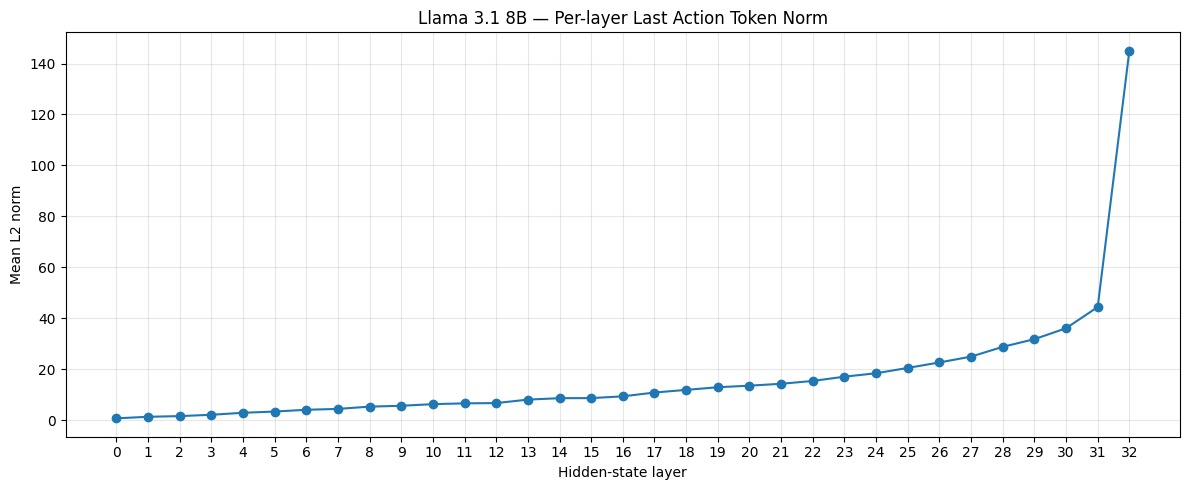

Number of layers: 33
Layer 0 norm: 0.6789466142654419
Layer 32 norm: 145.0287628173828


In [143]:
import numpy as np
import matplotlib.pyplot as plt

X = np.load(
    "/kaggle/working/ADNN_RQ1_Llama_v2/hidden_states/last_action_token.npy",
    mmap_mode="r"
)

layer_norms = []

for layer in range(X.shape[1]):
    norms = np.linalg.norm(
        X[:, layer, :].astype(np.float32),
        axis=1
    )
    layer_norms.append(float(np.mean(norms)))

plt.figure(figsize=(12, 5))
plt.plot(range(33), layer_norms, marker="o")
plt.xlabel("Hidden-state layer")
plt.ylabel("Mean L2 norm")
plt.title("Llama 3.1 8B — Per-layer Last Action Token Norm")
plt.xticks(range(33))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Number of layers:", len(layer_norms))
print("Layer 0 norm:", layer_norms[0])
print("Layer 32 norm:", layer_norms[32])


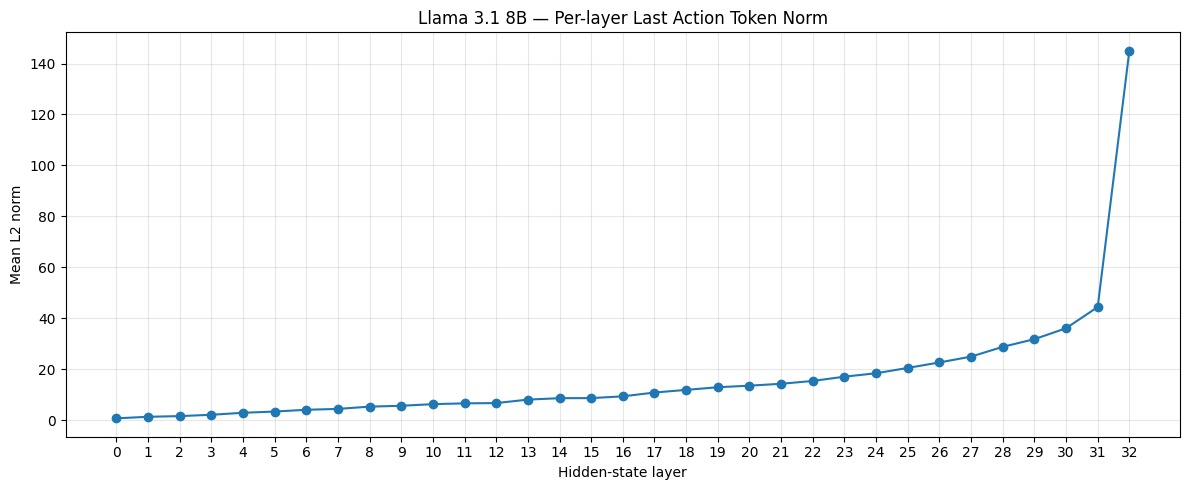


Saved successfully:
/kaggle/working/ADNN_RQ1_Llama_v2/plots/llama_v2_per_layer_norm.png
/kaggle/working/ADNN_RQ1_Llama_v2/plots/llama_v2_per_layer_norm.pdf
/kaggle/working/ADNN_RQ1_Llama_v2/plots/llama_v2_per_layer_norm.json


In [144]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
PLOT_DIR = ROOT / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Recreate plot using the already calculated layer_norms
plt.figure(figsize=(12, 5))
plt.plot(range(33), layer_norms, marker="o")

plt.xlabel("Hidden-state layer")
plt.ylabel("Mean L2 norm")
plt.title("Llama 3.1 8B — Per-layer Last Action Token Norm")
plt.xticks(range(33))
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save both formats
png_path = PLOT_DIR / "llama_v2_per_layer_norm.png"
pdf_path = PLOT_DIR / "llama_v2_per_layer_norm.pdf"

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

# Save numerical values
norm_data = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "representation": "last_action_token",
    "records": 2134,
    "num_layers_including_embedding": 33,
    "mean_l2_norm_by_layer": layer_norms
}

json_path = PLOT_DIR / "llama_v2_per_layer_norm.json"

with open(json_path, "w") as f:
    json.dump(norm_data, f, indent=2)

print("\nSaved successfully:")
print(png_path)
print(pdf_path)
print(json_path)

In [145]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_binary_layer_screening.json"
)

with open(path) as f:
    data = json.load(f)

print(json.dumps(data, indent=2)[:5000])

{
  "task": "binary",
  "representation": "last_action_token",
  "C": 0.001,
  "n_splits": 5,
  "selection_method": "GroupKFold_by_scenario",
  "test_used": false,
  "results": [
    {
      "layer": 15,
      "C": 0.001,
      "cv_balanced_accuracy": 0.8967157821651526,
      "cv_std": 0.05616350626459674,
      "fold_scores": [
        0.9041353383458647,
        0.7977011494252872,
        0.9728260869565217,
        0.9042553191489362,
        0.9046610169491525
      ],
      "time_sec": 10.315773725509644
    },
    {
      "layer": 16,
      "C": 0.001,
      "cv_balanced_accuracy": 0.8942599183801943,
      "cv_std": 0.053772501530951845,
      "fold_scores": [
        0.8984962406015038,
        0.8043678160919541,
        0.9728260869565217,
        0.8888297872340425,
        0.9067796610169492
      ],
      "time_sec": 11.37506651878357
    },
    {
      "layer": 17,
      "C": 0.001,
      "cv_balanced_accuracy": 0.893924848827481,
      "cv_std": 0.05347428356921017,
  

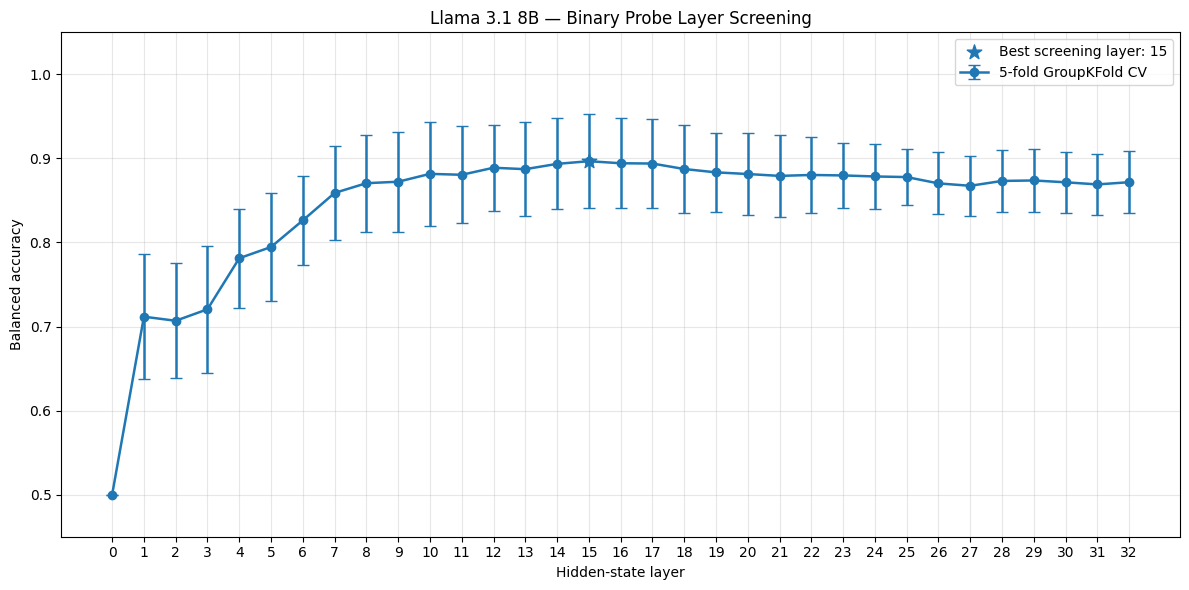

Best screening layer: 15
Best CV balanced accuracy: 0.8967
CV standard deviation: 0.0562

Saved PNG and PDF in: /kaggle/working/ADNN_RQ1_Llama_v2/plots


In [146]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
PLOT_DIR = ROOT / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Load saved layer-screening results
result_path = ROOT / "probes/llama_v2_binary_layer_screening.json"

with open(result_path) as f:
    data = json.load(f)

results = sorted(data["results"], key=lambda x: x["layer"])

layers = [r["layer"] for r in results]
scores = [r["cv_balanced_accuracy"] for r in results]
stds = [r["cv_std"] for r in results]

best_idx = int(np.argmax(scores))

plt.figure(figsize=(12, 6))

plt.errorbar(
    layers,
    scores,
    yerr=stds,
    marker="o",
    capsize=4,
    linewidth=1.8,
    label="5-fold GroupKFold CV"
)

plt.scatter(
    layers[best_idx],
    scores[best_idx],
    s=120,
    marker="*",
    label=f"Best screening layer: {layers[best_idx]}"
)

plt.xlabel("Hidden-state layer")
plt.ylabel("Balanced accuracy")
plt.title("Llama 3.1 8B — Binary Probe Layer Screening")
plt.xticks(layers)
plt.ylim(0.45, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save plots
plt.savefig(
    PLOT_DIR / "llama_v2_binary_layer_screening.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    PLOT_DIR / "llama_v2_binary_layer_screening.pdf",
    bbox_inches="tight"
)

plt.show()

print("Best screening layer:", layers[best_idx])
print("Best CV balanced accuracy:", round(scores[best_idx], 4))
print("CV standard deviation:", round(stds[best_idx], 4))
print("\nSaved PNG and PDF in:", PLOT_DIR)

In [147]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_binary_final_test_results.json"
)

with open(path) as f:
    data = json.load(f)

print(json.dumps(data, indent=2)[:4000])

{
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "dataset": "adnn-dataset-2.0",
  "task": "binary_irreversibility",
  "selected_layer": 16,
  "selected_C": 0.1,
  "selection_cv_balanced_accuracy": 0.921,
  "selection_cv_std": 0.0438,
  "train_records": 1709,
  "test_records": 425,
  "test_balanced_accuracy": 0.9099264705882353,
  "test_accuracy": 0.8847058823529412,
  "test_f1": 0.8619718309859155,
  "test_auroc": 0.9930074971164937,
  "classification_report": {
    "non_irreversible": {
      "precision": 1.0,
      "recall": 0.8198529411764706,
      "f1-score": 0.901010101010101,
      "support": 272.0
    },
    "irreversible": {
      "precision": 0.7574257425742574,
      "recall": 1.0,
      "f1-score": 0.8619718309859155,
      "support": 153.0
    },
    "accuracy": 0.8847058823529412,
    "macro avg": {
      "precision": 0.8787128712871287,
      "recall": 0.9099264705882353,
      "f1-score": 0.8814909659980082,
      "support": 425.0
    },
    "weighted avg": {
      "p

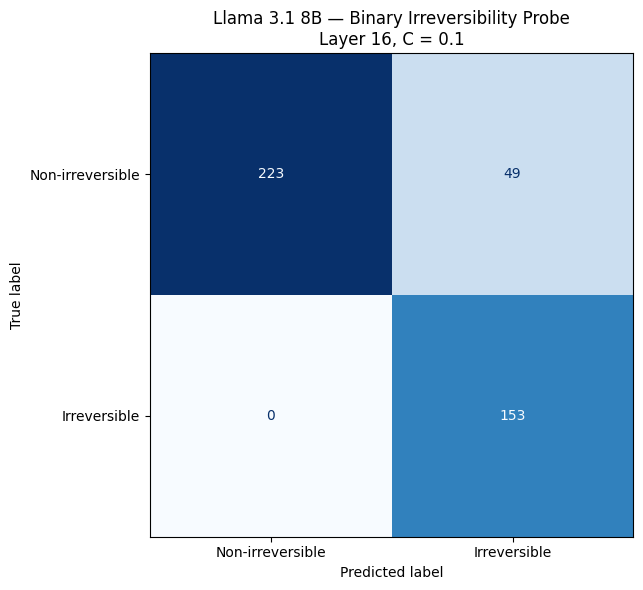

Confusion matrix:
[[223  49]
 [  0 153]]

Saved PNG and PDF in: /kaggle/working/ADNN_RQ1_Llama_v2/plots


In [148]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
PLOT_DIR = ROOT / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Load actual saved test results
result_path = ROOT / "probes/llama_v2_binary_final_test_results.json"

with open(result_path) as f:
    data = json.load(f)

cm = np.array(data["confusion_matrix"])

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-irreversible", "Irreversible"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Llama 3.1 8B — Binary Irreversibility Probe\n"
    "Layer 16, C = 0.1"
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "llama_v2_binary_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    PLOT_DIR / "llama_v2_binary_confusion_matrix.pdf",
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix:")
print(cm)
print("\nSaved PNG and PDF in:", PLOT_DIR)

In [149]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/probes/"
    "llama_v2_3class_final_test_results.json"
)

with open(path) as f:
    data = json.load(f)

print("Selected layer:", data.get("selected_layer"))
print("Selected C:", data.get("selected_C"))
print("Test accuracy:", data.get("test_accuracy"))
print("Balanced accuracy:", data.get("test_balanced_accuracy"))
print("Macro-F1:", data.get("test_macro_f1"))
print("\nConfusion matrix:")
print(data["confusion_matrix"])

Selected layer: 17
Selected C: 1.0
Test accuracy: None
Balanced accuracy: 0.9074074074074074
Macro-F1: 0.9248881505628962

Confusion matrix:
[[53, 2, 13], [0, 199, 5], [0, 5, 148]]


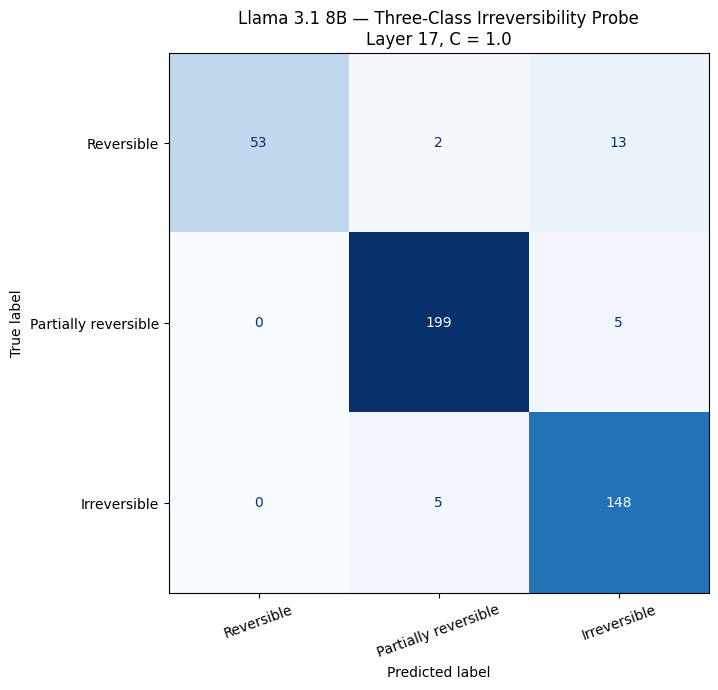

Confusion matrix:
[[ 53   2  13]
 [  0 199   5]
 [  0   5 148]]

Saved PNG and PDF: /kaggle/working/ADNN_RQ1_Llama_v2/plots


In [150]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
PLOT_DIR = ROOT / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

path = ROOT / "probes/llama_v2_3class_final_test_results.json"

with open(path) as f:
    data = json.load(f)

cm = np.array(data["confusion_matrix"])

fig, ax = plt.subplots(figsize=(8, 7))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Reversible",
        "Partially reversible",
        "Irreversible"
    ]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    xticks_rotation=20
)

ax.set_title(
    "Llama 3.1 8B — Three-Class Irreversibility Probe\n"
    "Layer 17, C = 1.0"
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "llama_v2_3class_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    PLOT_DIR / "llama_v2_3class_confusion_matrix.pdf",
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix:")
print(cm)
print("\nSaved PNG and PDF:", PLOT_DIR)

In [151]:
from pathlib import Path

print("Current Llama folder:")
print(Path("/kaggle/working/ADNN_RQ1_Llama_v2").exists())

print("\nCurrent working directory:")
print(list(Path("/kaggle/working").iterdir()))

Current Llama folder:
True

Current working directory:
[PosixPath('/kaggle/working/ADNN_RQ1_Llama_v2_BACKUP.zip'), PosixPath('/kaggle/working/ADNN_RQ1_Llama_v2'), PosixPath('/kaggle/working/.virtual_documents')]


In [152]:
from pathlib import Path

working = Path("/kaggle/working")

qwen_folder = working / "ADNN_RQ1_Qwen_v2"
comparison_folder = working / "COMPARISON"

qwen_folder.mkdir(exist_ok=True)
comparison_folder.mkdir(exist_ok=True)

print("Folders created:")
print(qwen_folder)
print(comparison_folder)

print("\nQwen input datasets:")
for folder in Path("/kaggle/input").iterdir():
    print(folder)

Folders created:
/kaggle/working/ADNN_RQ1_Qwen_v2
/kaggle/working/COMPARISON

Qwen input datasets:
/kaggle/input/datasets


In [153]:
from pathlib import Path

input_path = Path("/kaggle/input/datasets")

for path in input_path.rglob("*"):
    if path.is_file():
        print(path)

/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-v2.0-SHA256SUMS.txt
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/comparison.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/measurement_audit.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase5a/symmetry_summary.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/main/h4-burn-chair-water-near.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/main/h4-burn-painting-water-near.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/main/h4-connect-battery-wire.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/main/h4-move-cup-to-table.json
/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/results/phase4h/main/h4-open-fridge.json
/kaggle/input/datasets/aashri

In [154]:
from pathlib import Path

qwen_source = Path(
    "/kaggle/input/datasets/aashrithap/adnn-qwen-rq1-results/ADNN_RQ1_Qwen_v2"
)

print("Qwen source exists:", qwen_source.exists())

total_size = sum(
    f.stat().st_size for f in qwen_source.rglob("*") if f.is_file()
)

print(f"Total size: {total_size / (1024**3):.2f} GB")

print("\nTop-level folders:")
for folder in qwen_source.iterdir():
    if folder.is_dir():
        print("-", folder.name)

Qwen source exists: True
Total size: 0.83 GB

Top-level folders:
- ablations
- analysis
- baselines
- config
- hidden_states
- probes


In [155]:
from pathlib import Path
import shutil

qwen_source = Path(
    "/kaggle/input/datasets/aashrithap/adnn-qwen-rq1-results/ADNN_RQ1_Qwen_v2"
)

qwen_target = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

if any(qwen_target.iterdir()):
    print("Target folder is not empty. Skipping copy to avoid overwriting.")
else:
    shutil.copytree(qwen_source, qwen_target, dirs_exist_ok=True)
    print("Qwen results copied successfully.")

print("\nVerification:")
for folder in qwen_target.iterdir():
    print("-", folder.name)

print("\nHidden-state files:")
for file in (qwen_target / "hidden_states").iterdir():
    print("-", file.name)

Qwen results copied successfully.

Verification:
- ablations
- hidden_states
- analysis
- probes
- baselines
- config

Hidden-state files:
- last_action_token.npy
- extraction_progress.npy
- extraction_index.jsonl
- extraction_manifest.jsonl
- mean_action_tokens.npy
- extraction_metadata.json


In [156]:
import json
from pathlib import Path

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

files_to_inspect = [
    qwen / "config/experiment_config.json",
    qwen / "probes/best_layers.json",
    qwen / "probes/qwen_v2_final_3class_results.json",
    qwen / "probes/qwen_v2_final_binary_results.json",
    qwen / "probes/qwen_v2_binary_c_selection.json"
]

for file in files_to_inspect:
    print(f"\n{'='*60}\n{file.name}\n{'='*60}")
    if file.exists():
        with open(file, "r") as f:
            print(json.dumps(json.load(f), indent=2)[:6000])
    else:
        print("File not found.")


experiment_config.json
{
  "experiment": "ADNN_RQ1_Qwen_v2_final",
  "dataset_version": "v2.0",
  "model_family": "Qwen",
  "research_question": "RQ1",
  "representation": "last_action_token",
  "probe": "L2_logistic_regression",
  "splitting": "scenario_level",
  "num_random_splits": 3,
  "bootstrap_resamples": 1000,
  "metrics": [
    "balanced_accuracy",
    "macro_f1",
    "auroc"
  ],
  "required_probe_tasks": [
    "binary",
    "three_class"
  ],
  "required_controls": [
    "majority_class_baseline",
    "lexical_action_text_baseline",
    "shuffled_label_probe",
    "random_label_control_selectivity",
    "embedding_layer_baseline"
  ],
  "required_ablations": [
    "last_token_vs_mean_action_tokens",
    "minimal_pairs_only_vs_all_data",
    "cross_environment_transfer"
  ],
  "save_incrementally": true,
  "resume_completed_work": true,
  "created_at": "2026-11-03T06:15:10.926864"
}

best_layers.json
{
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "three_class": {
    "selected_l

In [157]:
import json
from pathlib import Path

base = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")

# Inspect robustness subset
with open(base / "robustness_subset_le3.json") as f:
    robustness = json.load(f)

print("ROBUSTNESS FILE TYPE:", type(robustness))

if isinstance(robustness, dict):
    print("Keys:", list(robustness.keys()))
    print(json.dumps(robustness, indent=2)[:2500])
elif isinstance(robustness, list):
    print("Number of entries:", len(robustness))
    print(json.dumps(robustness[:3], indent=2)[:2500])

# Inspect Qwen extraction index
index_path = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/hidden_states/extraction_index.jsonl")

with open(index_path) as f:
    first_records = [json.loads(next(f)) for _ in range(3)]

print("\nEXTRACTION INDEX FIELDS:")
print(list(first_records[0].keys()))
print("\nFIRST THREE INDEX RECORDS:")
print(json.dumps(first_records, indent=2)[:2500])

ROBUSTNESS FILE TYPE: <class 'dict'>
Keys: ['classes_h3', 'coarse_scenarios', 'complete_pairs', 'ids', 'max_records_per_coarse_scenario', 'records', 'rule', 'split_pairs', 'test', 'train']
{
  "classes_h3": {
    "irreversible": 178,
    "partially_reversible": 253,
    "reversible": 276
  },
  "coarse_scenarios": 256,
  "complete_pairs": 136,
  "ids": [
    "f01_delete_bin-0000-alt0-single-compact",
    "f01_delete_bin-0000-alt0-single-kv",
    "f01_delete_bin-0000-alt0-single-prose",
    "f01_delete_bin-0000-alt1-single-kv",
    "f01_delete_bin-0000-alt1-single-prose",
    "f01_delete_bin-0000-primary-False-kv",
    "f01_delete_bin-0000-primary-False-prose",
    "f01_delete_bin-0000-primary-True-kv",
    "f01_delete_bin-0000-primary-True-prose",
    "f01_delete_bin-0001-alt0-single-kv",
    "f01_delete_bin-0001-primary-False-kv",
    "f01_delete_bin-0001-primary-True-kv",
    "f01_delete_bin-0002-alt1-single-kv",
    "f01_delete_bin-0002-alt1-single-prose",
    "f01_delete_bin-0003-a

In [160]:
import json
from pathlib import Path
from collections import Counter

base = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0"
)

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

with open(base / "robustness_subset_le3.json") as f:
    robustness = json.load(f)

with open(qwen / "hidden_states/extraction_index.jsonl") as f:
    index = [json.loads(line) for line in f]

index_by_id = {row["record_id"]: row for row in index}

robust_ids = set(robustness["ids"])
matched_ids = robust_ids & set(index_by_id)

print("Robustness IDs:", len(robust_ids))
print("Matched in Qwen index:", len(matched_ids))
print("Missing IDs:", len(robust_ids - set(index_by_id)))

print("\nOfficial split counts:")
print(Counter(index_by_id[x]["split"] for x in matched_ids))

print("\nClass counts by official split:")
for split in ["train", "test"]:
    print(split, Counter(
        index_by_id[x]["label"]
        for x in matched_ids
        if index_by_id[x]["split"] == split
    ))

print("\nExpected counts from robustness file:")
print("Train:", robustness["train"])
print("Test:", robustness["test"])

Robustness IDs: 707
Matched in Qwen index: 707
Missing IDs: 0

Official split counts:
Counter({'train': 580, 'test': 127})

Class counts by official split:
train Counter({'reversible': 248, 'partially_reversible': 193, 'irreversible': 139})
test Counter({'partially_reversible': 60, 'irreversible': 39, 'reversible': 28})

Expected counts from robustness file:
Train: 580
Test: 127


In [161]:
import json
from pathlib import Path

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

with open(qwen / "probes/probe_split.json") as f:
    split_info = json.load(f)

print(json.dumps(split_info, indent=2)[:5000])

{
  "dataset_version": "adnn-dataset-2.0",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "split_source": "official split.json",
  "split_type": "scenario_level",
  "total_records": 2134,
  "train_records": 1709,
  "test_records": 425,
  "train_scenarios_in_records": 124,
  "test_scenarios_in_records": 25,
  "official_train_scenarios": 124,
  "official_test_scenarios": 27,
  "metadata_only_test_scenarios": [
    "grp-0cc4fd8f73a6",
    "grp-f8673bb166d9"
  ],
  "label_mapping": {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
  },
  "representations": [
    "last_action_token",
    "mean_action_tokens"
  ]
}


In [162]:
import json
import numpy as np
from pathlib import Path
from collections import Counter

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

# Load extraction index
with open(qwen / "hidden_states/extraction_index.jsonl") as f:
    index = [json.loads(line) for line in f]

# Load hidden states
last_states = np.load(
    qwen / "hidden_states/last_action_token.npy",
    mmap_mode="r"
)

# Check dimensions and data
print("Hidden-state shape:", last_states.shape)
print("Data type:", last_states.dtype)
print("Number of index records:", len(index))

print("\nOfficial split counts:")
print(Counter(row["split"] for row in index))

print("\nLabel mapping:")
print(Counter(row["label"] for row in index))

print("\nRobustness test records in official test split:")
with open(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/robustness_subset_le3.json"
) as f:
    robustness = json.load(f)

index_by_id = {row["record_id"]: row for row in index}
robust_test = [index_by_id[x] for x in robustness["ids"]
               if index_by_id[x]["split"] == "test"]

print("Count:", len(robust_test))
print("Labels:", Counter(row["label"] for row in robust_test))
print("All finite:", np.isfinite(last_states).all())

Hidden-state shape: (2134, 29, 3584)
Data type: float16
Number of index records: 2134

Official split counts:
Counter({'train': 1709, 'test': 425})

Label mapping:
Counter({'reversible': 799, 'partially_reversible': 758, 'irreversible': 577})

Robustness test records in official test split:
Count: 127
Labels: Counter({'partially_reversible': 60, 'irreversible': 39, 'reversible': 28})
All finite: True


In [163]:
import json
from pathlib import Path

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

files = [
    "probes/qwen_v2_final_3class_results.json",
    "probes/qwen_v2_final_binary_results.json"
]

for filename in files:
    path = qwen / filename

    with open(path) as f:
        data = json.load(f)

    print(f"\n--- {filename} ---")

    for key in ["classifier", "selection", "selected_layer",
                "selected_C", "representation"]:
        if key in data:
            print(key, ":", data[key])


--- probes/qwen_v2_final_3class_results.json ---
selected_layer : 20
selected_C : 0.1

--- probes/qwen_v2_final_binary_results.json ---
classifier : {'scaler': 'StandardScaler', 'penalty': 'l2', 'C': 0.01, 'class_weight': 'balanced', 'solver': 'saga', 'max_iter': 500, 'tol': 0.01, 'random_state': 42}
selection : {'method': 'inner_group_kfold_cv', 'selected_layer': 18, 'selected_C': 0.01, 'inner_cv_balanced_accuracy': 0.9211, 'inner_cv_sd': 0.0361, 'test_used_during_selection': False}
representation : {'type': 'last_action_token', 'layer': 18}


In [164]:
import json
from pathlib import Path

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

for filename in [
    "probes/metrics.json",
    "probes/manifest.json",
    "probes/qwen_v2_3class_layer_screening.json"
]:
    path = qwen / filename

    print(f"\n{'='*55}")
    print(filename)
    print('='*55)

    if path.exists():
        with open(path) as f:
            data = json.load(f)
        print(json.dumps(data, indent=2)[:4000])
    else:
        print("Not found.")


probes/metrics.json
{
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "primary_three_class": {
    "layer": 20,
    "C": 0.1,
    "balanced_accuracy": 0.9216,
    "macro_f1": 0.9209,
    "auroc": 0.9951,
    "per_class": {
      "reversible": {
        "precision": 0.8788,
        "recall": 0.8529,
        "f1": 0.8657,
        "support": 68
      },
      "partially_reversible": {
        "precision": 0.9896,
        "recall": 0.9314,
        "f1": 0.9596,
        "support": 204
      },
      "irreversible": {
        "precision": 0.8982,
        "recall": 0.9804,
        "f1": 0.9375,
        "support": 153
      }
    },
    "confusion_matrix": [
      [
        58,
        2,
        8
      ],
      [
        5,
        190,
        9
      ],
      [
        3,
        0,
        150
      ]
    ]
  },
  "primary_binary": {
    "layer": 18,
    "C": 0.01,
    "accuracy": 0.8870588235294118,
    "balanced_accuracy": 0.9117647058823529,
    "macro_f1": 0.8838162930563149,
    "auroc": 0

In [168]:
from pathlib import Path

path = Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb")
source = path.read_text(encoding="utf-8", errors="replace")

for keyword in [
    "Qwen2.5",
    "LogisticRegression",
    "multi_class",
    "three_class",
    "selected_layer",
    "solver="
]:
    print(f"\n{keyword}: {source.lower().count(keyword.lower())} occurrences")

print("\nModel IDs found:")
for line in source.splitlines():
    if "MODEL_ID" in line or "Qwen" in line or "Llama" in line:
        print(line[:300])


Qwen2.5: 0 occurrences

LogisticRegression: 4 occurrences

multi_class: 2 occurrences

three_class: 0 occurrences

selected_layer: 0 occurrences

solver=: 2 occurrences

Model IDs found:
MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
        MODEL_ID,
    print("Llama access: SUCCESS")
    print("Model:", MODEL_ID)
    print("Llama access: FAILED")
MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
    MODEL_ID,
# Exact Qwen logical prompt construction
# Test first record using Llama's official template
print("\nFormatted Llama prompt:")
ROOT = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
# Same structure as Qwen
    "experiment": "ADNN RQ1 Llama v2",
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    zip_path = Path("/kaggle/working") / f"ADNN_RQ1_Llama_v2_backup_{timestamp}.zip"
    "model_id": "meta-llama/Llama-3.1-8B-Instruct",
    "model_id": "meta-llama/Llama-3.1-8B-Instruct",
MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
print("Loading Llama 3.1 8B...")
    MODEL_ID,
print("Model:", M

In [170]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

# Paths
ROOT = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
DATA = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0"
)

# Load data
X_all = np.load(
    ROOT / "hidden_states/last_action_token.npy",
    mmap_mode="r"
)

with open(ROOT / "hidden_states/extraction_index.jsonl") as f:
    index = [json.loads(line) for line in f]

with open(DATA / "robustness_subset_le3.json") as f:
    robustness = json.load(f)

# Official training records
train_rows = [r for r in index if r["split"] == "train"]

# Robustness test records only
index_by_id = {r["record_id"]: r for r in index}
test_rows = [
    index_by_id[rid]
    for rid in robustness["ids"]
    if index_by_id[rid]["split"] == "test"
]

# Label mapping
label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}

train_idx = np.array([r["row_index"] for r in train_rows])
test_idx = np.array([r["row_index"] for r in test_rows])

y_train = np.array([label_map[r["label"]] for r in train_rows])
y_test = np.array([label_map[r["label"]] for r in test_rows])

# Selected Qwen three-class configuration
LAYER = 20
C = 0.1

X_train = np.asarray(X_all[train_idx, LAYER, :], dtype=np.float32)
X_test = np.asarray(X_all[test_idx, LAYER, :], dtype=np.float32)

# Fit scaler on original training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit probe
clf = LogisticRegression(
    C=C,
    penalty="l2",
    solver="saga",
    max_iter=500,
    tol=0.01,
    class_weight="balanced",
    multi_class="multinomial",
    random_state=0
)

clf.fit(X_train_scaled, y_train)

# Evaluate
pred = clf.predict(X_test_scaled)
probs = clf.predict_proba(X_test_scaled)

print("QWEN THREE-CLASS ROBUSTNESS RESULTS")
print("-----------------------------------")
print("Training records:", len(y_train))
print("Robustness test records:", len(y_test))
print("Layer:", LAYER)
print("C:", C)
print("Accuracy:", accuracy_score(y_test, pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, pred))
print("Macro F1:", f1_score(y_test, pred, average="macro"))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, pred, labels=[0, 1, 2]))
print("\nClassification report:")
print(classification_report(
    y_test, pred,
    labels=[0, 1, 2],
    target_names=["reversible", "partially_reversible", "irreversible"],
    zero_division=0
))

QWEN THREE-CLASS ROBUSTNESS RESULTS
-----------------------------------
Training records: 1709
Robustness test records: 127
Layer: 20
C: 0.1
Accuracy: 0.9291338582677166
Balanced accuracy: 0.9279609279609279
Macro F1: 0.9237665626554517

Confusion matrix:
[[25  2  1]
 [ 2 55  3]
 [ 1  0 38]]

Classification report:
                      precision    recall  f1-score   support

          reversible       0.89      0.89      0.89        28
partially_reversible       0.96      0.92      0.94        60
        irreversible       0.90      0.97      0.94        39

            accuracy                           0.93       127
           macro avg       0.92      0.93      0.92       127
        weighted avg       0.93      0.93      0.93       127



In [171]:
import json
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

ROOT = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
out = ROOT / "probes"
out.mkdir(exist_ok=True)

class_names = [
    "reversible",
    "partially_reversible",
    "irreversible"
]

cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])

report = classification_report(
    y_test,
    pred,
    labels=[0, 1, 2],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

results = {
    "experiment": "Qwen v2 three-class robustness subset",
    "model": "Qwen/Qwen2.5-7B-Instruct",
    "representation": "last_action_token",
    "layer": 20,
    "C": 0.1,
    "training_records": len(y_train),
    "robustness_test_records": len(y_test),
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, pred)),
        "macro_f1": float(f1_score(y_test, pred, average="macro")),
    },
    "confusion_matrix": cm.tolist(),
    "per_class": {
        name: {
            metric: float(report[name][metric])
            for metric in ["precision", "recall", "f1-score", "support"]
        }
        for name in class_names
    },
    "classifier": {
        "scaler": "StandardScaler",
        "penalty": "l2",
        "solver": "saga",
        "class_weight": "balanced",
        "multi_class": "multinomial",
        "max_iter": 500,
        "tol": 0.01,
        "random_state": 0
    }
}

with open(out / "qwen_v2_3class_robustness_subset.json", "w") as f:
    json.dump(results, f, indent=2)

predictions_file = out / "qwen_v2_3class_robustness_predictions.jsonl"

with open(predictions_file, "w") as f:
    for i, row in enumerate(test_rows):
        item = {
            "record_id": row["record_id"],
            "scenario_id": row["scenario_id"],
            "true_label": class_names[y_test[i]],
            "predicted_label": class_names[pred[i]],
            "correct": bool(y_test[i] == pred[i]),
            "probabilities": {
                class_names[j]: float(probs[i, j])
                for j in range(3)
            }
        }
        f.write(json.dumps(item) + "\n")

print("Saved results:", out / "qwen_v2_3class_robustness_subset.json")
print("Saved predictions:", predictions_file)
print("Both files exist:", 
      (out / "qwen_v2_3class_robustness_subset.json").exists()
      and predictions_file.exists())

Saved results: /kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_3class_robustness_subset.json
Saved predictions: /kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_3class_robustness_predictions.jsonl
Both files exist: True


In [172]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Binary labels: irreversible = 1, everything else = 0
y_train_bin = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in train_rows
])

y_test_bin = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in test_rows
])

# Selected Qwen binary configuration
LAYER = 18
C = 0.01

X_train_bin = np.asarray(
    X_all[train_idx, LAYER, :], dtype=np.float32
)
X_test_bin = np.asarray(
    X_all[test_idx, LAYER, :], dtype=np.float32
)

# Fit scaler only on original training records
scaler_bin = StandardScaler()
X_train_scaled_bin = scaler_bin.fit_transform(X_train_bin)
X_test_scaled_bin = scaler_bin.transform(X_test_bin)

# Fit binary probe
clf_bin = LogisticRegression(
    C=C,
    penalty="l2",
    solver="saga",
    max_iter=500,
    tol=0.01,
    class_weight="balanced",
    random_state=42
)

clf_bin.fit(X_train_scaled_bin, y_train_bin)

# Evaluate robustness test
pred_bin = clf_bin.predict(X_test_scaled_bin)
probs_bin = clf_bin.predict_proba(X_test_scaled_bin)[:, 1]

print("QWEN BINARY ROBUSTNESS RESULTS")
print("--------------------------------")
print("Training records:", len(y_train_bin))
print("Robustness test records:", len(y_test_bin))
print("Layer:", LAYER)
print("C:", C)
print("Accuracy:", accuracy_score(y_test_bin, pred_bin))
print("Balanced accuracy:", balanced_accuracy_score(y_test_bin, pred_bin))
print("Macro F1:", f1_score(y_test_bin, pred_bin, average="macro"))
print("AUROC:", roc_auc_score(y_test_bin, probs_bin))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_bin, pred_bin, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test_bin,
    pred_bin,
    labels=[0, 1],
    target_names=["non_irreversible", "irreversible"],
    zero_division=0
))

QWEN BINARY ROBUSTNESS RESULTS
--------------------------------
Training records: 1709
Robustness test records: 127
Layer: 18
C: 0.01
Accuracy: 0.8661417322834646
Balanced accuracy: 0.9034090909090908
Macro F1: 0.8570671962926184
AUROC: 0.9874708624708625

Confusion matrix:
[[71 17]
 [ 0 39]]

Classification report:
                  precision    recall  f1-score   support

non_irreversible       1.00      0.81      0.89        88
    irreversible       0.70      1.00      0.82        39

        accuracy                           0.87       127
       macro avg       0.85      0.90      0.86       127
    weighted avg       0.91      0.87      0.87       127



In [173]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

ROOT = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
out = ROOT / "probes"

class_names = ["non_irreversible", "irreversible"]

cm = confusion_matrix(y_test_bin, pred_bin, labels=[0, 1])

report = classification_report(
    y_test_bin,
    pred_bin,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

results = {
    "experiment": "Qwen v2 binary robustness subset",
    "model": "Qwen/Qwen2.5-7B-Instruct",
    "representation": "last_action_token",
    "layer": 18,
    "C": 0.01,
    "training_records": len(y_train_bin),
    "robustness_test_records": len(y_test_bin),
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test_bin, pred_bin)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test_bin, pred_bin)),
        "macro_f1": float(f1_score(y_test_bin, pred_bin, average="macro")),
        "auroc": float(roc_auc_score(y_test_bin, probs_bin))
    },
    "confusion_matrix": cm.tolist(),
    "per_class": {
        name: {
            metric: float(report[name][metric])
            for metric in ["precision", "recall", "f1-score", "support"]
        }
        for name in class_names
    },
    "classifier": {
        "scaler": "StandardScaler",
        "penalty": "l2",
        "solver": "saga",
        "class_weight": "balanced",
        "max_iter": 500,
        "tol": 0.01,
        "random_state": 42
    }
}

with open(out / "qwen_v2_binary_robustness_subset.json", "w") as f:
    json.dump(results, f, indent=2)

predictions_file = out / "qwen_v2_binary_robustness_predictions.jsonl"

with open(predictions_file, "w") as f:
    for i, row in enumerate(test_rows):
        item = {
            "record_id": row["record_id"],
            "scenario_id": row["scenario_id"],
            "true_label": class_names[y_test_bin[i]],
            "predicted_label": class_names[pred_bin[i]],
            "correct": bool(y_test_bin[i] == pred_bin[i]),
            "irreversible_probability": float(probs_bin[i])
        }
        f.write(json.dumps(item) + "\n")

print("Saved binary robustness metrics.")
print("Saved binary robustness predictions.")
print("Metrics file exists:",
      (out / "qwen_v2_binary_robustness_subset.json").exists())
print("Predictions file exists:", predictions_file.exists())

Saved binary robustness metrics.
Saved binary robustness predictions.
Metrics file exists: True
Predictions file exists: True


In [174]:
import json
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")
}

files = {
    "Three-class": "qwen_v2_3class_robustness_subset.json",
    "Binary": "qwen_v2_binary_robustness_subset.json"
}

for model, folder in folders.items():
    print(f"\n{'='*45}")
    print(model)
    print('='*45)

    for task, filename in files.items():
        if model == "Llama":
            filename = filename.replace("qwen_v2", "llama_v2")

        path = folder / filename
        print(f"\n{task}: {path.exists()}")

        if path.exists():
            with open(path) as f:
                data = json.load(f)

            print(json.dumps(data.get("test_metrics", {}), indent=2))


Qwen

Three-class: True
{
  "accuracy": 0.9291338582677166,
  "balanced_accuracy": 0.9279609279609279,
  "macro_f1": 0.9237665626554517
}

Binary: True
{
  "accuracy": 0.8661417322834646,
  "balanced_accuracy": 0.9034090909090908,
  "macro_f1": 0.8570671962926184,
  "auroc": 0.9874708624708625
}

Llama

Three-class: True
{}

Binary: False


In [175]:
from pathlib import Path
import json

llama = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

print("ALL LLAMA ROBUSTNESS FILES:")
for path in llama.rglob("*robustness*"):
    if path.is_file():
        print("\nFile:", path)
        print("Size:", path.stat().st_size, "bytes")

        if path.suffix == ".json":
            with open(path) as f:
                data = json.load(f)
            print(json.dumps(data, indent=2)[:4000])

ALL LLAMA ROBUSTNESS FILES:

File: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_robustness_subset.json
Size: 960 bytes
{
  "experiment": "llama_v2_3class_robustness_subset",
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "probe": {
    "layer": 17,
    "C": 1.0,
    "training_partition": "original_1709_record_train"
  },
  "evaluation": {
    "subset_total_records": 707,
    "subset_train_records": 580,
    "subset_test_records": 127,
    "retrained_on_subset": false,
    "accuracy": 0.9291338582677166,
    "balanced_accuracy": 0.9122710622710622,
    "macro_f1": 0.9210258315514609,
    "class_support": {
      "reversible": 28,
      "partially_reversible": 60,
      "irreversible": 39
    },
    "confusion_matrix": [
      [
        23,
        1,
        4
      ],
      [
        0,
        58,
        2
      ],
      [
        0,
        2,
        37
      ]
    ]
  },
  "note": "Secondary evaluation on robustness-subset test records. Probe trained only on the orig

In [176]:
from pathlib import Path

llama_probes = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")

print("Llama probe files:")
for path in sorted(llama_probes.iterdir()):
    if path.is_file():
        print(path.name)

Llama probe files:
llama_v2_3class_final_test_results.json
llama_v2_3class_inner_cv_progress.json
llama_v2_3class_layer_screening.json
llama_v2_3class_layer_screening_progress.json
llama_v2_3class_robustness_subset.json
llama_v2_binary_bootstrap_ci.json
llama_v2_binary_final_test_results.json
llama_v2_binary_horizon_ablations.json
llama_v2_binary_inner_cv.json
llama_v2_binary_inner_cv_progress.json
llama_v2_binary_layer_screening.json
llama_v2_binary_layer_screening_progress.json
llama_v2_binary_predictions.jsonl
llama_v2_binary_shuffled_label_control.json
probe_split.json


In [177]:
import json
from pathlib import Path

llama = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")

for filename in [
    "llama_v2_binary_final_test_results.json",
    "llama_v2_binary_inner_cv.json"
]:
    path = llama / filename

    print(f"\n{'='*50}")
    print(filename)
    print('='*50)

    with open(path) as f:
        data = json.load(f)

    print(json.dumps(data, indent=2)[:5000])


llama_v2_binary_final_test_results.json
{
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "dataset": "adnn-dataset-2.0",
  "task": "binary_irreversibility",
  "selected_layer": 16,
  "selected_C": 0.1,
  "selection_cv_balanced_accuracy": 0.921,
  "selection_cv_std": 0.0438,
  "train_records": 1709,
  "test_records": 425,
  "test_balanced_accuracy": 0.9099264705882353,
  "test_accuracy": 0.8847058823529412,
  "test_f1": 0.8619718309859155,
  "test_auroc": 0.9930074971164937,
  "classification_report": {
    "non_irreversible": {
      "precision": 1.0,
      "recall": 0.8198529411764706,
      "f1-score": 0.901010101010101,
      "support": 272.0
    },
    "irreversible": {
      "precision": 0.7574257425742574,
      "recall": 1.0,
      "f1-score": 0.8619718309859155,
      "support": 153.0
    },
    "accuracy": 0.8847058823529412,
    "macro avg": {
      "precision": 0.8787128712871287,
      "recall": 0.9099264705882353,
      "f1-score": 0.8814909659980082,
      "support": 42

In [178]:
from pathlib import Path

path = Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb")
lines = path.read_text(encoding="utf-8", errors="replace").splitlines()

for i, line in enumerate(lines):
    if "LogisticRegression(" in line:
        print(f"\n--- Classifier around line {i+1} ---")
        for j in range(i, min(i + 16, len(lines))):
            print(f"{j+1}: {lines[j]}")


--- Classifier around line 1959 ---
1959:         clf = LogisticRegression(
1960:             C=C,
1961:             penalty="l2",
1962:             solver="saga",
1963:             max_iter=500,
1964:             tol=1e-2,
1965:             class_weight="balanced",
1966:             multi_class="multinomial",
1967:             random_state=0
1968:         )
1969: 
1970:         clf.fit(Xtr, y_layer[tr])
1971: 
1972:         pred = clf.predict(Xva)
1973: 
1974:         ba = balanced_accuracy_score(

--- Classifier around line 2137 ---
2137:             clf = LogisticRegression(
2138:                 C=C,
2139:                 penalty="l2",
2140:                 solver="saga",
2141:                 max_iter=500,
2142:                 tol=1e-2,
2143:                 class_weight="balanced",
2144:                 multi_class="multinomial",
2145:                 random_state=0
2146:             )
2147: 
2148:             clf.fit(Xtr, ytr)
2149: 
2150:             pred = clf.predict(Xva)
2

In [179]:
import json
from pathlib import Path

folder = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")

for filename in [
    "llama_v2_binary_layer_screening.json",
    "llama_v2_binary_final_test_results.json"
]:
    print(f"\n--- {filename} ---")
    with open(folder / filename) as f:
        data = json.load(f)

    print(json.dumps(data, indent=2)[:7000])


--- llama_v2_binary_layer_screening.json ---
{
  "task": "binary",
  "representation": "last_action_token",
  "C": 0.001,
  "n_splits": 5,
  "selection_method": "GroupKFold_by_scenario",
  "test_used": false,
  "results": [
    {
      "layer": 15,
      "C": 0.001,
      "cv_balanced_accuracy": 0.8967157821651526,
      "cv_std": 0.05616350626459674,
      "fold_scores": [
        0.9041353383458647,
        0.7977011494252872,
        0.9728260869565217,
        0.9042553191489362,
        0.9046610169491525
      ],
      "time_sec": 10.315773725509644
    },
    {
      "layer": 16,
      "C": 0.001,
      "cv_balanced_accuracy": 0.8942599183801943,
      "cv_std": 0.053772501530951845,
      "fold_scores": [
        0.8984962406015038,
        0.8043678160919541,
        0.9728260869565217,
        0.8888297872340425,
        0.9067796610169492
      ],
      "time_sec": 11.37506651878357
    },
    {
      "layer": 17,
      "C": 0.001,
      "cv_balanced_accuracy": 0.8939248488

In [180]:
from pathlib import Path

path = Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb")
lines = path.read_text(encoding="utf-8", errors="replace").splitlines()

terms = ["binary_irreversibility", "non_irreversible", "selected_C", "binary"]

for term in terms:
    print(f"\n--- Matches for: {term} ---")
    matches = [i for i, line in enumerate(lines) if term in line]
    print("Line numbers:", [i + 1 for i in matches[:30]])

    for i in matches[-3:]:
        print(f"\nContext around line {i+1}:")
        for j in range(max(0, i-8), min(len(lines), i+18)):
            print(f"{j+1}: {lines[j]}")


--- Matches for: binary_irreversibility ---
Line numbers: []

--- Matches for: non_irreversible ---
Line numbers: []

--- Matches for: selected_C ---
Line numbers: []

--- Matches for: binary ---
Line numbers: []


In [181]:
from pathlib import Path

folders = [
    Path("/kaggle/working/ADNN_RQ1_Llama_v2"),
    Path("/kaggle/working/.virtual_documents")
]

for folder in folders:
    print(f"\n--- Files in {folder} ---")
    for path in sorted(folder.rglob("*")):
        if path.is_file() and (
            path.suffix in [".py", ".ipynb", ".json"]
            or "binary" in path.name.lower()
        ):
            print(path)


--- Files in /kaggle/working/ADNN_RQ1_Llama_v2 ---
/kaggle/working/ADNN_RQ1_Llama_v2/ablations/llama_v2_binary_mean_action_tokens_layer18.json
/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_3class_style_analysis.json
/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_canonical_24_minimal_pairs.json
/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_sandbox_to_scienceworld.json
/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_scienceworld_to_sandbox_limitation.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_bow_action_text.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_bow_state_action.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_layer0_embedding_baseline.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_majority_baseline.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_random_action_verb_control.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_selectivity.json
/kaggle/workin

In [182]:
import json
from pathlib import Path

folder = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

files = [
    folder / "probes/llama_v2_binary_inner_cv.json",
    folder / "probes/llama_v2_binary_horizon_ablations.json",
    folder / "ablations/llama_v2_binary_mean_action_tokens_layer18.json",
]

for path in files:
    print(f"\n--- {path.name} ---")
    with open(path) as f:
        data = json.load(f)
    print(json.dumps(data, indent=2)[:5000])


--- llama_v2_binary_inner_cv.json ---
{
  "task": "binary",
  "selection_method": "5-fold GroupKFold",
  "test_used": false,
  "results": [
    {
      "layer": 16,
      "C": 0.1,
      "fold_scores": [
        0.8966165413533834,
        0.8621455938697318,
        0.9855072463768115,
        0.9058510638297872,
        0.9550287815797889
      ],
      "mean_ba": 0.9210298454019006,
      "std_ba": 0.04383382894703717
    },
    {
      "layer": 20,
      "C": 0.1,
      "fold_scores": [
        0.8994360902255638,
        0.89272030651341,
        0.9673913043478262,
        0.9017730496453901,
        0.9406779661016949
      ],
      "mean_ba": 0.920399743366777,
      "std_ba": 0.028885957893958057
    },
    {
      "layer": 20,
      "C": 1.0,
      "fold_scores": [
        0.8994360902255638,
        0.89272030651341,
        0.9655797101449275,
        0.9017730496453901,
        0.9406779661016949
      ],
      "mean_ba": 0.9200374245261973,
      "std_ba": 0.028299678574

In [185]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

base = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
dataset = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0"
)

X_all = np.load(base / "hidden_states/last_action_token.npy", mmap_mode="r")

with open(base / "hidden_states/extraction_index.jsonl") as f:
    index = [json.loads(line) for line in f]

with open(dataset / "robustness_subset_le3.json") as f:
    subset_data = json.load(f)

# Correct: IDs are stored directly in the "ids" list
robust_ids = set(map(str, subset_data["ids"]))

train_rows = [
    i for i, r in enumerate(index)
    if r["split"] == "train"
]

test_rows = [
    i for i, r in enumerate(index)
    if str(r["record_id"]) in robust_ids and r["split"] == "test"
]

assert len(train_rows) == 1709, f"Expected 1709 train rows, got {len(train_rows)}"
assert len(test_rows) == 127, f"Expected 127 test rows, got {len(test_rows)}"

def binary_label(label):
    return 1 if label == "irreversible" else 0

y_train = np.array([binary_label(index[i]["label"]) for i in train_rows])
y_test = np.array([binary_label(index[i]["label"]) for i in test_rows])

LAYER = 16
C = 0.1

X_train = np.asarray(X_all[train_rows, LAYER, :], dtype=np.float32)
X_test = np.asarray(X_all[test_rows, LAYER, :], dtype=np.float32)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = LogisticRegression(
    C=C,
    penalty="l2",
    solver="saga",
    max_iter=500,
    tol=1e-2,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train_scaled, y_train)

pred = clf.predict(X_test_scaled)
probs = clf.predict_proba(X_test_scaled)[:, 1]

results = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "dataset": "adnn-dataset-2.0",
    "task": "binary_irreversibility",
    "evaluation": "robustness_subset_official_test",
    "selected_layer": LAYER,
    "selected_C": C,
    "classifier": {
        "scaler": "StandardScaler",
        "penalty": "l2",
        "solver": "saga",
        "max_iter": 500,
        "tol": 0.01,
        "class_weight": "balanced",
        "random_state": 42
    },
    "train_records": len(train_rows),
    "test_records": len(test_rows),
    "test_accuracy": float(accuracy_score(y_test, pred)),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_test, pred)),
    "test_macro_f1": float(f1_score(y_test, pred, average="macro")),
    "test_auroc": float(roc_auc_score(y_test, probs)),
    "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
    "classification_report": classification_report(
        y_test, pred,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True
    ),
    "class_order": ["non_irreversible", "irreversible"]
}

out = base / "probes/llama_v2_binary_robustness_subset.json"
with open(out, "w") as f:
    json.dump(results, f, indent=2)

pred_path = base / "probes/llama_v2_binary_robustness_predictions.jsonl"
with open(pred_path, "w") as f:
    for row, y, p, prob in zip(test_rows, y_test, pred, probs):
        f.write(json.dumps({
            "record_id": index[row]["record_id"],
            "scenario_id": index[row]["scenario_id"],
            "true_label": int(y),
            "predicted_label": int(p),
            "irreversible_probability": float(prob)
        }) + "\n")

print("Llama binary robustness evaluation complete.")
print("Layer:", LAYER, "| C:", C)
print("Train:", len(train_rows), "| Test:", len(test_rows))
print("\nAccuracy:", results["test_accuracy"])
print("Balanced accuracy:", results["test_balanced_accuracy"])
print("Macro F1:", results["test_macro_f1"])
print("AUROC:", results["test_auroc"])
print("\nConfusion matrix:")
print(np.array(results["confusion_matrix"]))
print("\nClassification report:")
print(classification_report(
    y_test, pred,
    target_names=["non_irreversible", "irreversible"]
))
print("\nSaved:", out)
print("Saved:", pred_path)

Llama binary robustness evaluation complete.
Layer: 16 | C: 0.1
Train: 1709 | Test: 127

Accuracy: 0.8503937007874016
Balanced accuracy: 0.8920454545454546
Macro F1: 0.8415523015299757
AUROC: 0.9924242424242424

Confusion matrix:
[[69 19]
 [ 0 39]]

Classification report:
                  precision    recall  f1-score   support

non_irreversible       1.00      0.78      0.88        88
    irreversible       0.67      1.00      0.80        39

        accuracy                           0.85       127
       macro avg       0.84      0.89      0.84       127
    weighted avg       0.90      0.85      0.86       127


Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_robustness_subset.json
Saved: /kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_robustness_predictions.jsonl


In [188]:
import json
from pathlib import Path

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
llama = Path("/kaggle/working/ADNN_RQ1_Llama_v2")

def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]

qwen_3 = read_jsonl(
    qwen / "probes/qwen_v2_3class_robustness_predictions.jsonl"
)
qwen_bin = read_jsonl(
    qwen / "probes/qwen_v2_binary_robustness_predictions.jsonl"
)
llama_bin = read_jsonl(
    llama / "probes/llama_v2_binary_robustness_predictions.jsonl"
)

with open(llama / "hidden_states/extraction_index.jsonl") as f:
    llama_index = [json.loads(line) for line in f]

with open(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/robustness_subset_le3.json"
) as f:
    subset = json.load(f)

robust_ids = set(map(str, subset["ids"]))

expected_llama_test = [
    r for r in llama_index
    if str(r["record_id"]) in robust_ids and r["split"] == "test"
]

def ids(rows):
    return [str(r["record_id"]) for r in rows]

def labels(rows):
    return [r["true_label"] for r in rows]

print("Qwen 3-class records:", len(qwen_3))
print("Qwen binary records:", len(qwen_bin))
print("Llama binary records:", len(llama_bin))
print("Expected Llama 3-class test records:", len(expected_llama_test))

print("\nQwen 3-class vs expected Llama IDs:",
      ids(qwen_3) == ids(expected_llama_test))

print("Qwen binary vs Llama binary IDs:",
      ids(qwen_bin) == ids(llama_bin))

print("Qwen binary vs Llama binary true labels:",
      labels(qwen_bin) == labels(llama_bin))

print("\nVerification complete.")

Qwen 3-class records: 127
Qwen binary records: 127
Llama binary records: 127
Expected Llama 3-class test records: 127

Qwen 3-class vs expected Llama IDs: True
Qwen binary vs Llama binary IDs: True
Qwen binary vs Llama binary true labels: False

Verification complete.


In [189]:
print("First 15 binary label comparisons:\n")

for q, l in zip(qwen_bin[:15], llama_bin[:15]):
    print(
        "ID:", q["record_id"],
        "| Qwen true:", repr(q["true_label"]),
        "| Llama true:", repr(l["true_label"])
    )

print("\nQwen true-label types:",
      {type(r["true_label"]).__name__ for r in qwen_bin})

print("Llama true-label types:",
      {type(r["true_label"]).__name__ for r in llama_bin})

print("\nQwen label counts:")
from collections import Counter
print(Counter(r["true_label"] for r in qwen_bin))

print("\nLlama label counts:")
print(Counter(r["true_label"] for r in llama_bin))

First 15 binary label comparisons:

ID: f01_delete_bin-0000-alt0-single-compact | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0000-alt0-single-kv | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0000-alt0-single-prose | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0004-alt1-single-compact | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0004-alt1-single-kv | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0004-alt1-single-prose | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0070-alt0-single-compact | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0070-alt0-single-kv | Qwen true: 'non_irreversible' | Llama true: 0
ID: f01_delete_bin-0070-alt0-single-prose | Qwen true: 'non_irreversible' | Llama true: 0
ID: f03_delete_backup_present-0197-alt0-single-compact | Qwen true: 'non_irreversible' | Llama true: 0
ID: f03_delete_backup_present-0197-alt0-single-kv | Qw

In [190]:
import json
from pathlib import Path

qwen = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes")
llama = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")
out_dir = Path("/kaggle/working/COMPARISON")
out_dir.mkdir(exist_ok=True)

files = {
    "qwen_3class": qwen / "qwen_v2_3class_robustness_subset.json",
    "llama_3class": llama / "llama_v2_3class_robustness_subset.json",
    "qwen_binary": qwen / "qwen_v2_binary_robustness_subset.json",
    "llama_binary": llama / "llama_v2_binary_robustness_subset.json"
}

comparison = {}

for name, path in files.items():
    with open(path) as f:
        comparison[name] = json.load(f)

# Save consolidated results
output = out_dir / "ADNN_RQ1_robustness_model_comparison.json"

with open(output, "w") as f:
    json.dump(comparison, f, indent=2)

print("Consolidated robustness results saved.")
print("File:", output)
print("\nEvaluations included:", list(comparison.keys()))
print("All four result files loaded successfully.")

Consolidated robustness results saved.
File: /kaggle/working/COMPARISON/ADNN_RQ1_robustness_model_comparison.json

Evaluations included: ['qwen_3class', 'llama_3class', 'qwen_binary', 'llama_binary']
All four result files loaded successfully.


In [191]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/COMPARISON/"
    "ADNN_RQ1_robustness_model_comparison.json"
)

with open(path) as f:
    data = json.load(f)

for name, result in data.items():
    print(f"\n--- {name} ---")
    print("Available keys:", list(result.keys()))

    for key, value in result.items():
        if isinstance(value, (int, float)):
            print(f"{key}: {value}")


--- qwen_3class ---
Available keys: ['experiment', 'model', 'representation', 'layer', 'C', 'training_records', 'robustness_test_records', 'test_metrics', 'confusion_matrix', 'per_class', 'classifier']
layer: 20
C: 0.1
training_records: 1709
robustness_test_records: 127

--- llama_3class ---
Available keys: ['experiment', 'model', 'probe', 'evaluation', 'note']

--- qwen_binary ---
Available keys: ['experiment', 'model', 'representation', 'layer', 'C', 'training_records', 'robustness_test_records', 'test_metrics', 'confusion_matrix', 'per_class', 'classifier']
layer: 18
C: 0.01
training_records: 1709
robustness_test_records: 127

--- llama_binary ---
Available keys: ['model', 'dataset', 'task', 'evaluation', 'selected_layer', 'selected_C', 'classifier', 'train_records', 'test_records', 'test_accuracy', 'test_balanced_accuracy', 'test_macro_f1', 'test_auroc', 'confusion_matrix', 'classification_report', 'class_order']
selected_layer: 16
selected_C: 0.1
train_records: 1709
test_records:

In [192]:
import json
from pathlib import Path

files = {
    "Qwen 3-class": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_3class_robustness_subset.json"),
    "Llama 3-class": Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_robustness_subset.json"),
    "Qwen binary": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_binary_robustness_subset.json"),
    "Llama binary": Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_robustness_subset.json")
}

for name, path in files.items():
    with open(path) as f:
        result = json.load(f)

    print(f"\n--- {name} ---")
    print(json.dumps(result, indent=2)[:3500])


--- Qwen 3-class ---
{
  "experiment": "Qwen v2 three-class robustness subset",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "representation": "last_action_token",
  "layer": 20,
  "C": 0.1,
  "training_records": 1709,
  "robustness_test_records": 127,
  "test_metrics": {
    "accuracy": 0.9291338582677166,
    "balanced_accuracy": 0.9279609279609279,
    "macro_f1": 0.9237665626554517
  },
  "confusion_matrix": [
    [
      25,
      2,
      1
    ],
    [
      2,
      55,
      3
    ],
    [
      1,
      0,
      38
    ]
  ],
  "per_class": {
    "reversible": {
      "precision": 0.8928571428571429,
      "recall": 0.8928571428571429,
      "f1-score": 0.8928571428571429,
      "support": 28.0
    },
    "partially_reversible": {
      "precision": 0.9649122807017544,
      "recall": 0.9166666666666666,
      "f1-score": 0.9401709401709402,
      "support": 60.0
    },
    "irreversible": {
      "precision": 0.9047619047619048,
      "recall": 0.9743589743589743,
      "f1-sco

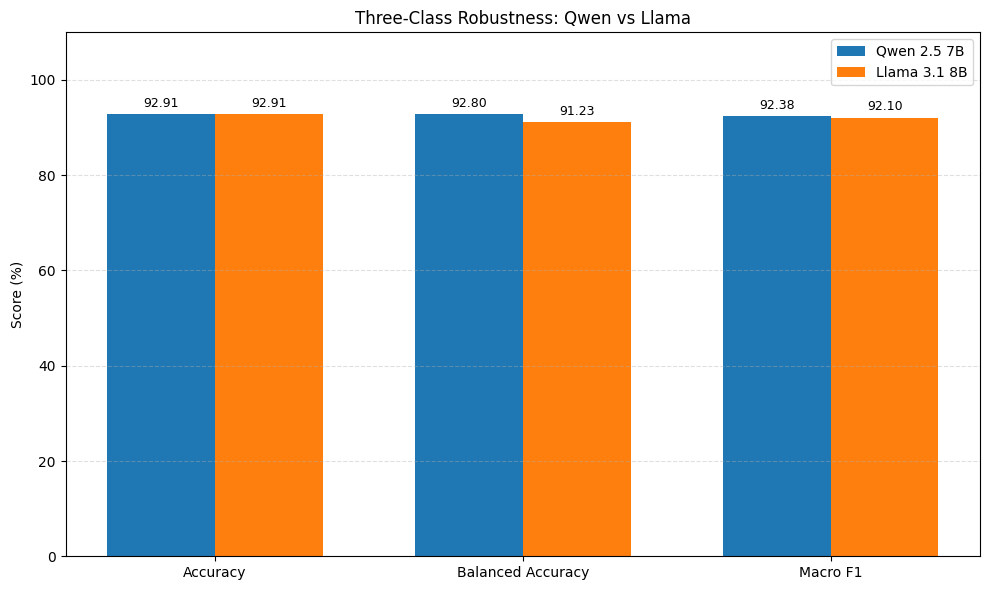

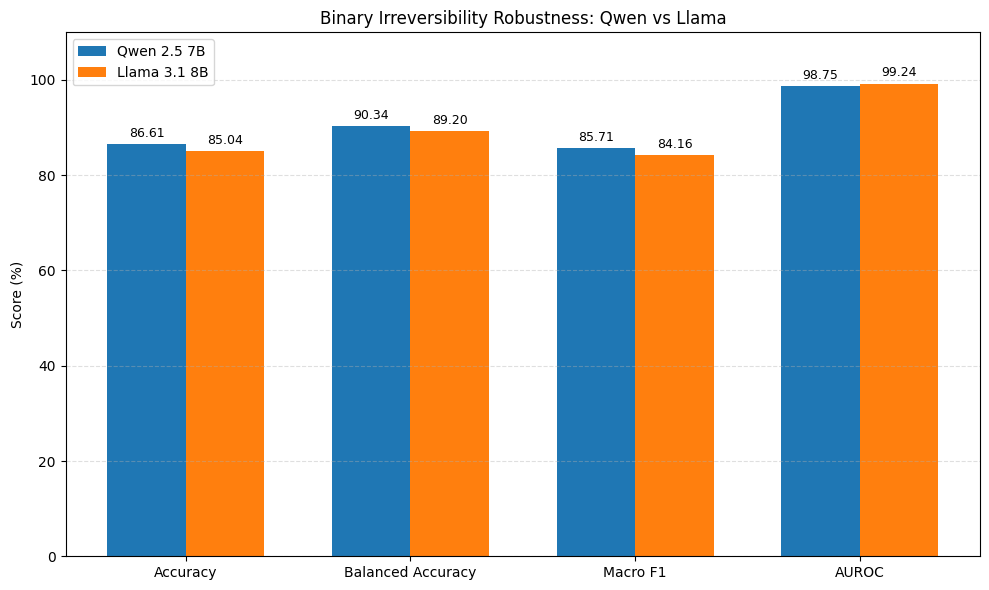


Comparison plots saved in: /kaggle/working/COMPARISON
PNG and PDF versions created for both plots.


In [193]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON")

with open(folder / "ADNN_RQ1_robustness_model_comparison.json") as f:
    data = json.load(f)

# Extract three-class metrics
three_class = {
    "Accuracy": [
        data["qwen_3class"]["test_metrics"]["accuracy"],
        data["llama_3class"]["evaluation"]["accuracy"]
    ],
    "Balanced Accuracy": [
        data["qwen_3class"]["test_metrics"]["balanced_accuracy"],
        data["llama_3class"]["evaluation"]["balanced_accuracy"]
    ],
    "Macro F1": [
        data["qwen_3class"]["test_metrics"]["macro_f1"],
        data["llama_3class"]["evaluation"]["macro_f1"]
    ]
}

# Extract binary metrics
binary = {
    "Accuracy": [
        data["qwen_binary"]["test_metrics"]["accuracy"],
        data["llama_binary"]["test_accuracy"]
    ],
    "Balanced Accuracy": [
        data["qwen_binary"]["test_metrics"]["balanced_accuracy"],
        data["llama_binary"]["test_balanced_accuracy"]
    ],
    "Macro F1": [
        data["qwen_binary"]["test_metrics"]["macro_f1"],
        data["llama_binary"]["test_macro_f1"]
    ],
    "AUROC": [
        data["qwen_binary"]["test_metrics"]["auroc"],
        data["llama_binary"]["test_auroc"]
    ]
}

def create_comparison_plot(metrics, title, filename):
    names = list(metrics.keys())
    qwen_values = [metrics[name][0] * 100 for name in names]
    llama_values = [metrics[name][1] * 100 for name in names]

    x = np.arange(len(names))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))

    bars1 = ax.bar(x - width/2, qwen_values, width, label="Qwen 2.5 7B")
    bars2 = ax.bar(x + width/2, llama_values, width, label="Llama 3.1 8B")

    ax.set_ylabel("Score (%)")
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    ax.bar_label(bars1, fmt="%.2f", padding=3, fontsize=9)
    ax.bar_label(bars2, fmt="%.2f", padding=3, fontsize=9)

    plt.tight_layout()
    fig.savefig(folder / f"{filename}.png", dpi=300, bbox_inches="tight")
    fig.savefig(folder / f"{filename}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

create_comparison_plot(
    three_class,
    "Three-Class Robustness: Qwen vs Llama",
    "three_class_robustness_comparison"
)

create_comparison_plot(
    binary,
    "Binary Irreversibility Robustness: Qwen vs Llama",
    "binary_robustness_comparison"
)

print("\nComparison plots saved in:", folder)
print("PNG and PDF versions created for both plots.")

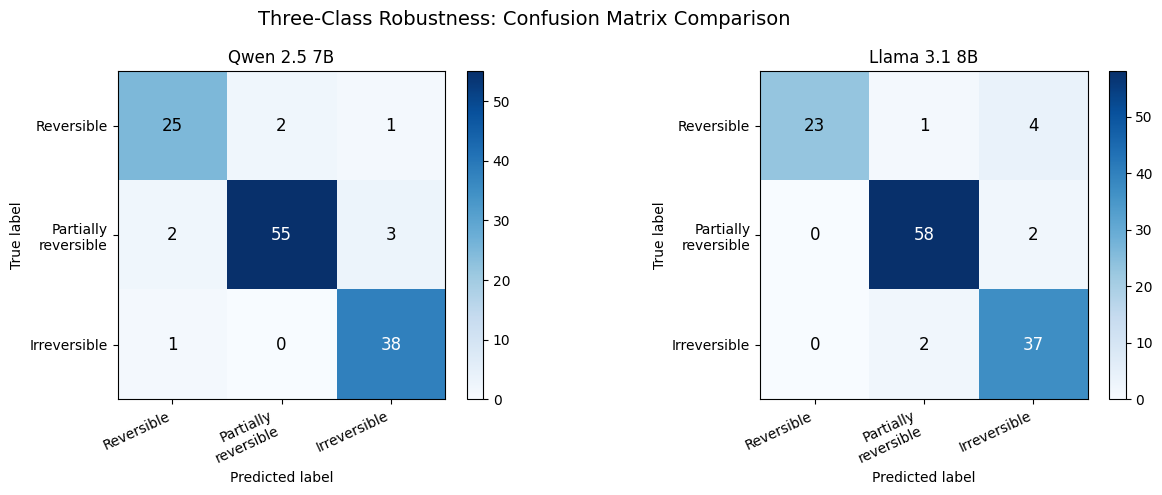

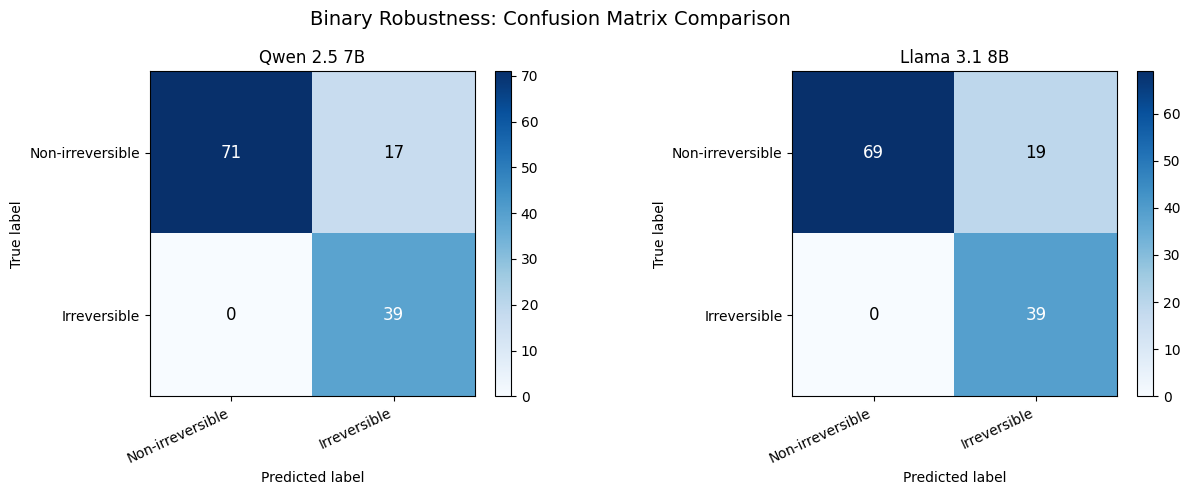


Both confusion matrix comparisons saved.
Location: /kaggle/working/COMPARISON


In [194]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON")
folder.mkdir(exist_ok=True)

with open(folder / "ADNN_RQ1_robustness_model_comparison.json") as f:
    data = json.load(f)

def plot_confusion_comparison(
    qwen_cm, llama_cm, class_names, title, filename
):
    matrices = [np.array(qwen_cm), np.array(llama_cm)]
    model_names = ["Qwen 2.5 7B", "Llama 3.1 8B"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for ax, cm, model_name in zip(axes, matrices, model_names):
        im = ax.imshow(cm, interpolation="nearest", cmap="Blues")

        ax.set_title(model_name)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")

        ax.set_xticks(np.arange(len(class_names)))
        ax.set_yticks(np.arange(len(class_names)))
        ax.set_xticklabels(class_names, rotation=25, ha="right")
        ax.set_yticklabels(class_names)

        threshold = cm.max() / 2

        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center",
                    color="white" if cm[i, j] > threshold else "black",
                    fontsize=12
                )

        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()

    fig.savefig(folder / f"{filename}.png", dpi=300, bbox_inches="tight")
    fig.savefig(folder / f"{filename}.pdf", bbox_inches="tight")

    plt.show()
    plt.close(fig)

# Three-class confusion matrices
plot_confusion_comparison(
    data["qwen_3class"]["confusion_matrix"],
    data["llama_3class"]["evaluation"]["confusion_matrix"],
    ["Reversible", "Partially\nreversible", "Irreversible"],
    "Three-Class Robustness: Confusion Matrix Comparison",
    "three_class_confusion_comparison"
)

# Binary confusion matrices
plot_confusion_comparison(
    data["qwen_binary"]["confusion_matrix"],
    data["llama_binary"]["confusion_matrix"],
    ["Non-irreversible", "Irreversible"],
    "Binary Robustness: Confusion Matrix Comparison",
    "binary_confusion_comparison"
)

print("\nBoth confusion matrix comparisons saved.")
print("Location:", folder)

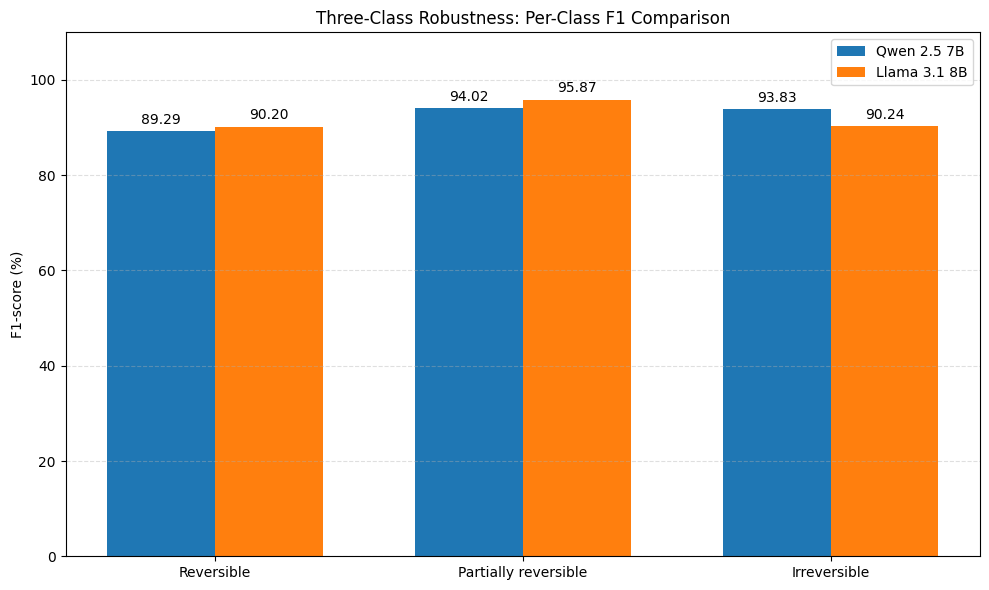

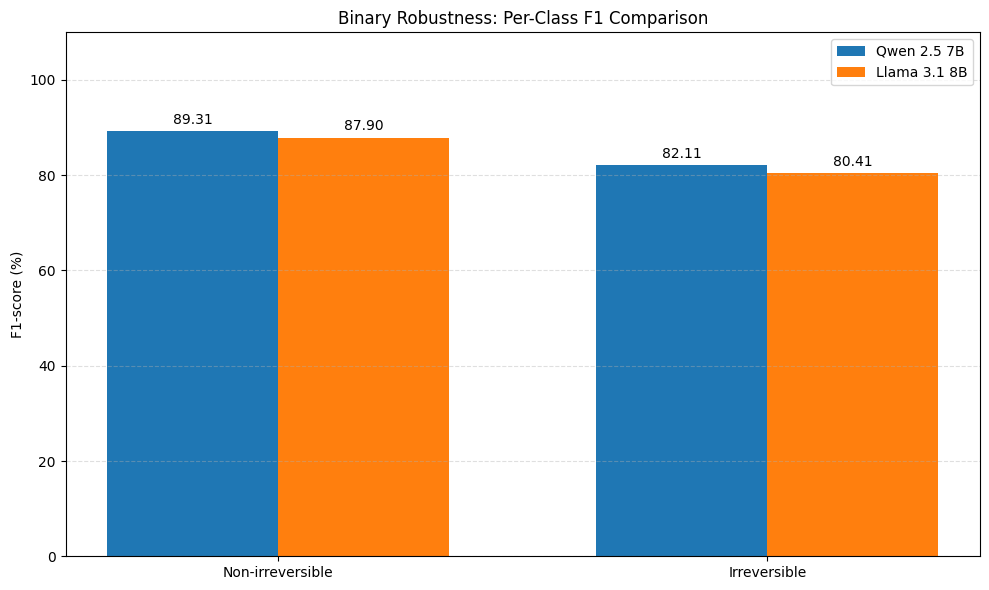


Both per-class F1 comparison plots saved.
Location: /kaggle/working/COMPARISON


In [195]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON")

with open(folder / "ADNN_RQ1_robustness_model_comparison.json") as f:
    data = json.load(f)

def plot_f1_comparison(qwen_scores, llama_scores, classes, title, filename):
    x = np.arange(len(classes))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))

    qwen_values = np.array(qwen_scores) * 100
    llama_values = np.array(llama_scores) * 100

    bars1 = ax.bar(x - width/2, qwen_values, width, label="Qwen 2.5 7B")
    bars2 = ax.bar(x + width/2, llama_values, width, label="Llama 3.1 8B")

    ax.set_title(title)
    ax.set_ylabel("F1-score (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(classes)
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    ax.bar_label(bars1, fmt="%.2f", padding=3)
    ax.bar_label(bars2, fmt="%.2f", padding=3)

    plt.tight_layout()
    fig.savefig(folder / f"{filename}.png", dpi=300, bbox_inches="tight")
    fig.savefig(folder / f"{filename}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Three-class per-class F1
classes_3 = ["Reversible", "Partially reversible", "Irreversible"]

qwen_3 = [
    data["qwen_3class"]["per_class"][key]["f1-score"]
    for key in ["reversible", "partially_reversible", "irreversible"]
]

llama_3 = [
    data["llama_3class"]["evaluation"]["confusion_matrix"][0][0],
    data["llama_3class"]["evaluation"]["confusion_matrix"][1][1],
    data["llama_3class"]["evaluation"]["confusion_matrix"][2][2]
]

# Calculate Llama per-class F1 from its confusion matrix and class supports
cm = np.array(data["llama_3class"]["evaluation"]["confusion_matrix"])
supports = np.array([28, 60, 39])
predicted_counts = cm.sum(axis=0)

llama_3 = [
    (2 * cm[i, i]) / (supports[i] + predicted_counts[i])
    for i in range(3)
]

plot_f1_comparison(
    qwen_3,
    llama_3,
    classes_3,
    "Three-Class Robustness: Per-Class F1 Comparison",
    "three_class_per_class_f1_comparison"
)

# Binary per-class F1
classes_2 = ["Non-irreversible", "Irreversible"]

qwen_2 = [
    data["qwen_binary"]["per_class"][key]["f1-score"]
    for key in ["non_irreversible", "irreversible"]
]

llama_2 = [
    data["llama_binary"]["classification_report"][key]["f1-score"]
    for key in ["non_irreversible", "irreversible"]
]

plot_f1_comparison(
    qwen_2,
    llama_2,
    classes_2,
    "Binary Robustness: Per-Class F1 Comparison",
    "binary_per_class_f1_comparison"
)

print("\nBoth per-class F1 comparison plots saved.")
print("Location:", folder)

In [196]:
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2")
}

for name, folder in folders.items():
    print(f"\n{'='*55}")
    print(f"{name} EXISTING PLOTS AND ANALYSIS")
    print(f"{'='*55}")

    for subfolder in ["plots", "probes", "ablations", "baselines", "analysis"]:
        path = folder / subfolder
        print(f"\n--- {subfolder.upper()} ---")

        if path.exists():
            for file in sorted(path.iterdir()):
                if file.is_file():
                    print(file.name)
        else:
            print("Folder not found")


Qwen EXISTING PLOTS AND ANALYSIS

--- PLOTS ---
Folder not found

--- PROBES ---
best_layers.json
manifest.json
metrics.json
probe_split.json
qwen_v2_3class_layer_screening.json
qwen_v2_3class_robustness_predictions.jsonl
qwen_v2_3class_robustness_subset.json
qwen_v2_3class_test_predictions.jsonl
qwen_v2_binary_bootstrap_ci.json
qwen_v2_binary_c_selection.json
qwen_v2_binary_layer_screening.json
qwen_v2_binary_predictions.jsonl
qwen_v2_binary_robustness_predictions.jsonl
qwen_v2_binary_robustness_subset.json
qwen_v2_final_3class_results.json
qwen_v2_final_binary_results.json

--- ABLATIONS ---
qwen_v2_binary_horizon_ablations.json
qwen_v2_binary_mean_action_tokens_layer18.json

--- BASELINES ---
qwen_v2_binary_bow_action_text.json
qwen_v2_binary_bow_state_action.json
qwen_v2_binary_layer0_embedding_baseline.json
qwen_v2_binary_majority_baseline.json
qwen_v2_binary_random_action_verb_control.json
qwen_v2_binary_shuffled_label_control.json

--- ANALYSIS ---
qwen_v2_binary_environment_br

In [197]:
import json
from pathlib import Path

llama_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/plots/"
    "llama_v2_per_layer_norm.json"
)

with open(llama_path) as f:
    llama_norm = json.load(f)

print("Llama norm JSON structure:")
print(json.dumps(llama_norm, indent=2)[:4000])

print("\nQwen hidden-state files:")
qwen_hidden = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/hidden_states")

for file in sorted(qwen_hidden.iterdir()):
    if file.is_file():
        print(file.name, f"({file.stat().st_size / (1024**2):.2f} MB)")

Llama norm JSON structure:
{
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "representation": "last_action_token",
  "records": 2134,
  "num_layers_including_embedding": 33,
  "mean_l2_norm_by_layer": [
    0.6789466142654419,
    1.2869443893432617,
    1.554197907447815,
    2.077211856842041,
    2.8591668605804443,
    3.340958595275879,
    4.041520118713379,
    4.379724502563477,
    5.277488708496094,
    5.605216026306152,
    6.255155563354492,
    6.560047626495361,
    6.6694512367248535,
    8.030375480651855,
    8.59476375579834,
    8.623218536376953,
    9.315454483032227,
    10.80871295928955,
    11.858792304992676,
    12.885247230529785,
    13.508993148803711,
    14.2489013671875,
    15.359118461608887,
    17.041105270385742,
    18.37870216369629,
    20.473670959472656,
    22.629226684570312,
    24.915531158447266,
    28.75750160217285,
    31.764915466308594,
    36.0445556640625,
    44.38227462768555,
    145.0287628173828
  ]
}

Qwen hidden-state fi

Hidden-state shape: (2134, 29, 3584)


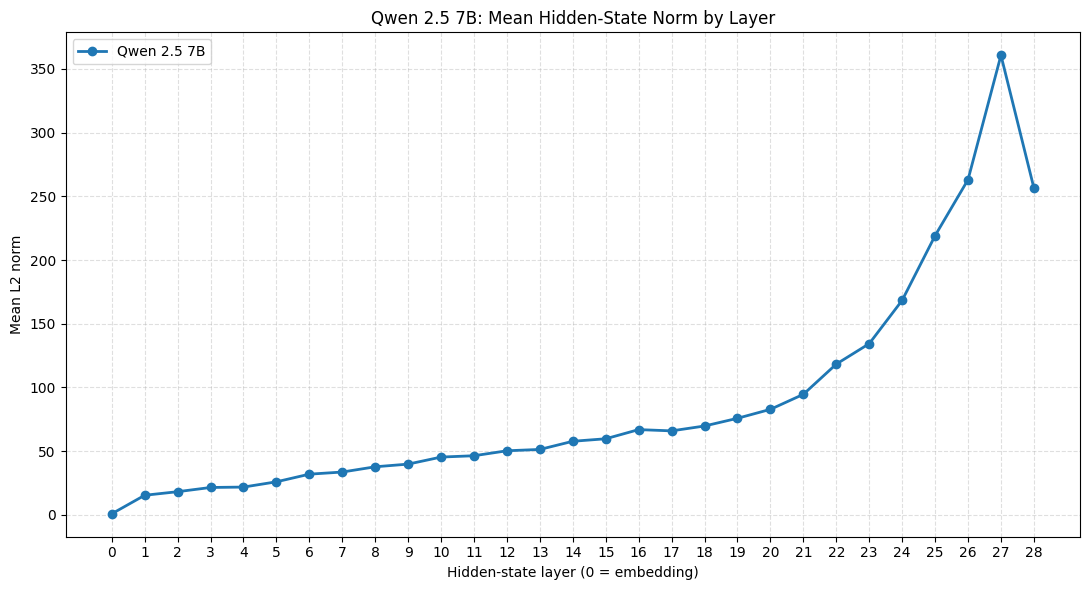


Qwen norm analysis completed.
Records: 2134
Layers: 29
Saved JSON: /kaggle/working/ADNN_RQ1_Qwen_v2/plots/qwen_v2_per_layer_norm.json
Saved PNG and PDF in: /kaggle/working/ADNN_RQ1_Qwen_v2/plots


In [198]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
hidden_path = base / "hidden_states/last_action_token.npy"

# Load hidden states
X = np.load(hidden_path, mmap_mode="r")

print("Hidden-state shape:", X.shape)

# Calculate L2 norm for each record and layer
layer_norms = []

for layer in range(X.shape[1]):
    norms = np.linalg.norm(
        np.asarray(X[:, layer, :], dtype=np.float32),
        axis=1
    )
    layer_norms.append(float(np.mean(norms)))

# Save norm results
norm_results = {
    "model": "Qwen/Qwen2.5-7B-Instruct",
    "representation": "last_action_token",
    "records": int(X.shape[0]),
    "num_layers_including_embedding": int(X.shape[1]),
    "mean_l2_norm_by_layer": layer_norms
}

plots_dir = base / "plots"
plots_dir.mkdir(exist_ok=True)

json_path = plots_dir / "qwen_v2_per_layer_norm.json"

with open(json_path, "w") as f:
    json.dump(norm_results, f, indent=2)

# Plot
plt.figure(figsize=(11, 6))

plt.plot(
    range(len(layer_norms)),
    layer_norms,
    marker="o",
    linewidth=2,
    label="Qwen 2.5 7B"
)

plt.xlabel("Hidden-state layer (0 = embedding)")
plt.ylabel("Mean L2 norm")
plt.title("Qwen 2.5 7B: Mean Hidden-State Norm by Layer")
plt.xticks(range(len(layer_norms)))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig(plots_dir / "qwen_v2_per_layer_norm.png", dpi=300)
plt.savefig(plots_dir / "qwen_v2_per_layer_norm.pdf")

plt.show()
plt.close()

print("\nQwen norm analysis completed.")
print("Records:", X.shape[0])
print("Layers:", X.shape[1])
print("Saved JSON:", json_path)
print("Saved PNG and PDF in:", plots_dir)

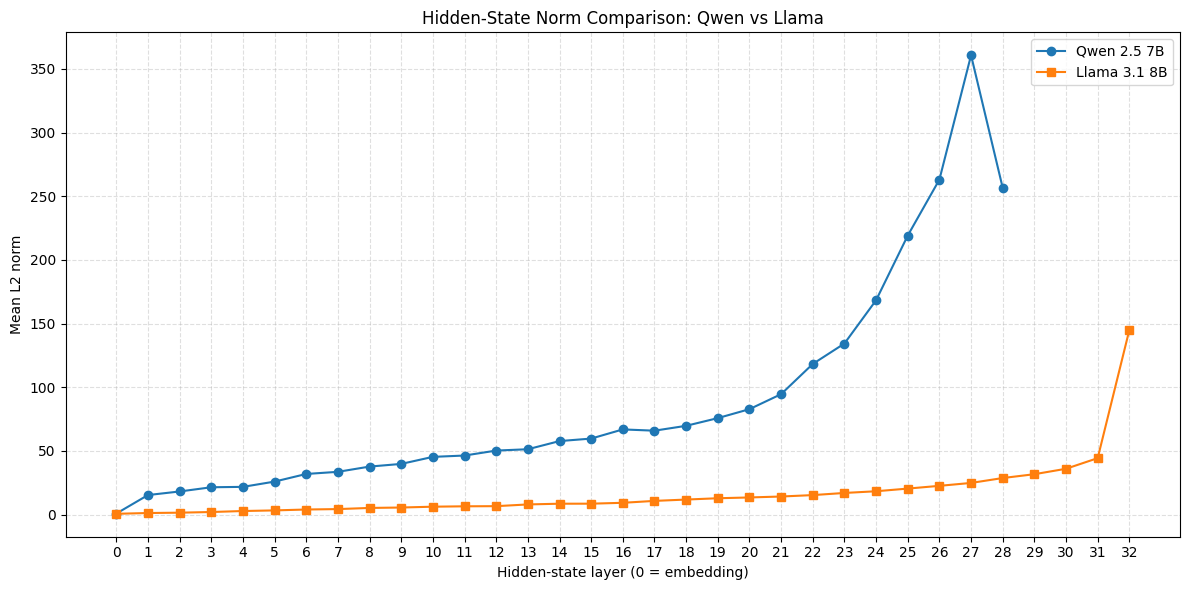

Combined norm comparison saved.
Qwen layers: 29
Llama layers: 33


In [199]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/plots")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/plots")
comparison_dir = Path("/kaggle/working/COMPARISON")

with open(qwen_dir / "qwen_v2_per_layer_norm.json") as f:
    qwen = json.load(f)

with open(llama_dir / "llama_v2_per_layer_norm.json") as f:
    llama = json.load(f)

qwen_norms = qwen["mean_l2_norm_by_layer"]
llama_norms = llama["mean_l2_norm_by_layer"]

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(qwen_norms)),
    qwen_norms,
    marker="o",
    label="Qwen 2.5 7B"
)

plt.plot(
    range(len(llama_norms)),
    llama_norms,
    marker="s",
    label="Llama 3.1 8B"
)

plt.xlabel("Hidden-state layer (0 = embedding)")
plt.ylabel("Mean L2 norm")
plt.title("Hidden-State Norm Comparison: Qwen vs Llama")
plt.xticks(range(max(len(qwen_norms), len(llama_norms))))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig(
    comparison_dir / "qwen_vs_llama_hidden_state_norm.png",
    dpi=300
)
plt.savefig(
    comparison_dir / "qwen_vs_llama_hidden_state_norm.pdf"
)

plt.show()
plt.close()

print("Combined norm comparison saved.")
print("Qwen layers:", len(qwen_norms))
print("Llama layers:", len(llama_norms))

In [200]:
import json
from pathlib import Path

files = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_3class_layer_screening.json"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_layer_screening.json")
}

for name, path in files.items():
    with open(path) as f:
        data = json.load(f)

    print(f"\n--- {name} three-class screening ---")
    print(json.dumps(data, indent=2)[:2500])


--- Qwen three-class screening ---
[
  {
    "layer": 0,
    "C": 0.001,
    "cv_balanced_accuracy": 0.3333333333333333,
    "cv_std": 0.0,
    "fold_scores": [
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333
    ],
    "time_sec": 8.96042537689209
  },
  {
    "layer": 1,
    "C": 0.001,
    "cv_balanced_accuracy": 0.6157868264008111,
    "cv_std": 0.03759578860464379,
    "fold_scores": [
      0.5594274598827119,
      0.5852490421455939,
      0.628106495994427,
      0.6566538021726701,
      0.6494973318086527
    ],
    "time_sec": 22.566354274749756
  },
  {
    "layer": 2,
    "C": 0.001,
    "cv_balanced_accuracy": 0.6150042873929817,
    "cv_std": 0.03438578756982497,
    "fold_scores": [
      0.5649566955363091,
      0.5913793103448276,
      0.6178182688958551,
      0.6375762340384982,
      0.6632909281494187
    ],
    "time_sec": 32.194905042648315
  },
  {
    "layer": 3,
    "C": 0.00

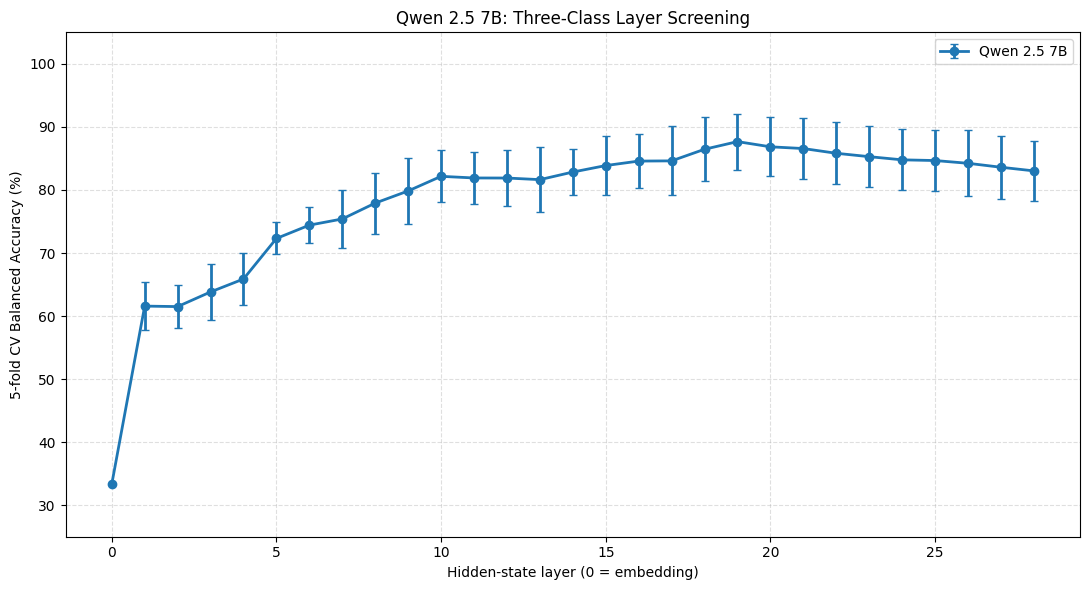

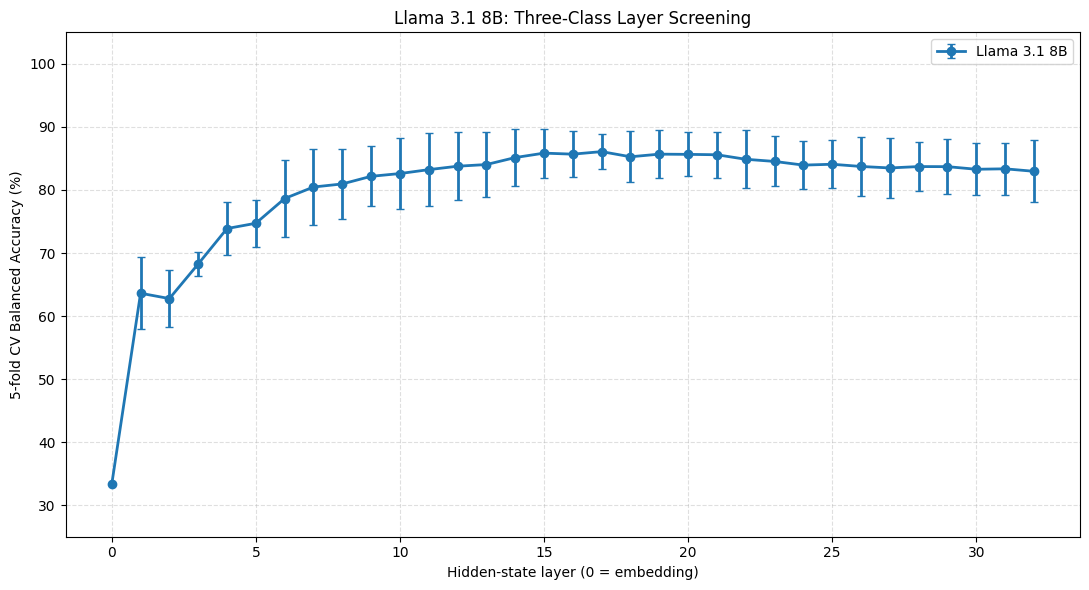

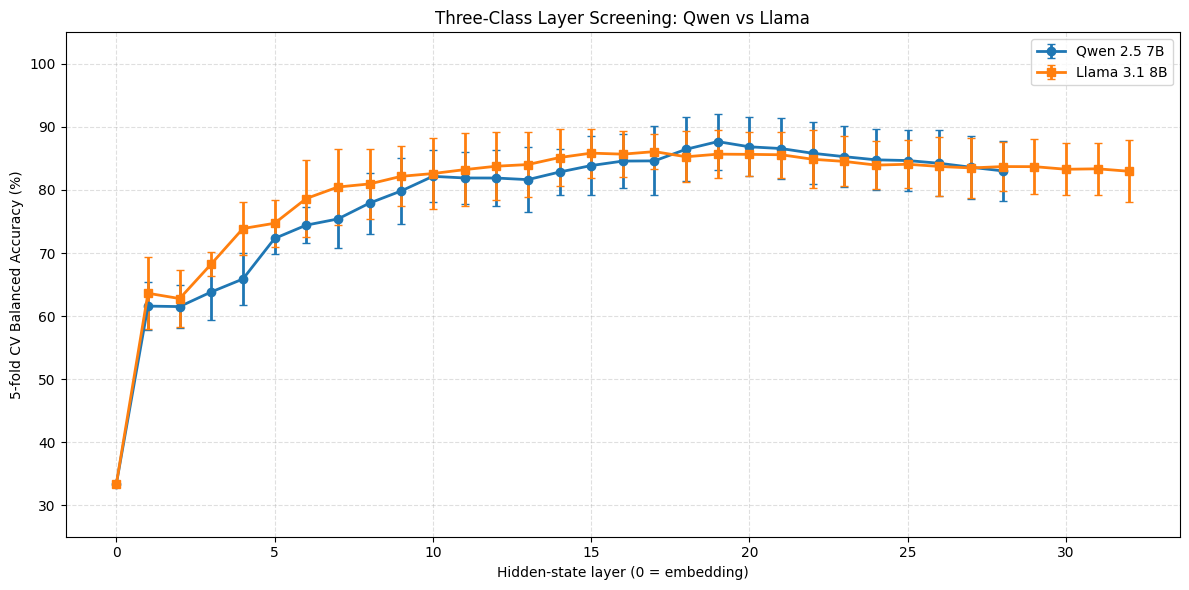

Three-class layer screening plots saved.
Qwen layers: 29
Llama layers: 33
Qwen best screening layer: 19
Llama best screening layer: 17


In [201]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
comparison_dir = Path("/kaggle/working/COMPARISON")

def load_screening(path):
    with open(path) as f:
        results = json.load(f)

    results = sorted(results, key=lambda x: x["layer"])

    layers = [r["layer"] for r in results]
    scores = [r["cv_balanced_accuracy"] * 100 for r in results]
    stds = [r["cv_std"] * 100 for r in results]

    return layers, scores, stds

q_layers, q_scores, q_stds = load_screening(
    qwen_dir / "probes/qwen_v2_3class_layer_screening.json"
)

l_layers, l_scores, l_stds = load_screening(
    llama_dir / "probes/llama_v2_3class_layer_screening.json"
)

def save_plot(layers, scores, stds, title, filename, label):
    fig, ax = plt.subplots(figsize=(11, 6))

    ax.errorbar(
        layers, scores, yerr=stds,
        marker="o", capsize=3,
        linewidth=2, label=label
    )

    ax.set_xlabel("Hidden-state layer (0 = embedding)")
    ax.set_ylabel("5-fold CV Balanced Accuracy (%)")
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()
    ax.set_ylim(25, 105)

    plt.tight_layout()
    fig.savefig(comparison_dir / f"{filename}.png", dpi=300)
    fig.savefig(comparison_dir / f"{filename}.pdf")
    plt.show()
    plt.close(fig)

# Individual Qwen plot
save_plot(
    q_layers, q_scores, q_stds,
    "Qwen 2.5 7B: Three-Class Layer Screening",
    "qwen_3class_layer_screening",
    "Qwen 2.5 7B"
)

# Individual Llama plot
save_plot(
    l_layers, l_scores, l_stds,
    "Llama 3.1 8B: Three-Class Layer Screening",
    "llama_3class_layer_screening",
    "Llama 3.1 8B"
)

# Combined comparison
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    q_layers, q_scores, yerr=q_stds,
    marker="o", capsize=3, linewidth=2,
    label="Qwen 2.5 7B"
)

ax.errorbar(
    l_layers, l_scores, yerr=l_stds,
    marker="s", capsize=3, linewidth=2,
    label="Llama 3.1 8B"
)

ax.set_xlabel("Hidden-state layer (0 = embedding)")
ax.set_ylabel("5-fold CV Balanced Accuracy (%)")
ax.set_title("Three-Class Layer Screening: Qwen vs Llama")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
ax.set_ylim(25, 105)

plt.tight_layout()
fig.savefig(
    comparison_dir / "qwen_vs_llama_3class_layer_screening.png",
    dpi=300
)
fig.savefig(
    comparison_dir / "qwen_vs_llama_3class_layer_screening.pdf"
)

plt.show()
plt.close(fig)

print("Three-class layer screening plots saved.")
print("Qwen layers:", len(q_layers))
print("Llama layers:", len(l_layers))
print("Qwen best screening layer:", q_layers[np.argmax(q_scores)])
print("Llama best screening layer:", l_layers[np.argmax(l_scores)])

In [202]:
import shutil
from pathlib import Path

qwen_plots = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/plots")
llama_plots = Path("/kaggle/working/ADNN_RQ1_Llama_v2/plots")
comparison = Path("/kaggle/working/COMPARISON")

for ext in ["png", "pdf"]:
    shutil.copy2(
        comparison / f"qwen_3class_layer_screening.{ext}",
        qwen_plots / f"qwen_v2_3class_layer_screening.{ext}"
    )

    shutil.copy2(
        comparison / f"llama_3class_layer_screening.{ext}",
        llama_plots / f"llama_v2_3class_layer_screening.{ext}"
    )

print("Individual plots copied successfully.")

print("\nQwen plots:")
for f in sorted(qwen_plots.iterdir()):
    print(f.name)

print("\nLlama plots:")
for f in sorted(llama_plots.iterdir()):
    print(f.name)

Individual plots copied successfully.

Qwen plots:
qwen_v2_3class_layer_screening.pdf
qwen_v2_3class_layer_screening.png
qwen_v2_per_layer_norm.json
qwen_v2_per_layer_norm.pdf
qwen_v2_per_layer_norm.png

Llama plots:
llama_v2_3class_confusion_matrix.pdf
llama_v2_3class_confusion_matrix.png
llama_v2_3class_layer_screening.pdf
llama_v2_3class_layer_screening.png
llama_v2_binary_confusion_matrix.pdf
llama_v2_binary_confusion_matrix.png
llama_v2_binary_layer_screening.pdf
llama_v2_binary_layer_screening.png
llama_v2_per_layer_norm.json
llama_v2_per_layer_norm.pdf
llama_v2_per_layer_norm.png


In [203]:
import json
from pathlib import Path

files = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_binary_layer_screening.json"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_layer_screening.json")
}

for name, path in files.items():
    with open(path) as f:
        data = json.load(f)

    print(f"\n--- {name} binary screening ---")
    print("Type:", type(data).__name__)

    if isinstance(data, dict):
        print("Keys:", list(data.keys()))
        print(json.dumps(data, indent=2)[:1200])
    else:
        print("Number of layer results:", len(data))
        print(json.dumps(data[:2], indent=2))


--- Qwen binary screening ---
Type: dict
Keys: ['task', 'representation', 'C', 'n_splits', 'selection_method', 'test_used', 'results', 'ranking']
{
  "task": "binary",
  "representation": "last_action_token",
  "C": 0.001,
  "n_splits": 5,
  "selection_method": "GroupKFold_by_scenario",
  "test_used": false,
  "results": [
    {
      "layer": 0,
      "C": 0.001,
      "cv_balanced_accuracy": 0.5,
      "cv_std": 0.0,
      "fold_scores": [
        0.5,
        0.5,
        0.5,
        0.5,
        0.5
      ],
      "time_sec": 9.233778476715088
    },
    {
      "layer": 1,
      "C": 0.001,
      "cv_balanced_accuracy": 0.7051899959054688,
      "cv_std": 0.0757516352444472,
      "fold_scores": [
        0.7058270676691729,
        0.5828160919540231,
        0.7789855072463768,
        0.7888297872340425,
        0.6694915254237288
      ],
      "time_sec": 16.677218437194824
    },
    {
      "layer": 2,
      "C": 0.001,
      "cv_balanced_accuracy": 0.7125831309648788,
  

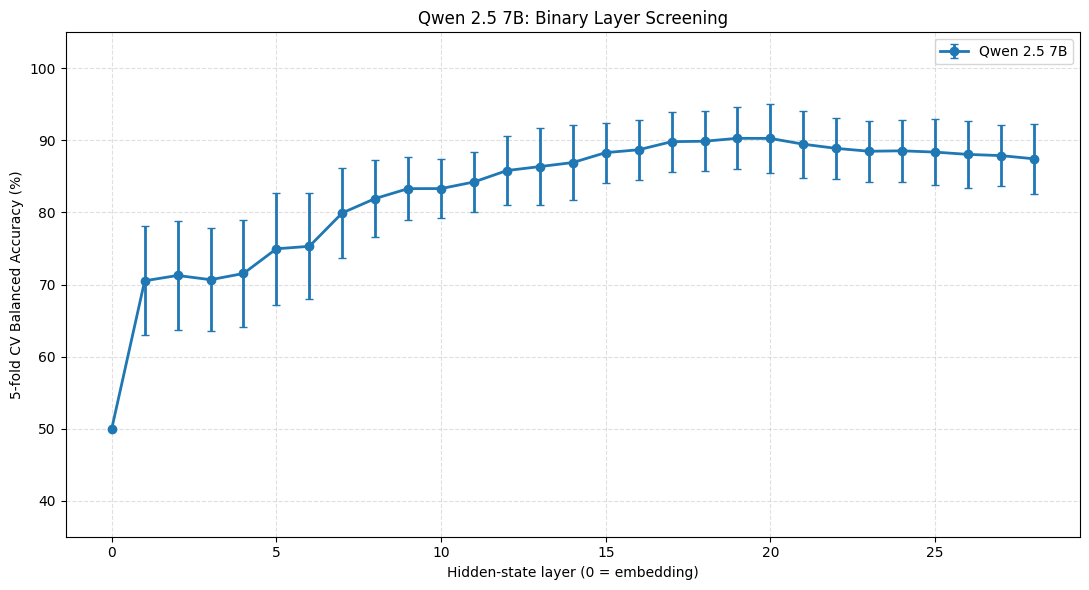

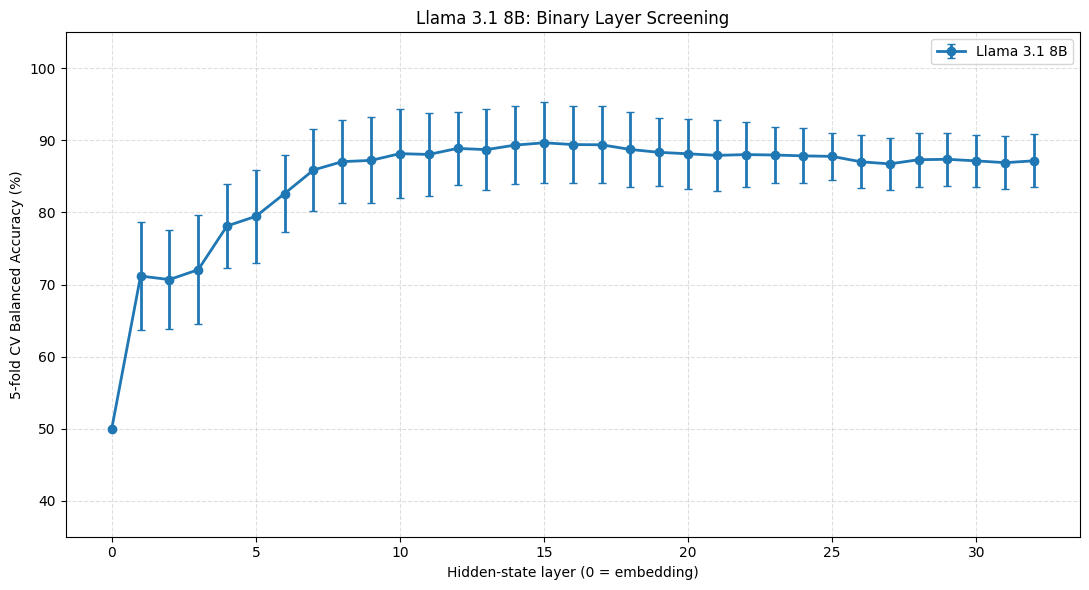

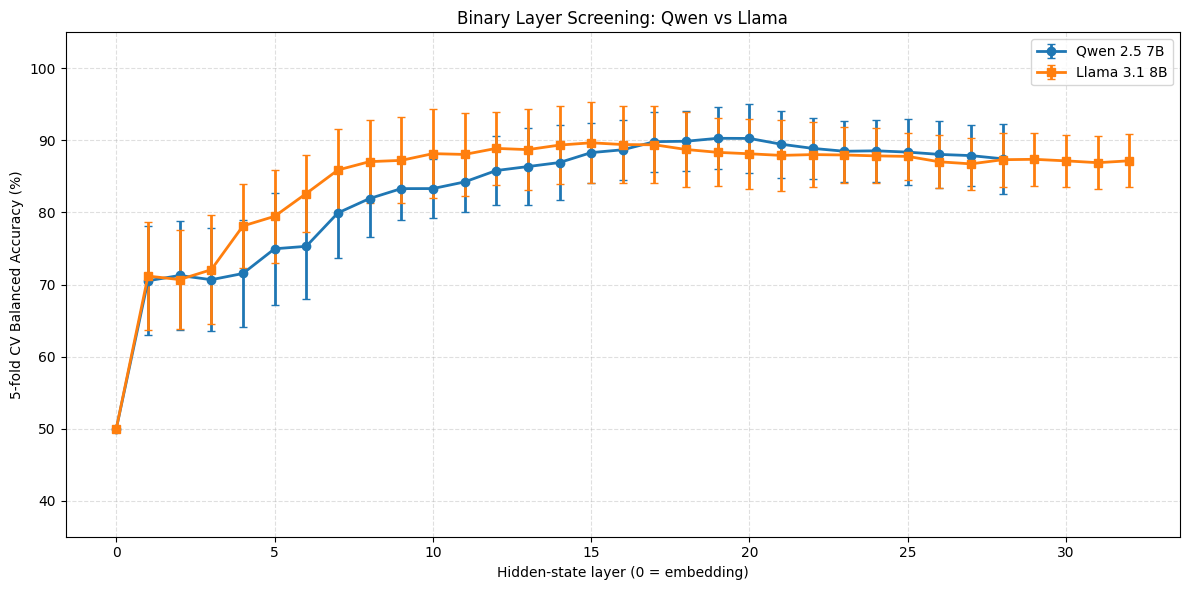


Binary layer screening plots saved.
Qwen screening layers: 29
Llama screening layers: 33
Qwen best screening layer: 19
Llama best screening layer: 15


In [204]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
comparison_dir = Path("/kaggle/working/COMPARISON")

qwen_plots = qwen_dir / "plots"
llama_plots = llama_dir / "plots"

def load_binary_screening(path):
    with open(path) as f:
        data = json.load(f)

    results = sorted(data["results"], key=lambda x: x["layer"])

    layers = [r["layer"] for r in results]
    scores = [r["cv_balanced_accuracy"] * 100 for r in results]
    stds = [r["cv_std"] * 100 for r in results]

    return layers, scores, stds

q_layers, q_scores, q_stds = load_binary_screening(
    qwen_dir / "probes/qwen_v2_binary_layer_screening.json"
)

l_layers, l_scores, l_stds = load_binary_screening(
    llama_dir / "probes/llama_v2_binary_layer_screening.json"
)

def plot_individual(layers, scores, stds, model, folder, filename):
    fig, ax = plt.subplots(figsize=(11, 6))

    ax.errorbar(
        layers, scores, yerr=stds,
        marker="o", capsize=3, linewidth=2,
        label=model
    )

    ax.set_xlabel("Hidden-state layer (0 = embedding)")
    ax.set_ylabel("5-fold CV Balanced Accuracy (%)")
    ax.set_title(f"{model}: Binary Layer Screening")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()
    ax.set_ylim(35, 105)

    plt.tight_layout()
    fig.savefig(folder / f"{filename}.png", dpi=300)
    fig.savefig(folder / f"{filename}.pdf")
    plt.show()
    plt.close(fig)

# Qwen individual plot
plot_individual(
    q_layers, q_scores, q_stds,
    "Qwen 2.5 7B", qwen_plots,
    "qwen_v2_binary_layer_screening"
)

# Llama individual plot
plot_individual(
    l_layers, l_scores, l_stds,
    "Llama 3.1 8B", llama_plots,
    "llama_v2_binary_layer_screening"
)

# Combined comparison
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    q_layers, q_scores, yerr=q_stds,
    marker="o", capsize=3, linewidth=2,
    label="Qwen 2.5 7B"
)

ax.errorbar(
    l_layers, l_scores, yerr=l_stds,
    marker="s", capsize=3, linewidth=2,
    label="Llama 3.1 8B"
)

ax.set_xlabel("Hidden-state layer (0 = embedding)")
ax.set_ylabel("5-fold CV Balanced Accuracy (%)")
ax.set_title("Binary Layer Screening: Qwen vs Llama")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
ax.set_ylim(35, 105)

plt.tight_layout()

fig.savefig(
    comparison_dir / "qwen_vs_llama_binary_layer_screening.png",
    dpi=300
)
fig.savefig(
    comparison_dir / "qwen_vs_llama_binary_layer_screening.pdf"
)

plt.show()
plt.close(fig)

print("\nBinary layer screening plots saved.")
print("Qwen screening layers:", len(q_layers))
print("Llama screening layers:", len(l_layers))
print("Qwen best screening layer:", q_layers[np.argmax(q_scores)])
print("Llama best screening layer:", l_layers[np.argmax(l_scores)])

In [205]:
import json
from pathlib import Path

files = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_binary_bootstrap_ci.json"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_bootstrap_ci.json")
}

for name, path in files.items():
    print(f"\n--- {name} bootstrap CI ---")

    with open(path) as f:
        data = json.load(f)

    print("Keys:", list(data.keys()))
    print(json.dumps(data, indent=2)[:2500])


--- Qwen bootstrap CI ---
Keys: ['experiment', 'bootstrap', 'test', 'metrics']
{
  "experiment": "qwen_v2_final_binary_probe",
  "bootstrap": {
    "method": "scenario_level_bootstrap",
    "n_resamples_requested": 1000,
    "n_resamples_successful": 1000,
    "n_resamples_skipped": 0,
    "confidence_level": 0.95,
    "interval_method": "percentile",
    "seed": 42,
    "resampling_unit": "scenario_id"
  },
  "test": {
    "n_records": 425,
    "n_scenarios": 25
  },
  "metrics": {
    "balanced_accuracy": {
      "estimate": 0.9117647058823529,
      "ci_95": [
        0.8110891089108911,
        1.0
      ]
    },
    "macro_f1": {
      "estimate": 0.8838162930563149,
      "ci_95": [
        0.7864901379626347,
        1.0
      ]
    },
    "auroc": {
      "estimate": 0.9864234909650134,
      "ci_95": [
        0.9424199731247787,
        1.0
      ]
    }
  }
}

--- Llama bootstrap CI ---
Keys: ['model', 'task', 'method', 'n_bootstraps', 'seed', 'successful_resamples', 'skipp

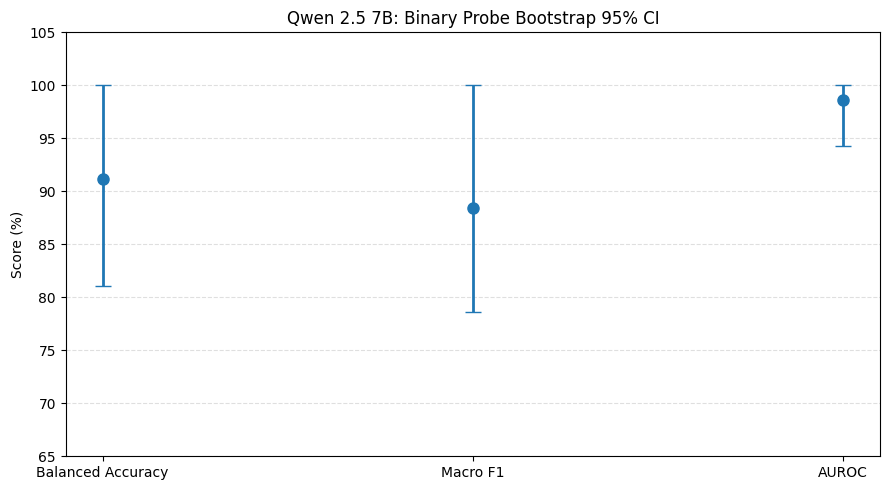

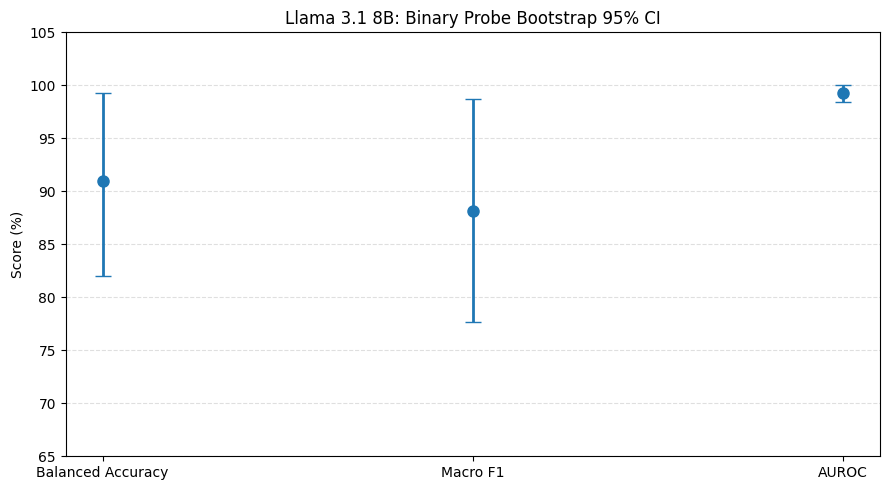

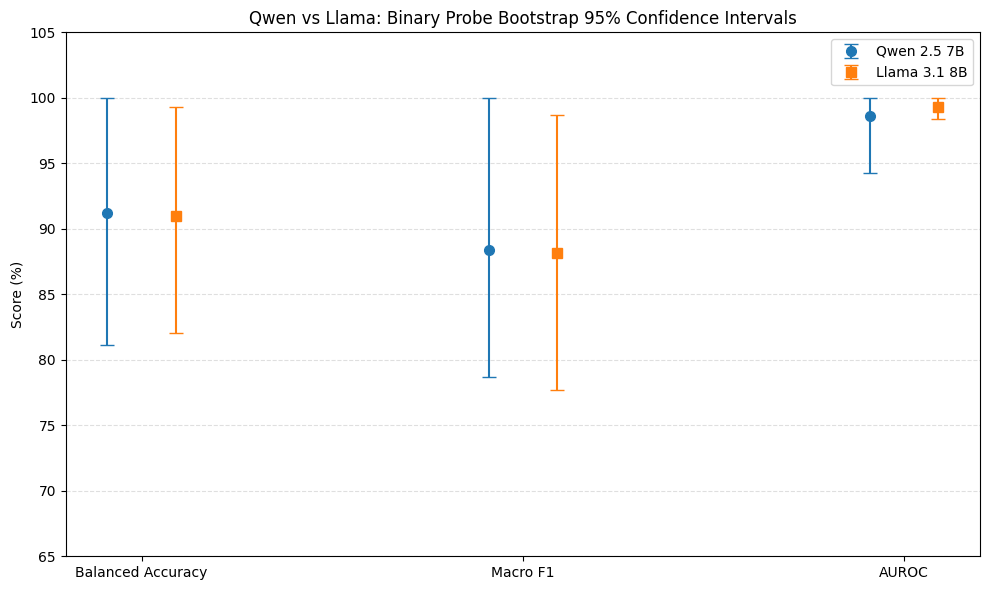

All bootstrap CI plots saved successfully.
Qwen resamples: 1000
Llama resamples: 1000


In [206]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
comparison_dir = Path("/kaggle/working/COMPARISON")

with open(qwen_dir / "probes/qwen_v2_binary_bootstrap_ci.json") as f:
    qwen = json.load(f)

with open(llama_dir / "probes/llama_v2_binary_bootstrap_ci.json") as f:
    llama = json.load(f)

metrics = ["balanced_accuracy", "macro_f1", "auroc"]
labels = ["Balanced Accuracy", "Macro F1", "AUROC"]

def extract(data):
    estimates = [data["metrics"][m]["estimate"] * 100 for m in metrics]
    lower = [data["metrics"][m]["ci_95"][0] * 100 for m in metrics]
    upper = [data["metrics"][m]["ci_95"][1] * 100 for m in metrics]
    return estimates, lower, upper

def plot_model(data, model_name, output_dir, filename):
    estimates, lower, upper = extract(data)

    x = np.arange(len(metrics))
    errors = [
        np.array(estimates) - np.array(lower),
        np.array(upper) - np.array(estimates)
    ]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.errorbar(
        x, estimates, yerr=errors,
        fmt="o", capsize=6, markersize=8,
        linewidth=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Score (%)")
    ax.set_title(f"{model_name}: Binary Probe Bootstrap 95% CI")
    ax.set_ylim(65, 105)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    fig.savefig(output_dir / f"{filename}.png", dpi=300)
    fig.savefig(output_dir / f"{filename}.pdf")
    plt.show()
    plt.close(fig)

# Individual plots
plot_model(
    qwen, "Qwen 2.5 7B", qwen_dir / "plots",
    "qwen_v2_binary_bootstrap_ci"
)

plot_model(
    llama, "Llama 3.1 8B", llama_dir / "plots",
    "llama_v2_binary_bootstrap_ci"
)

# Combined comparison
q_est, q_low, q_high = extract(qwen)
l_est, l_low, l_high = extract(llama)

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    x - width/2, q_est,
    yerr=[np.array(q_est)-q_low, np.array(q_high)-q_est],
    fmt="o", capsize=5, markersize=7,
    label="Qwen 2.5 7B"
)

ax.errorbar(
    x + width/2, l_est,
    yerr=[np.array(l_est)-l_low, np.array(l_high)-l_est],
    fmt="s", capsize=5, markersize=7,
    label="Llama 3.1 8B"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Score (%)")
ax.set_title("Qwen vs Llama: Binary Probe Bootstrap 95% Confidence Intervals")
ax.set_ylim(65, 105)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()
fig.savefig(comparison_dir / "binary_bootstrap_ci_comparison.png", dpi=300)
fig.savefig(comparison_dir / "binary_bootstrap_ci_comparison.pdf")
plt.show()
plt.close(fig)

print("All bootstrap CI plots saved successfully.")
print("Qwen resamples:", qwen["bootstrap"]["n_resamples_successful"])
print("Llama resamples:", llama["successful_resamples"])

In [207]:
import json
from pathlib import Path

files = {
    "Qwen 3-class": Path(
        "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_3class_test_predictions.jsonl"
    ),
    "Qwen binary": Path(
        "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_binary_predictions.jsonl"
    )
}

for name, path in files.items():
    print(f"\n--- {name} ---")

    with open(path) as f:
        lines = f.readlines()

    print("Number of predictions:", len(lines))

    if lines:
        print("First prediction:")
        print(json.dumps(json.loads(lines[0]), indent=2))


--- Qwen 3-class ---
Number of predictions: 425
First prediction:
{
  "test_row": 0,
  "dataset_row_index": 0,
  "record_id": "f01_delete_bin-0000-alt0-single-compact",
  "scenario_id": "grp-99121b548943",
  "true_label": "partially_reversible",
  "predicted_label": "partially_reversible",
  "prob_reversible": 3.2179011668631574e-06,
  "prob_partially_reversible": 0.9996594190597534,
  "prob_irreversible": 0.0003374146472197026
}

--- Qwen binary ---
Number of predictions: 425
First prediction:
{
  "record_id": "f01_delete_bin-0000-alt0-single-compact",
  "scenario_id": "grp-99121b548943",
  "true_label": 0,
  "true_label_name": "non_irreversible",
  "predicted_label": 0,
  "predicted_label_name": "non_irreversible",
  "probability_irreversible": 0.22626179879198674
}


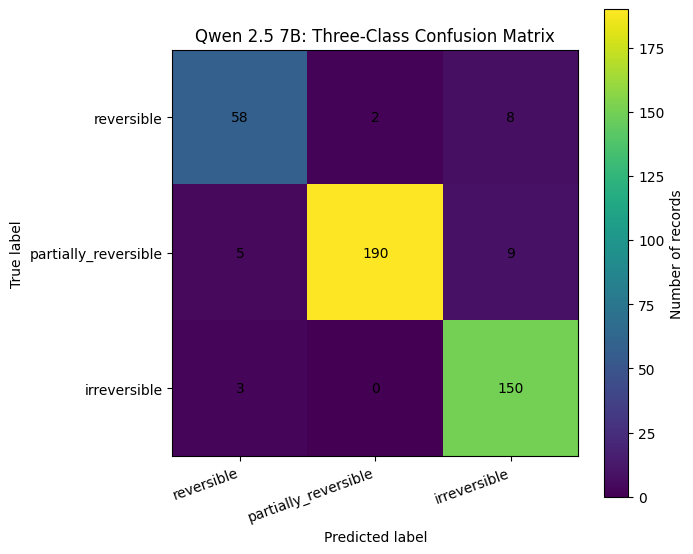


Qwen 2.5 7B: Three-Class Confusion Matrix
[[ 58   2   8]
 [  5 190   9]
 [  3   0 150]]


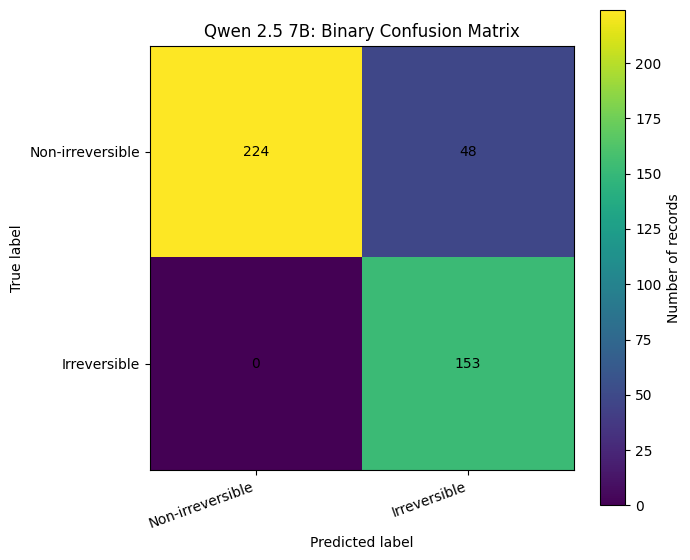


Qwen 2.5 7B: Binary Confusion Matrix
[[224  48]
 [  0 153]]

Both Qwen confusion matrices saved successfully.


In [208]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
plots_dir = qwen_dir / "plots"
probes_dir = qwen_dir / "probes"

def load_predictions(filename):
    with open(probes_dir / filename) as f:
        return [json.loads(line) for line in f]

def save_confusion_matrix(y_true, y_pred, labels, display_labels, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm)

    ax.set_xticks(range(len(display_labels)))
    ax.set_yticks(range(len(display_labels)))
    ax.set_xticklabels(display_labels, rotation=20, ha="right")
    ax.set_yticklabels(display_labels)

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)

    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.colorbar(im, ax=ax, label="Number of records")
    plt.tight_layout()

    fig.savefig(plots_dir / f"{filename}.png", dpi=300)
    fig.savefig(plots_dir / f"{filename}.pdf")

    plt.show()
    plt.close(fig)

    print(f"\n{title}")
    print(cm)

# 3-class confusion matrix
three_class = load_predictions("qwen_v2_3class_test_predictions.jsonl")

class_labels = [
    "reversible",
    "partially_reversible",
    "irreversible"
]

y_true_3 = [p["true_label"] for p in three_class]
y_pred_3 = [p["predicted_label"] for p in three_class]

save_confusion_matrix(
    y_true_3, y_pred_3,
    class_labels, class_labels,
    "Qwen 2.5 7B: Three-Class Confusion Matrix",
    "qwen_v2_3class_confusion_matrix"
)

# Binary confusion matrix
binary = load_predictions("qwen_v2_binary_predictions.jsonl")

binary_labels = [0, 1]
binary_display = ["Non-irreversible", "Irreversible"]

y_true_b = [p["true_label"] for p in binary]
y_pred_b = [p["predicted_label"] for p in binary]

save_confusion_matrix(
    y_true_b, y_pred_b,
    binary_labels, binary_display,
    "Qwen 2.5 7B: Binary Confusion Matrix",
    "qwen_v2_binary_confusion_matrix"
)

print("\nBoth Qwen confusion matrices saved successfully.")

In [209]:
import json
from pathlib import Path

files = {
    "Qwen 3-class": Path(
        "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_final_3class_results.json"
    ),
    "Llama 3-class": Path(
        "/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_final_test_results.json"
    ),
    "Qwen binary": Path(
        "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_final_binary_results.json"
    ),
    "Llama binary": Path(
        "/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_final_test_results.json"
    )
}

for name, path in files.items():
    print(f"\n--- {name} ---")

    with open(path) as f:
        data = json.load(f)

    print("Top-level keys:", list(data.keys()))
    print(json.dumps(data, indent=2)[:1800])


--- Qwen 3-class ---
Top-level keys: ['experiment', 'model', 'dataset_version', 'task', 'selected_layer', 'selected_C', 'inner_cv_balanced_accuracy', 'train_records', 'test_records', 'test_metrics', 'per_class', 'confusion_matrix', 'cv_selection_source', 'test_used_only_for_final_evaluation']
{
  "experiment": "ADNN_RQ1_Qwen_v2_final",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "dataset_version": "adnn-dataset-2.0",
  "task": "three_class",
  "selected_layer": 20,
  "selected_C": 0.1,
  "inner_cv_balanced_accuracy": 0.8928,
  "train_records": 1709,
  "test_records": 425,
  "test_metrics": {
    "balanced_accuracy": 0.9216,
    "macro_f1": 0.9209,
    "macro_auroc": 0.9951
  },
  "per_class": {
    "reversible": {
      "precision": 0.8788,
      "recall": 0.8529,
      "f1": 0.8657,
      "support": 68
    },
    "partially_reversible": {
      "precision": 0.9896,
      "recall": 0.9314,
      "f1": 0.9596,
      "support": 204
    },
    "irreversible": {
      "precision": 0.8982,
  

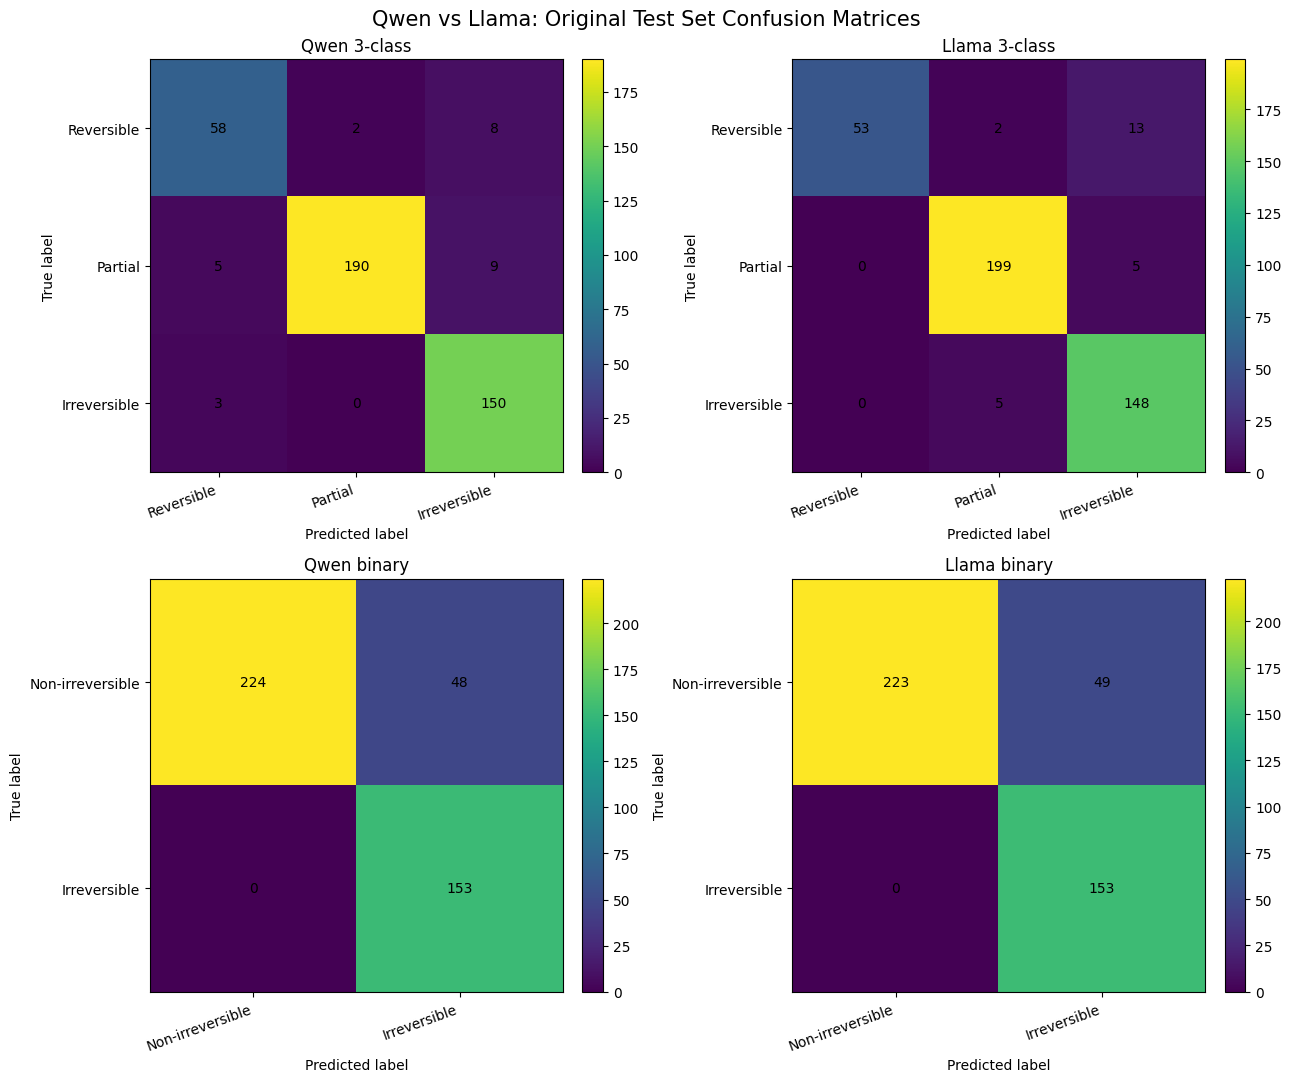

All four confusion matrices plotted successfully.

Qwen 3-class
[[ 58   2   8]
 [  5 190   9]
 [  3   0 150]]

Llama 3-class
[[ 53   2  13]
 [  0 199   5]
 [  0   5 148]]

Qwen binary
[[224  48]
 [  0 153]]

Llama binary
[[223  49]
 [  0 153]]


In [210]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
comparison_dir = Path("/kaggle/working/COMPARISON")

files = {
    "Qwen 3-class": qwen_dir / "probes/qwen_v2_final_3class_results.json",
    "Llama 3-class": llama_dir / "probes/llama_v2_3class_final_test_results.json",
    "Qwen binary": qwen_dir / "probes/qwen_v2_final_binary_results.json",
    "Llama binary": llama_dir / "probes/llama_v2_binary_final_test_results.json"
}

data = {}

for name, path in files.items():
    with open(path) as f:
        result = json.load(f)

    if "test_metrics" in result:
        cm = result.get("confusion_matrix")
        if cm is None:
            cm = result["test_metrics"]["confusion_matrix"]
    else:
        cm = result["confusion_matrix"]

    data[name] = np.array(cm)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

plots = [
    ("Qwen 3-class", axes[0, 0],
     ["Reversible", "Partial", "Irreversible"]),
    ("Llama 3-class", axes[0, 1],
     ["Reversible", "Partial", "Irreversible"]),
    ("Qwen binary", axes[1, 0],
     ["Non-irreversible", "Irreversible"]),
    ("Llama binary", axes[1, 1],
     ["Non-irreversible", "Irreversible"])
]

for name, ax, labels in plots:
    cm = data[name]
    im = ax.imshow(cm)

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_yticklabels(labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle(
    "Qwen vs Llama: Original Test Set Confusion Matrices",
    fontsize=15
)

plt.tight_layout()
fig.savefig(
    comparison_dir / "original_test_confusion_matrices_comparison.png",
    dpi=300
)
fig.savefig(
    comparison_dir / "original_test_confusion_matrices_comparison.pdf"
)

plt.show()
plt.close(fig)

print("All four confusion matrices plotted successfully.")

for name, cm in data.items():
    print(f"\n{name}")
    print(cm)

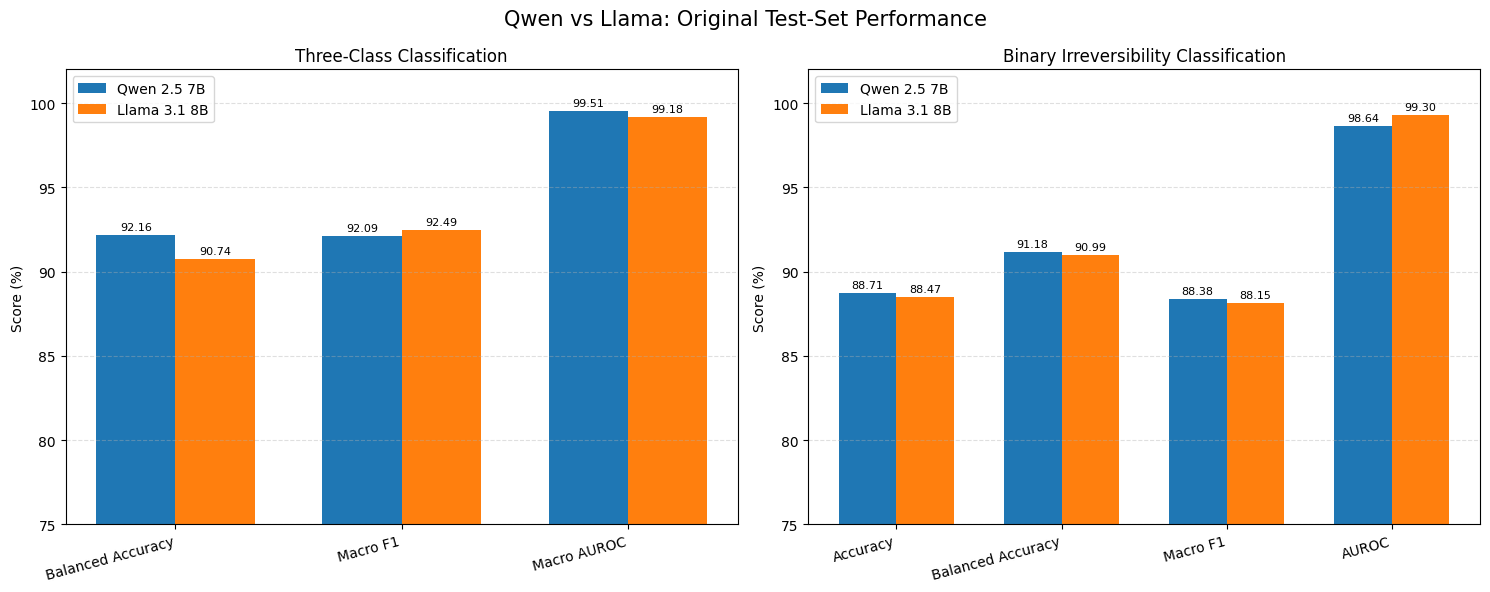

Original test metric comparison plots saved.

Three-class metrics:
Balanced Accuracy: Qwen=92.16%, Llama=90.74%
Macro F1: Qwen=92.09%, Llama=92.49%
Macro AUROC: Qwen=99.51%, Llama=99.18%

Binary metrics:
Accuracy: Qwen=88.71%, Llama=88.47%
Balanced Accuracy: Qwen=91.18%, Llama=90.99%
Macro F1: Qwen=88.38%, Llama=88.15%
AUROC: Qwen=98.64%, Llama=99.30%


In [211]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
comparison_dir = Path("/kaggle/working/COMPARISON")

with open(qwen_dir / "probes/qwen_v2_final_3class_results.json") as f:
    q3 = json.load(f)

with open(llama_dir / "probes/llama_v2_3class_final_test_results.json") as f:
    l3 = json.load(f)

with open(qwen_dir / "probes/qwen_v2_final_binary_results.json") as f:
    qb = json.load(f)

with open(llama_dir / "probes/llama_v2_binary_final_test_results.json") as f:
    lb = json.load(f)

# Extract comparable metrics
three_class = {
    "Balanced Accuracy": [
        q3["test_metrics"]["balanced_accuracy"] * 100,
        l3["test_balanced_accuracy"] * 100
    ],
    "Macro F1": [
        q3["test_metrics"]["macro_f1"] * 100,
        l3["test_macro_f1"] * 100
    ],
    "Macro AUROC": [
        q3["test_metrics"]["macro_auroc"] * 100,
        l3["test_macro_auroc_ovr"] * 100
    ]
}

binary = {
    "Accuracy": [
        qb["test_metrics"]["accuracy"] * 100,
        lb["test_accuracy"] * 100
    ],
    "Balanced Accuracy": [
        qb["test_metrics"]["balanced_accuracy"] * 100,
        lb["test_balanced_accuracy"] * 100
    ],
    "Macro F1": [
        qb["test_metrics"]["macro_f1"] * 100,
        lb["classification_report"]["macro avg"]["f1-score"] * 100
    ],
    "AUROC": [
        qb["test_metrics"]["auroc"] * 100,
        lb["test_auroc"] * 100
    ]
}

def plot_metrics(ax, metrics, title):
    names = list(metrics.keys())
    x = np.arange(len(names))
    width = 0.35

    qwen_values = [metrics[m][0] for m in names]
    llama_values = [metrics[m][1] for m in names]

    ax.bar(x - width/2, qwen_values, width, label="Qwen 2.5 7B")
    ax.bar(x + width/2, llama_values, width, label="Llama 3.1 8B")

    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=15, ha="right")
    ax.set_ylabel("Score (%)")
    ax.set_title(title)
    ax.set_ylim(75, 102)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend()

    for i, value in enumerate(qwen_values):
        ax.text(i - width/2, value + 0.3, f"{value:.2f}",
                ha="center", fontsize=8)

    for i, value in enumerate(llama_values):
        ax.text(i + width/2, value + 0.3, f"{value:.2f}",
                ha="center", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_metrics(axes[0], three_class, "Three-Class Classification")
plot_metrics(axes[1], binary, "Binary Irreversibility Classification")

fig.suptitle("Qwen vs Llama: Original Test-Set Performance", fontsize=15)

plt.tight_layout()
fig.savefig(comparison_dir / "original_test_metrics_comparison.png", dpi=300)
fig.savefig(comparison_dir / "original_test_metrics_comparison.pdf")

plt.show()
plt.close(fig)

print("Original test metric comparison plots saved.")

print("\nThree-class metrics:")
for metric, values in three_class.items():
    print(f"{metric}: Qwen={values[0]:.2f}%, Llama={values[1]:.2f}%")

print("\nBinary metrics:")
for metric, values in binary.items():
    print(f"{metric}: Qwen={values[0]:.2f}%, Llama={values[1]:.2f}%")

In [212]:
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2"),
    "COMPARISON": Path("/kaggle/working/COMPARISON")
}

for name, folder in folders.items():
    print(f"\n{'='*55}")
    print(name)
    print(f"{'='*55}")

    for subfolder in ["hidden_states", "probes", "ablations",
                      "baselines", "analysis", "plots"]:
        path = folder / subfolder

        if path.exists():
            files = list(path.iterdir())
            print(f"\n{subfolder}/ ({len(files)} files)")
            for file in sorted(files):
                print("  ", file.name)
        elif name == "COMPARISON":
            continue
        else:
            print(f"\n{subfolder}/ MISSING")

    if name == "COMPARISON":
        print("\nComparison files:")
        for file in sorted(folder.iterdir()):
            print("  ", file.name)


Qwen

hidden_states/ (6 files)
   extraction_index.jsonl
   extraction_manifest.jsonl
   extraction_metadata.json
   extraction_progress.npy
   last_action_token.npy
   mean_action_tokens.npy

probes/ (16 files)
   best_layers.json
   manifest.json
   metrics.json
   probe_split.json
   qwen_v2_3class_layer_screening.json
   qwen_v2_3class_robustness_predictions.jsonl
   qwen_v2_3class_robustness_subset.json
   qwen_v2_3class_test_predictions.jsonl
   qwen_v2_binary_bootstrap_ci.json
   qwen_v2_binary_c_selection.json
   qwen_v2_binary_layer_screening.json
   qwen_v2_binary_predictions.jsonl
   qwen_v2_binary_robustness_predictions.jsonl
   qwen_v2_binary_robustness_subset.json
   qwen_v2_final_3class_results.json
   qwen_v2_final_binary_results.json

ablations/ (2 files)
   qwen_v2_binary_horizon_ablations.json
   qwen_v2_binary_mean_action_tokens_layer18.json

baselines/ (6 files)
   qwen_v2_binary_bow_action_text.json
   qwen_v2_binary_bow_state_action.json
   qwen_v2_binary_layer0

In [213]:
import json
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/baselines"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/baselines")
}

for model, folder in folders.items():
    print(f"\n{'='*55}")
    print(model, "BASELINES")
    print(f"{'='*55}")

    for path in sorted(folder.glob("*.json")):
        with open(path) as f:
            data = json.load(f)

        print(f"\nFILE: {path.name}")
        print("Keys:", list(data.keys()))

        # Show the main result fields without dumping the entire file
        for key, value in data.items():
            if isinstance(value, (int, float, str, bool)):
                print(f"{key}: {value}")
            elif isinstance(value, dict):
                print(f"{key}: {json.dumps(value)[:700]}")


Qwen BASELINES

FILE: qwen_v2_binary_bow_action_text.json
Keys: ['experiment', 'task', 'features', 'selection', 'classifier', 'test', 'metrics']
experiment: qwen_v2_binary_bow_action_text
task: {"type": "binary", "label_mapping": {"0": "non_irreversible", "1": "irreversible"}}
features: {"source": "action_text", "vectorizer": "TfidfVectorizer", "lowercase": true, "ngram_range": [1, 2], "min_df": 2, "sublinear_tf": true}
selection: {"method": "GroupKFold", "n_splits": 5, "group": "scenario_id", "C_grid": [0.001, 0.01, 0.1, 1.0, 10.0], "selected_C": 10.0, "inner_cv_balanced_accuracy": 0.6639182377989292, "inner_cv_sd": 0.046402217754449075}
classifier: {"penalty": "l2", "C": 10.0, "class_weight": "balanced", "solver": "liblinear", "max_iter": 1000, "random_state": 42}
test: {"n": 425}
metrics: {"accuracy": 0.76, "balanced_accuracy": 0.7438725490196079, "macro_f1": 0.7417429225050043, "auroc": 0.8710351787773933, "per_class": {"non_irreversible": {"precision": 0.8195488721804511, "recall

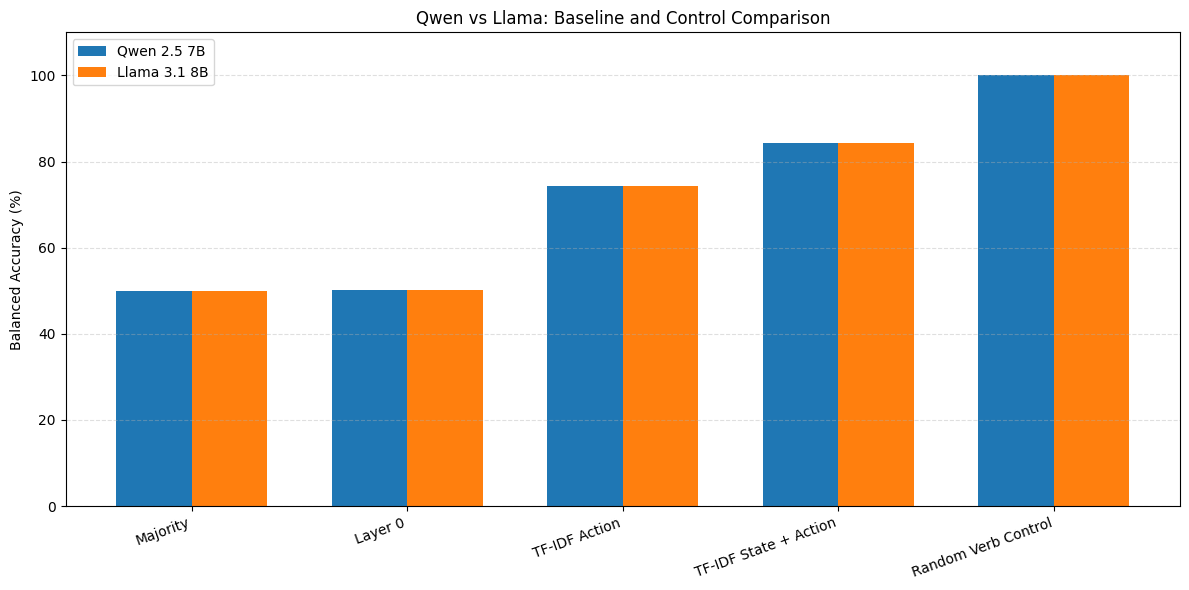

Baseline comparison saved.
Majority: Qwen=50.00%, Llama=50.00%
Layer 0: Qwen=50.18%, Llama=50.18%
TF-IDF Action: Qwen=74.39%, Llama=74.39%
TF-IDF State + Action: Qwen=84.40%, Llama=84.40%
Random Verb Control: Qwen=100.00%, Llama=100.00%


In [214]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

q = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
l = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
out = Path("/kaggle/working/COMPARISON")

def read(path):
    with open(path) as f:
        return json.load(f)

experiments = {
    "Majority": ("baselines/qwen_v2_binary_majority_baseline.json",
                 "baselines/llama_v2_binary_majority_baseline.json"),
    "Layer 0": ("baselines/qwen_v2_binary_layer0_embedding_baseline.json",
                "baselines/llama_v2_binary_layer0_embedding_baseline.json"),
    "TF-IDF Action": ("baselines/qwen_v2_binary_bow_action_text.json",
                     "baselines/llama_v2_binary_bow_action_text.json"),
    "TF-IDF State + Action": ("baselines/qwen_v2_binary_bow_state_action.json",
                              "baselines/llama_v2_binary_bow_state_action.json"),
    "Random Verb Control": ("baselines/qwen_v2_binary_random_action_verb_control.json",
                            "baselines/llama_v2_binary_random_action_verb_control.json")
}

def get_ba(data):
    if "metrics" in data:
        return data["metrics"]["balanced_accuracy"] * 100
    return data["balanced_accuracy"] * 100

names = []
qwen_scores = []
llama_scores = []

for name, (qfile, lfile) in experiments.items():
    qdata = read(q / qfile)
    ldata = read(l / lfile)

    names.append(name)
    qwen_scores.append(get_ba(qdata))
    llama_scores.append(get_ba(ldata))

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width/2, qwen_scores, width, label="Qwen 2.5 7B")
ax.bar(x + width/2, llama_scores, width, label="Llama 3.1 8B")

ax.set_ylabel("Balanced Accuracy (%)")
ax.set_title("Qwen vs Llama: Baseline and Control Comparison")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=20, ha="right")
ax.set_ylim(0, 110)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()
fig.savefig(out / "baseline_control_comparison.png", dpi=300)
fig.savefig(out / "baseline_control_comparison.pdf")
plt.show()
plt.close(fig)

print("Baseline comparison saved.")
for name, qs, ls in zip(names, qwen_scores, llama_scores):
    print(f"{name}: Qwen={qs:.2f}%, Llama={ls:.2f}%")

In [215]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/ADNN_RQ1_Qwen_v2/baselines/"
    "qwen_v2_binary_random_action_verb_control.json"
)

with open(path) as f:
    data = json.load(f)

print("Random verb mapping:")
print(json.dumps(data["random_mapping"], indent=2))

print("\nControl target:")
print(data["task"])

print("\nTest records:")
print(data["test"])

print("\nControl metrics:")
print(json.dumps(data["metrics"], indent=2))

Random verb mapping:
{
  "seed": 42,
  "n_action_verbs": 13,
  "mapping": {
    "connect": 0,
    "create_share_link": 1,
    "delete_file": 1,
    "edit_file": 0,
    "move": 0,
    "open": 1,
    "restore_backup": 0,
    "restore_file": 1,
    "revert_file": 0,
    "revoke_share_link": 0,
    "send_email": 1,
    "transfer_money": 1,
    "use": 1
  }
}

Control target:
{'type': 'binary', 'target': 'fixed_random_label_per_action_verb'}

Test records:
{'n': 425, 'class_0': 262, 'class_1': 163}

Control metrics:
{
  "accuracy": 1.0,
  "balanced_accuracy": 1.0,
  "macro_f1": 1.0,
  "auroc": 1.0,
  "per_class": {
    "random_label_0": {
      "precision": 1.0,
      "recall": 1.0,
      "f1": 1.0
    },
    "random_label_1": {
      "precision": 1.0,
      "recall": 1.0,
      "f1": 1.0
    }
  },
  "confusion_matrix": [
    [
      262,
      0
    ],
    [
      0,
      163
    ]
  ]
}


In [218]:
import json
from pathlib import Path
from collections import defaultdict, Counter

data_path = Path(
    "/kaggle/input/datasets/aashrithap/"
    "dataset-adnn-v2/adnn-dataset-v2.0/"
    "data/production/v2.0/records.jsonl"
)

verb_counts = defaultdict(Counter)

with open(data_path) as f:
    for line in f:
        record = json.loads(line)

        verb = record.get("action_verb")
        label = record.get("label")

        if verb and label:
            verb_counts[verb][label] += 1

print("ACTION VERB vs REVERSIBILITY LABEL")
print("=" * 65)

for verb, counts in sorted(verb_counts.items()):
    total = sum(counts.values())

    print(f"\n{verb} (n={total})")

    for label in [
        "reversible",
        "partially_reversible",
        "irreversible"
    ]:
        count = counts[label]
        percentage = count / total * 100 if total else 0

        print(f"  {label}: {count} ({percentage:.1f}%)")

print("\n" + "=" * 65)
print("Total distinct action verbs:", len(verb_counts))
print("Total records:", sum(sum(c.values()) for c in verb_counts.values()))

ACTION VERB vs REVERSIBILITY LABEL

connect (n=1)
  reversible: 1 (100.0%)
  partially_reversible: 0 (0.0%)
  irreversible: 0 (0.0%)

create_share_link (n=12)
  reversible: 6 (50.0%)
  partially_reversible: 6 (50.0%)
  irreversible: 0 (0.0%)

delete_file (n=423)
  reversible: 285 (67.4%)
  partially_reversible: 0 (0.0%)
  irreversible: 138 (32.6%)

edit_file (n=372)
  reversible: 46 (12.4%)
  partially_reversible: 326 (87.6%)
  irreversible: 0 (0.0%)

move (n=1)
  reversible: 1 (100.0%)
  partially_reversible: 0 (0.0%)
  irreversible: 0 (0.0%)

open (n=1)
  reversible: 1 (100.0%)
  partially_reversible: 0 (0.0%)
  irreversible: 0 (0.0%)

restore_backup (n=296)
  reversible: 105 (35.5%)
  partially_reversible: 52 (17.6%)
  irreversible: 139 (47.0%)

restore_file (n=70)
  reversible: 0 (0.0%)
  partially_reversible: 70 (100.0%)
  irreversible: 0 (0.0%)

revert_file (n=91)
  reversible: 0 (0.0%)
  partially_reversible: 0 (0.0%)
  irreversible: 91 (100.0%)

revoke_share_link (n=30)
  rever

In [220]:
import json
from pathlib import Path
from collections import defaultdict, Counter

base = Path(
    "/kaggle/input/datasets/aashrithap/"
    "dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0"
)

with open(base / "split.json") as f:
    split_data = json.load(f)

test_scenarios = set(split_data["test_scenarios"])

verb_counts = defaultdict(Counter)

with open(base / "records.jsonl") as f:
    for line in f:
        record = json.loads(line)

        if record["scenario_id"] not in test_scenarios:
            continue

        verb = record["action_verb"]
        label = record["label"]

        verb_counts[verb][label] += 1

print("OFFICIAL TEST SET: LABEL DISTRIBUTION BY ACTION VERB")
print("=" * 70)

for verb, counts in sorted(verb_counts.items()):
    total = sum(counts.values())

    print(f"\n{verb} (n={total})")

    for label in [
        "reversible",
        "partially_reversible",
        "irreversible"
    ]:
        count = counts[label]
        if count:
            print(f"  {label}: {count}")

    present_labels = sum(1 for count in counts.values() if count > 0)
    print("  Number of represented labels:", present_labels)

print("\nTotal test records:", sum(sum(c.values()) for c in verb_counts.values()))
print("Distinct test verbs:", len(verb_counts))

OFFICIAL TEST SET: LABEL DISTRIBUTION BY ACTION VERB

connect (n=1)
  reversible: 1
  Number of represented labels: 1

delete_file (n=12)
  reversible: 12
  Number of represented labels: 1

edit_file (n=126)
  partially_reversible: 126
  Number of represented labels: 1

restore_backup (n=78)
  reversible: 21
  irreversible: 57
  Number of represented labels: 2

revert_file (n=39)
  irreversible: 39
  Number of represented labels: 1

revoke_share_link (n=18)
  reversible: 9
  partially_reversible: 9
  Number of represented labels: 2

transfer_money (n=151)
  reversible: 25
  partially_reversible: 69
  irreversible: 57
  Number of represented labels: 3

Total test records: 425
Distinct test verbs: 7


In [221]:
import json
from pathlib import Path
from collections import defaultdict
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

base = Path(
    "/kaggle/input/datasets/aashrithap/"
    "dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0"
)

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/probes")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/probes")

# Load official test scenarios
with open(base / "split.json") as f:
    split_data = json.load(f)

test_scenarios = set(split_data["test_scenarios"])

# Map test record IDs to action verbs and binary labels
record_info = {}

with open(base / "records.jsonl") as f:
    for line in f:
        record = json.loads(line)

        if record["scenario_id"] in test_scenarios:
            record_info[record["id"]] = {
                "verb": record["action_verb"],
                "label": 1 if record["label"] == "irreversible" else 0
            }

def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]

predictions = {
    "Qwen": load_jsonl(qwen_dir / "qwen_v2_binary_predictions.jsonl"),
    "Llama": load_jsonl(llama_dir / "llama_v2_binary_predictions.jsonl")
}

target_verbs = ["restore_backup", "transfer_money"]

for verb in target_verbs:
    print(f"\n{'='*60}")
    print(f"ACTION VERB: {verb}")
    print(f"{'='*60}")

    for model, preds in predictions.items():
        y_true = []
        y_pred = []

        for p in preds:
            rid = p["record_id"]

            if rid not in record_info:
                continue

            info = record_info[rid]

            if info["verb"] != verb:
                continue

            y_true.append(info["label"])
            y_pred.append(int(p["predicted_label"]))

        print(f"\n{model}")
        print("Records:", len(y_true))
        print("True class counts:", {
            0: y_true.count(0),
            1: y_true.count(1)
        })

        if len(set(y_true)) == 2:
            print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
            print("Balanced accuracy:", round(
                balanced_accuracy_score(y_true, y_pred), 4
            ))
            print("Macro F1:", round(
                f1_score(y_true, y_pred, average="macro"), 4
            ))
        else:
            print("Insufficient label diversity for balanced evaluation.")


ACTION VERB: restore_backup

Qwen
Records: 78
True class counts: {0: 21, 1: 57}
Accuracy: 0.7308
Balanced accuracy: 0.5
Macro F1: 0.4222

Llama
Records: 78
True class counts: {0: 21, 1: 57}
Accuracy: 0.7692
Balanced accuracy: 0.5714
Macro F1: 0.5568

ACTION VERB: transfer_money

Qwen
Records: 151
True class counts: {0: 94, 1: 57}
Accuracy: 0.8212
Balanced accuracy: 0.8564
Macro F1: 0.8204

Llama
Records: 151
True class counts: {0: 94, 1: 57}
Accuracy: 0.9007
Balanced accuracy: 0.9202
Macro F1: 0.8985


In [222]:
import json
from pathlib import Path

results = {
    "experiment": "within_action_verb_binary_evaluation",
    "evaluation": "official_frozen_test_set",
    "retrained": False,
    "models": {
        "Qwen": {
            "restore_backup": {
                "n": 78,
                "class_counts": {"non_irreversible": 21, "irreversible": 57},
                "accuracy": 0.7308,
                "balanced_accuracy": 0.5,
                "macro_f1": 0.4222
            },
            "transfer_money": {
                "n": 151,
                "class_counts": {"non_irreversible": 94, "irreversible": 57},
                "accuracy": 0.8212,
                "balanced_accuracy": 0.8564,
                "macro_f1": 0.8204
            }
        },
        "Llama": {
            "restore_backup": {
                "n": 78,
                "class_counts": {"non_irreversible": 21, "irreversible": 57},
                "accuracy": 0.7692,
                "balanced_accuracy": 0.5714,
                "macro_f1": 0.5568
            },
            "transfer_money": {
                "n": 151,
                "class_counts": {"non_irreversible": 94, "irreversible": 57},
                "accuracy": 0.9007,
                "balanced_accuracy": 0.9202,
                "macro_f1": 0.8985
            }
        }
    },
    "limitation": (
        "Only two action verbs contain both binary classes in the "
        "official test set. Results are diagnostic and do not establish "
        "generalization across action verbs."
    )
}

folders = [
    Path("/kaggle/working/ADNN_RQ1_Qwen_v2/analysis"),
    Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis"),
    Path("/kaggle/working/COMPARISON")
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

    path = folder / "within_action_verb_binary_evaluation.json"

    with open(path, "w") as f:
        json.dump(results, f, indent=2)

    print("Saved:", path)

print("\nWithin-action-verb diagnostic results saved.")

Saved: /kaggle/working/ADNN_RQ1_Qwen_v2/analysis/within_action_verb_binary_evaluation.json
Saved: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/within_action_verb_binary_evaluation.json
Saved: /kaggle/working/COMPARISON/within_action_verb_binary_evaluation.json

Within-action-verb diagnostic results saved.


In [223]:
import json
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2")
}

keywords = ["minimal_pair", "horizon", "mean_action", "style"]

for model, folder in folders.items():
    print(f"\n{'='*60}")
    print(model)
    print(f"{'='*60}")

    for subfolder in ["analysis", "ablations", "baselines"]:
        directory = folder / subfolder

        for path in sorted(directory.glob("*.json")):
            if not any(k in path.name for k in keywords):
                continue

            with open(path) as f:
                data = json.load(f)

            print(f"\nFILE: {path.name}")
            print("Keys:", list(data.keys()))
            print(json.dumps(data, indent=2)[:1800])


Qwen

FILE: qwen_v2_canonical_24_minimal_pairs.json
Keys: ['analysis', 'selection_basis', 'canonical_family_count', 'canonical_families', 'excluded_families', 'valid_pair_render_instances', 'correct_pair_render_instances', 'pair_accuracy', 'contrast_preservation_accuracy', 'record_level_balanced_accuracy', 'record_level_macro_f1', 'render_style_results', 'pair_results']
{
  "analysis": "canonical_24_minimal_pair_subset",
  "selection_basis": "7 v2a1_restore_backup_fresh families + 17 v2b4_second_payment_policy families",
  "canonical_family_count": 24,
  "canonical_families": [
    "v2a1_restore_backup_fresh-0001-primary",
    "v2a1_restore_backup_fresh-0005-primary",
    "v2a1_restore_backup_fresh-0006-primary",
    "v2a1_restore_backup_fresh-0008-primary",
    "v2a1_restore_backup_fresh-0010-primary",
    "v2a1_restore_backup_fresh-0016-primary",
    "v2a1_restore_backup_fresh-0124-primary",
    "v2b4_second_payment_policy-0000-primary",
    "v2b4_second_payment_policy-0003-primary"

In [224]:
import json
from pathlib import Path

files = {
    "Qwen": Path(
        "/kaggle/working/ADNN_RQ1_Qwen_v2/analysis/"
        "qwen_v2_canonical_24_minimal_pairs.json"
    ),
    "Llama": Path(
        "/kaggle/working/ADNN_RQ1_Llama_v2/analysis/"
        "llama_v2_canonical_24_minimal_pairs.json"
    )
}

for model, path in files.items():
    with open(path) as f:
        data = json.load(f)

    print(f"\n{'='*55}")
    print(model, "CANONICAL MINIMAL-PAIR RENDER STYLES")
    print(f"{'='*55}")

    print("Canonical families:", data["canonical_family_count"])
    print("Valid pair instances:", data["valid_pair_render_instances"])
    print("Correct pair instances:", data["correct_pair_render_instances"])

    print("\nRender-style results:")
    print(json.dumps(data["render_style_results"], indent=2))


Qwen CANONICAL MINIMAL-PAIR RENDER STYLES
Canonical families: 24
Valid pair instances: 72
Correct pair instances: 25

Render-style results:
{
  "compact": {
    "n": 24,
    "correct": 3,
    "failed": 21,
    "pair_accuracy": 0.125
  },
  "kv": {
    "n": 24,
    "correct": 13,
    "failed": 11,
    "pair_accuracy": 0.5416666666666666
  },
  "prose": {
    "n": 24,
    "correct": 9,
    "failed": 15,
    "pair_accuracy": 0.375
  }
}

Llama CANONICAL MINIMAL-PAIR RENDER STYLES
Canonical families: 24
Valid pair instances: 72
Correct pair instances: 39

Render-style results:
{
  "compact": {
    "n": 24,
    "correct": 7,
    "failed": 17,
    "pair_accuracy": 0.2916666666666667
  },
  "kv": {
    "n": 24,
    "correct": 17,
    "failed": 7,
    "pair_accuracy": 0.7083333333333334
  },
  "prose": {
    "n": 24,
    "correct": 15,
    "failed": 9,
    "pair_accuracy": 0.625
  }
}


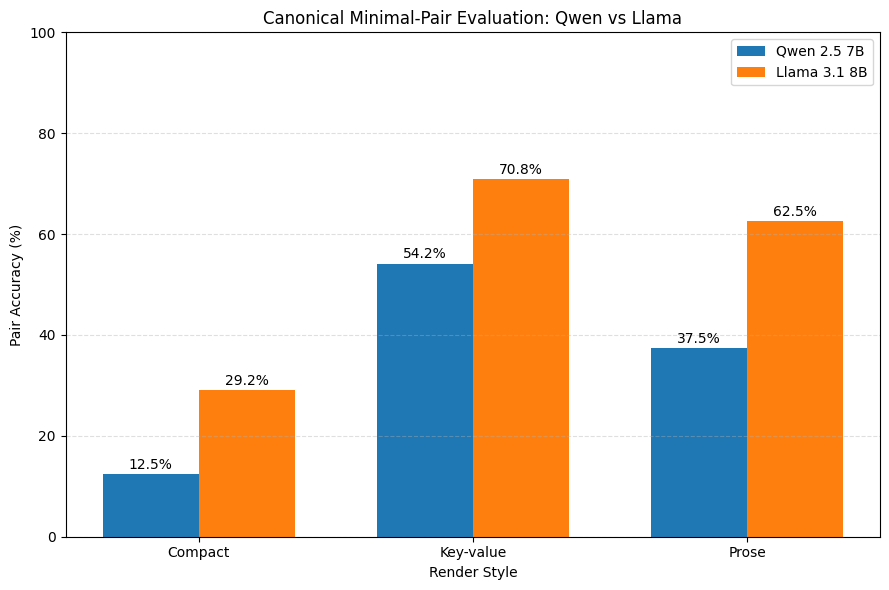

Minimal-pair render-style comparison saved.


In [225]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

qwen_path = Path(
    "/kaggle/working/ADNN_RQ1_Qwen_v2/analysis/"
    "qwen_v2_canonical_24_minimal_pairs.json"
)

llama_path = Path(
    "/kaggle/working/ADNN_RQ1_Llama_v2/analysis/"
    "llama_v2_canonical_24_minimal_pairs.json"
)

out = Path("/kaggle/working/COMPARISON")

with open(qwen_path) as f:
    qwen = json.load(f)

with open(llama_path) as f:
    llama = json.load(f)

styles = ["compact", "kv", "prose"]

qwen_scores = [
    qwen["render_style_results"][s]["pair_accuracy"] * 100
    for s in styles
]

llama_scores = [
    llama["render_style_results"][s]["pair_accuracy"] * 100
    for s in styles
]

x = np.arange(len(styles))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(x - width/2, qwen_scores, width, label="Qwen 2.5 7B")
ax.bar(x + width/2, llama_scores, width, label="Llama 3.1 8B")

ax.set_ylabel("Pair Accuracy (%)")
ax.set_xlabel("Render Style")
ax.set_title("Canonical Minimal-Pair Evaluation: Qwen vs Llama")
ax.set_xticks(x)
ax.set_xticklabels(["Compact", "Key-value", "Prose"])
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

for i, value in enumerate(qwen_scores):
    ax.text(i - width/2, value + 1, f"{value:.1f}%", ha="center")

for i, value in enumerate(llama_scores):
    ax.text(i + width/2, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()

fig.savefig(out / "canonical_minimal_pair_render_style_comparison.png", dpi=300)
fig.savefig(out / "canonical_minimal_pair_render_style_comparison.pdf")

plt.show()
plt.close(fig)

print("Minimal-pair render-style comparison saved.")

In [226]:
import json
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/analysis"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis")
}

keywords = ["environment", "sandbox", "scienceworld"]

for model, folder in folders.items():
    print(f"\n{'='*60}")
    print(model, "CROSS-ENVIRONMENT ANALYSIS")
    print(f"{'='*60}")

    matching = [
        p for p in sorted(folder.glob("*.json"))
        if any(k in p.name.lower() for k in keywords)
    ]

    if not matching:
        print("No matching analysis files found.")

    for path in matching:
        with open(path) as f:
            data = json.load(f)

        print(f"\nFILE: {path.name}")
        print(json.dumps(data, indent=2)[:3000])


Qwen CROSS-ENVIRONMENT ANALYSIS

FILE: qwen_v2_binary_environment_breakdown.json
{
  "sandbox": {
    "n": 424,
    "accuracy": 0.8867924528301887,
    "balanced_accuracy": 0.9114391143911439,
    "macro_f1": 0.8836203938790914,
    "class_counts": {
      "non_irreversible": 271,
      "irreversible": 153
    },
    "auroc": 0.9863733931456962
  },
  "scienceworld": {
    "n": 1,
    "accuracy": 1.0,
    "balanced_accuracy": 1.0,
    "macro_f1": 1.0,
    "class_counts": {
      "non_irreversible": 1,
      "irreversible": 0
    },
    "auroc": null
  }
}

Llama CROSS-ENVIRONMENT ANALYSIS

FILE: llama_v2_sandbox_to_scienceworld.json
{
  "experiment": "cross_environment_transfer",
  "direction": "sandbox_to_scienceworld",
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "task": "three_class",
  "layer": 17,
  "C": 1.0,
  "training_environment": "sandbox",
  "training_records": 1705,
  "test_environment": "scienceworld",
  "test_records": 1,
  "correct_predictions": 0,
  "accuracy": 0.0

In [227]:
from pathlib import Path

root = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")

for folder_name in ["probes", "analysis", "ablations"]:
    folder = root / folder_name

    print(f"\n{'='*55}")
    print(folder_name.upper())
    print(f"{'='*55}")

    for path in sorted(folder.glob("*.json")):
        print(path.name)


PROBES
best_layers.json
manifest.json
metrics.json
probe_split.json
qwen_v2_3class_layer_screening.json
qwen_v2_3class_robustness_subset.json
qwen_v2_binary_bootstrap_ci.json
qwen_v2_binary_c_selection.json
qwen_v2_binary_layer_screening.json
qwen_v2_binary_robustness_subset.json
qwen_v2_final_3class_results.json
qwen_v2_final_binary_results.json

ANALYSIS
qwen_v2_binary_environment_breakdown.json
qwen_v2_canonical_24_minimal_pairs.json
qwen_v2_minimal_pair_24_results.json
qwen_v2_minimal_pair_render_style.json
qwen_v2_rq1_summary.json
within_action_verb_binary_evaluation.json

ABLATIONS
qwen_v2_binary_horizon_ablations.json
qwen_v2_binary_mean_action_tokens_layer18.json


In [228]:
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON")

print("COMPARISON FOLDER")
print("=" * 60)

for path in sorted(folder.iterdir()):
    if path.is_file():
        print(f"{path.name}  ({path.stat().st_size / 1024:.1f} KB)")

COMPARISON FOLDER
ADNN_RQ1_robustness_model_comparison.json  (5.1 KB)
baseline_control_comparison.pdf  (17.8 KB)
baseline_control_comparison.png  (175.7 KB)
binary_bootstrap_ci_comparison.pdf  (18.6 KB)
binary_bootstrap_ci_comparison.png  (119.9 KB)
binary_confusion_comparison.pdf  (20.7 KB)
binary_confusion_comparison.png  (166.1 KB)
binary_per_class_f1_comparison.pdf  (16.3 KB)
binary_per_class_f1_comparison.png  (103.2 KB)
binary_robustness_comparison.pdf  (17.4 KB)
binary_robustness_comparison.png  (127.4 KB)
canonical_minimal_pair_render_style_comparison.pdf  (17.1 KB)
canonical_minimal_pair_render_style_comparison.png  (125.9 KB)
llama_3class_layer_screening.pdf  (19.4 KB)
llama_3class_layer_screening.png  (173.0 KB)
original_test_confusion_matrices_comparison.pdf  (27.2 KB)
original_test_confusion_matrices_comparison.png  (334.4 KB)
original_test_metrics_comparison.pdf  (19.7 KB)
original_test_metrics_comparison.png  (230.0 KB)
qwen_3class_layer_screening.pdf  (19.7 KB)
qwen_3cl

In [229]:
import json
from pathlib import Path

files = {
    "Qwen summary": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/analysis/qwen_v2_rq1_summary.json"),
    "Llama summary": Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_rq1_summary.json"),
    "Robustness comparison": Path("/kaggle/working/COMPARISON/ADNN_RQ1_robustness_model_comparison.json"),
    "Within-verb comparison": Path("/kaggle/working/COMPARISON/within_action_verb_binary_evaluation.json")
}

for name, path in files.items():
    print(f"\n{'='*65}")
    print(name)
    print(f"{'='*65}")

    if path.exists():
        with open(path) as f:
            print(json.dumps(json.load(f), indent=2))
    else:
        print("FILE NOT FOUND:", path)


Qwen summary
{
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "status": "preliminary_v1.0",
  "primary_result": {
    "three_class_BA": 0.9216,
    "three_class_macro_F1": 0.9209,
    "three_class_AUROC": 0.9951,
    "binary_BA": 0.9117647058823529,
    "binary_macro_F1": 0.8838162930563149,
    "binary_AUROC": 0.9864234909650134
  },
  "critical_diagnostics": {
    "random_action_verb_BA": 1.0,
    "canonical_24_pair_accuracy": 0.3472222222222222,
    "restore_backup_pair_accuracy": 0.0,
    "transfer_money_pair_accuracy": 0.49019607843137253,
    "compact_pair_accuracy": 0.125,
    "kv_pair_accuracy": 0.5416666666666666,
    "prose_pair_accuracy": 0.375
  },
  "interpretation": "Aggregate reversibility decoding is strong, but minimal-pair and random-action-verb controls indicate substantial entanglement with action identity, context, and rendering factors."
}

Llama summary
FILE NOT FOUND: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_rq1_summary.json

Robustness comparison
{
  "qwe

In [230]:
import json
from pathlib import Path

files = {
    "Qwen 3-class": "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_final_3class_results.json",
    "Qwen binary": "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_final_binary_results.json",
    "Llama 3-class": "/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_final_test_results.json",
    "Llama binary": "/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_final_test_results.json"
}

for name, filename in files.items():
    print(f"\n{'='*60}\n{name}\n{'='*60}")
    path = Path(filename)

    if path.exists():
        with open(path) as f:
            data = json.load(f)
        print(json.dumps(data, indent=2)[:5000])
    else:
        print("MISSING:", filename)


Qwen 3-class
{
  "experiment": "ADNN_RQ1_Qwen_v2_final",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "dataset_version": "adnn-dataset-2.0",
  "task": "three_class",
  "selected_layer": 20,
  "selected_C": 0.1,
  "inner_cv_balanced_accuracy": 0.8928,
  "train_records": 1709,
  "test_records": 425,
  "test_metrics": {
    "balanced_accuracy": 0.9216,
    "macro_f1": 0.9209,
    "macro_auroc": 0.9951
  },
  "per_class": {
    "reversible": {
      "precision": 0.8788,
      "recall": 0.8529,
      "f1": 0.8657,
      "support": 68
    },
    "partially_reversible": {
      "precision": 0.9896,
      "recall": 0.9314,
      "f1": 0.9596,
      "support": 204
    },
    "irreversible": {
      "precision": 0.8982,
      "recall": 0.9804,
      "f1": 0.9375,
      "support": 153
    }
  },
  "confusion_matrix": [
    [
      58,
      2,
      8
    ],
    [
      5,
      190,
      9
    ],
    [
      3,
      0,
      150
    ]
  ],
  "cv_selection_source": "inner_group_kfold",
  "test_use

In [231]:
import json
from pathlib import Path

qwen_dir = Path("/kaggle/working/ADNN_RQ1_Qwen_v2/analysis")
llama_dir = Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis")

qwen_summary = {
    "model": "Qwen/Qwen2.5-7B-Instruct",
    "status": "final_v2",
    "primary_result": {
        "three_class": {
            "layer": 20, "C": 0.1,
            "balanced_accuracy": 0.9216,
            "macro_f1": 0.9209,
            "macro_auroc": 0.9951
        },
        "binary": {
            "layer": 18, "C": 0.01,
            "accuracy": 0.8870588,
            "balanced_accuracy": 0.9117647,
            "macro_f1": 0.8838163,
            "auroc": 0.9864235
        }
    },
    "critical_diagnostics": {
        "random_action_verb_balanced_accuracy": 1.0,
        "canonical_24_minimal_pair_accuracy": 0.3472222,
        "cross_environment_generalisation": "not established",
        "within_action_verb_binary": {
            "restore_backup_balanced_accuracy": 0.5,
            "transfer_money_balanced_accuracy": 0.8564
        }
    },
    "interpretation": "Strong aggregate decoding, but action-verb identity and rendering/context factors are important confounds. Results do not establish action-identity-independent reversibility representation."
}

llama_summary = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "status": "final_v2",
    "primary_result": {
        "three_class": {
            "layer": 17, "C": 1.0,
            "accuracy": 0.9411765,
            "balanced_accuracy": 0.9074074,
            "macro_f1": 0.9248882,
            "macro_auroc": 0.9917534
        },
        "binary": {
            "layer": 16, "C": 0.1,
            "accuracy": 0.8847059,
            "balanced_accuracy": 0.9099265,
            "macro_f1": 0.8814910,
            "auroc": 0.9930075
        }
    },
    "critical_diagnostics": {
        "random_action_verb_balanced_accuracy": 1.0,
        "canonical_24_minimal_pair_accuracy": 0.5416667,
        "cross_environment_generalisation": "not established",
        "within_action_verb_binary": {
            "restore_backup_balanced_accuracy": 0.5714,
            "transfer_money_balanced_accuracy": 0.9202
        }
    },
    "interpretation": "Strong aggregate decoding, but action-verb identity and rendering/context factors are important confounds. Results do not establish action-identity-independent reversibility representation."
}

for folder, filename, data in [
    (qwen_dir, "qwen_v2_rq1_summary.json", qwen_summary),
    (llama_dir, "llama_v2_rq1_summary.json", llama_summary)
]:
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / filename
    with open(path, "w") as f:
        json.dump(data, f, indent=2)
    print("SAVED:", path)

SAVED: /kaggle/working/ADNN_RQ1_Qwen_v2/analysis/qwen_v2_rq1_summary.json
SAVED: /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_rq1_summary.json


In [232]:
from pathlib import Path
import json

paths = [
    Path("/kaggle/working/ADNN_RQ1_Qwen_v2/analysis/qwen_v2_rq1_summary.json"),
    Path("/kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_rq1_summary.json"),
    Path("/kaggle/working/COMPARISON")
]

for path in paths:
    print(("FOUND  " if path.exists() else "MISSING ") + str(path))

for path in paths[:2]:
    if path.exists():
        with open(path) as f:
            data = json.load(f)
        print(f"\n{data['model']}: {data['status']}")

FOUND  /kaggle/working/ADNN_RQ1_Qwen_v2/analysis/qwen_v2_rq1_summary.json
FOUND  /kaggle/working/ADNN_RQ1_Llama_v2/analysis/llama_v2_rq1_summary.json
FOUND  /kaggle/working/COMPARISON

Qwen/Qwen2.5-7B-Instruct: final_v2

meta-llama/Llama-3.1-8B-Instruct: final_v2


In [233]:
import json
from pathlib import Path

base = Path("/kaggle/working")
comparison_dir = base / "COMPARISON"

qwen_path = base / "ADNN_RQ1_Qwen_v2/analysis/qwen_v2_rq1_summary.json"
llama_path = base / "ADNN_RQ1_Llama_v2/analysis/llama_v2_rq1_summary.json"

with open(qwen_path) as f:
    qwen = json.load(f)

with open(llama_path) as f:
    llama = json.load(f)

comparison = {
    "experiment": "ADNN_RQ1_Qwen_vs_Llama_Final_Comparison",
    "dataset": "adnn-dataset-2.0",
    "training_records": 1709,
    "original_test_records": 425,
    "split": "official scenario-grouped frozen split",
    "models": {
        "Qwen": qwen,
        "Llama": llama
    },
    "comparative_findings": {
        "three_class_balanced_accuracy": {
            "Qwen": qwen["primary_result"]["three_class"]["balanced_accuracy"],
            "Llama": llama["primary_result"]["three_class"]["balanced_accuracy"]
        },
        "three_class_macro_f1": {
            "Qwen": qwen["primary_result"]["three_class"]["macro_f1"],
            "Llama": llama["primary_result"]["three_class"]["macro_f1"]
        },
        "binary_balanced_accuracy": {
            "Qwen": qwen["primary_result"]["binary"]["balanced_accuracy"],
            "Llama": llama["primary_result"]["binary"]["balanced_accuracy"]
        },
        "binary_macro_f1": {
            "Qwen": qwen["primary_result"]["binary"]["macro_f1"],
            "Llama": llama["primary_result"]["binary"]["macro_f1"]
        },
        "binary_auroc": {
            "Qwen": qwen["primary_result"]["binary"]["auroc"],
            "Llama": llama["primary_result"]["binary"]["auroc"]
        }
    },
    "shared_limitations": [
        "Random action-verb control achieves 100% balanced accuracy, indicating a serious action-identity confound.",
        "Minimal-pair performance is substantially lower than aggregate test performance.",
        "Only two action verbs contain both binary classes in the official test set.",
        "Current ScienceWorld data is insufficient to establish cross-environment generalisation."
    ],
    "interpretation": "Both models show strong aggregate reversibility decoding. Their overall performance is similar, but diagnostic controls indicate that action identity, context, and rendering factors may contribute substantially. The results do not establish action-identity-independent reversibility representations."
}

output_path = comparison_dir / "ADNN_RQ1_Qwen_Llama_final_comparison.json"

with open(output_path, "w") as f:
    json.dump(comparison, f, indent=2)

print("SAVED:", output_path)
print("\nCOMPARISON CHECK")
print(json.dumps(comparison["comparative_findings"], indent=2))
print("\nShared limitations:", len(comparison["shared_limitations"]))

SAVED: /kaggle/working/COMPARISON/ADNN_RQ1_Qwen_Llama_final_comparison.json

COMPARISON CHECK
{
  "three_class_balanced_accuracy": {
    "Qwen": 0.9216,
    "Llama": 0.9074074
  },
  "three_class_macro_f1": {
    "Qwen": 0.9209,
    "Llama": 0.9248882
  },
  "binary_balanced_accuracy": {
    "Qwen": 0.9117647,
    "Llama": 0.9099265
  },
  "binary_macro_f1": {
    "Qwen": 0.8838163,
    "Llama": 0.881491
  },
  "binary_auroc": {
    "Qwen": 0.9864235,
    "Llama": 0.9930075
  }
}

Shared limitations: 4


In [234]:
import json
from pathlib import Path

path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/records.jsonl"
)

with open(path) as f:
    first_record = json.loads(next(f))

print("RECORD FIELDS:")
print(sorted(first_record.keys()))

print("\nPOSSIBLE PAIR-RELATED FIELDS:")
for key, value in first_record.items():
    if any(word in key.lower() for word in ["pair", "minimal", "counterpart", "variant", "family"]):
        print(key, "=", value)

print("\nSAMPLE RECORD:")
print(json.dumps(first_record, indent=2)[:3000])

RECORD FIELDS:
['action_call', 'action_text', 'action_verb', 'approx_restore_depth', 'dataset_version', 'environment', 'horizon', 'id', 'label', 'label_provisional', 'label_rationale', 'labels_by_horizon', 'meta', 'pair_id', 'pivot', 'provisional_reasons', 'render_style', 'restore_depth', 'scenario_id', 'sensitivity_group', 'source', 'state_struct', 'state_text', 'task_text', 'template_id', 'tier', 'tool_set_id']

POSSIBLE PAIR-RELATED FIELDS:
pair_id = None

SAMPLE RECORD:
{
  "action_call": {
    "args": {
      "content": "Recipe notes: lentil soup, bread.",
      "path": "/home/user/projects/plan.txt"
    },
    "tool": "edit_file"
  },
  "action_text": "{\"tool\": \"edit_file\", \"args\": {\"content\": \"Recipe notes: lentil soup, bread.\", \"path\": \"/home/user/projects/plan.txt\"}}",
  "action_verb": "edit_file",
  "approx_restore_depth": 1,
  "dataset_version": "adnn-dataset-2.0",
  "environment": "sandbox",
  "horizon": 3,
  "id": "f01_delete_bin-0000-alt0-single-compact",
  

In [235]:
import json
from pathlib import Path
from collections import Counter

path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/records.jsonl"
)

records = [json.loads(line) for line in open(path)]

example_kinds = Counter(
    r.get("meta", {}).get("example_kind", "missing")
    for r in records
)

pair_ids = Counter(
    r.get("pair_id")
    for r in records
    if r.get("pair_id") is not None
)

print("TOTAL RECORDS:", len(records))
print("\nEXAMPLE KIND COUNTS:")
for key, count in example_kinds.items():
    print(f"{key}: {count}")

print("\nRECORDS WITH NON-NULL pair_id:", sum(pair_ids.values()))
print("UNIQUE pair_id VALUES:", len(pair_ids))

print("\nPIVOT COUNTS:")
print(Counter(str(r.get("pivot")) for r in records))

print("\nSENSITIVITY GROUP COUNTS:")
print(Counter(str(r.get("sensitivity_group")) for r in records))

pair_count = example_kinds.get("minimal_pair", 0)
print("\nMINIMAL-PAIR PERCENTAGE:", round(pair_count / len(records) * 100, 2), "%")
print("REQUIRED MINIMUM: 30%")

TOTAL RECORDS: 2134

EXAMPLE KIND COUNTS:
non_pair: 1256
pair_member: 878

RECORDS WITH NON-NULL pair_id: 878
UNIQUE pair_id VALUES: 439

PIVOT COUNTS:
Counter({'None': 1256, "{'factor': 'recycle bin enabled', 'scope': 'config.recycle_bin_enabled', 'value': False}": 158, "{'factor': 'recycle bin enabled', 'scope': 'config.recycle_bin_enabled', 'value': True}": 158, "{'factor': 'payment policy', 'scope': 'config.payment_mode', 'value': 'final'}": 119, "{'factor': 'backup up to date', 'scope': 'backups[0]', 'value': 'fresh'}": 99, "{'factor': 'backup up to date', 'scope': 'backups[0]', 'value': 'stale'}": 99, "{'factor': 'payment policy', 'scope': 'config.payment_mode', 'value': 'refundable_with_fee'}": 93, "{'factor': 'payment policy', 'scope': 'config.payment_mode', 'value': 'cancellable'}": 26, "{'factor': 'email undo window', 'scope': 'config.email_undo_window_s', 'value': 0}": 16, "{'factor': 'email undo window', 'scope': 'config.email_undo_window_s', 'value': 60}": 16, "{'factor': 

In [236]:
import json
from pathlib import Path
from collections import defaultdict, Counter

path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/records.jsonl"
)

pairs = defaultdict(list)

with open(path) as f:
    for line in f:
        r = json.loads(line)
        if r.get("pair_id") is not None:
            pairs[r["pair_id"]].append(r)

size_counts = Counter(len(records) for records in pairs.values())
same_verb = 0
different_labels = 0
different_pivots = 0

for records in pairs.values():
    if len(records) == 2:
        if records[0]["action_verb"] == records[1]["action_verb"]:
            same_verb += 1
        if records[0]["label"] != records[1]["label"]:
            different_labels += 1
        if records[0].get("pivot") != records[1].get("pivot"):
            different_pivots += 1

print("UNIQUE PAIR IDS:", len(pairs))
print("PAIR SIZE DISTRIBUTION:", dict(size_counts))
print("PAIRS WITH EXACTLY 2 RECORDS:", size_counts.get(2, 0))
print("PAIRS WITH SAME ACTION VERB:", same_verb)
print("PAIRS WITH DIFFERENT LABELS:", different_labels)
print("PAIRS WITH DIFFERENT PIVOTS:", different_pivots)

UNIQUE PAIR IDS: 439
PAIR SIZE DISTRIBUTION: {2: 439}
PAIRS WITH EXACTLY 2 RECORDS: 439
PAIRS WITH SAME ACTION VERB: 439
PAIRS WITH DIFFERENT LABELS: 439
PAIRS WITH DIFFERENT PIVOTS: 439


In [237]:
from pathlib import Path

for model in ["Qwen", "Llama"]:
    root = Path(f"/kaggle/working/ADNN_RQ1_{model}_v2")

    print(f"\n{'='*55}")
    print(model, "SPLIT / SEED FILES")
    print(f"{'='*55}")

    for folder_name in ["probes", "analysis"]:
        folder = root / folder_name
        for path in sorted(folder.rglob("*")):
            if path.is_file() and any(
                word in path.name.lower()
                for word in ["split", "seed", "repeat", "multi"]
            ):
                print(path)


Qwen SPLIT / SEED FILES
/kaggle/working/ADNN_RQ1_Qwen_v2/probes/probe_split.json

Llama SPLIT / SEED FILES
/kaggle/working/ADNN_RQ1_Llama_v2/probes/probe_split.json


In [238]:
import json
from pathlib import Path

for model in ["Qwen", "Llama"]:
    path = Path(
        f"/kaggle/working/ADNN_RQ1_{model}_v2/probes/probe_split.json"
    )

    print(f"\n{'='*55}")
    print(model)
    print(f"{'='*55}")

    with open(path) as f:
        data = json.load(f)

    print(json.dumps(data, indent=2)[:4000])


Qwen
{
  "dataset_version": "adnn-dataset-2.0",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "split_source": "official split.json",
  "split_type": "scenario_level",
  "total_records": 2134,
  "train_records": 1709,
  "test_records": 425,
  "train_scenarios_in_records": 124,
  "test_scenarios_in_records": 25,
  "official_train_scenarios": 124,
  "official_test_scenarios": 27,
  "metadata_only_test_scenarios": [
    "grp-0cc4fd8f73a6",
    "grp-f8673bb166d9"
  ],
  "label_mapping": {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
  },
  "representations": [
    "last_action_token",
    "mean_action_tokens"
  ]
}

Llama
{
  "dataset_version": "adnn-dataset-2.0",
  "model": "meta-llama/Llama-3.1-8B-Instruct",
  "split_source": "official split.json",
  "split_type": "scenario_level",
  "total_records": 2134,
  "train_records": 1709,
  "test_records": 425,
  "train_scenarios_in_records": 124,
  "test_scenarios_in_records": 25,
  "official_train_scenarios": 124,
  "of

In [239]:
import json
from pathlib import Path
from collections import defaultdict, Counter

path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/records.jsonl"
)

records = [json.loads(line) for line in open(path)]

pair_scenarios = defaultdict(set)
scenario_sizes = Counter()

for r in records:
    scenario_sizes[r["scenario_id"]] += 1

    if r.get("pair_id") is not None:
        pair_scenarios[r["pair_id"]].add(r["scenario_id"])

cross_scenario_pairs = {
    pair_id: scenarios
    for pair_id, scenarios in pair_scenarios.items()
    if len(scenarios) > 1
}

print("TOTAL SCENARIOS:", len(scenario_sizes))
print("TOTAL PAIRS:", len(pair_scenarios))
print("PAIRS SPANNING MULTIPLE SCENARIOS:", len(cross_scenario_pairs))
print("LARGEST SCENARIO SIZE:", max(scenario_sizes.values()))
print("SMALLEST SCENARIO SIZE:", min(scenario_sizes.values()))

print("\nLABEL COUNTS:")
print(Counter(r["label"] for r in records))

print("\nSCENARIO GROUPING VALID:", len(cross_scenario_pairs) == 0)

TOTAL SCENARIOS: 149
TOTAL PAIRS: 439
PAIRS SPANNING MULTIPLE SCENARIOS: 0
LARGEST SCENARIO SIZE: 126
SMALLEST SCENARIO SIZE: 1

LABEL COUNTS:
Counter({'reversible': 799, 'partially_reversible': 758, 'irreversible': 577})

SCENARIO GROUPING VALID: True


In [241]:
import json
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter

data_path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/records.jsonl"
)

output_dir = Path("/kaggle/working/COMPARISON/supplementary_splits")
output_dir.mkdir(parents=True, exist_ok=True)

with open(data_path) as f:
    records = [json.loads(line) for line in f]

groups = [r["scenario_id"] for r in records]
labels = [r["label"] for r in records]
all_classes = {"reversible", "partially_reversible", "irreversible"}

seeds = [42, 123, 2026]
split_results = {}

for seed in seeds:
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=seed
    )

    train_idx, test_idx = next(
        splitter.split(records, labels, groups)
    )

    train_records = [records[i] for i in train_idx]
    test_records = [records[i] for i in test_idx]

    train_scenarios = sorted({r["scenario_id"] for r in train_records})
    test_scenarios = sorted({r["scenario_id"] for r in test_records})

    train_classes = set(r["label"] for r in train_records)
    test_classes = set(r["label"] for r in test_records)

    train_pairs = {r["pair_id"] for r in train_records if r.get("pair_id")}
    test_pairs = {r["pair_id"] for r in test_records if r.get("pair_id")}

    result = {
        "seed": seed,
        "method": "GroupShuffleSplit",
        "test_size": 0.20,
        "train_indices": train_idx.tolist(),
        "test_indices": test_idx.tolist(),
        "train_scenarios": train_scenarios,
        "test_scenarios": test_scenarios,
        "train_records": len(train_idx),
        "test_records": len(test_idx),
        "train_class_counts": dict(Counter(r["label"] for r in train_records)),
        "test_class_counts": dict(Counter(r["label"] for r in test_records)),
        "scenario_overlap": len(set(train_scenarios) & set(test_scenarios)),
        "pair_overlap": len(train_pairs & test_pairs),
        "all_classes_in_both": train_classes == all_classes and test_classes == all_classes
    }

    split_results[f"seed_{seed}"] = result

    with open(output_dir / f"scenario_split_seed_{seed}.json", "w") as f:
        json.dump(result, f, indent=2)

    print(f"\nSEED {seed}")
    print("Train records:", len(train_idx))
    print("Test records:", len(test_idx))
    print("Train scenarios:", len(train_scenarios))
    print("Test scenarios:", len(test_scenarios))
    print("Train classes:", result["train_class_counts"])
    print("Test classes:", result["test_class_counts"])
    print("Scenario overlap:", result["scenario_overlap"])
    print("Pair overlap:", result["pair_overlap"])
    print("All classes in both:", result["all_classes_in_both"])

print("\nSPLIT MANIFESTS SAVED TO:", output_dir)


SEED 42
Train records: 1623
Test records: 511
Train scenarios: 119
Test scenarios: 30
Train classes: {'partially_reversible': 618, 'reversible': 578, 'irreversible': 427}
Test classes: {'partially_reversible': 140, 'irreversible': 150, 'reversible': 221}
Scenario overlap: 0
Pair overlap: 0
All classes in both: True

SEED 123
Train records: 1733
Test records: 401
Train scenarios: 119
Test scenarios: 30
Train classes: {'partially_reversible': 625, 'irreversible': 450, 'reversible': 658}
Test classes: {'partially_reversible': 133, 'reversible': 141, 'irreversible': 127}
Scenario overlap: 0
Pair overlap: 0
All classes in both: True

SEED 2026
Train records: 1792
Test records: 342
Train scenarios: 119
Test scenarios: 30
Train classes: {'partially_reversible': 679, 'irreversible': 483, 'reversible': 630}
Test classes: {'partially_reversible': 79, 'reversible': 169, 'irreversible': 94}
Scenario overlap: 0
Pair overlap: 0
All classes in both: True

SPLIT MANIFESTS SAVED TO: /kaggle/working/CO

In [243]:
import json
from pathlib import Path

for model in ["Qwen", "Llama"]:
    path = Path(
        f"/kaggle/working/ADNN_RQ1_{model}_v2/"
        "hidden_states/extraction_index.jsonl"
    )

    with open(path) as f:
        first_line = json.loads(next(f))

    print(f"\n{'='*50}")
    print(model, "EXTRACTION INDEX")
    print("="*50)
    print("Available keys:", list(first_line.keys()))
    print(json.dumps(first_line, indent=2)[:2000])


Qwen EXTRACTION INDEX
Available keys: ['row_index', 'record_id', 'scenario_id', 'label', 'action_verb', 'environment', 'split', 'prompt_hash', 'sequence_length', 'action_start', 'action_end', 'action_token_count', 'model', 'representation_primary', 'representation_ablation', 'has_action_call', 'dataset_version']
{
  "row_index": 0,
  "record_id": "f01_delete_bin-0000-alt0-single-compact",
  "scenario_id": "grp-99121b548943",
  "label": "partially_reversible",
  "action_verb": "edit_file",
  "environment": "sandbox",
  "split": "test",
  "prompt_hash": "954317b33b8bc18838645b15094cedb177a878bc01cb6fd32edebdf5bd696482",
  "sequence_length": 192,
  "action_start": 153,
  "action_end": 186,
  "action_token_count": 34,
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "representation_primary": "last_action_token",
  "representation_ablation": "mean_action_tokens",
  "has_action_call": true,
  "dataset_version": "adnn-dataset-2.0"
}

Llama EXTRACTION INDEX
Available keys: ['row_index', 'record_id', 

In [244]:
import json
import numpy as np
from pathlib import Path

dataset_path = Path(
    "/kaggle/input/datasets/aashrithap/dataset-adnn-v2/"
    "adnn-dataset-v2.0/data/production/v2.0/records.jsonl"
)

records = [json.loads(line) for line in open(dataset_path)]
dataset_ids = [r["id"] for r in records]

for model in ["Qwen", "Llama"]:
    root = Path(f"/kaggle/working/ADNN_RQ1_{model}_v2")

    index_path = root / "hidden_states/extraction_index.jsonl"
    hidden_path = root / "hidden_states/last_action_token.npy"

    with open(index_path) as f:
        index = [json.loads(line) for line in f]

    index_ids = [r["record_id"] for r in index]
    hidden = np.load(hidden_path, mmap_mode="r")

    print(f"\n{'='*45}")
    print(model)
    print("="*45)
    print("Dataset records:", len(dataset_ids))
    print("Index records:", len(index_ids))
    print("Hidden-state records:", hidden.shape[0])
    print("Index order matches dataset:", index_ids == dataset_ids)
    print("Hidden-state count matches:", hidden.shape[0] == len(dataset_ids))
    print("Duplicate index IDs:", len(index_ids) - len(set(index_ids)))


Qwen
Dataset records: 2134
Index records: 2134
Hidden-state records: 2134
Index order matches dataset: True
Hidden-state count matches: True
Duplicate index IDs: 0

Llama
Dataset records: 2134
Index records: 2134
Hidden-state records: 2134
Index order matches dataset: True
Hidden-state count matches: True
Duplicate index IDs: 0


In [245]:
import json
from pathlib import Path

for model in ["Qwen", "Llama"]:
    root = Path(f"/kaggle/working/ADNN_RQ1_{model}_v2")
    probe_dir = root / "probes"

    print(f"\n{'='*55}")
    print(model)
    print("="*55)

    files = (
        ["qwen_v2_final_3class_results.json",
         "qwen_v2_final_binary_results.json"]
        if model == "Qwen"
        else ["llama_v2_3class_final_test_results.json",
              "llama_v2_binary_final_test_results.json"]
    )

    for filename in files:
        path = probe_dir / filename
        print(f"\n--- {filename} ---")

        with open(path) as f:
            data = json.load(f)

        print(json.dumps(data, indent=2)[:5000])


Qwen

--- qwen_v2_final_3class_results.json ---
{
  "experiment": "ADNN_RQ1_Qwen_v2_final",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "dataset_version": "adnn-dataset-2.0",
  "task": "three_class",
  "selected_layer": 20,
  "selected_C": 0.1,
  "inner_cv_balanced_accuracy": 0.8928,
  "train_records": 1709,
  "test_records": 425,
  "test_metrics": {
    "balanced_accuracy": 0.9216,
    "macro_f1": 0.9209,
    "macro_auroc": 0.9951
  },
  "per_class": {
    "reversible": {
      "precision": 0.8788,
      "recall": 0.8529,
      "f1": 0.8657,
      "support": 68
    },
    "partially_reversible": {
      "precision": 0.9896,
      "recall": 0.9314,
      "f1": 0.9596,
      "support": 204
    },
    "irreversible": {
      "precision": 0.8982,
      "recall": 0.9804,
      "f1": 0.9375,
      "support": 153
    }
  },
  "confusion_matrix": [
    [
      58,
      2,
      8
    ],
    [
      5,
      190,
      9
    ],
    [
      3,
      0,
      150
    ]
  ],
  "cv_selection_source

In [246]:
import sklearn
import numpy as np
import json
from pathlib import Path

print("scikit-learn version:", sklearn.__version__)

for model in ["Qwen", "Llama"]:
    root = Path(f"/kaggle/working/ADNN_RQ1_{model}_v2")

    print(f"\n{model}")
    print("Probe directory:", (root / "probes").exists())
    print("Hidden-state directory:", (root / "hidden_states").exists())

    with open(root / "hidden_states/extraction_index.jsonl") as f:
        first = json.loads(next(f))

    print("Index fields:", list(first.keys()))
    print("Representation:", first.get("representation_primary"))

scikit-learn version: 1.6.1

Qwen
Probe directory: True
Hidden-state directory: True
Index fields: ['row_index', 'record_id', 'scenario_id', 'label', 'action_verb', 'environment', 'split', 'prompt_hash', 'sequence_length', 'action_start', 'action_end', 'action_token_count', 'model', 'representation_primary', 'representation_ablation', 'has_action_call', 'dataset_version']
Representation: last_action_token

Llama
Probe directory: True
Hidden-state directory: True
Index fields: ['row_index', 'record_id', 'scenario_id', 'label', 'action_verb', 'environment', 'split', 'prompt_hash', 'sequence_length', 'action_start', 'action_end', 'action_token_count', 'model', 'representation_primary', 'representation_ablation', 'has_action_call', 'dataset_version']
Representation: last_action_token


In [247]:
import json
from pathlib import Path

for model, filename in [
    ("Qwen", "qwen_v2_3class_layer_screening.json"),
    ("Llama", "llama_v2_3class_layer_screening.json")
]:
    path = Path(
        f"/kaggle/working/ADNN_RQ1_{model}_v2/probes/{filename}"
    )

    print(f"\n{'='*50}\n{model}\n{'='*50}")

    with open(path) as f:
        data = json.load(f)

    print(json.dumps(data, indent=2)[:4000])


Qwen
[
  {
    "layer": 0,
    "C": 0.001,
    "cv_balanced_accuracy": 0.3333333333333333,
    "cv_std": 0.0,
    "fold_scores": [
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333
    ],
    "time_sec": 8.96042537689209
  },
  {
    "layer": 1,
    "C": 0.001,
    "cv_balanced_accuracy": 0.6157868264008111,
    "cv_std": 0.03759578860464379,
    "fold_scores": [
      0.5594274598827119,
      0.5852490421455939,
      0.628106495994427,
      0.6566538021726701,
      0.6494973318086527
    ],
    "time_sec": 22.566354274749756
  },
  {
    "layer": 2,
    "C": 0.001,
    "cv_balanced_accuracy": 0.6150042873929817,
    "cv_std": 0.03438578756982497,
    "fold_scores": [
      0.5649566955363091,
      0.5913793103448276,
      0.6178182688958551,
      0.6375762340384982,
      0.6632909281494187
    ],
    "time_sec": 32.194905042648315
  },
  {
    "layer": 3,
    "C": 0.001,
    "cv_balanced_accuracy":

In [248]:
import json
from pathlib import Path

for model in ["Qwen", "Llama"]:
    probe_dir = Path(f"/kaggle/working/ADNN_RQ1_{model}_v2/probes")

    print(f"\n{'='*50}\n{model}\n{'='*50}")

    for task in ["3class", "binary"]:
        matches = list(probe_dir.glob(f"*{task}*layer_screening.json"))

        if not matches:
            print(f"{task}: screening file not found")
            continue

        with open(matches[0]) as f:
            results = json.load(f)

        print(f"\n{task}:")
        print("File:", matches[0].name)
        print("Number of configurations:", len(results))
        print("Layers:", sorted(set(r["layer"] for r in results)))
        print("C values:", sorted(set(r["C"] for r in results)))

        best = max(results, key=lambda r: r["cv_balanced_accuracy"])
        print("Best screening result:", best)


Qwen

3class:
File: qwen_v2_3class_layer_screening.json
Number of configurations: 29
Layers: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
C values: [0.001]
Best screening result: {'layer': 19, 'C': 0.001, 'cv_balanced_accuracy': 0.8766763706540377, 'cv_std': 0.04445724061550471, 'fold_scores': [0.8732018160732351, 0.8068007662835249, 0.8636494252873564, 0.8965480274442538, 0.9431818181818182], 'time_sec': 12.001177072525024}

binary:
File: qwen_v2_binary_layer_screening.json
Number of configurations: 8


TypeError: string indices must be integers, not 'str'

In [249]:
import json
from pathlib import Path

files = {
    "Qwen binary": "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/qwen_v2_binary_layer_screening.json",
    "Llama 3-class": "/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_3class_layer_screening.json",
    "Llama binary": "/kaggle/working/ADNN_RQ1_Llama_v2/probes/llama_v2_binary_layer_screening.json"
}

for name, filename in files.items():
    print(f"\n{'='*50}\n{name}\n{'='*50}")

    with open(filename) as f:
        data = json.load(f)

    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys()))
        print(json.dumps(data, indent=2)[:1800])
    elif isinstance(data, list):
        print("Number of configurations:", len(data))
        print("First entry:", json.dumps(data[0], indent=2)[:1000])


Qwen binary
Top-level type: dict
Top-level keys: ['task', 'representation', 'C', 'n_splits', 'selection_method', 'test_used', 'results', 'ranking']
{
  "task": "binary",
  "representation": "last_action_token",
  "C": 0.001,
  "n_splits": 5,
  "selection_method": "GroupKFold_by_scenario",
  "test_used": false,
  "results": [
    {
      "layer": 0,
      "C": 0.001,
      "cv_balanced_accuracy": 0.5,
      "cv_std": 0.0,
      "fold_scores": [
        0.5,
        0.5,
        0.5,
        0.5,
        0.5
      ],
      "time_sec": 9.233778476715088
    },
    {
      "layer": 1,
      "C": 0.001,
      "cv_balanced_accuracy": 0.7051899959054688,
      "cv_std": 0.0757516352444472,
      "fold_scores": [
        0.7058270676691729,
        0.5828160919540231,
        0.7789855072463768,
        0.7888297872340425,
        0.6694915254237288
      ],
      "time_sec": 16.677218437194824
    },
    {
      "layer": 2,
      "C": 0.001,
      "cv_balanced_accuracy": 0.7125831309648788,


In [250]:
import json
from pathlib import Path

for model in ["Qwen", "Llama"]:
    folder = Path(f"/kaggle/working/ADNN_RQ1_{model}_v2/probes")

    print(f"\n{'='*45}\n{model}\n{'='*45}")

    for filename in [
        f"{model.lower()}_v2_binary_layer_screening.json",
        f"{model.lower()}_v2_3class_layer_screening.json"
    ]:
        path = folder / filename

        if not path.exists():
            continue

        with open(path) as f:
            data = json.load(f)

        results = data["results"] if isinstance(data, dict) else data

        print(f"\n{filename}")
        print("Top 5 layers at screening C:")
        for item in sorted(
            results,
            key=lambda x: x["cv_balanced_accuracy"],
            reverse=True
        )[:5]:
            print(
                "Layer:", item["layer"],
                "| C:", item["C"],
                "| CV BA:", round(item["cv_balanced_accuracy"], 4)
            )

    print("\nOther saved probe/configuration files:")
    for path in sorted(folder.glob("*.json")):
        if any(word in path.name for word in ["final", "config", "selection"]):
            print(path.name)


Qwen

qwen_v2_binary_layer_screening.json
Top 5 layers at screening C:
Layer: 19 | C: 0.001 | CV BA: 0.9029
Layer: 20 | C: 0.001 | CV BA: 0.9027
Layer: 18 | C: 0.001 | CV BA: 0.8989
Layer: 17 | C: 0.001 | CV BA: 0.8983
Layer: 21 | C: 0.001 | CV BA: 0.8947

qwen_v2_3class_layer_screening.json
Top 5 layers at screening C:
Layer: 19 | C: 0.001 | CV BA: 0.8767
Layer: 20 | C: 0.001 | CV BA: 0.8684
Layer: 21 | C: 0.001 | CV BA: 0.8657
Layer: 18 | C: 0.001 | CV BA: 0.8646
Layer: 22 | C: 0.001 | CV BA: 0.8582

Other saved probe/configuration files:
qwen_v2_binary_c_selection.json
qwen_v2_final_3class_results.json
qwen_v2_final_binary_results.json

Llama

llama_v2_binary_layer_screening.json
Top 5 layers at screening C:
Layer: 15 | C: 0.001 | CV BA: 0.8967
Layer: 16 | C: 0.001 | CV BA: 0.8943
Layer: 17 | C: 0.001 | CV BA: 0.8939
Layer: 14 | C: 0.001 | CV BA: 0.8935
Layer: 12 | C: 0.001 | CV BA: 0.8889

llama_v2_3class_layer_screening.json
Top 5 layers at screening C:
Layer: 17 | C: 0.001 | CV 

In [251]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/ADNN_RQ1_Qwen_v2/probes/"
    "qwen_v2_binary_c_selection.json"
)

with open(path) as f:
    data = json.load(f)

print(json.dumps(data, indent=2)[:6000])

{
  "experiment": "qwen_v2_binary_inner_c_selection",
  "representation": "last_action_token",
  "task": "binary",
  "label_mapping": {
    "0": "non_irreversible",
    "1": "irreversible"
  },
  "layers_evaluated": [
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25
  ],
  "C_grid": [
    0.001,
    0.01,
    0.1,
    1,
    10
  ],
  "cv": {
    "method": "GroupKFold",
    "n_splits": 5,
    "group_key": "scenario_id",
    "random_state": 42
  },
  "classifier": {
    "scaler": "StandardScaler",
    "penalty": "l2",
    "class_weight": "balanced",
    "solver": "saga",
    "max_iter": 500,
    "tol": 0.01
  },
  "training_records": 1709,
  "test_used": false,
  "results": [
    {
      "layer": 16,
      "C": 0.001,
      "mean_balanced_accuracy": 0.8870198909630286,
      "std_balanced_accuracy": 0.04200353420198968,
      "fold_scores": [
        0.881578947368421,
        0.8155555555555556,
        0.9456521739130435,
        0.9024822695035462,
     

In [252]:
import json
from pathlib import Path

path = Path(
    "/kaggle/working/COMPARISON/"
    "supplementary_splits/scenario_split_seed_42.json"
)

with open(path) as f:
    split = json.load(f)

print("Split keys:", list(split.keys()))

for key, value in split.items():
    if isinstance(value, list):
        print(key, "| count:", len(value), "| first values:", value[:5])
    else:
        print(key, ":", value)

Split keys: ['seed', 'method', 'test_size', 'train_indices', 'test_indices', 'train_scenarios', 'test_scenarios', 'train_records', 'test_records', 'train_class_counts', 'test_class_counts', 'scenario_overlap', 'pair_overlap', 'all_classes_in_both']
seed : 42
method : GroupShuffleSplit
test_size : 0.2
train_indices | count: 1623 | first values: [0, 1, 2, 11, 12]
test_indices | count: 511 | first values: [3, 4, 5, 6, 7]
train_scenarios | count: 119 | first values: ['grp-0013f3990545', 'grp-00db51befe90', 'grp-04e9762595cd', 'grp-053012df1947', 'grp-0a04666f43a2']
test_scenarios | count: 30 | first values: ['grp-0ddc10c079a0', 'grp-12b021129366', 'grp-202b07275725', 'grp-2302881987e4', 'grp-2a02843e05bb']
train_records : 1623
test_records : 511
train_class_counts : {'partially_reversible': 618, 'reversible': 578, 'irreversible': 427}
test_class_counts : {'partially_reversible': 140, 'irreversible': 150, 'reversible': 221}
scenario_overlap : 0
pair_overlap : 0
all_classes_in_both : True


In [257]:
import json
import numpy as np
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Paths
BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

# Load dataset and split
records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_42.json"))

X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}

y_all = np.array([label_map[r["label"]] for r in records])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 20, :].astype(np.float32)
X_test = X_all[test_idx, 20, :].astype(np.float32)

y_train = y_all[train_idx]
y_test = y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

# Standardise features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fixed hyperparameters from official split
model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# Train
model.fit(X_train_scaled, y_train)

# Evaluate
predictions = model.predict(X_test_scaled)

output = {
    "model": "Qwen",
    "task": "3-class",
    "seed": 42,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "hyperparameters_source": "official frozen split",
    "layer": 20,
    "C": 0.1,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, predictions)
    ),
    "macro_f1": float(
        f1_score(y_test, predictions, average="macro")
    ),
    "confusion_matrix": confusion_matrix(
        y_test, predictions
    ).tolist(),
    "classification_report": classification_report(
        y_test,
        predictions,
        target_names=[
            "reversible",
            "partially_reversible",
            "irreversible"
        ],
        output_dict=True,
        zero_division=0
    )
}

# Save results
output_path = SPLIT_DIR / "qwen_seed42_3class_results.json"

with open(output_path, "w") as f:
    json.dump(output, f, indent=2)

print("\nTEST RESULTS")
print("Accuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("\nConfusion Matrix:")
print(np.array(output["confusion_matrix"]))
print("\nSaved:", output_path)

Training records: 1623
Test records: 511

TEST RESULTS
Accuracy: 0.8532289628180039
Balanced Accuracy: 0.8706945342239459
Macro F1: 0.8558234104688194

Confusion Matrix:
[[166  18  37]
 [  0 128  12]
 [  7   1 142]]

Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_seed42_3class_results.json


In [259]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_123.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}
y_all = np.array([label_map[r["label"]] for r in records])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 20, :].astype(np.float32)
X_test = X_all[test_idx, 20, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

output = {
    "model": "Qwen",
    "task": "3-class",
    "seed": 123,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 20,
    "C": 0.1,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["reversible", "partially_reversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "qwen_seed123_3class_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1733
Test records: 401

Accuracy: 0.8553615960099751
Balanced Accuracy: 0.8570086353987386
Macro F1: 0.8535506944213228
Confusion Matrix:
 [[106  18  17]
 [  1 132   0]
 [  7  15 105]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_seed123_3class_results.json


In [260]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_2026.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}
y_all = np.array([label_map[r["label"]] for r in records])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 20, :].astype(np.float32)
X_test = X_all[test_idx, 20, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

output = {
    "model": "Qwen",
    "task": "3-class",
    "seed": 2026,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 20,
    "C": 0.1,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["reversible", "partially_reversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "qwen_seed2026_3class_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1792
Test records: 342

Accuracy: 0.9824561403508771
Balanced Accuracy: 0.983444542364346
Macro F1: 0.9830737482065066
Confusion Matrix:
 [[166   1   2]
 [  0  79   0]
 [  3   0  91]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_seed2026_3class_results.json


In [261]:
import json
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")

seeds = [42, 123, 2026]
metrics = ["accuracy", "balanced_accuracy", "macro_f1"]

results = {}

for seed in seeds:
    path = folder / f"qwen_seed{seed}_3class_results.json"
    with open(path) as f:
        results[seed] = json.load(f)

summary = {
    "model": "Qwen",
    "task": "3-class",
    "evaluation": "three supplementary scenario-grouped splits",
    "hyperparameters": {
        "layer": 20,
        "C": 0.1
    },
    "seeds": seeds,
    "test_records_per_seed": {
        str(seed): results[seed]["test_records"]
        for seed in seeds
    },
    "metrics": {}
}

print("QWEN 3-CLASS: THREE-SPLIT SUMMARY\n")

for metric in metrics:
    values = np.array([
        results[seed][metric] for seed in seeds
    ])

    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1))

    summary["metrics"][metric] = {
        "individual_scores": values.tolist(),
        "mean": mean,
        "sample_std": std
    }

    print(f"{metric}:")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std:  {std:.4f}\n")

output_path = folder / "qwen_3class_three_split_summary.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", output_path)

QWEN 3-CLASS: THREE-SPLIT SUMMARY

accuracy:
  Mean: 0.8970
  Std:  0.0740

balanced_accuracy:
  Mean: 0.9037
  Std:  0.0694

macro_f1:
  Mean: 0.8975
  Std:  0.0741

Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_3class_three_split_summary.json


In [262]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_42.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

# Binary labels: 0 = non-irreversible, 1 = irreversible
y_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 18, :].astype(np.float32)
X_test = X_all[test_idx, 18, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.01,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

output = {
    "model": "Qwen",
    "task": "binary",
    "seed": 42,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 18,
    "C": 0.01,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "macro_auroc": float(roc_auc_score(y_test, probabilities)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "qwen_seed42_binary_results.json"

with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("AUROC:", output["macro_auroc"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1623
Test records: 511

Accuracy: 0.8923679060665362
Balanced Accuracy: 0.910184672206833
Macro F1: 0.8789730472265644
AUROC: 0.9623268698060942
Confusion Matrix:
 [[313  48]
 [  7 143]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_seed42_binary_results.json


In [263]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_123.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

y_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 18, :].astype(np.float32)
X_test = X_all[test_idx, 18, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.01,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

output = {
    "model": "Qwen",
    "task": "binary",
    "seed": 123,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 18,
    "C": 0.01,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "macro_auroc": float(roc_auc_score(y_test, probabilities)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "qwen_seed123_binary_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("AUROC:", output["macro_auroc"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1733
Test records: 401

Accuracy: 0.8977556109725686
Balanced Accuracy: 0.8829386746364734
Macro F1: 0.8821306950568162
AUROC: 0.9538479222943848
Confusion Matrix:
 [[253  21]
 [ 20 107]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_seed123_binary_results.json


In [264]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_2026.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

y_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 18, :].astype(np.float32)
X_test = X_all[test_idx, 18, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.01,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

output = {
    "model": "Qwen",
    "task": "binary",
    "seed": 2026,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 18,
    "C": 0.01,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "macro_auroc": float(roc_auc_score(y_test, probabilities)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "qwen_seed2026_binary_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("AUROC:", output["macro_auroc"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1792
Test records: 342

Accuracy: 0.9532163742690059
Balanced Accuracy: 0.9644389155799589
Macro F1: 0.9437985292305164
AUROC: 0.9924502402196294
Confusion Matrix:
 [[233  15]
 [  1  93]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_seed2026_binary_results.json


In [265]:
import json
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")
seeds = [42, 123, 2026]
metrics = ["accuracy", "balanced_accuracy", "macro_f1", "macro_auroc"]

results = {}

for seed in seeds:
    path = folder / f"qwen_seed{seed}_binary_results.json"
    with open(path) as f:
        results[seed] = json.load(f)

summary = {
    "model": "Qwen",
    "task": "binary",
    "evaluation": "three supplementary scenario-grouped splits",
    "hyperparameters": {
        "layer": 18,
        "C": 0.01
    },
    "seeds": seeds,
    "metrics": {}
}

print("QWEN BINARY: THREE-SPLIT SUMMARY\n")

for metric in metrics:
    values = np.array([results[s][metric] for s in seeds])
    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1))

    summary["metrics"][metric] = {
        "individual_scores": values.tolist(),
        "mean": mean,
        "sample_std": std
    }

    print(f"{metric}:")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std:  {std:.4f}\n")

output_path = folder / "qwen_binary_three_split_summary.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", output_path)

QWEN BINARY: THREE-SPLIT SUMMARY

accuracy:
  Mean: 0.9144
  Std:  0.0337

balanced_accuracy:
  Mean: 0.9192
  Std:  0.0415

macro_f1:
  Mean: 0.9016
  Std:  0.0365

macro_auroc:
  Mean: 0.9695
  Std:  0.0203

Saved: /kaggle/working/COMPARISON/supplementary_splits/qwen_binary_three_split_summary.json


In [266]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_42.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}
y_all = np.array([label_map[r["label"]] for r in records])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 17, :].astype(np.float32)
X_test = X_all[test_idx, 17, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=1.0,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

output = {
    "model": "Llama",
    "task": "3-class",
    "seed": 42,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 17,
    "C": 1.0,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["reversible", "partially_reversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "llama_seed42_3class_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1623
Test records: 511

Accuracy: 0.8395303326810176
Balanced Accuracy: 0.8491101055806939
Macro F1: 0.8409802757628845
Confusion Matrix:
 [[174  14  33]
 [  4 126  10]
 [ 15   6 129]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_seed42_3class_results.json


In [267]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_123.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}
y_all = np.array([label_map[r["label"]] for r in records])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 17, :].astype(np.float32)
X_test = X_all[test_idx, 17, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=1.0,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

output = {
    "model": "Llama",
    "task": "3-class",
    "seed": 123,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 17,
    "C": 1.0,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["reversible", "partially_reversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "llama_seed123_3class_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1733
Test records: 401

Accuracy: 0.8603491271820449
Balanced Accuracy: 0.8618551740382956
Macro F1: 0.8596239837398375
Confusion Matrix:
 [[108  20  13]
 [  2 131   0]
 [  5  16 106]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_seed123_3class_results.json


In [268]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_2026.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

label_map = {
    "reversible": 0,
    "partially_reversible": 1,
    "irreversible": 2
}
y_all = np.array([label_map[r["label"]] for r in records])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 17, :].astype(np.float32)
X_test = X_all[test_idx, 17, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=1.0,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

output = {
    "model": "Llama",
    "task": "3-class",
    "seed": 2026,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 17,
    "C": 1.0,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["reversible", "partially_reversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "llama_seed2026_3class_results.json"
with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1792
Test records: 342

Accuracy: 0.9883040935672515
Balanced Accuracy: 0.9921104536489151
Macro F1: 0.9883325454354449
Confusion Matrix:
 [[165   2   2]
 [  0  79   0]
 [  0   0  94]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_seed2026_3class_results.json


In [269]:
import json
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")
seeds = [42, 123, 2026]
metrics = ["accuracy", "balanced_accuracy", "macro_f1"]

results = {}

for seed in seeds:
    path = folder / f"llama_seed{seed}_3class_results.json"
    with open(path) as f:
        results[seed] = json.load(f)

summary = {
    "model": "Llama",
    "task": "3-class",
    "evaluation": "three supplementary scenario-grouped splits",
    "hyperparameters": {
        "layer": 17,
        "C": 1.0
    },
    "seeds": seeds,
    "metrics": {}
}

print("LLAMA 3-CLASS: THREE-SPLIT SUMMARY\n")

for metric in metrics:
    values = np.array([results[s][metric] for s in seeds])

    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1))

    summary["metrics"][metric] = {
        "individual_scores": values.tolist(),
        "mean": mean,
        "sample_std": std
    }

    print(f"{metric}:")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std:  {std:.4f}\n")

output_path = folder / "llama_3class_three_split_summary.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", output_path)

LLAMA 3-CLASS: THREE-SPLIT SUMMARY

accuracy:
  Mean: 0.8961
  Std:  0.0806

balanced_accuracy:
  Mean: 0.9010
  Std:  0.0791

macro_f1:
  Mean: 0.8963
  Std:  0.0802

Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_3class_three_split_summary.json


In [270]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_42.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

y_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 16, :].astype(np.float32)
X_test = X_all[test_idx, 16, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

output = {
    "model": "Llama",
    "task": "binary",
    "seed": 42,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 16,
    "C": 0.1,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "macro_auroc": float(roc_auc_score(y_test, probabilities)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "llama_seed42_binary_results.json"

with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("AUROC:", output["macro_auroc"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1623
Test records: 511

Accuracy: 0.913894324853229
Balanced Accuracy: 0.9215235457063712
Macro F1: 0.900906142021014
AUROC: 0.9693074792243768
Confusion Matrix:
 [[326  35]
 [  9 141]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_seed42_binary_results.json


In [271]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_123.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

y_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 16, :].astype(np.float32)
X_test = X_all[test_idx, 16, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

output = {
    "model": "Llama",
    "task": "binary",
    "seed": 123,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 16,
    "C": 0.1,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "macro_auroc": float(roc_auc_score(y_test, probabilities)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "llama_seed123_binary_results.json"

with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("AUROC:", output["macro_auroc"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1733
Test records: 401

Accuracy: 0.9102244389027432
Balanced Accuracy: 0.8899505718719467
Macro F1: 0.8949283801094678
AUROC: 0.9144778435542273
Confusion Matrix:
 [[259  15]
 [ 21 106]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_seed123_binary_results.json


In [272]:
import json
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

BASE = Path("/kaggle/input/datasets/aashrithap/dataset-adnn-v2/adnn-dataset-v2.0/data/production/v2.0")
MODEL_DIR = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
SPLIT_DIR = Path("/kaggle/working/COMPARISON/supplementary_splits")

records = [json.loads(x) for x in open(BASE / "records.jsonl")]
split = json.load(open(SPLIT_DIR / "scenario_split_seed_2026.json"))
X_all = np.load(MODEL_DIR / "hidden_states/last_action_token.npy")

y_all = np.array([
    1 if r["label"] == "irreversible" else 0
    for r in records
])

train_idx = np.array(split["train_indices"])
test_idx = np.array(split["test_indices"])

X_train = X_all[train_idx, 16, :].astype(np.float32)
X_test = X_all[test_idx, 16, :].astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

output = {
    "model": "Llama",
    "task": "binary",
    "seed": 2026,
    "evaluation": "supplementary fixed-hyperparameter evaluation",
    "layer": 16,
    "C": 0.1,
    "test_records": len(test_idx),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, predictions)),
    "macro_f1": float(f1_score(y_test, predictions, average="macro")),
    "macro_auroc": float(roc_auc_score(y_test, probabilities)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "classification_report": classification_report(
        y_test, predictions,
        target_names=["non_irreversible", "irreversible"],
        output_dict=True,
        zero_division=0
    )
}

path = SPLIT_DIR / "llama_seed2026_binary_results.json"

with open(path, "w") as f:
    json.dump(output, f, indent=2)

print("\nAccuracy:", output["accuracy"])
print("Balanced Accuracy:", output["balanced_accuracy"])
print("Macro F1:", output["macro_f1"])
print("AUROC:", output["macro_auroc"])
print("Confusion Matrix:\n", np.array(output["confusion_matrix"]))
print("Saved:", path)

Training records: 1792
Test records: 342

Accuracy: 0.9853801169590644
Balanced Accuracy: 0.9800102951269732
Macro F1: 0.9816008349562617
AUROC: 0.9977693891557996
Confusion Matrix:
 [[246   2]
 [  3  91]]
Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_seed2026_binary_results.json


In [273]:
import json
import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")
seeds = [42, 123, 2026]
metrics = ["accuracy", "balanced_accuracy", "macro_f1", "macro_auroc"]

results = {}

for seed in seeds:
    path = folder / f"llama_seed{seed}_binary_results.json"
    with open(path) as f:
        results[seed] = json.load(f)

summary = {
    "model": "Llama",
    "task": "binary",
    "evaluation": "three supplementary scenario-grouped splits",
    "hyperparameters": {
        "layer": 16,
        "C": 0.1
    },
    "seeds": seeds,
    "metrics": {}
}

print("LLAMA BINARY: THREE-SPLIT SUMMARY\n")

for metric in metrics:
    values = np.array([results[s][metric] for s in seeds])

    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1))

    summary["metrics"][metric] = {
        "individual_scores": values.tolist(),
        "mean": mean,
        "sample_std": std
    }

    print(f"{metric}:")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std:  {std:.4f}\n")

output_path = folder / "llama_binary_three_split_summary.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", output_path)

LLAMA BINARY: THREE-SPLIT SUMMARY

accuracy:
  Mean: 0.9365
  Std:  0.0424

balanced_accuracy:
  Mean: 0.9305
  Std:  0.0457

macro_f1:
  Mean: 0.9258
  Std:  0.0484

macro_auroc:
  Mean: 0.9605
  Std:  0.0423

Saved: /kaggle/working/COMPARISON/supplementary_splits/llama_binary_three_split_summary.json


In [274]:
import json
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")

files = {
    "qwen_3class": "qwen_3class_three_split_summary.json",
    "llama_3class": "llama_3class_three_split_summary.json",
    "qwen_binary": "qwen_binary_three_split_summary.json",
    "llama_binary": "llama_binary_three_split_summary.json"
}

comparison = {
    "title": "ADNN RQ1 - Qwen vs Llama Supplementary Split Comparison",
    "evaluation_type": "Three scenario-grouped supplementary splits with fixed hyperparameters selected on the official frozen split",
    "seeds": [42, 123, 2026],
    "models": {
        "Qwen": {},
        "Llama": {}
    }
}

for key, filename in files.items():
    with open(folder / filename) as f:
        data = json.load(f)

    model = data["model"]
    task = data["task"]

    comparison["models"][model][task] = {
        "hyperparameters": data["hyperparameters"],
        "metrics": data["metrics"]
    }

# Print comparison
for task in ["3-class", "binary"]:
    print(f"\n{'='*55}")
    print(task.upper(), "COMPARISON")
    print("="*55)

    qwen = comparison["models"]["Qwen"][task]["metrics"]
    llama = comparison["models"]["Llama"][task]["metrics"]

    for metric in qwen:
        q_mean = qwen[metric]["mean"]
        q_std = qwen[metric]["sample_std"]
        l_mean = llama[metric]["mean"]
        l_std = llama[metric]["sample_std"]

        print(f"\n{metric}")
        print(f"Qwen:  {q_mean:.4f} ± {q_std:.4f}")
        print(f"Llama: {l_mean:.4f} ± {l_std:.4f}")

# Save combined file
output_path = folder / "qwen_llama_supplementary_comparison.json"

with open(output_path, "w") as f:
    json.dump(comparison, f, indent=2)

print("\nCombined comparison saved:")
print(output_path)


3-CLASS COMPARISON

accuracy
Qwen:  0.8970 ± 0.0740
Llama: 0.8961 ± 0.0806

balanced_accuracy
Qwen:  0.9037 ± 0.0694
Llama: 0.9010 ± 0.0791

macro_f1
Qwen:  0.8975 ± 0.0741
Llama: 0.8963 ± 0.0802

BINARY COMPARISON

accuracy
Qwen:  0.9144 ± 0.0337
Llama: 0.9365 ± 0.0424

balanced_accuracy
Qwen:  0.9192 ± 0.0415
Llama: 0.9305 ± 0.0457

macro_f1
Qwen:  0.9016 ± 0.0365
Llama: 0.9258 ± 0.0484

macro_auroc
Qwen:  0.9695 ± 0.0203
Llama: 0.9605 ± 0.0423

Combined comparison saved:
/kaggle/working/COMPARISON/supplementary_splits/qwen_llama_supplementary_comparison.json


In [275]:
import json
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")

expected_files = [
    "qwen_seed42_3class_results.json",
    "qwen_seed123_3class_results.json",
    "qwen_seed2026_3class_results.json",
    "qwen_seed42_binary_results.json",
    "qwen_seed123_binary_results.json",
    "qwen_seed2026_binary_results.json",

    "llama_seed42_3class_results.json",
    "llama_seed123_3class_results.json",
    "llama_seed2026_3class_results.json",
    "llama_seed42_binary_results.json",
    "llama_seed123_binary_results.json",
    "llama_seed2026_binary_results.json",

    "qwen_3class_three_split_summary.json",
    "qwen_binary_three_split_summary.json",
    "llama_3class_three_split_summary.json",
    "llama_binary_three_split_summary.json",

    "qwen_llama_supplementary_comparison.json"
]

print("SUPPLEMENTARY RESULTS FILE VERIFICATION\n")

passed = 0
failed = 0

for filename in expected_files:
    path = folder / filename

    if not path.exists():
        print("MISSING:", filename)
        failed += 1
        continue

    try:
        with open(path) as f:
            data = json.load(f)

        print("OK:", filename, "|", f"{path.stat().st_size / 1024:.2f} KB")
        passed += 1

    except Exception as e:
        print("INVALID:", filename, "|", str(e))
        failed += 1

print("\nVERIFICATION SUMMARY")
print("Valid files:", passed)
print("Missing/invalid files:", failed)
print("Expected files:", len(expected_files))

if failed == 0:
    print("\nALL EXPECTED FILES VERIFIED SUCCESSFULLY!")

SUPPLEMENTARY RESULTS FILE VERIFICATION

OK: qwen_seed42_3class_results.json | 1.35 KB
OK: qwen_seed123_3class_results.json | 1.29 KB
OK: qwen_seed2026_3class_results.json | 1.27 KB
OK: qwen_seed42_binary_results.json | 1.10 KB
OK: qwen_seed123_binary_results.json | 1.11 KB
OK: qwen_seed2026_binary_results.json | 1.11 KB
OK: llama_seed42_3class_results.json | 1.26 KB
OK: llama_seed123_3class_results.json | 1.29 KB
OK: llama_seed2026_3class_results.json | 1.24 KB
OK: llama_seed42_binary_results.json | 1.10 KB
OK: llama_seed123_binary_results.json | 1.10 KB
OK: llama_seed2026_binary_results.json | 1.11 KB
OK: qwen_3class_three_split_summary.json | 0.95 KB
OK: qwen_binary_three_split_summary.json | 1.09 KB
OK: llama_3class_three_split_summary.json | 0.88 KB
OK: llama_binary_three_split_summary.json | 1.09 KB
OK: qwen_llama_supplementary_comparison.json | 4.63 KB

VERIFICATION SUMMARY
Valid files: 17
Missing/invalid files: 0
Expected files: 17

ALL EXPECTED FILES VERIFIED SUCCESSFULLY!


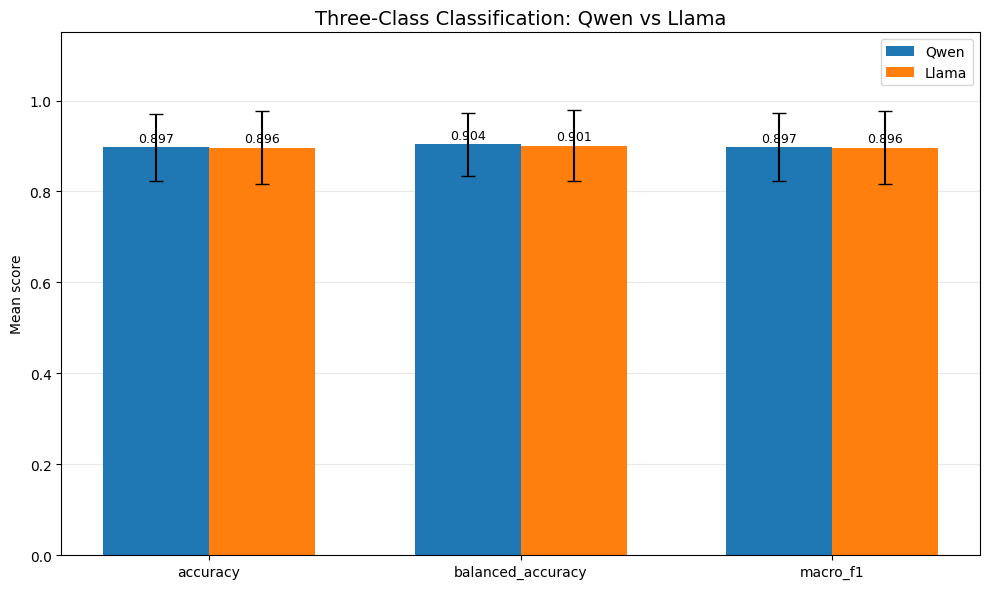

Saved: /kaggle/working/COMPARISON/supplementary_3class_qwen_vs_llama.png
Saved: /kaggle/working/COMPARISON/supplementary_3class_qwen_vs_llama.pdf


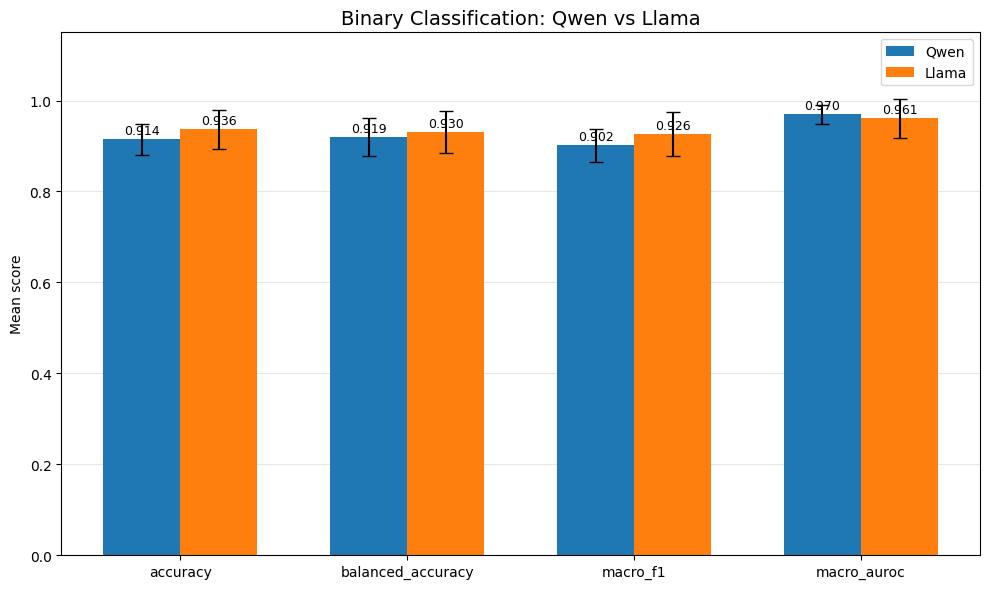

Saved: /kaggle/working/COMPARISON/supplementary_binary_qwen_vs_llama.png
Saved: /kaggle/working/COMPARISON/supplementary_binary_qwen_vs_llama.pdf


In [276]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/kaggle/working/COMPARISON/supplementary_splits")
plot_dir = Path("/kaggle/working/COMPARISON")
plot_dir.mkdir(exist_ok=True)

with open(folder / "qwen_llama_supplementary_comparison.json") as f:
    data = json.load(f)

def create_plot(task, metrics, filename, title):
    models = ["Qwen", "Llama"]
    x = np.arange(len(metrics))
    width = 0.34

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, model in enumerate(models):
        means = [
            data["models"][model][task]["metrics"][m]["mean"]
            for m in metrics
        ]

        stds = [
            data["models"][model][task]["metrics"][m]["sample_std"]
            for m in metrics
        ]

        positions = x + (i - 0.5) * width

        bars = ax.bar(
            positions,
            means,
            width,
            yerr=stds,
            capsize=5,
            label=model
        )

        for bar, value in zip(bars, means):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.012,
                f"{value:.3f}",
                ha="center",
                fontsize=9
            )

    ax.set_title(title, fontsize=14)
    ax.set_ylabel("Mean score")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1.15)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()

    png_path = plot_dir / filename
    pdf_path = plot_dir / filename.replace(".png", ".pdf")

    plt.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.show()

    print("Saved:", png_path)
    print("Saved:", pdf_path)

# Three-class plot
create_plot(
    "3-class",
    ["accuracy", "balanced_accuracy", "macro_f1"],
    "supplementary_3class_qwen_vs_llama.png",
    "Three-Class Classification: Qwen vs Llama"
)

# Binary plot
create_plot(
    "binary",
    ["accuracy", "balanced_accuracy", "macro_f1", "macro_auroc"],
    "supplementary_binary_qwen_vs_llama.png",
    "Binary Classification: Qwen vs Llama"
)

In [278]:
from IPython.display import display as show_table

# Display the existing DataFrame
show_table(df)

print("\nFILES SAVED:")
print(csv_path)
print(xlsx_path)
print(json_path)

,Model,Task,Layer,C,Official Accuracy,Official Balanced Accuracy,Official Macro F1,Official AUROC,Supplementary Accuracy,Supplementary Balanced Accuracy,Supplementary Macro F1,Supplementary AUROC
0,Qwen,3-class,20,0.10,0.9365,0.9216,0.9209,0.9951,0.8970 ± 0.0740,0.9037 ± 0.0694,0.8975 ± 0.0741,Not calculated
1,Llama,3-class,17,1.00,0.9412,0.9074,0.9249,0.9918,0.8961 ± 0.0806,0.9010 ± 0.0791,0.8963 ± 0.0802,Not calculated
2,Qwen,binary,18,0.01,0.8871,0.9118,0.8838,0.9864,0.9144 ± 0.0337,0.9192 ± 0.0415,0.9016 ± 0.0365,0.9695 ± 0.0203
3,Llama,binary,16,0.10,0.8847,0.9099,0.8815,0.9930,0.9365 ± 0.0424,0.9305 ± 0.0457,0.9258 ± 0.0484,0.9605 ± 0.0423



FILES SAVED:
/kaggle/working/COMPARISON/ADNN_RQ1_final_results_table.csv
/kaggle/working/COMPARISON/ADNN_RQ1_final_results_table.xlsx
/kaggle/working/COMPARISON/ADNN_RQ1_final_results_table.json


In [279]:
from pathlib import Path
import json

folders = [
    Path("/kaggle/working/ADNN_RQ1_Qwen_v2"),
    Path("/kaggle/working/ADNN_RQ1_Llama_v2"),
    Path("/kaggle/working/COMPARISON")
]

print("EXISTING BASELINE AND CONTROL FILES\n")

for folder in folders:
    print("\nFOLDER:", folder.name)

    for path in folder.rglob("*"):
        if path.is_file() and any(
            word in path.name.lower()
            for word in ["baseline", "control", "selectivity", "shuffled"]
        ):
            print("\nFILE:", path)

            if path.suffix == ".json":
                try:
                    with open(path) as f:
                        data = json.load(f)
                    print(json.dumps(data, indent=2)[:5000])
                except Exception as e:
                    print("Could not read:", e)

EXISTING BASELINE AND CONTROL FILES


FOLDER: ADNN_RQ1_Qwen_v2

FILE: /kaggle/working/ADNN_RQ1_Qwen_v2/baselines/qwen_v2_binary_random_action_verb_control.json
{
  "experiment": "qwen_v2_binary_random_action_verb_control",
  "task": {
    "type": "binary",
    "target": "fixed_random_label_per_action_verb"
  },
  "representation": {
    "type": "last_action_token",
    "layer": 18
  },
  "classifier": {
    "scaler": "StandardScaler",
    "penalty": "l2",
    "C": 0.01,
    "class_weight": "balanced",
    "solver": "saga",
    "max_iter": 500,
    "tol": 0.01,
    "random_state": 42
  },
  "random_mapping": {
    "seed": 42,
    "n_action_verbs": 13,
    "mapping": {
      "connect": 0,
      "create_share_link": 1,
      "delete_file": 1,
      "edit_file": 0,
      "move": 0,
      "open": 1,
      "restore_backup": 0,
      "restore_file": 1,
      "revert_file": 0,
      "revoke_share_link": 0,
      "send_email": 1,
      "transfer_money": 1,
      "use": 1
    }
  },
  "train": {

In [281]:
import json
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

Q = Path("/kaggle/working/ADNN_RQ1_Qwen_v2")
L = Path("/kaggle/working/ADNN_RQ1_Llama_v2")
OUT = Path("/kaggle/working/COMPARISON")

files = {
    "Qwen Majority": Q / "baselines/qwen_v2_binary_majority_baseline.json",
    "Qwen Layer 0": Q / "baselines/qwen_v2_binary_layer0_embedding_baseline.json",
    "Qwen Shuffled": Q / "baselines/qwen_v2_binary_shuffled_label_control.json",
    "Qwen Random Verb": Q / "baselines/qwen_v2_binary_random_action_verb_control.json",

    "Llama Majority": L / "baselines/llama_v2_binary_majority_baseline.json",
    "Llama Layer 0": L / "baselines/llama_v2_binary_layer0_embedding_baseline.json",
    "Llama Shuffled": L / "probes/llama_v2_binary_shuffled_label_control.json",
    "Llama Random Verb": L / "baselines/llama_v2_binary_random_action_verb_control.json"
}

rows = []

for name, path in files.items():
    with open(path) as f:
        data = json.load(f)

    metrics = data.get("metrics", data)

    rows.append({
        "Experiment": name,
        "Accuracy": metrics.get("accuracy"),
        "Balanced Accuracy": metrics.get("balanced_accuracy"),
        "Macro F1": metrics.get("macro_f1"),
        "AUROC": metrics.get("auroc")
    })

df_baselines = pd.DataFrame(rows)

csv_path = OUT / "ADNN_RQ1_baseline_control_table.csv"
xlsx_path = OUT / "ADNN_RQ1_baseline_control_table.xlsx"

df_baselines.to_csv(csv_path, index=False)
df_baselines.to_excel(xlsx_path, index=False)

print("BASELINE AND CONTROL COMPARISON\n")
show_table(df_baselines)

print("\nSaved successfully:")
print(csv_path)
print(xlsx_path)

BASELINE AND CONTROL COMPARISON



,Experiment,Accuracy,Balanced Accuracy,Macro F1,AUROC
0,Qwen Majority,0.640000,0.500000,0.390244,NaN
1,Qwen Layer 0,0.362353,0.501838,0.268828,0.501838
2,Qwen Shuffled,0.503529,0.526348,0.501365,0.550990
3,Qwen Random Verb,1.000000,1.000000,1.000000,1.000000
4,Llama Majority,0.640000,0.500000,0.390244,NaN
5,Llama Layer 0,0.362353,0.501838,0.268828,0.501838
6,Llama Shuffled,0.520000,0.483456,0.483486,0.512760
7,Llama Random Verb,1.000000,1.000000,1.000000,1.000000



Saved successfully:
/kaggle/working/COMPARISON/ADNN_RQ1_baseline_control_table.csv
/kaggle/working/COMPARISON/ADNN_RQ1_baseline_control_table.xlsx


In [282]:
from pathlib import Path

folders = [
    Path("/kaggle/working/ADNN_RQ1_Qwen_v2"),
    Path("/kaggle/working/ADNN_RQ1_Llama_v2"),
    Path("/kaggle/working/COMPARISON")
]

print("SEARCHING FOR TF-IDF BASELINE FILES\n")

found = []

for folder in folders:
    for path in folder.rglob("*"):
        if path.is_file() and any(
            term in path.name.lower()
            for term in ["tfidf", "tf_idf", "bow", "text_baseline"]
        ):
            found.append(path)
            print(path)

print("\nTOTAL FILES FOUND:", len(found))

SEARCHING FOR TF-IDF BASELINE FILES

/kaggle/working/ADNN_RQ1_Qwen_v2/baselines/qwen_v2_binary_bow_state_action.json
/kaggle/working/ADNN_RQ1_Qwen_v2/baselines/qwen_v2_binary_bow_action_text.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_bow_canonical_minimal_pairs.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_bow_state_action.json
/kaggle/working/ADNN_RQ1_Llama_v2/baselines/llama_v2_binary_bow_action_text.json

TOTAL FILES FOUND: 5


In [283]:
import json
from pathlib import Path

folders = {
    "Qwen": Path("/kaggle/working/ADNN_RQ1_Qwen_v2/baselines"),
    "Llama": Path("/kaggle/working/ADNN_RQ1_Llama_v2/baselines")
}

filenames = [
    "qwen_v2_binary_bow_action_text.json",
    "qwen_v2_binary_bow_state_action.json",
    "llama_v2_binary_bow_action_text.json",
    "llama_v2_binary_bow_state_action.json",
    "llama_v2_bow_canonical_minimal_pairs.json"
]

for filename in filenames:
    for model, folder in folders.items():
        path = folder / filename

        if path.exists():
            print("\n" + "=" * 60)
            print(filename)
            print("=" * 60)

            with open(path) as f:
                data = json.load(f)

            print(json.dumps(data, indent=2)[:6000])


qwen_v2_binary_bow_action_text.json
{
  "experiment": "qwen_v2_binary_bow_action_text",
  "task": {
    "type": "binary",
    "label_mapping": {
      "0": "non_irreversible",
      "1": "irreversible"
    }
  },
  "features": {
    "source": "action_text",
    "vectorizer": "TfidfVectorizer",
    "lowercase": true,
    "ngram_range": [
      1,
      2
    ],
    "min_df": 2,
    "sublinear_tf": true
  },
  "selection": {
    "method": "GroupKFold",
    "n_splits": 5,
    "group": "scenario_id",
    "C_grid": [
      0.001,
      0.01,
      0.1,
      1.0,
      10.0
    ],
    "selected_C": 10.0,
    "inner_cv_balanced_accuracy": 0.6639182377989292,
    "inner_cv_sd": 0.046402217754449075
  },
  "classifier": {
    "penalty": "l2",
    "C": 10.0,
    "class_weight": "balanced",
    "solver": "liblinear",
    "max_iter": 1000,
    "random_state": 42
  },
  "test": {
    "n": 425
  },
  "metrics": {
    "accuracy": 0.76,
    "balanced_accuracy": 0.7438725490196079,
    "macro_f1": 0.

In [285]:
from IPython.display import display as show_table
import pandas as pd
from pathlib import Path

path = Path("/kaggle/working/COMPARISON/ADNN_RQ1_baseline_control_table.csv")

df = pd.read_csv(path)

print("UPDATED BASELINE AND CONTROL COMPARISON\n")
show_table(df.round(4))

print("\nFiles saved successfully:")
print(path)
print(path.with_suffix(".xlsx"))

UPDATED BASELINE AND CONTROL COMPARISON



,Experiment,Accuracy,Balanced Accuracy,Macro F1,AUROC
0,Qwen Majority,0.6400,0.5000,0.3902,NaN
1,Qwen Layer 0,0.3624,0.5018,0.2688,0.5018
2,Qwen Shuffled,0.5035,0.5263,0.5014,0.5510
3,Qwen Random Verb,1.0000,1.0000,1.0000,1.0000
4,Llama Majority,0.6400,0.5000,0.3902,NaN
5,Llama Layer 0,0.3624,0.5018,0.2688,0.5018
6,Llama Shuffled,0.5200,0.4835,0.4835,0.5128
7,Llama Random Verb,1.0000,1.0000,1.0000,1.0000
8,Qwen TF-IDF Action Text,0.7600,0.7439,0.7417,0.8710
9,Qwen TF-IDF State + Action,0.8424,0.8440,0.8335,0.9400



Files saved successfully:
/kaggle/working/COMPARISON/ADNN_RQ1_baseline_control_table.csv
/kaggle/working/COMPARISON/ADNN_RQ1_baseline_control_table.xlsx


In [286]:
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/working")

folders = [
    ROOT / "ADNN_RQ1_Qwen_v2",
    ROOT / "ADNN_RQ1_Llama_v2",
    ROOT / "COMPARISON"
]

for folder in folders:
    print("\n" + "=" * 75)
    print(folder.name)
    print("=" * 75)

    if not folder.exists():
        print("Folder missing!")
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    counts = Counter(p.suffix.lower() or "[no extension]" for p in files)

    print("Total files:", len(files))
    print("File types:", dict(counts))

    for subfolder in sorted(p for p in folder.iterdir() if p.is_dir()):
        count = sum(1 for p in subfolder.rglob("*") if p.is_file())
        print(f"  {subfolder.name}/ — {count} files")


ADNN_RQ1_Qwen_v2
Total files: 51
File types: {'.json': 30, '.npy': 3, '.jsonl': 6, '.pdf': 6, '.png': 6}
  ablations/ — 2 files
  analysis/ — 6 files
  baselines/ — 6 files
  config/ — 2 files
  hidden_states/ — 6 files
  plots/ — 13 files
  probes/ — 16 files

ADNN_RQ1_Llama_v2
Total files: 60
File types: {'.json': 39, '.npy': 3, '.jsonl': 6, '.pdf': 6, '.png': 6}
  ablations/ — 1 files
  analysis/ — 6 files
  baselines/ — 8 files
  config/ — 5 files
  dataset_verification/ — 4 files
  hidden_states/ — 6 files
  logs/ — 0 files
  plots/ — 13 files
  probes/ — 17 files
  validation/ — 0 files

COMPARISON
Total files: 64
File types: {'.pdf': 18, '.png': 18, '.csv': 2, '.json': 24, '.xlsx': 2}
  supplementary_splits/ — 20 files


In [287]:

from pathlib import Path

folders = [
    Path("/kaggle/working/ADNN_RQ1_Qwen_v2"),
    Path("/kaggle/working/ADNN_RQ1_Llama_v2"),
    Path("/kaggle/working/COMPARISON")
]

for folder in folders:
    total = 0
    print(f"\n{folder.name}")

    for p in folder.rglob("*"):
        if p.is_file():
            size = p.stat().st_size
            total += size

            if p.suffix == ".npy":
                print(f"  {p.relative_to(folder)}: {size / (1024**2):.2f} MB")

    print(f"TOTAL: {total / (1024**3):.2f} GB")

import shutil
free = shutil.disk_usage("/kaggle/working").free
print(f"\nFree working storage: {free / (1024**3):.2f} GB")


ADNN_RQ1_Qwen_v2
  hidden_states/last_action_token.npy: 423.05 MB
  hidden_states/extraction_progress.npy: 0.00 MB
  hidden_states/mean_action_tokens.npy: 423.05 MB
TOTAL: 0.83 GB

ADNN_RQ1_Llama_v2
  hidden_states/last_action_token.npy: 550.17 MB
  hidden_states/extraction_progress.npy: 0.00 MB
  hidden_states/mean_action_tokens.npy: 550.17 MB
TOTAL: 1.08 GB

COMPARISON
TOTAL: 0.00 GB

Free working storage: 16.60 GB


In [288]:
from pathlib import Path
import shutil

ROOT = Path("/kaggle/working")
HANDOFF = ROOT / "ADNN_RQ1_FINAL_HANDOFF"

sources = [
    "ADNN_RQ1_Qwen_v2",
    "ADNN_RQ1_Llama_v2",
    "COMPARISON"
]

HANDOFF.mkdir(exist_ok=True)

for name in sources:
    source = ROOT / name
    destination = HANDOFF / name

    if destination.exists():
        shutil.rmtree(destination)

    shutil.copytree(source, destination)

    count = sum(1 for p in destination.rglob("*") if p.is_file())
    print(f"Copied {name}: {count} files")

print("\nHANDOFF FOLDER CREATED")
print(HANDOFF)
print("Total files:", sum(
    1 for p in HANDOFF.rglob("*") if p.is_file()
))

Copied ADNN_RQ1_Qwen_v2: 51 files
Copied ADNN_RQ1_Llama_v2: 60 files
Copied COMPARISON: 64 files

HANDOFF FOLDER CREATED
/kaggle/working/ADNN_RQ1_FINAL_HANDOFF
Total files: 175


In [289]:
from pathlib import Path

HANDOFF = Path("/kaggle/working/ADNN_RQ1_FINAL_HANDOFF")

readme = r"""
# ADNN — RQ1: Hidden-State Probing for Action Irreversibility

## 1. Project overview

This handoff contains the completed RQ1 experiments comparing:

- Qwen2.5-7B-Instruct
- Llama-3.1-8B-Instruct

The objective is to investigate whether information related to action
reversibility is decodable from transformer hidden-state representations.

The experiments include three-class classification and binary
irreversibility classification, along with text baselines, controls,
minimal-pair diagnostics, robustness evaluation and supplementary splits.

## 2. Folder structure

- `ADNN_RQ1_Qwen_v2/` — Qwen extraction, probes, baselines, analysis and plots.
- `ADNN_RQ1_Llama_v2/` — Llama extraction, probes, baselines, analysis and plots.
- `COMPARISON/` — cross-model comparisons, result tables, figures and
  supplementary scenario-grouped split results.

Each model folder contains:
- `hidden_states/` — extracted hidden-state arrays and extraction metadata.
- `probes/` — trained probe results, predictions and layer screening.
- `baselines/` — majority, layer-zero, text and action-verb controls.
- `analysis/` — diagnostic analyses and model summaries.
- `plots/` — figures in PNG and PDF formats.
- `ablations/` and `config/` — additional experiment and configuration files.

## 3. Dataset and split

Dataset version: ADNN v2.0

Total records: 2,134

Official frozen scenario-grouped split:
- Training: 1,709 records
- Test: 425 records
- Training scenarios: 124
- Test scenarios: 27 (25 containing records)

Class distribution across the full dataset:
- Reversible: 799
- Partially reversible: 758
- Irreversible: 577

Minimal-pair structure:
- 878 records are pair members (41.14%).
- 439 unique pair IDs.
- Each pair contains two records with the same action verb and
  different labels and pivots.

The official frozen split is the primary evaluation split.

## 4. Experimental methodology

### Hidden-state extraction

Two representations were extracted:
- Last action token
- Mean action tokens

Qwen:
- 28 transformer layers plus embedding state (29 states).
- Hidden size: 3,584.

Llama:
- 32 transformer layers plus embedding state (33 states).
- Hidden size: 4,096.

### Probe classifier

Pipeline:
1. StandardScaler
2. L2-regularized Logistic Regression

Class weighting: balanced.

Hyperparameter selection:
- GroupKFold grouped by scenario_id.
- Balanced accuracy used for model selection.
- Layer selection and regularization selection performed using training data.

### Classification tasks

Three-class:
- Reversible
- Partially reversible
- Irreversible

Binary:
- Non-irreversible (reversible + partially reversible)
- Irreversible

The binary task excludes neither of the first two classes; they are combined.

## 5. Official frozen-split results

All metrics below are from the 425-record official test set.

### Three-class classification

| Metric | Qwen | Llama |
|---|---:|---:|
| Selected layer | 20 | 17 |
| Selected C | 0.1 | 1.0 |
| Accuracy | 0.9365 | 0.9412 |
| Balanced accuracy | 0.9216 | 0.9074 |
| Macro F1 | 0.9209 | 0.9249 |
| Macro AUROC | 0.9951 | 0.9918 |

### Binary classification

| Metric | Qwen | Llama |
|---|---:|---:|
| Selected layer | 18 | 16 |
| Selected C | 0.01 | 0.1 |
| Accuracy | 0.8871 | 0.8847 |
| Balanced accuracy | 0.9118 | 0.9099 |
| Macro F1 | 0.8838 | 0.8815 |
| AUROC | 0.9864 | 0.9930 |

## 6. Supplementary scenario-grouped splits

Three additional scenario-grouped splits were evaluated:
- Seed 42
- Seed 123
- Seed 2026

These are supplementary evaluations, not replacements for the official
frozen split.

For computational feasibility, the selected layer and C from the official
split were held fixed. Hyperparameters were not retuned independently
for each supplementary split.

Mean ± sample standard deviation:

### Three-class

| Metric | Qwen | Llama |
|---|---:|---:|
| Accuracy | 0.8970 ± 0.0740 | 0.8961 ± 0.0806 |
| Balanced accuracy | 0.9037 ± 0.0694 | 0.9010 ± 0.0791 |
| Macro F1 | 0.8975 ± 0.0741 | 0.8963 ± 0.0802 |

Three-class supplementary AUROC was not calculated.

### Binary

| Metric | Qwen | Llama |
|---|---:|---:|
| Accuracy | 0.9144 ± 0.0337 | 0.9365 ± 0.0424 |
| Balanced accuracy | 0.9192 ± 0.0415 | 0.9305 ± 0.0457 |
| Macro F1 | 0.9016 ± 0.0365 | 0.9258 ± 0.0484 |
| AUROC | 0.9695 ± 0.0203 | 0.9605 ± 0.0423 |

Test sizes vary because scenario sizes are unequal.

## 7. Baselines and controls

Official binary test-set results:

| Experiment | Accuracy | Balanced accuracy | Macro F1 | AUROC |
|---|---:|---:|---:|---:|
| Qwen Majority | 0.6400 | 0.5000 | 0.3902 | — |
| Qwen Layer 0 | 0.3624 | 0.5018 | 0.2688 | 0.5018 |
| Qwen Shuffled | 0.5035 | 0.5263 | 0.5014 | 0.5510 |
| Qwen TF-IDF Action | 0.7600 | 0.7439 | 0.7417 | 0.8710 |
| Qwen TF-IDF State + Action | 0.8424 | 0.8440 | 0.8335 | 0.9400 |
| Qwen Random Verb | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| Llama Majority | 0.6400 | 0.5000 | 0.3902 | — |
| Llama Layer 0 | 0.3624 | 0.5018 | 0.2688 | 0.5018 |
| Llama Shuffled | 0.5200 | 0.4835 | 0.4835 | 0.5128 |
| Llama TF-IDF Action | 0.7600 | 0.7439 | 0.7417 | 0.8710 |
| Llama TF-IDF State + Action | 0.8424 | 0.8440 | 0.8335 | 0.9401 |
| Llama Random Verb | 1.0000 | 1.0000 | 1.0000 | 1.0000 |

The random action-verb control assigns a fixed random label to each
action verb. Its perfect performance indicates a serious action-verb
confound. Action identity is highly predictive of the labels in this
dataset.

This is not proof of data leakage, but it prevents interpreting the
probe results as evidence that hidden states isolate irreversibility
independently of action identity.

## 8. Diagnostic analyses

### Minimal pairs

Canonical 24-family minimal-pair evaluation:
- Qwen: 25/72 correct pair-render instances; pair accuracy 0.3472.
- Llama: 39/72 correct pair-render instances; pair accuracy 0.5417.

Both models performed best on key-value rendering and worst on compact
rendering.

The Llama TF-IDF canonical minimal-pair baseline achieved 0/72 correct
pair-render instances. These results are diagnostic and should not be
confused with full-test-set baseline metrics.

### Bootstrap confidence intervals

Binary probe metrics were bootstrapped using 1,000 scenario-level
resamples.

Qwen:
- Balanced accuracy: 0.9118 [0.8111, 1.0000]
- Macro F1: 0.8838 [0.7865, 1.0000]
- AUROC: 0.9864 [0.9424, 1.0000]

Llama:
- Balanced accuracy: 0.9099 [0.8202, 0.9931]
- Macro F1: 0.8815 [0.7767, 0.9866]
- AUROC: 0.9930 [0.9839, 1.0000]

The confidence intervals overlap substantially. Do not claim statistically
significant superiority of one model based on these results.

### Within-action-verb analysis

Only two action verbs in the official binary test set contain both
binary classes: restore_backup and transfer_money.

This analysis is limited and does not establish generalisation across
action verbs.

### Cross-environment analysis

ScienceWorld has insufficient test records for reliable cross-environment
generalisation conclusions. In particular, one official test record is
not enough to support a transfer claim.

## 9. Main findings

1. Both models achieve strong aggregate performance on the official
   three-class and binary test sets.
2. Qwen has slightly higher official balanced accuracy in both tasks.
3. Llama has slightly higher official three-class macro F1 and binary
   AUROC.
4. State + action TF-IDF performs better than action-only TF-IDF.
5. Both random action-verb controls achieve perfect performance,
   revealing a serious action-identity confound.
6. Minimal-pair performance is substantially lower than aggregate
   performance, especially for Qwen.
7. Rendering style affects minimal-pair performance.
8. Supplementary split results show variation across scenario splits.

## 10. Limitations and interpretation

- Action-verb identity is a major confound.
- Aggregate performance does not prove that representations encode
  irreversibility independently of action identity.
- Minimal-pair results are weaker than aggregate results.
- Only two action verbs support within-verb binary evaluation on the
  official test set.
- ScienceWorld test coverage is insufficient for transfer claims.
- Supplementary splits reuse official-split hyperparameters and are
  not independently retuned.
- Three-class supplementary AUROC was not calculated.
- Bootstrap intervals overlap substantially; model superiority is
  not established.

## 11. Reproducibility and handoff notes

The model folders contain extracted hidden states, extraction metadata,
probe results, predictions, baselines and diagnostic outputs.

The `COMPARISON/` folder contains cross-model summaries, plots, tables,
and supplementary split outputs.

The original dataset files are not copied into this handoff. The dataset
used was ADNN v2.0, and the original dataset location and split metadata
should be retained separately by the receiving researcher.

The hidden-state arrays are included to avoid requiring model extraction
again. They are large files and may be stored separately if storage
constraints require it.

## 12. Interpretation summary

The results show that action reversibility is highly decodable in the
evaluated dataset. However, the perfect random action-verb control and
the weaker minimal-pair results indicate that this decodability is
entangled with action identity and other contextual cues.

The safest conclusion is that the models' hidden states contain
information predictive of the dataset's reversibility labels, but the
current evidence does not establish action-independent encoding of
irreversibility.
"""

readme_path = HANDOFF / "README_RQ1.md"
readme_path.write_text(readme.strip() + "\n", encoding="utf-8")

print("README CREATED:", readme_path)
print("File size:", round(readme_path.stat().st_size / 1024, 2), "KB")
print("Handoff files:", sum(1 for p in HANDOFF.rglob("*") if p.is_file()))

README CREATED: /kaggle/working/ADNN_RQ1_FINAL_HANDOFF/README_RQ1.md
File size: 9.37 KB
Handoff files: 176


In [290]:
from pathlib import Path
import hashlib

ROOT = Path("/kaggle/working")
HANDOFF = ROOT / "ADNN_RQ1_FINAL_HANDOFF"

folders = [
    "ADNN_RQ1_Qwen_v2",
    "ADNN_RQ1_Llama_v2",
    "COMPARISON"
]

print("CHECKING ORIGINAL AND HANDOFF FILES\n")

all_match = True

for name in folders:
    original = ROOT / name
    copied = HANDOFF / name

    original_files = {
        str(p.relative_to(original))
        for p in original.rglob("*") if p.is_file()
    }
    copied_files = {
        str(p.relative_to(copied))
        for p in copied.rglob("*") if p.is_file()
    }

    missing = original_files - copied_files
    extra = copied_files - original_files

    print(f"{name}:")
    print("  Original files:", len(original_files))
    print("  Copied files:", len(copied_files))
    print("  Missing:", len(missing))
    print("  Extra:", len(extra))

    if missing or extra:
        all_match = False

# Verify important final deliverables
expected = [
    "README_RQ1.md",
    "COMPARISON/ADNN_RQ1_final_results_table.csv",
    "COMPARISON/ADNN_RQ1_final_results_table.xlsx",
    "COMPARISON/ADNN_RQ1_baseline_control_table.csv",
    "COMPARISON/ADNN_RQ1_baseline_control_table.xlsx",
    "COMPARISON/ADNN_RQ1_Qwen_Llama_final_comparison.json",
    "COMPARISON/ADNN_RQ1_robustness_model_comparison.json",
    "COMPARISON/supplementary_splits/qwen_llama_supplementary_comparison.json"
]

missing_expected = [
    f for f in expected if not (HANDOFF / f).is_file()
]

print("\nEXPECTED DELIVERABLES MISSING:", missing_expected)
print("README EXISTS:", (HANDOFF / "README_RQ1.md").is_file())
print("TOTAL HANDOFF FILES:",
      sum(1 for p in HANDOFF.rglob("*") if p.is_file()))

print("\nFINAL CHECK:", "PASSED" if all_match and not missing_expected else "NEEDS ATTENTION")

CHECKING ORIGINAL AND HANDOFF FILES

ADNN_RQ1_Qwen_v2:
  Original files: 51
  Copied files: 51
  Missing: 0
  Extra: 0
ADNN_RQ1_Llama_v2:
  Original files: 60
  Copied files: 60
  Missing: 0
  Extra: 0
COMPARISON:
  Original files: 64
  Copied files: 64
  Missing: 0
  Extra: 0

EXPECTED DELIVERABLES MISSING: []
README EXISTS: True
TOTAL HANDOFF FILES: 176

FINAL CHECK: PASSED


In [291]:
from pathlib import Path
import zipfile
import hashlib

ROOT = Path("/kaggle/working")

# Original Qwen folder (read-only Kaggle input)
QWEN_ORIGINAL = Path(
    "/kaggle/input/datasets/aashrithap/"
    "adnn-qwen-rq1-results/ADNN_RQ1_Qwen_v2"
)

# Current working folders
QWEN_CURRENT = ROOT / "ADNN_RQ1_Qwen_v2"
LLAMA = ROOT / "ADNN_RQ1_Llama_v2"
COMPARISON = ROOT / "COMPARISON"


def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def zip_folder(folder, zip_path):
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in folder.rglob("*"):
            if p.is_file():
                z.write(p, p.relative_to(folder.parent))


# 1. Complete Llama folder
llama_zip = ROOT / "ADNN_RQ1_Llama_v2.zip"
zip_folder(LLAMA, llama_zip)


# 2. Complete Comparison folder
comparison_zip = ROOT / "COMPARISON.zip"
zip_folder(COMPARISON, comparison_zip)


# 3. Only new or modified Qwen files
qwen_zip = ROOT / "QWEN_ONLY_NEW_FILES.zip"

new_files = []

for current_file in QWEN_CURRENT.rglob("*"):
    if not current_file.is_file():
        continue

    relative = current_file.relative_to(QWEN_CURRENT)
    original_file = QWEN_ORIGINAL / relative

    if not original_file.exists():
        new_files.append(current_file)
    elif file_hash(current_file) != file_hash(original_file):
        new_files.append(current_file)

with zipfile.ZipFile(qwen_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in new_files:
        z.write(p, Path("ADNN_RQ1_Qwen_v2") / p.relative_to(QWEN_CURRENT))


# Verify all ZIPs
print("SUCCESSFULLY CREATED THREE ZIP FILES\n")

for path in [llama_zip, comparison_zip, qwen_zip]:
    with zipfile.ZipFile(path, "r") as z:
        bad = z.testzip()
        print(path.name)
        print("  Files:", len(z.namelist()))
        print("  Size:", round(path.stat().st_size / (1024**2), 2), "MB")
        print("  Integrity:", "PASSED" if bad is None else bad)

print("\nQWEN NEW/MODIFIED FILES:", len(new_files))
for p in new_files:
    print(" ", p.relative_to(QWEN_CURRENT))

SUCCESSFULLY CREATED THREE ZIP FILES

ADNN_RQ1_Llama_v2.zip
  Files: 60
  Size: 1018.34 MB
  Integrity: PASSED
COMPARISON.zip
  Files: 64
  Size: 2.5 MB
  Integrity: PASSED
QWEN_ONLY_NEW_FILES.zip
  Files: 19
  Size: 0.79 MB
  Integrity: PASSED

QWEN NEW/MODIFIED FILES: 19
  plots/qwen_v2_binary_bootstrap_ci.pdf
  plots/qwen_v2_3class_confusion_matrix.png
  plots/qwen_v2_binary_layer_screening.png
  plots/qwen_v2_3class_layer_screening.png
  plots/qwen_v2_binary_confusion_matrix.pdf
  plots/qwen_v2_3class_layer_screening.pdf
  plots/qwen_v2_binary_bootstrap_ci.png
  plots/qwen_v2_binary_layer_screening.pdf
  plots/qwen_v2_per_layer_norm.pdf
  plots/qwen_v2_per_layer_norm.json
  plots/qwen_v2_3class_confusion_matrix.pdf
  plots/qwen_v2_per_layer_norm.png
  plots/qwen_v2_binary_confusion_matrix.png
  analysis/within_action_verb_binary_evaluation.json
  analysis/qwen_v2_rq1_summary.json
  probes/qwen_v2_binary_robustness_predictions.jsonl
  probes/qwen_v2_3class_robustness_predictions.jso